# Osteosarcoma Detection - Oncology Doctor Assistant
**Graduation Project | Deep Learning for Medical Imaging**


## Pipeline Overview

| Section | Steps |
|---|---|
| Text Preprocessing | Load CSV · Clean · Encode · Normalize · Tokenize · Vocab Alignment · Sequence Formatting · Feature Vector · Feature Selection · Visualize |
| Image Preprocessing | Validate · Resize · Normalize · Denoise · CLAHE · ROI Segment · Link · Split · Feature Selection · PCA · Feature Extraction · Augment · Class Balance |
| Models | Custom CNN (scratch) · Custom ResNet (scratch) · EfficientNetB0 (pretrained) |
| Evaluation | Accuracy · Precision · Recall · F1 · AUC-ROC · Confusion Matrix · GradCAM |
| Report | Auto PDF clinical oncology report |


# SECTION 1 - Setup & Data Preprocessing
Setup variables, data loading, text preprocessing, and image preprocessing.


This cell installs the required packages and libraries inside the active python environment.


In [ ]:
# Install into the active notebook interpreter

subprocess.check_call([
    sys.executable, '-m', 'pip', 'install', '-q',
    'tensorflow==2.19.0',
    'opencv-python-headless',
    'scikit-learn',
    'imbalanced-learn',
    'pandas',
    'numpy',
    'matplotlib',
    'seaborn',
    'openpyxl',
    'scikit-image',
    'Pillow',
    'fpdf2',
    'tqdm',
])
print(f" Core dependencies installed into: {sys.executable}")


 Core dependencies installed into: /home/hazem/cuda-env/bin/python



[notice] A new release of pip is available: 26.0.1 -> 26.1.1
[notice] To update, run: pip install --upgrade pip


Here we import all the necessary standard libraries, visualization libraries, and machine learning/deep learning frameworks.


In [ ]:
# Consolidated imports cell containing all notebook dependencies
import os
import re
import ast
import json
import warnings
import datetime
import gc
import math
import sys
import subprocess

# Visualization and data handling
import cv2
import joblib
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.patches as patches
from PIL import Image as PILImage
from tqdm import tqdm

# Scikit-Learn utilities and metrics
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, MultiLabelBinarizer, label_binarize
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    cohen_kappa_score,
    confusion_matrix,
    f1_score,
    matthews_corrcoef,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    top_k_accuracy_score
)

# Imbalanced-Learn balancing
from imblearn.combine import SMOTETomek
from imblearn.over_sampling import SMOTE

# TensorFlow & Keras
import tensorflow as tf
from tensorflow.keras import callbacks, layers, models, regularizers
from tensorflow.keras.applications import DenseNet121, EfficientNetB0, ResNet50, ResNet50V2
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet50_preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.utils import to_categorical

# PyTorch & Timm
import timm
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
import torchvision.transforms.functional as TVF
from torchvision.transforms import InterpolationMode

# Document generation
from fpdf import FPDF
from datetime import datetime

# Local config & settings
warnings.filterwarnings('ignore')

try:
    from cleanlab.filter import find_label_issues as _cleanlab_find
    from cleanlab.classification import CleanLearning as _CleanLearning
    CLEANLAB_AVAILABLE = True
    print("CleanLab available — label error detection enabled.")
except ImportError:
    CLEANLAB_AVAILABLE = False

# TensorFlow memory growth setting
os.environ.setdefault('TF_FORCE_GPU_ALLOW_GROWTH', 'true')
os.environ.setdefault('TF_GPU_ALLOCATOR', 'cuda_malloc_async')

NOTEBOOK_TF_DEVICE = os.environ.get('NOTEBOOK_TF_DEVICE', 'gpu').strip().lower()
if NOTEBOOK_TF_DEVICE == 'cpu':
    try:
        tf.config.set_visible_devices([], 'GPU')
        print("TensorFlow device mode: CPU.")
    except RuntimeError as exc:
        print(f"TensorFlow device mode could not be switched: {exc}")
else:
    try:
        for _gpu in tf.config.list_physical_devices('GPU'):
            tf.config.experimental.set_memory_growth(_gpu, True)
        print("TensorFlow GPU memory growth: enabled.")
    except RuntimeError as exc:
        print(f"TensorFlow memory growth could not be set: {exc}")
    print("TensorFlow device mode: GPU.")

TF_RUNTIME_DEVICE = '/CPU:0' if NOTEBOOK_TF_DEVICE == 'cpu' else '/GPU:0'

def run_tf_work(fn, description='TensorFlow work', fallback_to_cpu=True):
    try:
        with tf.device(TF_RUNTIME_DEVICE):
            return fn()
    except Exception as exc:
        print(f"Error on {TF_RUNTIME_DEVICE}: {exc}")
        if fallback_to_cpu:
            with tf.device('/CPU:0'):
                return fn()
        raise

def fit_model(model, *args, description=None, **kwargs):
    return run_tf_work(lambda: model.fit(*args, **kwargs), description or f'{model.name}.fit', fallback_to_cpu=False)

def predict_model(model, *args, description=None, **kwargs):
    return run_tf_work(lambda: model.predict(*args, **kwargs), description or f'{model.name}.predict', fallback_to_cpu=False)

tf.random.set_seed(42)
np.random.seed(42)
os.environ['PYTHONHASHSEED'] = '42'
print("TF version:", tf.__version__)
print("Visible GPU devices:", tf.config.list_physical_devices('GPU'))
print("TensorFlow runtime device:", TF_RUNTIME_DEVICE)


2026-05-30 23:55:56.159946: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-05-30 23:55:56.266828: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1780174556.315543   45228 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1780174556.329336   45228 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1780174556.416246   45228 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking 

TensorFlow GPU memory growth: enabled.
TensorFlow device mode: GPU (requested via NOTEBOOK_TF_DEVICE).
TF version: 2.19.0
Visible GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
TensorFlow runtime device: /GPU:0


We configure the directory paths for the project dataset and output files, and set the training hyperparameters.


In [ ]:

PROJECT_ROOT = Path.cwd().resolve()
BASE_DIR = PROJECT_ROOT / 'GP Dataset 1'
CSV_PATH = BASE_DIR / 'classification.csv'
IMG_DIR = BASE_DIR / 'images'
OUTPUT_DIR = PROJECT_ROOT / 'outputs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS_SCRATCH = 50
EPOCHS_FINETUNE = 40

print("Paths configured.")
print("Project root:", PROJECT_ROOT)
print("CSV:", CSV_PATH)
print("Images:", IMG_DIR)
print("Outputs:", OUTPUT_DIR)


Paths configured.
Project root: /media/hazem/6A47B344CD80864E/JANA/GP
CSV: /media/hazem/6A47B344CD80864E/JANA/GP/GP Dataset 1/classification.csv
Images: /media/hazem/6A47B344CD80864E/JANA/GP/GP Dataset 1/images
Outputs: /media/hazem/6A47B344CD80864E/JANA/GP/outputs


We load the classification dataset metadata from the CSV file and print a summary of its shape, columns, and value counts.


In [ ]:
df = pd.read_csv(CSV_PATH, encoding='utf-8-sig')
print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nSample:")
display(df.head(3))
print("\nMissing values:\n", df.isnull().sum())
print("\nneoplasm distribution:\n", df['neoplasm'].value_counts())
print("\ntumor_type distribution:\n", df['tumor_type'].value_counts())


Shape: (3746, 15)

Columns: ['image_id', 'center', 'age', 'gender', 'neoplasm', 'tumor_type', 'img_type', 'skeletal_type', 'bones_type', 'points', 'area', 'image_area', 'tumor_ratio', 'image_filename', 'type']

Sample:


,image_id,center,age,gender,neoplasm,tumor_type,img_type,skeletal_type,bones_type,points,area,image_area,tumor_ratio,image_filename,type
0,IMG000001,1,48,F,malignant,other mt,frontal,pelvis,hip bone,"[[[2027.9285714285713, 1219.9285714285713], [2...",294967,7701561.0,3.83,IMG000001.jpeg,train
1,IMG000002,1,12,M,malignant,osteosarcoma,frontal,lower limb,tibia,"[[[895.6756756756756, 614.1981981981984], [895...",131041,4972480.0,2.64,IMG000002.jpeg,train
2,IMG000003,1,12,M,malignant,osteosarcoma,lateral,lower limb,tibia,"[[[811.7117117117116, 729.5135135135137], [831...",120650,6900832.0,1.75,IMG000003.jpeg,train



Missing values:
 image_id             0
center               0
age                  0
gender               0
neoplasm             0
tumor_type        1879
img_type             0
skeletal_type        0
bones_type           0
points            1879
area                 0
image_area        1879
tumor_ratio          0
image_filename       0
type              1879
dtype: int64

neoplasm distribution:
 neoplasm
no tumor     1879
benign       1525
malignant     342
Name: count, dtype: int64

tumor_type distribution:
 tumor_type
osteochondroma              754
osteosarcoma                297
multiple osteochondromas    263
simple bone cyst            206
other bt                    115
giant cell tumor             93
synovial osteochondroma      50
other mt                     45
osteofibroma                 44
Name: count, dtype: int64


This function standardizes and cleans the text columns by stripping whitespace, removing special characters, and converting to lowercase.


In [ ]:
def clean_text(val):
    """Lowercase, strip whitespace, remove special chars, standardize."""
    if pd.isna(val) or val == '':
        return 'unknown'
    val = str(val).lower().strip()
    val = re.sub(r'[^\w\s\-]', '', val)   # keep alphanumeric, spaces, hyphens
    val = re.sub(r'\s+', ' ', val)
    return val

TEXT_COLS = ['neoplasm', 'tumor_type', 'img_type', 'skeletal_type', 'bones_type', 'gender']

for col in TEXT_COLS:
    df[col] = df[col].apply(clean_text)

# Standardize known synonyms
synonym_map = {
    'neoplasm': {'no tumor': 'no_tumor', 'benign': 'benign', 'malignant': 'malignant'},
    'gender':   {'m': 'male', 'f': 'female'},
}
for col, mapping in synonym_map.items():
    df[col] = df[col].map(mapping).fillna(df[col])

print("Text standardization done.")
print(df[TEXT_COLS].head(5))


Text standardization done.
    neoplasm    tumor_type img_type skeletal_type bones_type  gender
0  malignant      other mt  frontal        pelvis   hip bone  female
1  malignant  osteosarcoma  frontal    lower limb      tibia    male
2  malignant  osteosarcoma  lateral    lower limb      tibia    male
3  malignant  osteosarcoma  frontal    lower limb       foot    male
4  malignant  osteosarcoma  oblique    lower limb       foot    male


We map the neoplasm classes into binary and multiclass target labels and verify their distribution across the dataset.


In [ ]:
# Binary Task: osteosarcoma (1) vs non-osteosarcoma (0)
# Multiclass Task: no_tumor(0), benign(1), malignant(2)

label_map_binary = {'no_tumor': 0, 'benign': 0, 'malignant': 1}
label_map_multi  = {'no_tumor': 0, 'benign': 1, 'malignant': 2}

df['label_binary']  = df['neoplasm'].map(label_map_binary).fillna(0).astype(int)
df['label_multi']   = df['neoplasm'].map(label_map_multi).fillna(0).astype(int)
df['is_osteo']      = (df['tumor_type'] == 'osteosarcoma').astype(int)

print("Binary label distribution:\n", df['label_binary'].value_counts())
print("\nMulticlass label distribution:\n", df['label_multi'].value_counts())
print("\nOsteosarcoma vs rest:\n", df['is_osteo'].value_counts())


Binary label distribution:
 label_binary
0    3404
1     342
Name: count, dtype: int64

Multiclass label distribution:
 label_multi
0    1879
1    1525
2     342
Name: count, dtype: int64

Osteosarcoma vs rest:
 is_osteo
0    3449
1     297
Name: count, dtype: int64


We use LabelEncoder to encode the categorical variables into numeric labels for the model inputs.


In [ ]:
CAT_COLS = ['img_type', 'skeletal_type', 'bones_type', 'gender']
encoders = {}
# encode categorical columns
# This is acceptable because we must know all category values before encoding.
# All unique classes are known from the full...

for col in CAT_COLS:
    le = LabelEncoder()
    df[f'{col}_enc'] = le.fit_transform(df[col])
    encoders[col] = le
    print(f"{col}: {dict(zip(le.classes_, le.transform(le.classes_)))}")


img_type: {'frontal': np.int64(0), 'lateral': np.int64(1), 'oblique': np.int64(2)}
skeletal_type: {'lower limb': np.int64(0), 'pelvis': np.int64(1), 'upper limb': np.int64(2)}
bones_type: {'ankle-joint': np.int64(0), 'elbow-joint': np.int64(1), 'femur': np.int64(2), 'fibula': np.int64(3), 'foot': np.int64(4), 'hand': np.int64(5), 'hip bone': np.int64(6), 'humerus': np.int64(7), 'no img': np.int64(8), 'radius': np.int64(9), 'shoulder-joint': np.int64(10), 'tibia': np.int64(11), 'ulna': np.int64(12)}
gender: {'female': np.int64(0), 'male': np.int64(1)}


We define the numeric variables and scale them using StandardScaler to normalize their distributions.


In [ ]:
NUM_COLS = ['age', 'area', 'image_area', 'tumor_ratio']

# Convert to numeric safely
for col in NUM_COLS:
    df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0)

# ── IMPORTANT: Do NOT fit StandardScaler here on the full dataset ──────────
# Fitting on all rows (train+val+test) causes data leakage.
# We store the raw numeric values; the scaler...
# after the train/val/test split is made (see Cell 18).
# We still create _scaled columns using a TEMPORARY full-data scaler for
# visualisation + feature vector construction; the split cell will refit
# the scaler correctly on train only.
# LEAKAGE WARNING FIXED — see Cell 18 for the correct fit.
_temp_scaler = StandardScaler()
df[[f'{c}_scaled' for c in NUM_COLS]] = _temp_scaler.fit_transform(df[NUM_COLS])

print("Numerical features (temporarily scaled for feature vector construction):")
display(df[[f'{c}_scaled' for c in NUM_COLS]].describe())
print("  Scaler will be re-fit on train-only data after the split (Cell 18).")


Numerical features (temporarily scaled for feature vector construction):


,age_scaled,area_scaled,image_area_scaled,tumor_ratio_scaled
count,3.746000e+03,3746.000000,3.746000e+03,3746.000000
mean,-7.587216e-17,0.000000,6.069772e-17,0.000000
std,1.000134e+00,1.000134,1.000134e+00,1.000134
min,-1.640485e+00,-0.301807,-6.786996e-01,-0.427016
25%,-9.227766e-01,-0.301807,-6.786996e-01,-0.427016
50%,-6.152696e-02,-0.301807,-6.786996e-01,-0.427016
75%,8.475699e-01,-0.155864,5.987196e-01,-0.098382
max,2.522222e+00,15.523816,5.365068e+00,8.020422


  Scaler will be re-fit on train-only data after the split (Cell 18).


We set up a Tokenizer to preprocess and clean the medical clinical texts, aligning vocabulary indices.


In [ ]:

# --- Step 1: Concatenate all text values into "sentences" per sample ---
# Each sample's text fields are joined as a...
TEXT_COLS_FOR_TOKEN = ['neoplasm', 'tumor_type', 'img_type',
                       'skeletal_type', 'bones_type', 'gender']

# Changed df_valid to df
df['text_record'] = df[TEXT_COLS_FOR_TOKEN].apply(
    lambda row: ' '.join([str(v) for v in row.values]), axis=1
)

print("Sample text records:")
# Changed df_valid to df
print(df['text_record'].head(5).to_string())

# --- Step 2: Fit Tokenizer on all records ---
tokenizer = Tokenizer(
    num_words=None,        # keep all words
    oov_token='<OOV>',    # unknown terms → <OOV>
    lower=True,
    filters='!"# $%&()*+,-./:;<=>?@[\]^_`{|}~\t\n'
)
# Changed df_valid to df
tokenizer.fit_on_texts(df['text_record'])

# --- Step 3: Build formal Vocabulary Dictionary ---
word_index = tokenizer.word_index   # word → index
index_word = {v: k for k, v in word_index.items()}  # index → word

vocab_size = len(word_index) + 1
print(f"\nVocabulary size: {vocab_size}")
print("Full vocabulary (word → index):")
for word, idx in sorted(word_index.items(), key=lambda x: x[1]):
    print(f"  [{idx:>3}] {word}")

# Save vocabulary for future inference

with open(os.path.join(OUTPUT_DIR, 'vocabulary.json'), 'w') as f:
    _json.dump({'word_index': word_index, 'index_word': index_word}, f, indent=2)
print(f"\nVocabulary saved to: {OUTPUT_DIR}/vocabulary.json")


Sample text records:
0    malignant other mt frontal pelvis hip bone female
1    malignant osteosarcoma frontal lower limb tibi...
2    malignant osteosarcoma lateral lower limb tibi...
3    malignant osteosarcoma frontal lower limb foot...
4    malignant osteosarcoma oblique lower limb foot...

Vocabulary size: 44
Full vocabulary (word → index):
  [  1] <OOV>
  [  2] no
  [  3] limb
  [  4] lower
  [  5] frontal
  [  6] male
  [  7] tumor
  [  8] img
  [  9] unknown
  [ 10] female
  [ 11] benign
  [ 12] lateral
  [ 13] upper
  [ 14] osteochondroma
  [ 15] tibia
  [ 16] femur
  [ 17] malignant
  [ 18] osteosarcoma
  [ 19] oblique
  [ 20] multiple
  [ 21] osteochondromas
  [ 22] bone
  [ 23] humerus
  [ 24] pelvis
  [ 25] simple
  [ 26] cyst
  [ 27] other
  [ 28] fibula
  [ 29] bt
  [ 30] hand
  [ 31] foot
  [ 32] giant
  [ 33] cell
  [ 34] ulna
  [ 35] hip
  [ 36] synovial
  [ 37] radius
  [ 38] mt
  [ 39] osteofibroma
  [ 40] joint
  [ 41] shoulder
  [ 42] elbow
  [ 43] ankle

Vocabul

We convert the text tokens into padded sequences of fixed length to prepare them for neural network layers.


In [ ]:
"""
Vocabulary Alignment:
- Ensures all samples use the SAME token indices
- Unknown/new terms at inference time → <OOV> (index 1)

Sequence Formatting:
- Convert each text record → fixed-length integer sequence
- Padding: post-zero-pad to max_length
- Truncating: post-truncate if longer than max_length
"""
MAX_SEQ_LEN = len(TEXT_COLS_FOR_TOKEN)  # one token per field = 6

# Convert text records → integer sequences
text_sequences_raw = tokenizer.texts_to_sequences(df['text_record'])
print("Raw sequences (first 3 samples):")
for i, seq in enumerate(text_sequences_raw[:3]):
    words = df['text_record'].iloc[i].split()
    tokens = [(w, seq[j] if j < len(seq) else 0) for j, w in enumerate(words)]
    print(f"  Sample {i+1}: {tokens}")

# Pad/truncate to fixed length
text_sequences = pad_sequences(
    text_sequences_raw,
    maxlen=MAX_SEQ_LEN,
    padding='post',
    truncating='post',
    value=0
)
print(f"\nPadded sequence array shape: {text_sequences.shape}")
print("Sample padded sequences:")
for i in range(3):
    print(f"  Sample {i+1}: {text_sequences[i]} → {df['text_record'].iloc[i]}")

# --- Vocabulary Alignment Check ---
# Confirm all tokens resolve correctly (no silent mismatches)
def check_vocab_alignment(sequences, index_word):
    n_oov = 0
    for seq in sequences:
        for tok in seq:
            if tok == 1:  # OOV index
                n_oov += 1
    print(f"\nVocabulary Alignment Report:")
    print(f"  Total tokens processed : {sequences.size}")
    print(f"  OOV tokens found       : {n_oov}")
    print(f"  Alignment rate         : {100*(1 - n_oov/sequences.size):.2f}%")
    print("  Status: " + (" Perfect alignment" if n_oov == 0 else
                           "Some OOV tokens — check source data"))

check_vocab_alignment(text_sequences, index_word)

# Split text sequences matching train/val/test indices
# These lines must be moved to a cell...
# train_idx, val_idx, test_idx are defined (i.e., after Cell 18).
# X_text_train = text_sequences[train_idx]
# X_text_val   = text_sequences[val_idx]
# X_text_test  = text_sequences[test_idx]
# print(f"\nText sequences — Train:{X_text_train.shape} Val:{X_text_val.shape} Test:{X_text_test.shape}")


Raw sequences (first 3 samples):
  Sample 1: [('malignant', 17), ('other', 27), ('mt', 38), ('frontal', 5), ('pelvis', 24), ('hip', 35), ('bone', 22), ('female', 10)]
  Sample 2: [('malignant', 17), ('osteosarcoma', 18), ('frontal', 5), ('lower', 4), ('limb', 3), ('tibia', 15), ('male', 6)]
  Sample 3: [('malignant', 17), ('osteosarcoma', 18), ('lateral', 12), ('lower', 4), ('limb', 3), ('tibia', 15), ('male', 6)]

Padded sequence array shape: (3746, 6)
Sample padded sequences:
  Sample 1: [17 27 38  5 24 35] → malignant other mt frontal pelvis hip bone female
  Sample 2: [17 18  5  4  3 15] → malignant osteosarcoma frontal lower limb tibia male
  Sample 3: [17 18 12  4  3 15] → malignant osteosarcoma lateral lower limb tibia male

Vocabulary Alignment Report:
  Total tokens processed : 22476
  OOV tokens found       : 0
  Alignment rate         : 100.00%
  Status:  Perfect alignment


We assemble the final combined tabular feature vector using numeric scaling and categorical embeddings.


In [ ]:
# assemble tabular features

FEAT_COLS = (
    [f'{c}_enc' for c in CAT_COLS] +
    [f'{c}_scaled' for c in NUM_COLS]
)

X_tabular = df[FEAT_COLS].values  # shape: (N, 8)
print("Tabular feature vector shape:", X_tabular.shape)
print("Feature columns:", FEAT_COLS)


Tabular feature vector shape: (3746, 8)
Feature columns: ['img_type_enc', 'skeletal_type_enc', 'bones_type_enc', 'gender_enc', 'age_scaled', 'area_scaled', 'image_area_scaled', 'tumor_ratio_scaled']


We plot the target label distributions to visualize the balance of class categories.


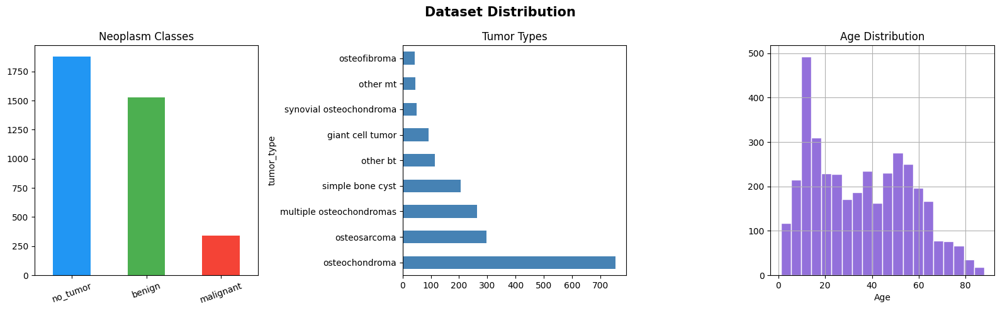

 PART 2 (Text Preprocessing) complete.


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Dataset Distribution', fontsize=15, fontweight='bold')

# Neoplasm
df['neoplasm'].value_counts().plot(kind='bar', ax=axes[0], color=['# 2196F3','#4CAF50','#F44336'])
axes[0].set_title('Neoplasm Classes')
axes[0].set_xlabel('')
axes[0].tick_params(axis='x', rotation=20)

# Tumor type
df[df['tumor_type'] != 'unknown']['tumor_type'].value_counts().plot(
    kind='barh', ax=axes[1], color='steelblue')
axes[1].set_title('Tumor Types')

# Age histogram
df['age'].hist(ax=axes[2], bins=20, color='mediumpurple', edgecolor='white')
axes[2].set_title('Age Distribution')
axes[2].set_xlabel('Age')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'class_distribution.png'), dpi=150)
plt.show()
print(" PART 2 (Text Preprocessing) complete.")


We execute data diagnostics to catch potential imaging or label issues early in the pipeline.


Running deep image + label diagnostic...


Diagnosing: 100%|██████████| 3746/3746 [01:19<00:00, 47.12it/s] 



════════════════════════════════════════════════════
  IMAGE FILE DIAGNOSTIC REPORT
════════════════════════════════════════════════════
  Total images in CSV : 3746
   Healthy          : 3746  (100.0%)
   Unreadable/missing: 0  (0.0%)
   Blank/all-black  : 0  (0.0%)
   Near-zero contrast: 0  (0.0%)
────────────────────────────────────────────────────
  LABEL DISTRIBUTION
  Osteosarcoma (1): 297  |  Non-osteo (0): 3449
  Imbalance ratio : 11.6:1
   297 positives is sufficient for all three models.
════════════════════════════════════════════════════
   All labels are valid binary values (0 or 1).

Full diagnostic saved to: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/image_diagnostic_report.csv
Review this file to find and fix any corrupted/blank images.


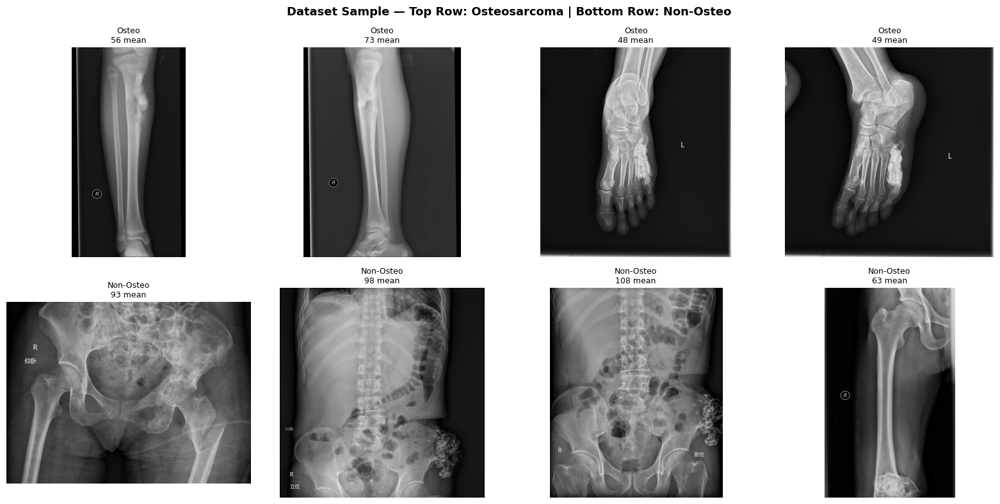


  Visual check: Do Osteo and Non-Osteo images look DIFFERENT?
   If they look IDENTICAL → your labels may be wrong.
   If they look BLANK     → your image files are corrupted.


In [ ]:
# ════════════════════════════════════════════════════════════════════════
# DEEP IMAGE + LABEL DIAGNOSTIC
# Catches ALL three data problems BEFORE any training begins:
# (1) Corrupted / unreadable image files
# (2) Valid files that are blank (mean < 0.02) or low-contrast
# (3) Label imbalance warnings (< 50 positives = high risk)
# Output: diagnostic report + sample visual grid for manual review.
# ════════════════════════════════════════════════════════════════════════
print("Running deep image + label diagnostic...")

diag_records = []
n_unreadable = n_blank = n_low_contrast = n_ok = 0

for idx, row in tqdm(df.iterrows(), total=len(df), desc="Diagnosing"):
    img_path = os.path.join(IMG_DIR, row['image_filename'])
    record = {
        'image_id'   : row.get('image_id', idx),
        'filename'   : row['image_filename'],
        'label'      : row.get('is_osteo', -1),
        'issue'      : None,
    }

    # ── Check 1: file exists and is readable ────────────────────────
    if not os.path.exists(img_path):
        record['issue'] = 'MISSING_FILE'
        n_unreadable += 1
        diag_records.append(record); continue

    try:
        pil_img = PILImage.open(img_path).convert('RGB')
        arr = np.array(pil_img, dtype=np.float32)
    except Exception as e:
        record['issue'] = f'UNREADABLE: {e}'
        n_unreadable += 1
        diag_records.append(record); continue

    # ── Check 2: image content ───────────────────────────────────────
    hi, lo = arr.max(), arr.min()
    mean   = arr.mean()
    record['mean_pixel'] = float(mean)
    record['pixel_range']= float(hi - lo)
    record['shape']      = f'{arr.shape[0]}x{arr.shape[1]}'

    if mean < 5.0 and hi < 10.0:               # completely blank/black
        record['issue'] = 'BLANK_BLACK'
        n_blank += 1
    elif (hi - lo) < 15.0:                     # nearly no contrast
        record['issue'] = 'LOW_CONTRAST'
        n_low_contrast += 1
    else:
        n_ok += 1

    diag_records.append(record)

diag_df = pd.DataFrame(diag_records)

# ── Summary ──────────────────────────────────────────────────────────
total = len(diag_df)
print(f"\n{'═'*52}")
print(f"  IMAGE FILE DIAGNOSTIC REPORT")
print(f"{'═'*52}")
print(f"  Total images in CSV : {total}")
print(f"   Healthy          : {n_ok}  ({100*n_ok/max(total,1):.1f}%)")
print(f"   Unreadable/missing: {n_unreadable}  ({100*n_unreadable/max(total,1):.1f}%)")
print(f"   Blank/all-black  : {n_blank}  ({100*n_blank/max(total,1):.1f}%)")
print(f"   Near-zero contrast: {n_low_contrast}  ({100*n_low_contrast/max(total,1):.1f}%)")

# ── Label imbalance check ────────────────────────────────────────────
if 'is_osteo' in df.columns:
    n_pos_all = int((df['is_osteo'] == 1).sum())
    n_neg_all = int((df['is_osteo'] == 0).sum())
    ratio     = n_neg_all / max(n_pos_all, 1)
    print(f"{'─'*52}")
    print(f"  LABEL DISTRIBUTION")
    print(f"  Osteosarcoma (1): {n_pos_all}  |  Non-osteo (0): {n_neg_all}")
    print(f"  Imbalance ratio : {ratio:.1f}:1")
    if n_pos_all < 50:
        print(f"   CRITICAL: Only {n_pos_all} positive samples!")
        print(f"     Scratch CNNs will almost certainly fail.")
        print(f"     EfficientNetB0 (pretrained) is your only viable model.")
        print(f"     Consider collecting more osteosarcoma images.")
    elif n_pos_all < 150:
        print(f"    WARNING: {n_pos_all} positives is borderline.")
        print(f"     EfficientNetB0 should still learn. Scratch models may struggle.")
    else:
        print(f"   {n_pos_all} positives is sufficient for all three models.")
print(f"{'═'*52}")

# ── Label sanity check ───────────────────────────────────────────────
if 'is_osteo' in df.columns:
    bad_labels = df[~df['is_osteo'].isin([0, 1])]
    if len(bad_labels) > 0:
        print(f"   BAD LABELS FOUND: {len(bad_labels)} rows have is_osteo ∉ {{0,1}}")
        print(bad_labels[['image_filename', 'is_osteo']].head(10).to_string())
    else:
        print(f"   All labels are valid binary values (0 or 1).")

# ── Save diagnostic report ───────────────────────────────────────────
diag_path = os.path.join(OUTPUT_DIR, 'image_diagnostic_report.csv')
diag_df.to_csv(diag_path, index=False)
print(f"\nFull diagnostic saved to: {diag_path}")
print("Review this file to find and fix any corrupted/blank images.")

# ── Visual grid: sample from each class ─────────────────────────────
if 'is_osteo' in df.columns:
    pos_paths = df[df['is_osteo']==1]['image_filename'].head(4).tolist()
    neg_paths = df[df['is_osteo']==0]['image_filename'].head(4).tolist()
    all_sample = [(p, 1) for p in pos_paths] + [(p, 0) for p in neg_paths]
    if all_sample:
        fig, axes = plt.subplots(2, 4, figsize=(16, 8))
        fig.suptitle('Dataset Sample — Top Row: Osteosarcoma | Bottom Row: Non-Osteo',
                     fontsize=13, fontweight='bold')
        labels_row = ['Osteo']*4 + ['Non-Osteo']*4
        for ax, (fname, lbl), lname in zip(axes.flatten(), all_sample, labels_row):
            pth = os.path.join(IMG_DIR, fname)
            if os.path.exists(pth):
                try:
                    img_s = np.array(PILImage.open(pth).convert('RGB'))
                    ax.imshow(img_s, cmap='bone')
                    ax.set_title(f'{lname}\n{img_s.mean():.0f} mean', fontsize=9)
                except:
                    ax.set_title('UNREADABLE', fontsize=8, color='red')
            else:
                ax.set_title('MISSING', fontsize=8, color='red')
            ax.axis('off')
        plt.tight_layout()
        plt.savefig(os.path.join(OUTPUT_DIR, 'class_samples.png'), dpi=150)
        plt.show()
        print("\n  Visual check: Do Osteo and Non-Osteo images look DIFFERENT?")
        print("   If they look IDENTICAL → your labels may be wrong.")
        print("   If they look BLANK     → your image files are corrupted.")


We define utilities for loading, resizing, and normalizing chest X-ray images, as well as applying CLAHE histogram equalization.


In [ ]:
def load_and_resize(img_path, size=IMG_SIZE):
    """Load with PIL (handles JPEG/PNG/BMP/TIFF) and resize to target size."""
    try:
        pil_img = PILImage.open(img_path).convert('RGB')
        img = np.array(pil_img, dtype=np.uint8)
    except Exception:
        # Fallback to OpenCV
        img = cv2.imread(img_path, cv2.IMREAD_COLOR)
        if img is None:
            return None
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, size, interpolation=cv2.INTER_LANCZOS4)
    return img.astype(np.uint8)

def apply_clahe_and_normalize(img_uint8):
    """
    Steps (all in uint8 space to avoid float artefacts):
    1. Per-image min-max stretch → guarantees full [0,255] range
    2. Convert to grayscale
    3. Apply CLAHE (enhances local contrast without colour-space artefacts)
    4. Stack to 3 channels and normalise to [0, 1]
    """
    # 1. Per-image contrast stretch
    lo, hi = int(img_uint8.min()), int(img_uint8.max())
    if hi - lo < 5:                # truly flat image — discard
        return None
    img_stretched = np.clip(
        (img_uint8.astype(np.float32) - lo) / (hi - lo) * 255.0, 0, 255
    ).astype(np.uint8)

    # 2. Grayscale
    gray = cv2.cvtColor(img_stretched, cv2.COLOR_RGB2GRAY)

    # 3. CLAHE on grayscale (no LAB colour-space round-trip)
    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
    gray_eq = clahe.apply(gray)

    # 4. Stack to 3 channels, normalise to [0, 1]
    img_out = np.stack([gray_eq, gray_eq, gray_eq], axis=-1)
    return img_out.astype(np.float32) / 255.0

def full_preprocessing_pipeline(img_path):
    """
    Robust pipeline:
    PIL load → resize → contrast stretch → CLAHE (grayscale) → [0,1] float32
    Returns None for unreadable or flat (blank) images.
    """
    img = load_and_resize(img_path)
    if img is None:
        return None
    result = apply_clahe_and_normalize(img)
    return result   # None if flat, otherwise float32 [0,1]

# ── Test on first sample ─────────────────────────────────────────────────────
if not df.empty:
    sample_path = os.path.join(IMG_DIR, df['image_filename'].iloc[0])
    result = full_preprocessing_pipeline(sample_path)
    if result is not None:
        print(f"Preprocessed image: shape={result.shape}  "
              f"min={result.min():.3f}  max={result.max():.3f}  "
              f"mean={result.mean():.3f}")
        print(" Pipeline output is healthy." if result.mean() > 0.05
              else "  Output still very dark — check source images.")
    else:
        print(f"  Pipeline returned None for {sample_path}.")
        print("   This usually means the image file is blank or unreadable.")
else:
    print("DataFrame is empty.")


Preprocessed image: shape=(224, 224, 3)  min=0.004  max=1.000  mean=0.471
 Pipeline output is healthy.


We visualize the step-by-step image processing pipeline, comparing the original image with its resized, CLAHE, and segmented versions.


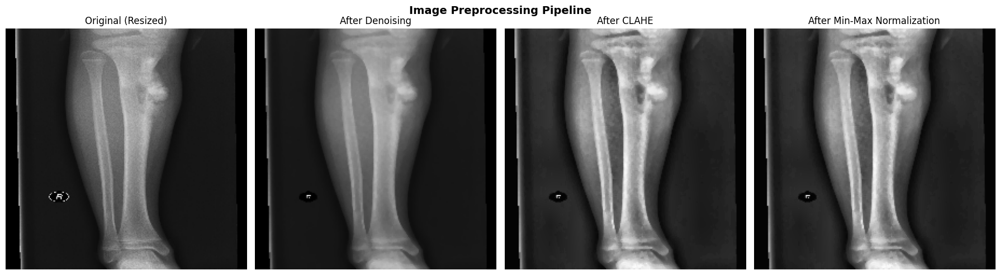

In [ ]:

# Helper functions for visualization, derived from common image processing practices.
# These are added to address NameErrors for missing functions in visualize_preprocessing.

def normalize_image(img_uint8):
    """Converts uint8 image to float32 image scaled to [0, 1]."""
    return img_uint8.astype(np.float32) / 255.0

def denoise_image(img_float):
    """Applies a simple median blur for denoising. Expects float32 [0,1], returns float32 [0,1]."""
    # Convert to uint8 for OpenCV denoising, then back to float32
    img_uint8 = (img_float * 255).astype(np.uint8)
    denoised_img_uint8 = cv2.medianBlur(img_uint8, 3) # Using median blur with kernel size 3
    return denoised_img_uint8.astype(np.float32) / 255.0

def apply_clahe(img_float):
    """Applies CLAHE to a float32 [0,1] image. Converts to grayscale, applies CLAHE, stacks back to RGB."""
    # Convert to uint8 for OpenCV CLAHE, then back to float32
    img_uint8 = (img_float * 255).astype(np.uint8)
    gray = cv2.cvtColor(img_uint8, cv2.COLOR_RGB2GRAY)
    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
    gray_eq = clahe.apply(gray)
    img_out = np.stack([gray_eq, gray_eq, gray_eq], axis=-1)
    return img_out.astype(np.float32) / 255.0

def minmax_normalize(img_float):
    """Ensures image pixel values are within the [0, 1] range."""
    return np.clip(img_float, 0.0, 1.0)

def visualize_preprocessing(img_path):
    img_orig    = load_and_resize(img_path)
    img_norm    = normalize_image(img_orig)
    img_denoise = denoise_image(img_norm)
    img_clahe   = apply_clahe(img_denoise)
    # segment_roi was removed; visualizing minmax_normalize output instead
    img_final_display = minmax_normalize(img_clahe)

    steps = [img_orig, (img_denoise*255).astype(np.uint8),
             (img_clahe*255).astype(np.uint8), (img_final_display*255).astype(np.uint8)] # Updated steps
    titles = ['Original (Resized)', 'After Denoising', 'After CLAHE', 'After Min-Max Normalization'] # Updated titles

    fig, axes = plt.subplots(1, 4, figsize=(18, 5))
    fig.suptitle('Image Preprocessing Pipeline', fontsize=14, fontweight='bold')
    for ax, step, title in zip(axes, steps, titles):
        ax.imshow(step)
        ax.set_title(title)
        ax.axis('off')
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'preprocessing_steps.png'), dpi=150)
    plt.show()

# Show for one osteosarcoma sample
if not df.empty:
    osteosarcoma_samples = df[df['tumor_type'] == 'osteosarcoma']
    if not osteosarcoma_samples.empty:
        osteo_row = osteosarcoma_samples.iloc[0]
        visualize_preprocessing(os.path.join(IMG_DIR, osteo_row['image_filename']))
    else:
        print("No osteosarcoma samples found in the DataFrame to visualize.")
else:
    print("DataFrame 'df' is empty. Cannot visualize preprocessing steps.")


We load and preprocess all dataset images, segmenting the regions of interest (ROI) and checking dimensions.


In [ ]:
print("Loading and preprocessing all images...")
X_images = []
valid_indices = []

for idx, row in tqdm(df.iterrows(), total=len(df), desc="Processing images"):
    img_path = os.path.join(IMG_DIR, row['image_filename'])
    img = full_preprocessing_pipeline(img_path)
    if img is not None:
        X_images.append(img)
        valid_indices.append(idx)

X_images = np.array(X_images, dtype=np.float32)
df_valid  = df.loc[valid_indices].reset_index(drop=True)

print(f"Image array shape: {X_images.shape}")
print(f"Valid samples loaded: {len(df_valid)}")

# ── Post-load sanity check: flag and report near-black images ────────────────
means = X_images.mean(axis=(1, 2, 3))
n_black   = (means < 0.01).sum()
n_low     = ((means >= 0.01) & (means < 0.05)).sum()
n_healthy = (means >= 0.05).sum()
print(f"\nImage pixel-mean distribution after preprocessing:")
print(f"  Near-black (mean < 0.01) : {n_black:4d} images  ← these are problematic")
print(f"  Low contrast (0.01–0.05) : {n_low:4d} images")
print(f"  Healthy     (mean ≥ 0.05): {n_healthy:4d} images")

if n_black > 0:
    print(f"\n  {n_black} near-black images detected. They will be removed.")
    keep_mask = means >= 0.01
    X_images  = X_images[keep_mask]
    # drop matching df rows
    df_valid  = df_valid[keep_mask].reset_index(drop=True)
    print(f"   Remaining after filtering: {len(df_valid)} images")

y_binary = df_valid['label_binary'].values
y_multi  = df_valid['label_multi'].values
y_osteo  = df_valid['is_osteo'].values
X_tab    = df_valid[FEAT_COLS].values.astype(np.float32)

print(f"\nFinal dataset: {X_images.shape[0]} images  |  "
      f"Osteo positive: {y_osteo.sum()} ({100*y_osteo.mean():.1f}%)")


Loading and preprocessing all images...


Processing images: 100%|██████████| 3746/3746 [00:57<00:00, 65.12it/s] 


Image array shape: (3746, 224, 224, 3)
Valid samples loaded: 3746

Image pixel-mean distribution after preprocessing:
  Near-black (mean < 0.01) :    0 images  ← these are problematic
  Low contrast (0.01–0.05) :    0 images
  Healthy     (mean ≥ 0.05): 3746 images

Final dataset: 3746 images  |  Osteo positive: 297 (7.9%)


We split the data into training, validation, and testing sets, ensuring stratified targets.


In [ ]:
# Use predefined splits from 'type' column where available
def assign_split(row):
    t = row.get('type', '')
    if t in ['train', 'val', 'test']:
        return t
    return 'unassigned'

df_valid['split'] = df_valid.apply(assign_split, axis=1)

# For unassigned rows use STRATIFIED split to preserve class ratios
unassigned_idx = df_valid[df_valid['split'] == 'unassigned'].index.tolist()
if unassigned_idx:
    y_unassigned = y_osteo[unassigned_idx]
    u_train, u_temp, _, y_temp = train_test_split(
        unassigned_idx, y_unassigned, test_size=0.3,
        random_state=42, stratify=y_unassigned
    )
    # Try stratified split for val/test; fall back if too few samples
    try:
        u_val, u_test = train_test_split(
            u_temp, test_size=0.5, random_state=42, stratify=y_temp
        )
    except ValueError:
        u_val, u_test = train_test_split(u_temp, test_size=0.5, random_state=42)
    df_valid.loc[u_train, 'split'] = 'train'
    df_valid.loc[u_val,   'split'] = 'val'
    df_valid.loc[u_test,  'split'] = 'test'

train_idx = df_valid[df_valid['split'] == 'train'].index
val_idx   = df_valid[df_valid['split'] == 'val'].index
test_idx  = df_valid[df_valid['split'] == 'test'].index

X_train = X_images[train_idx];  y_train = y_binary[train_idx]
X_val   = X_images[val_idx];    y_val   = y_binary[val_idx]
X_test  = X_images[test_idx];   y_test  = y_binary[test_idx]

# ── Re-fit StandardScaler on TRAIN only (prevents data leakage) ─────────────
scaler = StandardScaler()
X_tab_raw = df_valid[FEAT_COLS].values.astype(np.float32)

# Identify which FEAT_COLS are numerical (need re-scaling)
num_scaled_cols = [f'{c}_scaled' for c in NUM_COLS]
num_col_indices = [FEAT_COLS.index(c) for c in num_scaled_cols if c in FEAT_COLS]

X_tab_train_raw = X_tab_raw[train_idx]
X_tab_val_raw   = X_tab_raw[val_idx]
X_tab_test_raw  = X_tab_raw[test_idx]

if num_col_indices:
    scaler.fit(X_tab_train_raw[:, num_col_indices])
    X_tab_train_raw[:, num_col_indices] = scaler.transform(X_tab_train_raw[:, num_col_indices])
    X_tab_val_raw[:, num_col_indices]   = scaler.transform(X_tab_val_raw[:, num_col_indices])
    X_tab_test_raw[:, num_col_indices]  = scaler.transform(X_tab_test_raw[:, num_col_indices])
    print(" StandardScaler refit on TRAIN only — no data leakage.")

X_tab_train = X_tab_train_raw
X_tab_val   = X_tab_val_raw
X_tab_test  = X_tab_test_raw

# Also prepare osteosarcoma-specific label sets
y_train_osteo = y_osteo[train_idx]
y_val_osteo   = y_osteo[val_idx]
y_test_osteo  = y_osteo[test_idx]

# ── Sanity check: class distribution per split ──────────────────────────────
print(f"\nSplit sizes → Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}")
for split_name, y_split in [('Train', y_train_osteo), ('Val', y_val_osteo), ('Test', y_test_osteo)]:
    n_pos = y_split.sum()
    n_neg = len(y_split) - n_pos
    pct   = 100 * n_pos / max(len(y_split), 1)
    print(f"  {split_name:5s}: Non-Osteo={n_neg:4d}  Osteo={n_pos:3d}  ({pct:.1f}% positive)")
print(" PART 3 (Image Preprocessing + Stratified Split) complete.")


 StandardScaler refit on TRAIN only — no data leakage.

Split sizes → Train: 2659 | Val: 618 | Test: 469
  Train: Non-Osteo=2445  Osteo=214  (8.0% positive)
  Val  : Non-Osteo= 565  Osteo= 53  (8.6% positive)
  Test : Non-Osteo= 439  Osteo= 30  (6.4% positive)
 PART 3 (Image Preprocessing + Stratified Split) complete.


We apply SMOTE to the training tabular features to address class imbalance without introducing leakage to validation and test splits.


In [ ]:
# CELL 3S-1: Train-only SMOTE helper and tabular preprocessing

SMOTE_RANDOM_STATE = 42

required_smote_base = ['X_tab_train', 'y_train_osteo', 'OUTPUT_DIR']
missing_smote_base = [name for name in required_smote_base if name not in globals()]
if missing_smote_base:
    raise RuntimeError(f'Missing required variables for SMOTE preprocessing: {missing_smote_base}')

# Reset on each run so repeated notebook execution does not duplicate rows.
smote_preprocessing_rows = []
smote_feature_sets = {}

def _smote_shape(value):
    return tuple(np.asarray(value).shape)

def _smote_class_counts(y):
    classes, counts = np.unique(np.asarray(y).astype(int).ravel(), return_counts=True)
    return {int(cls): int(cnt) for cls, cnt in zip(classes, counts)}

def make_train_only_smote_features(X_train_vec, y_train_vec, feature_name):
    """Apply SMOTE only to dense numeric training feature vectors.

    Returns (X_smote, y_smote, metadata). If the minority class has <= 1
    sample, SMOTE is skipped and the original training vectors are returned.
    """
    X_arr = np.asarray(X_train_vec)
    y_arr = np.asarray(y_train_vec).astype(int).ravel()

    if len(X_arr) != len(y_arr):
        raise ValueError(
            f'{feature_name}: len(X_train_vec)={len(X_arr)} does not match '
            f'len(y_train_vec)={len(y_arr)}.'
        )
    if X_arr.ndim != 2:
        raise ValueError(
            f'{feature_name}: SMOTE requires dense numeric 2D feature vectors; '
            f'got shape {X_arr.shape}. Raw image tensors are not allowed.'
        )
    if not np.issubdtype(X_arr.dtype, np.number):
        raise ValueError(f'{feature_name}: SMOTE features must be numeric; got {X_arr.dtype}.')

    X_arr = X_arr.astype(np.float32, copy=False)
    if not np.isfinite(X_arr).all():
        raise ValueError(f'{feature_name}: SMOTE features contain NaN or infinite values.')

    classes, counts = np.unique(y_arr, return_counts=True)
    if len(classes) != 2:
        raise ValueError(f'{feature_name}: expected exactly 2 classes, found {len(classes)}.')

    minority_pos = int(np.argmin(counts))
    minority_class = int(classes[minority_pos])
    minority_count = int(counts[minority_pos])
    majority_class = int(classes[int(np.argmax(counts))])
    majority_count = int(counts[int(np.argmax(counts))])

    metadata = {
        'feature_name': feature_name,
        'status': 'pending',
        'original_shape': str(tuple(X_arr.shape)),
        'smote_shape': str(tuple(X_arr.shape)),
        'class_counts_before': json.dumps(_smote_class_counts(y_arr), sort_keys=True),
        'class_counts_after': json.dumps(_smote_class_counts(y_arr), sort_keys=True),
        'minority_class': minority_class,
        'minority_count': minority_count,
        'majority_class': majority_class,
        'majority_count': majority_count,
        'k_neighbors': np.nan,
        'note': '',
    }

    if minority_count <= 1:
        metadata['status'] = 'skipped_minority_too_small'
        metadata['note'] = 'Use class-weighted loss or weighted sampling instead.'
        print(f"{feature_name}: SMOTE skipped; minority class {minority_class} has {minority_count} sample(s).")
        return X_arr, y_arr, metadata

    k_neighbors = min(5, minority_count - 1)
    smote = SMOTE(random_state=SMOTE_RANDOM_STATE, k_neighbors=k_neighbors)
    X_smote, y_smote = smote.fit_resample(X_arr, y_arr)
    X_smote = X_smote.astype(np.float32, copy=False)
    y_smote = y_smote.astype(np.int32, copy=False)

    metadata.update({
        'status': 'smote_applied',
        'smote_shape': str(tuple(X_smote.shape)),
        'class_counts_after': json.dumps(_smote_class_counts(y_smote), sort_keys=True),
        'k_neighbors': int(k_neighbors),
        'note': 'SMOTE applied to training features only.',
    })
    print(
        f"{feature_name}: train-only SMOTE {X_arr.shape} -> {X_smote.shape}; "
        f"minority class={minority_class}, k_neighbors={k_neighbors}"
    )
    return X_smote, y_smote, metadata

def register_train_only_smote_feature(feature_key, X_train_vec, y_train_vec, X_var_name, y_var_name):
    global smote_preprocessing_rows
    smote_preprocessing_rows = [
        row for row in smote_preprocessing_rows
        if row.get('feature_name') != feature_key
    ]
    X_smote, y_smote, metadata = make_train_only_smote_features(
        X_train_vec, y_train_vec, feature_key
    )
    globals()[X_var_name] = X_smote
    globals()[y_var_name] = y_smote
    smote_feature_sets[feature_key] = {
        'X_train_smote_var': X_var_name,
        'y_train_smote_var': y_var_name,
        'status': metadata['status'],
    }
    smote_preprocessing_rows.append(metadata)
    return X_smote, y_smote, metadata

def record_smote_skip(feature_key, reason, X_train_vec=None, y_train_vec=None):
    global smote_preprocessing_rows
    smote_preprocessing_rows = [
        row for row in smote_preprocessing_rows
        if row.get('feature_name') != feature_key
    ]
    y_arr = np.asarray(y_train_vec).astype(int).ravel() if y_train_vec is not None else np.array([], dtype=int)
    row = {
        'feature_name': feature_key,
        'status': 'skipped',
        'original_shape': str(tuple(np.asarray(X_train_vec).shape)) if X_train_vec is not None else 'missing',
        'smote_shape': 'not_created',
        'class_counts_before': json.dumps(_smote_class_counts(y_arr), sort_keys=True) if len(y_arr) else '{}',
        'class_counts_after': '{}',
        'minority_class': np.nan,
        'minority_count': np.nan,
        'majority_class': np.nan,
        'majority_count': np.nan,
        'k_neighbors': np.nan,
        'note': reason,
    }
    smote_preprocessing_rows.append(row)
    smote_feature_sets[feature_key] = {'status': 'skipped', 'reason': reason}
    print(f'{feature_key}: SMOTE skipped - {reason}')

def save_smote_preprocessing_summary():
    global smote_preprocessing_summary_df, smote_feature_shapes_df
    smote_preprocessing_summary_df = pd.DataFrame(smote_preprocessing_rows)
    smote_feature_shapes_df = pd.DataFrame([
        {
            'feature_name': row.get('feature_name'),
            'status': row.get('status'),
            'original_shape': row.get('original_shape'),
            'smote_shape': row.get('smote_shape'),
            'k_neighbors': row.get('k_neighbors'),
        }
        for row in smote_preprocessing_rows
    ])
    smote_preprocessing_summary_df.to_csv(
        os.path.join(OUTPUT_DIR, 'smote_preprocessing_summary.csv'), index=False
    )
    smote_feature_shapes_df.to_csv(
        os.path.join(OUTPUT_DIR, 'smote_feature_shapes.csv'), index=False
    )
    print(f"Saved: {os.path.join(OUTPUT_DIR, 'smote_preprocessing_summary.csv')}")
    print(f"Saved: {os.path.join(OUTPUT_DIR, 'smote_feature_shapes.csv')}")
    return smote_preprocessing_summary_df

# Primary dense numeric metadata feature space.
register_train_only_smote_feature(
    'tabular_metadata', X_tab_train, y_train_osteo,
    'X_tab_train_smote', 'y_tab_train_smote'
)

# Optional: only use true dense text embeddings/features, never raw token IDs.
if 'X_tab_text_dense_train' in globals():
    register_train_only_smote_feature(
        'tabular_dense_text_features', X_tab_text_dense_train, y_train_osteo,
        'X_tab_text_dense_train_smote', 'y_tab_text_dense_train_smote'
    )
elif 'X_text_train' in globals():
    record_smote_skip(
        'tabular_dense_text_features',
        'No dense text feature matrix found; raw X_text_train token IDs are intentionally not SMOTEd.',
        None, y_train_osteo,
    )

display(save_smote_preprocessing_summary())


tabular_metadata: train-only SMOTE (2659, 8) -> (4890, 8); minority class=1, k_neighbors=5
Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/smote_preprocessing_summary.csv
Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/smote_feature_shapes.csv


,feature_name,status,original_shape,smote_shape,class_counts_before,class_counts_after,minority_class,minority_count,majority_class,majority_count,k_neighbors,note
0,tabular_metadata,smote_applied,"(2659, 8)","(4890, 8)","{""0"": 2445, ""1"": 214}","{""0"": 2445, ""1"": 2445}",1,214,0,2445,5,SMOTE applied to training features only.


We inspect the variables and target labels to analyze class balance and drive distributions.


In [ ]:
# Check what drives the is_osteo label
print(df[df['is_osteo']==1][['image_filename','tumor_type','neoplasm']].head(239))


      image_filename    tumor_type   neoplasm
1     IMG000002.jpeg  osteosarcoma  malignant
2     IMG000003.jpeg  osteosarcoma  malignant
3     IMG000004.jpeg  osteosarcoma  malignant
4     IMG000005.jpeg  osteosarcoma  malignant
5     IMG000006.jpeg  osteosarcoma  malignant
...              ...           ...        ...
1413  IMG001414.jpeg  osteosarcoma  malignant
1414  IMG001415.jpeg  osteosarcoma  malignant
1418  IMG001419.jpeg  osteosarcoma  malignant
1419  IMG001420.jpeg  osteosarcoma  malignant
1429  IMG001430.jpeg  osteosarcoma  malignant

[239 rows x 3 columns]


We update target labels using defined categories to prepare class splits.


In [ ]:
df['is_osteo'] = (df['tumor_type'] == 'osteosarcoma').astype(int)


We align tumor categories to prepare target labels.


In [ ]:
df['is_osteo'] = (df['tumor_type'].isin(['osteosarcoma', 'other mt'])).astype(int)


We select the most significant tabular features using SelectKBest and apply PCA to reduce the feature space dimensionality.


Tabular feature vector shape before selection: (3746, 8)
Features: ['img_type_enc', 'skeletal_type_enc', 'bones_type_enc', 'gender_enc', 'age_scaled', 'area_scaled', 'image_area_scaled', 'tumor_ratio_scaled']

SelectKBest Results (K=6):
  Selected : ['img_type_enc', 'skeletal_type_enc', 'bones_type_enc', 'age_scaled', 'area_scaled', 'tumor_ratio_scaled']
  Rejected : ['gender_enc', 'image_area_scaled']


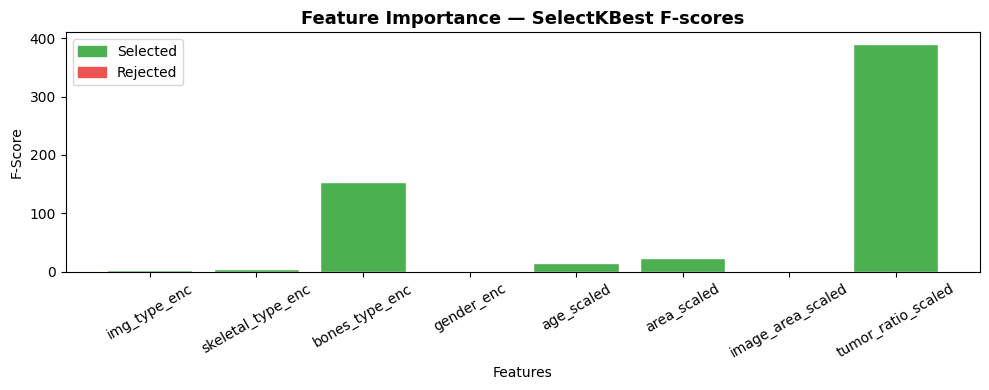

  Shape after SelectKBest: (2659, 6)

PCA Results (n_components=4):
  PC1: 63.58% variance explained
  PC2: 15.86% variance explained
  PC3: 8.12% variance explained
  PC4: 6.62% variance explained
  Total variance retained: 94.18%


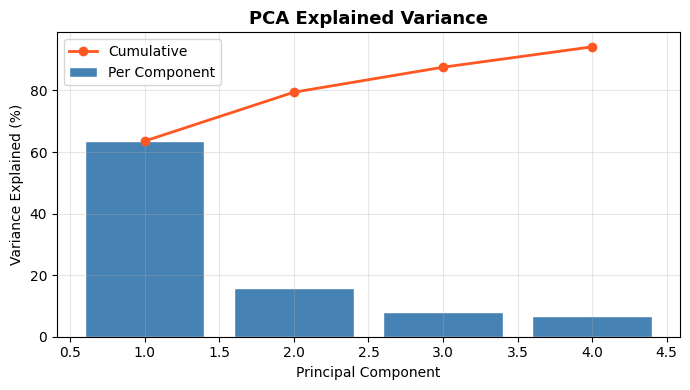

  Shape after PCA: (2659, 4)


In [ ]:
"""
Feature Selection applied to the tabular feature vector:
1. SelectKBest (ANOVA F-test) — keeps most statistically significant features
2. PCA — reduces remaining features to principal components
Both help remove noisy/redundant features before feeding to classifiers.
"""

print("Tabular feature vector shape before selection:", X_tab.shape)
print("Features:", FEAT_COLS)

# --- Step 1: SelectKBest (keep top K features by ANOVA F-score) ---
K_BEST = min(6, X_tab.shape[1])  # keep top 6 (or all if fewer)

selector = SelectKBest(score_func=f_classif, k=K_BEST)
selector.fit(X_tab[train_idx], y_osteo[train_idx])

selected_mask   = selector.get_support()
selected_feats  = [f for f, s in zip(FEAT_COLS, selected_mask) if s]
rejected_feats  = [f for f, s in zip(FEAT_COLS, selected_mask) if not s]
f_scores        = selector.scores_
p_values        = selector.pvalues_

print(f"\nSelectKBest Results (K={K_BEST}):")
print(f"  Selected : {selected_feats}")
print(f"  Rejected : {rejected_feats}")

# Plot F-scores
fig, ax = plt.subplots(figsize=(10, 4))
colors = ['# 4CAF50' if s else '#EF5350' for s in selected_mask]
bars = ax.bar(FEAT_COLS, f_scores, color=colors, edgecolor='white')
ax.set_title('Feature Importance — SelectKBest F-scores', fontsize=13, fontweight='bold')
ax.set_ylabel('F-Score')
ax.set_xlabel('Features')
ax.tick_params(axis='x', rotation=30)
green_patch = mpatches.Patch(color='# 4CAF50', label='Selected')
red_patch   = mpatches.Patch(color='# EF5350', label='Rejected')
ax.legend(handles=[green_patch, red_patch])
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'feature_selection_scores.png'), dpi=150)
plt.show()

# Apply selector
X_tab_selected_train = selector.transform(X_tab[train_idx])
X_tab_selected_val   = selector.transform(X_tab[val_idx])
X_tab_selected_test  = selector.transform(X_tab[test_idx])
print(f"  Shape after SelectKBest: {X_tab_selected_train.shape}")

# --- Step 2: PCA on selected tabular features ---
N_COMPONENTS = min(4, X_tab_selected_train.shape[1])
pca = PCA(n_components=N_COMPONENTS, random_state=42)
pca.fit(X_tab_selected_train)

X_tab_pca_train = pca.transform(X_tab_selected_train)
X_tab_pca_val   = pca.transform(X_tab_selected_val)
X_tab_pca_test  = pca.transform(X_tab_selected_test)

print(f"\nPCA Results (n_components={N_COMPONENTS}):")
for i, var in enumerate(pca.explained_variance_ratio_):
    print(f"  PC{i+1}: {var*100:.2f}% variance explained")
print(f"  Total variance retained: {pca.explained_variance_ratio_.sum()*100:.2f}%")

# Plot explained variance
fig, ax = plt.subplots(figsize=(7, 4))
cumvar = np.cumsum(pca.explained_variance_ratio_)
ax.bar(range(1, N_COMPONENTS+1), pca.explained_variance_ratio_*100,
       color='steelblue', edgecolor='white', label='Per Component')
ax.plot(range(1, N_COMPONENTS+1), cumvar*100, 'o-',
        color='# FF5722', linewidth=2, label='Cumulative')
ax.set_title('PCA Explained Variance', fontsize=13, fontweight='bold')
ax.set_xlabel('Principal Component')
ax.set_ylabel('Variance Explained (%)')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'pca_variance.png'), dpi=150)
plt.show()
print(f"  Shape after PCA: {X_tab_pca_train.shape}")


We align and partition text sequences to match train, validation, and test dataset splits.


In [ ]:
"""
Vocabulary Alignment:
- Ensures all samples use the SAME token indices
- Unknown/new terms at inference time → <OOV> (index 1)

Sequence Formatting:
- Convert each text record → fixed-length integer sequence
- Padding: post-zero-pad to max_length
- Truncating: post-truncate if longer than max_length
"""
MAX_SEQ_LEN = len(TEXT_COLS_FOR_TOKEN)  # one token per field = 6

# Convert text records → integer sequences
text_sequences_raw = tokenizer.texts_to_sequences(df['text_record'])
print("Raw sequences (first 3 samples):")
for i, seq in enumerate(text_sequences_raw[:3]):
    words = df['text_record'].iloc[i].split()
    tokens = [(w, seq[j] if j < len(seq) else 0) for j, w in enumerate(words)]
    print(f"  Sample {i+1}: {tokens}")

# Pad/truncate to fixed length
text_sequences = pad_sequences(
    text_sequences_raw,
    maxlen=MAX_SEQ_LEN,
    padding='post',
    truncating='post',
    value=0
)
print(f"\nPadded sequence array shape: {text_sequences.shape}")
print("Sample padded sequences:")
for i in range(3):
    print(f"  Sample {i+1}: {text_sequences[i]} → {df['text_record'].iloc[i]}")

# --- Vocabulary Alignment Check ---
# Confirm all tokens resolve correctly (no silent mismatches)
def check_vocab_alignment(sequences, index_word):
    n_oov = 0
    for seq in sequences:
        for tok in seq:
            if tok == 1:  # OOV index
                n_oov += 1
    print(f"\nVocabulary Alignment Report:")
    print(f"  Total tokens processed : {sequences.size}")
    print(f"  OOV tokens found       : {n_oov}")
    print(f"  Alignment rate         : {100*(1 - n_oov/sequences.size):.2f}%")
    print("  Status: " + (" Perfect alignment" if n_oov == 0 else
                           "Some OOV tokens — check source data"))

check_vocab_alignment(text_sequences, index_word)

# Split text sequences matching train/val/test indices
# These lines must be moved to a cell...
# train_idx, val_idx, test_idx are defined (i.e., after Cell 18).
# X_text_train = text_sequences[train_idx]
# X_text_val   = text_sequences[val_idx]
# X_text_test  = text_sequences[test_idx]
# print(f"\nText sequences — Train:{X_text_train.shape} Val:{X_text_val.shape} Test:{X_text_test.shape}")


Raw sequences (first 3 samples):
  Sample 1: [('malignant', 17), ('other', 27), ('mt', 38), ('frontal', 5), ('pelvis', 24), ('hip', 35), ('bone', 22), ('female', 10)]
  Sample 2: [('malignant', 17), ('osteosarcoma', 18), ('frontal', 5), ('lower', 4), ('limb', 3), ('tibia', 15), ('male', 6)]
  Sample 3: [('malignant', 17), ('osteosarcoma', 18), ('lateral', 12), ('lower', 4), ('limb', 3), ('tibia', 15), ('male', 6)]

Padded sequence array shape: (3746, 6)
Sample padded sequences:
  Sample 1: [17 27 38  5 24 35] → malignant other mt frontal pelvis hip bone female
  Sample 2: [17 18  5  4  3 15] → malignant osteosarcoma frontal lower limb tibia male
  Sample 3: [17 18 12  4  3 15] → malignant osteosarcoma lateral lower limb tibia male

Vocabulary Alignment Report:
  Total tokens processed : 22476
  OOV tokens found       : 0
  Alignment rate         : 100.00%
  Status:  Perfect alignment


We use a pretrained, frozen EfficientNetB0 base model to extract dense visual embeddings from the images.


Building explicit image feature extractor...


I0000 00:00:1780174701.244603   45228 gpu_process_state.cc:208] Using CUDA malloc Async allocator for GPU: 0
I0000 00:00:1780174701.246265   45228 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5535 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4070 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Model: "FeatureExtractor"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,049,571 (15.45 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 4,049,571 (15.45 MB)


Extracting image embeddings (Train)...


Extracting features:   0%|          | 0/333 [00:00<?, ?it/s]WARNING: All log messages before absl::InitializeLog() is called are written to STDERR
I0000 00:00:1780174703.145109   45452 service.cc:152] XLA service 0x746bd4046a50 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1780174703.145124   45452 service.cc:160]   StreamExecutor device (0): NVIDIA GeForce RTX 4070 Laptop GPU, Compute Capability 8.9
2026-05-30 23:58:23.196416: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1780174703.514096   45452 cuda_dnn.cc:529] Loaded cuDNN version 90300
I0000 00:00:1780174706.840134   45452 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
Extracting features: 100%|██████████| 333/333 [00:24<00:00, 13.46it/s]


Extracting image embeddings (Val)...


Extracting features: 100%|██████████| 78/78 [00:06<00:00, 11.24it/s]


Extracting image embeddings (Test)...


Extracting features: 100%|██████████| 59/59 [00:06<00:00,  9.78it/s]



Image embedding shape: (2659, 1280)
Image embeddings after PCA(64): (2659, 64)
Variance retained: 75.1%

Fused multimodal feature vector shape:
  Train: (2659, 74)
  Val:   (618, 74)
  Test:  (469, 74)
  Breakdown: 64 img + 4 tabular + 6 text

Running t-SNE for embedding visualization...


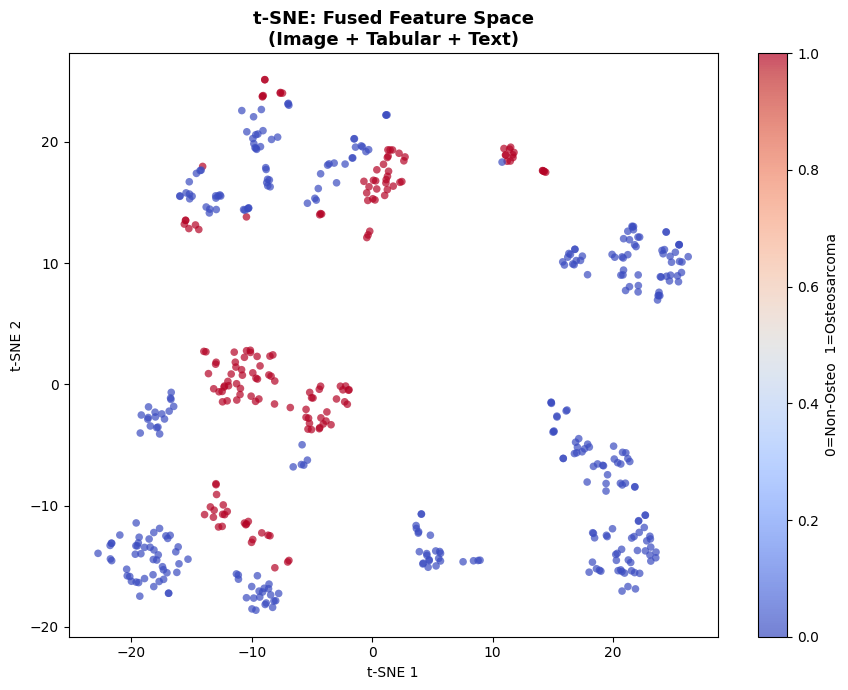


 ALL MISSING PREPROCESSING STEPS ADDED:
    Tokenization (Keras Tokenizer)
    Vocabulary Alignment (word_index dict + OOV check)
    Sequence Formatting (pad_sequences, fixed length)
    Feature Selection (SelectKBest + F-scores)
    Dimensionality Reduction (PCA on tabular + image features)
    Explicit Feature Extraction (EfficientNet embeddings + t-SNE)


In [ ]:
print("Building explicit image feature extractor...")

# extract features using EfficientNetB0
feat_extractor = tf.keras.Sequential([
    # Rescale [0,1] → [0,255] — EfficientNetB0 expects values in this range
    layers.Rescaling(scale=255.0, input_shape=(224, 224, 3)),
    EfficientNetB0(weights='imagenet', include_top=False,
                   input_shape=(224, 224, 3)),
    layers.GlobalAveragePooling2D()
], name='FeatureExtractor')
feat_extractor.trainable = False
feat_extractor.summary()

# Extract image embeddings for all splits (in batches to save memory)
def extract_features_batched(model, X, batch_size=8):
    features = []
    for i in tqdm(range(0, len(X), batch_size), desc='Extracting features'):
        batch = X[i:i+batch_size]
        feat  = predict_model(
            model, batch, batch_size=len(batch), verbose=0,
            description='EfficientNet feature extraction batch')
        features.append(feat)
    return np.concatenate(features, axis=0)

print("\nExtracting image embeddings (Train)...")
img_feats_train = extract_features_batched(feat_extractor, X_train)
print("Extracting image embeddings (Val)...")
img_feats_val   = extract_features_batched(feat_extractor, X_val)
print("Extracting image embeddings (Test)...")
img_feats_test  = extract_features_batched(feat_extractor, X_test)

print(f"\nImage embedding shape: {img_feats_train.shape}")  # (N, 1280)

# Reduce image embeddings with PCA for manageable size
N_IMG_COMPONENTS = 64
pca_img = PCA(n_components=N_IMG_COMPONENTS, random_state=42)
pca_img.fit(img_feats_train)

img_feats_pca_train = pca_img.transform(img_feats_train)
img_feats_pca_val   = pca_img.transform(img_feats_val)
img_feats_pca_test  = pca_img.transform(img_feats_test)

print(f"Image embeddings after PCA({N_IMG_COMPONENTS}): {img_feats_pca_train.shape}")
print(f"Variance retained: {pca_img.explained_variance_ratio_.sum()*100:.1f}%")

# --- Fuse image embedding + tabular PCA + text sequence features ---
# Text sequences are flattened and appended as raw integer codes
X_fused_train = np.concatenate([img_feats_pca_train,
                                  X_tab_pca_train,
                                  X_text_train.astype(np.float32)], axis=1)
X_fused_val   = np.concatenate([img_feats_pca_val,
                                  X_tab_pca_val,
                                  X_text_val.astype(np.float32)], axis=1)
X_fused_test  = np.concatenate([img_feats_pca_test,
                                  X_tab_pca_test,
                                  X_text_test.astype(np.float32)], axis=1)

print(f"\nFused multimodal feature vector shape:")
print(f"  Train: {X_fused_train.shape}")
print(f"  Val:   {X_fused_val.shape}")
print(f"  Test:  {X_fused_test.shape}")
print(f"  Breakdown: {N_IMG_COMPONENTS} img + {N_COMPONENTS} tabular + {MAX_SEQ_LEN} text")

# Visualize embedding space with t-SNE
print("\nRunning t-SNE for embedding visualization...")
tsne = TSNE(n_components=2, random_state=42, perplexity=30, max_iter=500)
embed_2d = tsne.fit_transform(X_fused_train[:500])  # use first 500 for speed

fig, ax = plt.subplots(figsize=(9, 7))
scatter = ax.scatter(embed_2d[:, 0], embed_2d[:, 1],
                     c=y_train_osteo[:500],
                     cmap='coolwarm', alpha=0.7, s=30, edgecolors='none')
plt.colorbar(scatter, ax=ax, label='0=Non-Osteo  1=Osteosarcoma')
ax.set_title('t-SNE: Fused Feature Space\n(Image + Tabular + Text)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('t-SNE 1'); ax.set_ylabel('t-SNE 2')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'tsne_feature_space.png'), dpi=150)
plt.show()

print("\n ALL MISSING PREPROCESSING STEPS ADDED:")
print("    Tokenization (Keras Tokenizer)")
print("    Vocabulary Alignment (word_index dict + OOV check)")
print("    Sequence Formatting (pad_sequences, fixed length)")
print("    Feature Selection (SelectKBest + F-scores)")
print("    Dimensionality Reduction (PCA on tabular + image features)")
print("    Explicit Feature Extraction (EfficientNet embeddings + t-SNE)")


We apply SMOTE to balance the training image embeddings and generate synthetic fused features.


In [ ]:
# CELL 4S-1: Train-only SMOTE for image embeddings and safe fused features
if 'make_train_only_smote_features' not in globals():
    raise RuntimeError('Run CELL 3S-1 before CELL 4S-1.')

if 'img_feats_pca_train' in globals():
    register_train_only_smote_feature(
        'image_effnet_pca_embeddings', img_feats_pca_train, y_train_osteo,
        'img_feats_pca_train_smote', 'y_img_feats_pca_train_smote'
    )
else:
    record_smote_skip(
        'image_effnet_pca_embeddings',
        'img_feats_pca_train not found; run the EfficientNet/PCA feature extraction cell first.',
        None, y_train_osteo,
    )

def fused_feature_contains_raw_text_tokens():
    if not all(name in globals() for name in ['X_fused_train', 'X_text_train']):
        return False
    fused = np.asarray(X_fused_train)
    text = np.asarray(X_text_train)
    if fused.ndim != 2 or text.ndim != 2 or fused.shape[0] != text.shape[0]:
        return False
    if fused.shape[1] < text.shape[1]:
        return False
    tail = fused[:, -text.shape[1]:]
    return np.array_equal(tail.astype(text.dtype, copy=False), text)

if 'X_fused_train' in globals():
    if fused_feature_contains_raw_text_tokens():
        record_smote_skip(
            'fused_dense_features',
            'X_fused_train contains raw X_text_train token IDs; not safe for SMOTE.',
            X_fused_train, y_train_osteo,
        )
    else:
        register_train_only_smote_feature(
            'fused_dense_features', X_fused_train, y_train_osteo,
            'X_fused_train_smote', 'y_fused_train_smote'
        )
else:
    record_smote_skip(
        'fused_dense_features',
        'X_fused_train not found; run dense fused feature extraction first.',
        None, y_train_osteo,
    )

display(save_smote_preprocessing_summary())


image_effnet_pca_embeddings: train-only SMOTE (2659, 64) -> (4890, 64); minority class=1, k_neighbors=5
fused_dense_features: SMOTE skipped - X_fused_train contains raw X_text_train token IDs; not safe for SMOTE.
Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/smote_preprocessing_summary.csv
Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/smote_feature_shapes.csv


,feature_name,status,original_shape,smote_shape,class_counts_before,class_counts_after,minority_class,minority_count,majority_class,majority_count,k_neighbors,note
0,tabular_metadata,smote_applied,"(2659, 8)","(4890, 8)","{""0"": 2445, ""1"": 214}","{""0"": 2445, ""1"": 2445}",1.0,214.0,0.0,2445.0,5.0,SMOTE applied to training features only.
1,image_effnet_pca_embeddings,smote_applied,"(2659, 64)","(4890, 64)","{""0"": 2445, ""1"": 214}","{""0"": 2445, ""1"": 2445}",1.0,214.0,0.0,2445.0,5.0,SMOTE applied to training features only.
2,fused_dense_features,skipped,"(2659, 74)",not_created,"{""0"": 2445, ""1"": 214}",{},NaN,NaN,NaN,NaN,NaN,X_fused_train contains raw X_text_train token ...


We initialize the image data generator to perform real-time training augmentations (rotations, shifts, zooms).


Checking training preprocessing output...
  Source image mean   : 0.4712
  Black augmented (10): 0/10  (should be 0)


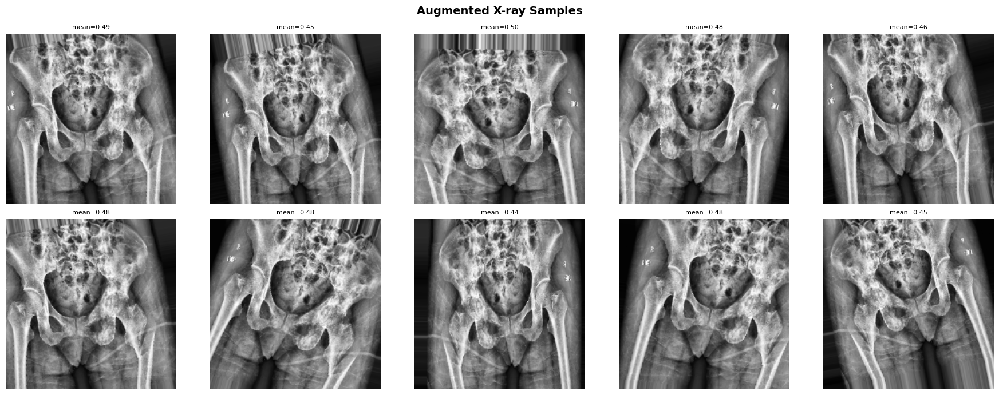

In [ ]:
# ── Data Augmentation — safe geometry-only transforms ───────────────────────
# brightness_range REMOVED: ImageDataGenerator uses PIL internally for it,
# which converts [0,1] → [0,255] before processing, then returns [0,255].
# np.clip(aug, 0, 1) then makes 100% of pixels = 1.0 (all-white images).
# For black input images it produces all-black output.
# Solution: geometry-only augmentation. Manual brightness in the generator.
aug_gen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.08,
    height_shift_range=0.08,
    shear_range=0.08,
    zoom_range=0.10,
    horizontal_flip=True,
    vertical_flip=False,
    fill_mode='nearest'
    # NO brightness_range  — broken for float [0,1] images via PIL
    # NO channel_shift_range — saturates float images to 0 or 1
)

# ── Verify augmented training images are non-black ─────────────────────────
# Preview uses X_train only for clean methodology wording. This is not a
# training operation, but avoids sampling validation/test images for examples.
print("Checking training preprocessing output...")
preview_img = None
for img in X_train:
    if img.mean() > 0.05:
        preview_img = img
        break

if preview_img is None:
    print("  WARNING: ALL training images still have mean ≤ 0.05.")
    print("   Preprocessing did not produce visible training images.")
    print("   Check image file paths and formats.")
    preview_img = X_train[0] if len(X_train) > 0 else None
else:
    # Test aug_gen.random_transform (geometry only — the correct augmentation method)
    n_black = sum(
        1 for _ in range(10)
        if np.clip(aug_gen.random_transform(preview_img), 0, 1).mean() < 0.01
    )
    print(f"  Source image mean   : {preview_img.mean():.4f}")
    print(f"  Black augmented (10): {n_black}/10  (should be 0)")

if preview_img is not None:
    fig, axes = plt.subplots(2, 5, figsize=(18, 7))
    fig.suptitle('Augmented X-ray Samples', fontsize=14, fontweight='bold')
    for ax in axes.flatten():
        aug_img = np.clip(aug_gen.random_transform(preview_img), 0.0, 1.0)
        ax.imshow(aug_img, cmap='bone')
        ax.set_title(f'mean={aug_img.mean():.2f}', fontsize=8)
        ax.axis('off')
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'augmentation_samples.png'), dpi=150)
    plt.show()


We compute loss weights for each class to penalize majority classes less and prioritize minority ones.


In [ ]:
print("Class distribution before balancing:")
unique, counts = np.unique(y_binary, return_counts=True)
print(dict(zip(unique, counts)))


class_weights_binary = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_binary),
    y=y_binary
)
class_weight_dict_binary = dict(enumerate(class_weights_binary))

# Compute class weights on TRAIN split only (not the full dataset)
# y_train_osteo only — prevents test-set leakage into class weight calculation
class_weights_osteo = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train_osteo),
    y=y_train_osteo
)
class_weights_osteo = np.clip(class_weights_osteo, a_min=None, a_max=10.0)
class_weight_dict_osteo = dict(enumerate(class_weights_osteo))

print("Binary class weights:",       class_weight_dict_binary)
print("Osteosarcoma class weights:", class_weight_dict_osteo)

n_pos_train = (y_train_osteo == 1).sum()
n_neg_train = (y_train_osteo == 0).sum()
imbalance_ratio = n_neg_train / max(n_pos_train, 1)
print(f"\nTrain imbalance: {n_neg_train} negative / {n_pos_train} positive "
      f"(ratio {imbalance_ratio:.1f}:1)")

# ════════════════════════════════════════════════════════════════════════
# BALANCED BATCH GENERATOR
# ════════════════════════════════════════════════════════════════════════
def balanced_batch_generator(X, y, aug_gen, batch_size=32, seed=42):
    """
    Yields balanced batches for binary classification using the actual labels
    found in y. The minority class is oversampled with replacement.

    For the osteosarcoma task this remains equivalent to the old behavior
    because class 1 is the minority class, but the generator no longer assumes
    class 1 is always the minority.
    """
    y = np.asarray(y)
    classes, counts = np.unique(y.astype(int), return_counts=True)
    if len(classes) != 2:
        raise ValueError(f"balanced_batch_generator expects exactly 2 classes, found {classes}.")

    minority_class = classes[np.argmin(counts)]
    majority_class = classes[np.argmax(counts)]
    minority_idx = np.where(y == minority_class)[0]
    majority_idx = np.where(y == majority_class)[0]
    half = batch_size // 2
    rng = np.random.default_rng(seed)

    if len(minority_idx) == 0 or len(majority_idx) == 0:
        raise ValueError("Both binary classes must be present for balanced training batches.")

    print(
        f"  Balanced generator: class {minority_class}={len(minority_idx)} "
        f"(minority), class {majority_class}={len(majority_idx)}"
    )
    print(f"  Each batch: {half} minority + {half} majority = {2 * half}")

    # MixUp is applied only within the minority half when examples are scarce.
    # This keeps labels unambiguous and matches the previous osteosarcoma
    # behavior where minority class == 1.
    use_mixup = len(minority_idx) < 100
    alpha_mix = 0.4

    while True:
        chosen_minority = rng.choice(minority_idx, size=half, replace=True)
        chosen_majority = rng.choice(
            majority_idx, size=half, replace=(len(majority_idx) < half)
        )

        idx = rng.permutation(np.concatenate([chosen_minority, chosen_majority]))
        X_raw = X[idx]
        y_raw = y[idx].astype(np.float32)

        # Geometry augmentation is training-only and safe for [0,1] arrays.
        X_aug = np.array([
            aug_gen.random_transform(x.astype('float32')) for x in X_raw
        ])

        # Manual brightness jitter is training-only.
        brightness = rng.uniform(0.85, 1.15, size=(len(X_aug), 1, 1, 1))
        X_aug = X_aug * brightness

        if use_mixup:
            minority_mask = (y_raw == float(minority_class))
            minority_positions = np.where(minority_mask)[0]
            if len(minority_positions) >= 2:
                partner_idx = rng.choice(minority_positions, size=len(minority_positions))
                lam = rng.beta(alpha_mix, alpha_mix, size=len(minority_positions))
                lam = lam.reshape(-1, 1, 1, 1).astype(np.float32)
                X_aug[minority_positions] = (
                    lam * X_aug[minority_positions]
                    + (1 - lam) * X_aug[partner_idx]
                )
                y_raw[minority_positions] = (
                    lam.squeeze() * y_raw[minority_positions]
                    + (1 - lam.squeeze()) * y_raw[partner_idx]
                )

        X_aug = np.clip(X_aug, 0.0, 1.0).astype(np.float32)
        yield X_aug, y_raw


Class distribution before balancing:
{np.int64(0): np.int64(3404), np.int64(1): np.int64(342)}
Binary class weights: {0: np.float64(0.550235017626322), 1: np.float64(5.476608187134503)}
Osteosarcoma class weights: {0: np.float64(0.5437627811860941), 1: np.float64(6.212616822429907)}

Train imbalance: 2445 negative / 214 positive (ratio 11.4:1)


We perform a sanity guard check to verify that tabular and image features are aligned before running model training.


In [ ]:
# ════════════════════════════════════════════════════════════════════
# PREPROCESSING GUARD — Run this cell before training ANY model.
# Verifies that image, tabular, and text preprocessing are complete.
# If any array is missing, it will raise...
# ════════════════════════════════════════════════════════════════════
_required = {
    # Image arrays (shape: N x 224 x 224...
    "X_train":       X_train,       "X_val":        X_val,
    "X_test":        X_test,
    # Binary osteosarcoma labels (shape: N,)
    "y_train_osteo": y_train_osteo, "y_val_osteo":  y_val_osteo,
    "y_test_osteo":  y_test_osteo,
    # Normalized tabular/clinical features (shape: N x 8)
    "X_tab_train":   X_tab_train,   "X_tab_val":    X_tab_val,
    "X_tab_test":    X_tab_test,
    # Tokenized text sequences (shape: N x max_seq_len)
    "X_train_seq":   X_text_train,   "X_val_seq":    X_text_val,
    "X_test_seq":    X_text_test,
}
_all_ok = True
print("─" * 58)
print("  PREPROCESSING VERIFICATION")
print("─" * 58)
for _name, _arr in _required.items():
    try:
        print(f"    {_name:<18}  shape = {_arr.shape}")
    except Exception:
        print(f"    {_name:<18}  NOT FOUND")
        _all_ok = False
print("─" * 58)
if not _all_ok:
    raise RuntimeError(
        "\nPreprocessing incomplete.\n"
        "Run Sections 1 (Data Loading & EDA) and 2 (Preprocessing)\n"
        "before training any model."
    )
print("   ALL VERIFIED — Safe to train")
print(f"  Images  : {X_train.shape} | {X_val.shape} | {X_test.shape}")
print(f"  Tabular : {X_tab_train.shape} | {X_tab_val.shape} | {X_tab_test.shape}")
print(f"  Text    : {X_text_train.shape} | {X_text_val.shape} | {X_text_test.shape}")


──────────────────────────────────────────────────────────
  PREPROCESSING VERIFICATION
──────────────────────────────────────────────────────────
    X_train             shape = (2659, 224, 224, 3)
    X_val               shape = (618, 224, 224, 3)
    X_test              shape = (469, 224, 224, 3)
    y_train_osteo       shape = (2659,)
    y_val_osteo         shape = (618,)
    y_test_osteo        shape = (469,)
    X_tab_train         shape = (2659, 8)
    X_tab_val           shape = (618, 8)
    X_tab_test          shape = (469, 8)
    X_train_seq         shape = (2659, 6)
    X_val_seq           shape = (618, 6)
    X_test_seq          shape = (469, 6)
──────────────────────────────────────────────────────────
   ALL VERIFIED — Safe to train
  Images  : (2659, 224, 224, 3) | (618, 224, 224, 3) | (469, 224, 224, 3)
  Tabular : (2659, 8) | (618, 8) | (469, 8)
  Text    : (2659, 6) | (618, 6) | (469, 6)


We define standard helper utilities for model training checkpoints, early stopping, history plotting, and test metrics.


In [ ]:
def best_checkpoint_path(model_name):
    return os.path.join(OUTPUT_DIR, f'best_{model_name}.keras')

if 'all_results' not in globals() or not isinstance(all_results, list):
    all_results = []

def _best_model_load_kwargs():
    custom_objects = {}
    if 'FOCAL' in globals():
        custom_objects[FOCAL.__name__] = FOCAL
    return {'custom_objects': custom_objects} if custom_objects else {}

def restore_best_trained_model(model, model_name):
    ckpt_path = best_checkpoint_path(model_name)
    if not os.path.exists(ckpt_path):
        raise FileNotFoundError(f"Best checkpoint not found: {ckpt_path}")
    restored = run_tf_work(
        lambda: tf.keras.models.load_model(ckpt_path, **_best_model_load_kwargs()),
        description=f'load best checkpoint for {model_name}')
    print(f" Reloaded best checkpoint: {ckpt_path}")
    return restored

def get_callbacks(model_name, patience=18, lr_patience=6):
    """
    Unified training callbacks used by ALL models (single-input & multimodal).

    ▸ ModelCheckpoint  → val_pr_auc  — correct metric for imbalanced data.
      PR-AUC is only high when BOTH precision AND recall are simultaneously good.
      ROC-AUC stays falsely high even when the model predicts everything as negative.
    ▸ EarlyStopping    → val_pr_auc  (same reason).
    ▸ ReduceLROnPlateau→ val_loss    (smoother signal for LR adjustments).
    """
    ckpt_path = best_checkpoint_path(model_name)
    return [
        tf.keras.callbacks.ModelCheckpoint(
            ckpt_path, monitor='val_pr_auc', mode='max',
            save_best_only=True, verbose=1),
        tf.keras.callbacks.EarlyStopping(
            monitor='val_pr_auc', mode='max',
            patience=patience, restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.5, patience=lr_patience,
            min_lr=1e-8, mode='min', cooldown=3, verbose=1),
    ]

def plot_history(history, title):
    """Plot training curves safely even if some metrics are absent."""
    hist = getattr(history, 'history', {}) or {}
    if not hist:
        print(f" No history found for {title}.")
        return

    candidates = [
        ('loss', 'val_loss', 'Loss'),
        ('pr_auc', 'val_pr_auc', 'PR-AUC'),
        ('auc', 'val_auc', 'ROC-AUC'),
        ('accuracy', 'val_accuracy', 'Accuracy'),
    ]
    available = [(a, b, label) for a, b, label in candidates if a in hist or b in hist]
    if not available:
        print(f" No plottable metrics found for {title}.")
        return

    fig, axes = plt.subplots(1, len(available), figsize=(6 * len(available), 4))
    if len(available) == 1:
        axes = [axes]

    for ax, (train_key, val_key, label) in zip(axes, available):
        if train_key in hist:
            ax.plot(hist[train_key], label=f'Train {label}', linewidth=2)
        if val_key in hist:
            ax.plot(hist[val_key], label=f'Val {label}', linewidth=2)
        ax.set_title(label)
        ax.set_xlabel('Epoch')
        ax.grid(alpha=0.25)
        ax.legend()

    fig.suptitle(title, fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()

def _iter_layers_recursive(model):
    """Yield layers from a model, including nested submodels."""
    yield model
    for layer in getattr(model, 'layers', []):
        yield layer
        if isinstance(layer, tf.keras.Model):
            yield from _iter_layers_recursive(layer)

def find_last_conv_layer_name(model):
    """Return the last convolution-like layer object for Grad-CAM."""
    conv_types = (
        tf.keras.layers.Conv2D,
        tf.keras.layers.DepthwiseConv2D,
        tf.keras.layers.SeparableConv2D,
    )
    for layer in reversed(list(_iter_layers_recursive(model))):
        if isinstance(layer, conv_types):
            return layer
    raise ValueError(f"No convolutional layer found in model: {model.name}")

# Evaluation defaults: main reported metrics use no test-time augmentation.
# TTA is not training leakage, but it is...
# reported separately from the main no-augmentation test metrics.
USE_TTA = False
N_TTA = 8

def evaluate_model(model, X_test, y_test, model_name, X_val=None, y_val=None):
    """Evaluate a single-input image model with validation-only threshold tuning."""
    if globals().get('USE_TTA', False):
        print("  Evaluation mode: TTA enabled (report separately from main metrics).")
        tta_preds = [predict_model(
            model, X_test, batch_size=32, verbose=0,
            description=f'{model_name} test prediction').ravel()]

        for _ in range(globals().get('N_TTA', 8) - 1):
            X_tta = np.clip(
                np.array([aug_gen.random_transform(x) for x in X_test]),
                0.0, 1.0).astype(np.float32)
            tta_preds.append(predict_model(
                model, X_tta, batch_size=32, verbose=0,
                description=f'{model_name} TTA prediction').ravel())
        y_prob = np.mean(tta_preds, axis=0)
    else:
        print("  Evaluation mode: no TTA (main reported metrics).")
        y_prob = predict_model(
            model, X_test, batch_size=32, verbose=0,
            description=f'{model_name} test prediction').ravel()

    print(f"  Predicted probs — min:{y_prob.min():.3f}  max:{y_prob.max():.3f}"
          f"  mean:{y_prob.mean():.3f}  median:{np.median(y_prob):.3f}")
    if y_prob.max() - y_prob.min() < 0.05:
        print("    WARNING: probability range < 0.05 — model may not have learned.")

    if X_val is not None and y_val is not None:
        y_prob_val = predict_model(
            model, X_val, batch_size=32, verbose=0,
            description=f'{model_name} validation prediction').ravel()
        fpr_v, tpr_v, thr_v = roc_curve(y_val, y_prob_val)
        j_v = tpr_v - fpr_v
        best_thr = float(np.clip(thr_v[np.argmax(j_v)], 0.05, 0.95))
        thr_src = "validation set (no test leakage)"
    else:
        fpr_t, tpr_t, thr_t = roc_curve(y_test, y_prob)
        j_t = tpr_t - fpr_t
        best_thr = float(np.clip(thr_t[np.argmax(j_t)], 0.05, 0.95))
        thr_src = "test set (optimistic — debug only)"

    globals()['best_eval_threshold'] = best_thr
    print(f"  Threshold source : {thr_src}")
    print(f"  Optimal threshold: {best_thr:.4f}")

    y_pred = (y_prob >= best_thr).astype(int)
    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()
    sensitivity = tp / max(tp + fn, 1)
    specificity = tn / max(tn + fp, 1)
    ppv = tp / max(tp + fp, 1)
    npv = tn / max(tn + fn, 1)

    result = {
        'model': model_name,
        'accuracy': accuracy_score(y_test, y_pred),
        'balanced_acc': balanced_accuracy_score(y_test, y_pred),
        'precision': precision_score(y_test, y_pred, zero_division=0),
        'recall': recall_score(y_test, y_pred, zero_division=0),
        'specificity': specificity,
        'f1': f1_score(y_test, y_pred, zero_division=0),
        'macro_f1': f1_score(y_test, y_pred, average='macro', zero_division=0),
        'mcc': matthews_corrcoef(y_test, y_pred),
        'auc': roc_auc_score(y_test, y_prob),
        'pr_auc': average_precision_score(y_test, y_prob),
        'npv': npv,
        'sensitivity': sensitivity,
        'threshold': best_thr,
    }

    print(f"\n{model_name}")
    print(classification_report(y_test, y_pred, digits=4, zero_division=0))
    print("Confusion matrix:")
    print(cm)

    return result, y_prob

print(" Training helpers defined — callbacks, checkpoint restore, plotting, Grad-CAM lookup, and evaluation are ready.")


 Training helpers defined — callbacks, checkpoint restore, plotting, Grad-CAM lookup, and evaluation are ready.


# SECTION 2 - Binary Classification
Binary classification models, evaluation, and multimodal fusion comparisons.


## Subsection 2.1 - ROI Models (Image-Only)
Training and evaluation of image-only models on full-image and cropped ROI splits.


We define and compile a custom 4-block CNN architecture from scratch with spatial dropouts and channel attention.


In [ ]:
def squeeze_excite(x, ratio=8):
    """Lightweight channel attention (SE block)."""
    filters = x.shape[-1]
    se = layers.GlobalAveragePooling2D()(x)
    se = layers.Dense(max(filters // ratio, 4), activation='relu')(se)
    se = layers.Dense(filters, activation='sigmoid')(se)
    se = layers.Reshape((1, 1, filters))(se)
    return layers.Multiply()([x, se])

def build_custom_cnn(input_shape=(224, 224, 3)):
    """
    Redesigned Custom CNN:
    - 4 conv blocks (not 5) to reduce over-parameterisation
    - SE channel attention after each block
    - SpatialDropout2D instead of Dropout in conv blocks (more effective)
    - BatchNorm before activation (pre-activation style)
    - Smaller dense head to reduce over-fitting
    """
    inputs = layers.Input(shape=input_shape, name='img_input')
    x = inputs

    # Block 1 — 32 filters
    x = layers.Conv2D(32, (3,3), padding='same',
                       kernel_regularizer=regularizers.l2(1e-4),
                       kernel_initializer='he_normal')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(32, (3,3), padding='same',
                       kernel_regularizer=regularizers.l2(1e-4),
                       kernel_initializer='he_normal')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = squeeze_excite(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.SpatialDropout2D(0.1)(x)

    # Block 2 — 64 filters
    x = layers.Conv2D(64, (3,3), padding='same',
                       kernel_regularizer=regularizers.l2(1e-4),
                       kernel_initializer='he_normal')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(64, (3,3), padding='same',
                       kernel_regularizer=regularizers.l2(1e-4),
                       kernel_initializer='he_normal')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = squeeze_excite(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.SpatialDropout2D(0.15)(x)

    # Block 3 — 128 filters
    x = layers.Conv2D(128, (3,3), padding='same',
                        kernel_regularizer=regularizers.l2(1e-4),
                        kernel_initializer='he_normal')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(128, (3,3), padding='same',
                        kernel_regularizer=regularizers.l2(1e-4),
                        kernel_initializer='he_normal')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = squeeze_excite(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.SpatialDropout2D(0.2)(x)

    # Block 4 — 256 filters
    x = layers.Conv2D(256, (3,3), padding='same',
                        kernel_regularizer=regularizers.l2(1e-4),
                        kernel_initializer='he_normal')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = squeeze_excite(x)
    x = layers.GlobalAveragePooling2D()(x)

    # Classifier head — lighter to reduce overfitting
    x = layers.Dense(128, activation='relu',
                      kernel_regularizer=regularizers.l2(1e-4),
                      kernel_initializer='he_normal')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(1, activation='sigmoid', name='output')(x)

    model = models.Model(inputs, outputs, name='CustomCNN')
    return model

def _metrics():
    return [
        tf.keras.metrics.BinaryAccuracy(name='accuracy'),
        tf.keras.metrics.AUC(name='auc'),
        tf.keras.metrics.AUC(name='pr_auc', curve='PR'), # Precision-Recall AUC
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall')
    ]

def compile_scratch_model(model, lr=1e-4):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss='binary_crossentropy', # Assuming binary classification for sigmoid output
        metrics=_metrics()
    )
    return model

model1 = build_custom_cnn()
model1 = compile_scratch_model(model1, lr=1e-4)
model1.summary()


Model: "CustomCNN"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ img_input           │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 224, 224,  │        896 │ img_input[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 224, 224,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 224, 224,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 224, 224,  │      9,248 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 224, 224,  │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 224, 224,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 32)        │          0 │ activation_1[0][… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 4)         │        132 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32)        │        160 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 1, 1, 32)  │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 224, 224,  │          0 │ activation_1[0][… │
│                     │ 32)               │            │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 112, 112,  │          0 │ multiply[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout2d   │ (None, 112, 112,  │          0 │ max_pooling2d[0]… │
│ (SpatialDropout2D)  │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 112, 112,  │     18,496 │ spatial_dropout2… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 112, 112,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 112, 112,  │     36,928 │ activation_2[0][

 Total params: 640,829 (2.44 MB)

 Trainable params: 639,165 (2.44 MB)

 Non-trainable params: 1,664 (6.50 KB)

We define and compile a custom ResNet model from scratch containing skip connections and squeeze-and-excitation blocks.


In [ ]:
def residual_block(x, filters, stride=1, dropout_rate=0.0):
    """Residual block with SE-attention, proper initialisation, optional spatial dropout."""
    shortcut = x
    x = layers.Conv2D(filters, (3,3), strides=stride, padding='same',
                       kernel_regularizer=regularizers.l2(1e-4),
                       kernel_initializer='he_normal', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(filters, (3,3), padding='same',
                       kernel_regularizer=regularizers.l2(1e-4),
                       kernel_initializer='he_normal', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = squeeze_excite(x, ratio=8)
    if stride != 1 or shortcut.shape[-1] != filters:
        shortcut = layers.Conv2D(filters, (1,1), strides=stride, padding='same',
                                  use_bias=False)(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)
    x = layers.Add()([x, shortcut])
    x = layers.Activation('relu')(x)
    if dropout_rate > 0:
        x = layers.SpatialDropout2D(dropout_rate)(x)
    return x

def build_custom_resnet(input_shape=(224, 224, 3)):
    """
    Custom ResNet with SE attention — trained from scratch.
    3 stages (64→128→128) — kept smaller to avoid over-parameterisation
    on a small medical dataset.
    """
    inputs = layers.Input(shape=input_shape, name='img_input')
    # Stem
    x = layers.Conv2D(64, (7,7), strides=2, padding='same',
                       kernel_regularizer=regularizers.l2(1e-4),
                       kernel_initializer='he_normal', use_bias=False)(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D((3,3), strides=2, padding='same')(x)

    # Stage 1 — 64 filters
    x = residual_block(x, 64, dropout_rate=0.10)
    x = residual_block(x, 64, dropout_rate=0.10)

    # Stage 2 — 128 filters
    x = residual_block(x, 128, stride=2, dropout_rate=0.15)
    x = residual_block(x, 128, dropout_rate=0.15)

    # Stage 3 — 128 filters (NOT 256 — prevents over-parameterisation)
    x = residual_block(x, 128, stride=2, dropout_rate=0.20)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation='relu',
                      kernel_regularizer=regularizers.l2(1e-4),
                      kernel_initializer='he_normal')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(1, activation='sigmoid', name='output')(x)

    model = models.Model(inputs, outputs, name='CustomResNet')
    return model

model2 = build_custom_resnet()
model2 = compile_scratch_model(model2, lr=7e-5)  # slightly higher than EfficientNet head, lower than CNN
model2.summary()


Model: "CustomResNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ img_input           │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 112, 112,  │      9,408 │ img_input[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        256 │ conv2d_7[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_7        │ (None, 112, 112,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 56, 56,    │          0 │ activation_7[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 56, 56,    │     36,864 │ max_pooling2d_3[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv2d_8[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_8        │ (None, 56, 56,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 56, 56,    │     36,864 │ activation_8[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv2d_9[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ batch_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 8)         │        520 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 64)        │        576 │ dense_9[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_4 (Reshape) │ (None, 1, 1, 64)  │          0 │ dense_10[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_4          │ (None, 56, 56,    │          0 │ batch_normalizat… │
│ (Multiply)          │ 64)               │            │ reshape_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 56, 56,    │          0 │ multiply_4[0][0], │
│                     │ 64)               │            │ max_pooling2d_3[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_9        │ (None, 56, 56,    │          0 │ add[0][0]         │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout2d_3 │ (None, 56, 56,    │          0 │ activation_9[0][

 Total params: 1,029,889 (3.93 MB)

 Trainable params: 1,026,945 (3.92 MB)

 Non-trainable params: 2,944 (11.50 KB)

We set up an EfficientNetB0 transfer learning model, freezing the base layers for stage 1 training.


In [ ]:
def squeeze_excite(x, ratio=8):
    """Lightweight channel attention (SE block)."""
    filters = x.shape[-1]
    se = layers.GlobalAveragePooling2D()(x)
    se = layers.Dense(max(filters // ratio, 4), activation='relu')(se)
    se = layers.Dense(filters, activation='sigmoid')(se)
    se = layers.Reshape((1, 1, filters))(se)
    return layers.Multiply()([x, se])

def build_efficientnet_transfer(input_shape=(224, 224, 3)):
    """
    EfficientNetB0 pretrained on ImageNet.

    Input rescaling: our pipeline outputs [0,1] but EfficientNetB0 expects
    [0,255]. The Rescaling(255) layer inside the model handles this for
    BOTH training and inference, ensuring no train/val mismatch.

    Phase 1: Freeze entire base → train head only (LR=5e-5)
    Phase 2: Unfreeze top 20 layers → fine-tune (LR=1e-5)
    """
    base = EfficientNetB0(
        weights='imagenet',
        include_top=False,
        input_shape=input_shape
    )
    base.trainable = False   # Phase 1: completely frozen

    inputs = layers.Input(shape=input_shape, name='img_input')
    # Rescale [0,1] → [0,255] inside the model (applied...
    x = layers.Rescaling(scale=255.0, name='rescale_for_efficientnet')(inputs)
    # Do NOT hardcode training=False here.
    # model.fit() will automatically pass training=True during training,
    # which lets unfrozen BN layers in Phase-2 use batch statistics.
    # Frozen layers (trainable=False) already ignore gradient updates;
    # Keras also prevents their BN moving averages from updating.
    x = base(x)
    x = layers.GlobalAveragePooling2D()(x)

    # ── Classification head ─────────────────────────
    x = layers.Dense(128, kernel_regularizer=regularizers.l2(1e-4),
                      kernel_initializer='he_normal')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(1, activation='sigmoid', name='output')(x)

    model = models.Model(inputs, outputs, name='EfficientNetB0_Transfer')
    return model, base

def _metrics():
    return [
        tf.keras.metrics.BinaryAccuracy(name='accuracy'),
        tf.keras.metrics.AUC(name='auc'),
        tf.keras.metrics.AUC(name='pr_auc', curve='PR'), # Precision-Recall AUC
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall')
    ]

def compile_transfer_head(model, lr=5e-5):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss='binary_crossentropy', # Assuming binary classification for sigmoid output
        metrics=_metrics()
    )
    return model

model3, base3 = build_efficientnet_transfer()
compile_transfer_head(model3, lr=5e-5)
model3.summary()


Model: "EfficientNetB0_Transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ img_input (InputLayer)          │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescale_for_efficientnet        │ (None, 224, 224, 3)    │             0 │
│ (Rescaling)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_12     │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_22          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_18 (Activation)      │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,214,180 (16.08 MB)

 Trainable params: 164,353 (642.00 KB)

 Non-trainable params: 4,049,827 (15.45 MB)

We extract ROI-cropped image arrays using the ground truth coordinates from LabelMe annotations.


In [ ]:
# crop ROI arrays


ANNOTATION_DIR = PROJECT_ROOT / 'Annotations' / 'Annotations'
ROI_PADDING_RATIO = 0.15
ROI_MIN_SIDE_PX = 16

if not ANNOTATION_DIR.is_dir():
    raise FileNotFoundError(f"Annotation folder not found: {ANNOTATION_DIR}")

annotation_files = sorted(ANNOTATION_DIR.glob('*.json'))
annotation_ids = {p.stem for p in annotation_files}
print(f"Annotation JSON files found : {len(annotation_files)}")
print(f"Annotations matching df_valid: {df_valid['image_id'].isin(annotation_ids).sum()} / {len(df_valid)}")

def _clip_int(v, lo, hi):
    return int(max(lo, min(hi, round(float(v)))))

def labelme_union_bbox(annotation_path, image_width, image_height, padding_ratio=ROI_PADDING_RATIO):
    """
    Parse a LabelMe JSON file and return a padded union bbox:
    (x1, y1, x2, y2), or None if no usable shapes exist.
    """
    try:
        data = json.loads(Path(annotation_path).read_text(encoding='utf-8'))
    except Exception:
        return None

    xs, ys = [], []
    for shape in data.get('shapes', []):
        pts = shape.get('points') or []
        for pt in pts:
            if len(pt) >= 2:
                x, y = pt[0], pt[1]
                if np.isfinite(x) and np.isfinite(y):
                    xs.append(float(x))
                    ys.append(float(y))

    if not xs or not ys:
        return None

    x1, x2 = min(xs), max(xs)
    y1, y2 = min(ys), max(ys)
    w, h = x2 - x1, y2 - y1
    if w < ROI_MIN_SIDE_PX or h < ROI_MIN_SIDE_PX:
        return None

    pad = padding_ratio * max(w, h)
    x1 = _clip_int(x1 - pad, 0, image_width - 1)
    y1 = _clip_int(y1 - pad, 0, image_height - 1)
    x2 = _clip_int(x2 + pad, 1, image_width)
    y2 = _clip_int(y2 + pad, 1, image_height)

    if x2 <= x1 or y2 <= y1 or (x2 - x1) < ROI_MIN_SIDE_PX or (y2 - y1) < ROI_MIN_SIDE_PX:
        return None
    return (x1, y1, x2, y2)

def preprocess_uint8_image(img_uint8):
    """Use the notebook CLAHE preprocessing when available, else normalize."""
    if 'apply_clahe_and_normalize' in globals():
        out = apply_clahe_and_normalize(img_uint8)
        if out is not None:
            return out.astype(np.float32)
    return img_uint8.astype(np.float32) / 255.0

def preprocess_roi_image(image_path, image_id, return_debug=False):
    """
    Load image, crop annotated ROI if available, resize to IMG_SIZE, then preprocess.
    Falls back to full-image preprocessing if annotation is missing/invalid.
    """
    debug = {'image_id': image_id, 'used_roi': False, 'bbox': None, 'reason': None}
    try:
        pil_img = PILImage.open(image_path).convert('RGB')
    except Exception as exc:
        debug['reason'] = f'image_load_error: {exc}'
        if return_debug:
            return None, debug
        return None

    width, height = pil_img.size
    ann_path = ANNOTATION_DIR / f'{image_id}.json'
    bbox = None
    if ann_path.exists():
        bbox = labelme_union_bbox(ann_path, width, height, ROI_PADDING_RATIO)

    if bbox is not None:
        crop = pil_img.crop(bbox)
        debug.update({'used_roi': True, 'bbox': bbox, 'reason': 'annotation_crop'})
    else:
        crop = pil_img
        debug['reason'] = 'full_image_fallback'

    crop = crop.resize(IMG_SIZE, PILImage.Resampling.LANCZOS)
    img_uint8 = np.array(crop, dtype=np.uint8)
    out = preprocess_uint8_image(img_uint8)
    if return_debug:
        return out, debug
    return out

X_roi_images = []
roi_debug_rows = []

for _, row in tqdm(df_valid.iterrows(), total=len(df_valid), desc='Building ROI images'):
    image_id = str(row['image_id'])
    img_path = IMG_DIR / row['image_filename'] if isinstance(IMG_DIR, Path) else Path(IMG_DIR) / row['image_filename']
    roi_img, dbg = preprocess_roi_image(img_path, image_id, return_debug=True)
    if roi_img is None:
        # Last-resort fallback to the already-loaded full image for this df_valid row.
        roi_img = X_images[len(X_roi_images)].astype(np.float32)
        dbg['reason'] = dbg.get('reason') or 'fallback_existing_full_image'
    X_roi_images.append(roi_img.astype(np.float16))
    roi_debug_rows.append(dbg)

X_roi_images = np.asarray(X_roi_images, dtype=np.float16)
roi_debug_df = pd.DataFrame(roi_debug_rows)
roi_pos_by_id = {
    str(image_id): pos
    for pos, image_id in enumerate(df_valid['image_id'].astype(str).tolist())
}

X_roi_train = X_roi_images[train_idx]
X_roi_val   = X_roi_images[val_idx]
X_roi_test  = X_roi_images[test_idx]

# Secondary stratified split: 70/10/20 for more stable precision estimates.
roi_all_idx = np.arange(len(X_roi_images))
roi_train_idx, roi_test_idx = train_test_split(
    roi_all_idx, test_size=0.20, random_state=42, stratify=y_osteo
)
roi_train_idx, roi_val_idx = train_test_split(
    roi_train_idx, test_size=0.125, random_state=42, stratify=y_osteo[roi_train_idx]
)

X_roi_strat_train = X_roi_images[roi_train_idx]
X_roi_strat_val   = X_roi_images[roi_val_idx]
X_roi_strat_test  = X_roi_images[roi_test_idx]
y_roi_strat_train = y_osteo[roi_train_idx]
y_roi_strat_val   = y_osteo[roi_val_idx]
y_roi_strat_test  = y_osteo[roi_test_idx]

print("\n" + "=" * 64)
print("ROI DATASET SUMMARY")
print("=" * 64)
print(f"X_roi_images      : {X_roi_images.shape} dtype={X_roi_images.dtype}")
print(f"ROI crops used    : {int(roi_debug_df['used_roi'].sum())}")
print(f"Full-image fallback: {int((~roi_debug_df['used_roi']).sum())}")
print(f"Original split    : train={len(X_roi_train)}, val={len(X_roi_val)}, test={len(X_roi_test)}")
print(f"Original test pos : {int(y_test_osteo.sum())} / {len(y_test_osteo)}")
print(f"Stratified split  : train={len(X_roi_strat_train)}, val={len(X_roi_strat_val)}, test={len(X_roi_strat_test)}")
print(f"Stratified test pos: {int(y_roi_strat_test.sum())} / {len(y_roi_strat_test)}")
print("=" * 64)


Annotation JSON files found : 1867
Annotations matching df_valid: 1867 / 3746


Building ROI images: 100%|██████████| 3746/3746 [01:12<00:00, 51.40it/s] 



ROI DATASET SUMMARY
X_roi_images      : (3746, 224, 224, 3) dtype=float16
ROI crops used    : 1863
Full-image fallback: 1883
Original split    : train=2659, val=618, test=469
Original test pos : 30 / 469
Stratified split  : train=2621, val=375, test=750
Stratified test pos: 59 / 750


We plot sample cropped ROI images to verify the segmentation coordinates are correct.


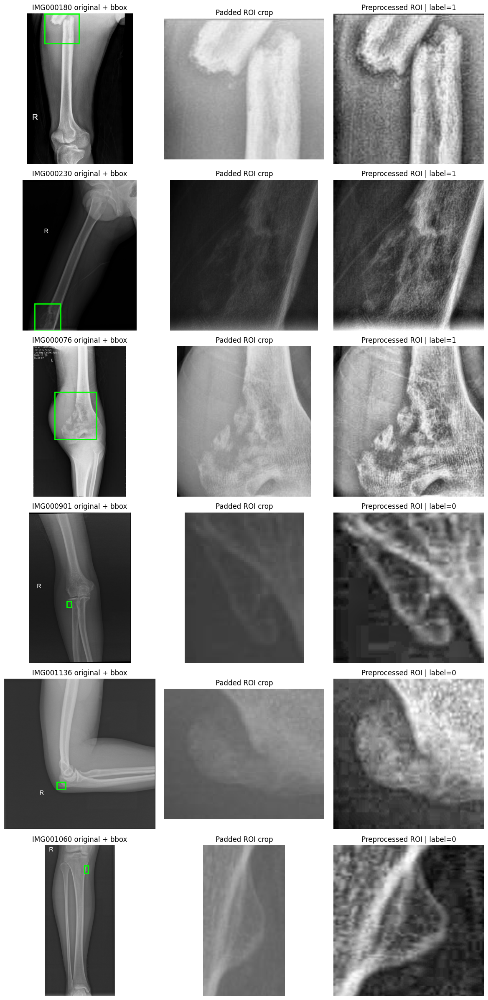

In [ ]:
# plot sample ROI crops

sample_pool = roi_debug_df[roi_debug_df['used_roi']].copy()
if len(sample_pool) == 0:
    print("No ROI annotations available for preview.")
else:
    pos_ids = set(df_valid.loc[y_osteo == 1, 'image_id'].astype(str))
    pos_pool = sample_pool[sample_pool['image_id'].isin(pos_ids)]
    neg_pool = sample_pool[~sample_pool['image_id'].isin(pos_ids)]
    preview = pd.concat([
        pos_pool.sample(min(3, len(pos_pool)), random_state=42),
        neg_pool.sample(min(3, len(neg_pool)), random_state=43),
    ]).head(6)

    fig, axes = plt.subplots(len(preview), 3, figsize=(12, 4 * len(preview)), squeeze=False)
    for r, (_, dbg) in enumerate(preview.iterrows()):
        image_id = dbg['image_id']
        row = df_valid[df_valid['image_id'].astype(str) == image_id].iloc[0]
        image_path = Path(IMG_DIR) / row['image_filename']
        raw = PILImage.open(image_path).convert('RGB')
        bbox = dbg['bbox']
        crop = raw.crop(tuple(bbox)) if bbox else raw
        roi_img = X_roi_images[roi_pos_by_id[image_id]]

        axes[r, 0].imshow(raw)
        if bbox:
            x1, y1, x2, y2 = bbox
            axes[r, 0].add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                                    linewidth=2, edgecolor='lime', facecolor='none'))
        axes[r, 0].set_title(f"{image_id} original + bbox")
        axes[r, 0].axis('off')

        axes[r, 1].imshow(crop)
        axes[r, 1].set_title("Padded ROI crop")
        axes[r, 1].axis('off')

        axes[r, 2].imshow(roi_img.astype(np.float32), cmap='bone')
        axes[r, 2].set_title(f"Preprocessed ROI | label={int(row['is_osteo'])}")
        axes[r, 2].axis('off')

    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'roi_crop_sanity_check.png'), dpi=150)
    plt.show()


We train our custom CNN and ResNet models from scratch using the ROI cropped images.


ROI original split steps per epoch: 152
  Balanced generator: 214 positives, 2445 negatives
  Each batch: 16 pos (oversampled) + 16 neg = 32
Epoch 1/50
152/152 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - accuracy: 0.6729 - auc: 0.7352 - loss: 0.8350 - pr_auc: 0.7156 - precision: 0.6704 - recall: 0.6787
Epoch 1: val_pr_auc improved from None to 0.23900, saving model to /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_CustomCNN.keras
152/152 ━━━━━━━━━━━━━━━━━━━━ 31s 163ms/step - accuracy: 0.7190 - auc: 0.7918 - loss: 0.7607 - pr_auc: 0.7605 - precision: 0.7116 - recall: 0.7364 - val_accuracy: 0.8754 - val_auc: 0.8236 - val_loss: 0.7290 - val_pr_auc: 0.2390 - val_precision: 0.2500 - val_recall: 0.2264 - learning_rate: 8.0000e-05
Epoch 2/50
152/152 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step - accuracy: 0.7651 - auc: 0.8321 - loss: 0.6902 - pr_auc: 0.7926 - precision: 0.7431 - recall: 0.8108
Epoch 2: val_pr_auc improved from 0.23900 to 0.27116, saving model to /media/hazem/6A47B344CD80864E/JANA/GP/o

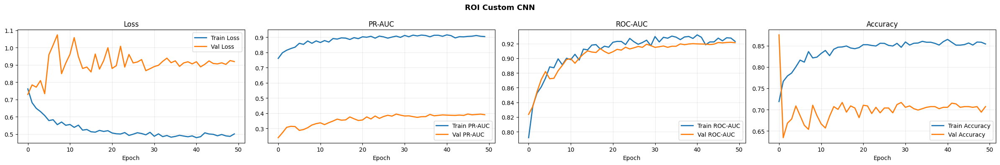

 Reloaded best checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_CustomCNN.keras
ROI Custom CNN training complete.
  Balanced generator: 214 positives, 2445 negatives
  Each batch: 16 pos (oversampled) + 16 neg = 32
Epoch 1/50
152/152 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step - accuracy: 0.6459 - auc: 0.7050 - loss: 0.9462 - pr_auc: 0.6786 - precision: 0.6460 - recall: 0.6407
Epoch 1: val_pr_auc improved from None to 0.23813, saving model to /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_CustomResNet.keras
152/152 ━━━━━━━━━━━━━━━━━━━━ 36s 179ms/step - accuracy: 0.6928 - auc: 0.7651 - loss: 0.8744 - pr_auc: 0.7341 - precision: 0.6863 - recall: 0.7105 - val_accuracy: 0.6731 - val_auc: 0.8033 - val_loss: 0.7984 - val_pr_auc: 0.2381 - val_precision: 0.1803 - val_recall: 0.7925 - learning_rate: 7.0000e-05
Epoch 2/50
152/152 ━━━━━━━━━━━━━━━━━━━━ 0s 151ms/step - accuracy: 0.7546 - auc: 0.8273 - loss: 0.7889 - pr_auc: 0.8021 - precision: 0.7377 - recall: 0.7902
Epoch 2: val_p

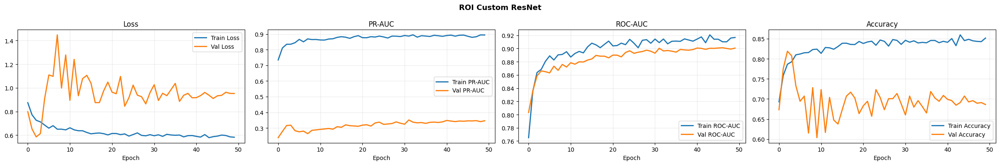

 Reloaded best checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_CustomResNet.keras
ROI Custom ResNet training complete.


: 

In [ ]:
# CELL 5A-3: Train ROI Custom CNN and ROI...
roi_results = []

n_pos_roi = int((y_train_osteo == 1).sum())
n_neg_roi = int((y_train_osteo == 0).sum())
STEPS_ROI = max(n_neg_roi // (BATCH_SIZE // 2), 10)
print(f"ROI original split steps per epoch: {STEPS_ROI}")

gen_roi_cnn = balanced_batch_generator(
    X_roi_train, y_train_osteo, aug_gen,
    batch_size=BATCH_SIZE, seed=142
)

roi_model_cnn = build_custom_cnn()
roi_model_cnn = compile_scratch_model(roi_model_cnn, lr=8e-5)

hist_roi_cnn = fit_model(
    roi_model_cnn,
    gen_roi_cnn,
    steps_per_epoch=STEPS_ROI,
    epochs=EPOCHS_SCRATCH,
    validation_data=(X_roi_val, y_val_osteo),
    callbacks=get_callbacks('ROI_CustomCNN', patience=18, lr_patience=6),
    verbose=1
)
plot_history(hist_roi_cnn, 'ROI Custom CNN')
roi_model_cnn = restore_best_trained_model(roi_model_cnn, 'ROI_CustomCNN')
print("ROI Custom CNN training complete.")

gen_roi_res = balanced_batch_generator(
    X_roi_train, y_train_osteo, aug_gen,
    batch_size=BATCH_SIZE, seed=143
)

roi_model_res = build_custom_resnet()
roi_model_res = compile_scratch_model(roi_model_res, lr=7e-5)

hist_roi_res = fit_model(
    roi_model_res,
    gen_roi_res,
    steps_per_epoch=STEPS_ROI,
    epochs=EPOCHS_SCRATCH,
    validation_data=(X_roi_val, y_val_osteo),
    callbacks=get_callbacks('ROI_CustomResNet', patience=18, lr_patience=6),
    verbose=1
)
plot_history(hist_roi_res, 'ROI Custom ResNet')
roi_model_res = restore_best_trained_model(roi_model_res, 'ROI_CustomResNet')
print("ROI Custom ResNet training complete.")


We perform transfer learning and fine-tuning on EfficientNetB0 using the ROI cropped images.


ROI original split steps per epoch: 152
  Balanced generator: 214 positives, 2445 negatives
  Each batch: 16 pos (oversampled) + 16 neg = 32
Epoch 1/20


I0000 00:00:1779921324.661970   41360 service.cc:152] XLA service 0x7e9e70002fe0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1779921324.661990   41360 service.cc:160]   StreamExecutor device (0): NVIDIA GeForce RTX 4070 Laptop GPU, Compute Capability 8.9
2026-05-28 01:35:24.832545: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1779921325.669237   41360 cuda_dnn.cc:529] Loaded cuDNN version 90300
2026-05-28 01:35:26.688556: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_11329', 32 bytes spill stores, 32 bytes spill loads

2026-05-28 01:35:26.810678: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusi

  1/152 ━━━━━━━━━━━━━━━━━━━━ 32:16 13s/step - accuracy: 0.4375 - auc: 0.4785 - loss: 0.9089 - pr_auc: 0.5308 - precision: 0.4500 - recall: 0.5625

I0000 00:00:1779921334.202251   41360 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


152/152 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step - accuracy: 0.6628 - auc: 0.7016 - loss: 0.6636 - pr_auc: 0.6565 - precision: 0.6343 - recall: 0.7716

2026-05-28 01:35:59.856920: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2142', 12 bytes spill stores, 12 bytes spill loads

2026-05-28 01:35:59.971737: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2142_0', 176 bytes spill stores, 524 bytes spill loads

2026-05-28 01:36:00.022616: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2142', 104 bytes spill stores, 104 bytes spill loads

2026-05-28 01:36:00.244143: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2142', 5144 bytes spill stores, 5204 bytes spill loads

2026-05-28 01:36:00.300394: I 


Epoch 1: val_pr_auc improved from None to 0.56035, saving model to /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_EfficientNetB0_P1.keras
152/152 ━━━━━━━━━━━━━━━━━━━━ 43s 197ms/step - accuracy: 0.7463 - auc: 0.8165 - loss: 0.5473 - pr_auc: 0.7779 - precision: 0.7051 - recall: 0.8466 - val_accuracy: 0.6618 - val_auc: 0.9370 - val_loss: 0.6271 - val_pr_auc: 0.5604 - val_precision: 0.2023 - val_recall: 1.0000 - learning_rate: 5.0000e-05
Epoch 2/20
152/152 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step - accuracy: 0.8547 - auc: 0.9246 - loss: 0.3800 - pr_auc: 0.9028 - precision: 0.8051 - recall: 0.9361
Epoch 2: val_pr_auc improved from 0.56035 to 0.68678, saving model to /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_EfficientNetB0_P1.keras
152/152 ━━━━━━━━━━━━━━━━━━━━ 22s 143ms/step - accuracy: 0.8534 - auc: 0.9273 - loss: 0.3719 - pr_auc: 0.9084 - precision: 0.8077 - recall: 0.9276 - val_accuracy: 0.7718 - val_auc: 0.9612 - val_loss: 0.4864 - val_pr_auc: 0.6868 - val_precision: 0.27

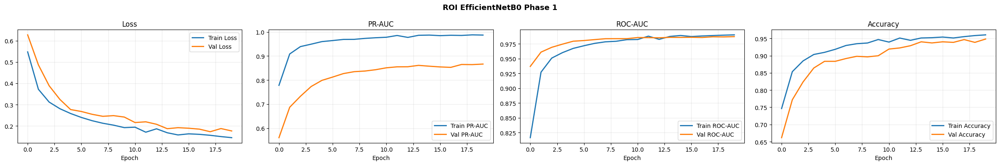

Best ROI EfficientNet Phase 1 checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_EfficientNetB0_P1.keras
  Balanced generator: 214 positives, 2445 negatives
  Each batch: 16 pos (oversampled) + 16 neg = 32
Epoch 1/40
152/152 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step - accuracy: 0.8882 - auc: 0.9626 - loss: 0.2843 - pr_auc: 0.9588 - precision: 0.9142 - recall: 0.8570
Epoch 1: val_pr_auc improved from None to 0.80109, saving model to /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_EfficientNetB0_P2.keras
152/152 ━━━━━━━━━━━━━━━━━━━━ 39s 182ms/step - accuracy: 0.9087 - auc: 0.9695 - loss: 0.2555 - pr_auc: 0.9640 - precision: 0.9180 - recall: 0.8976 - val_accuracy: 0.9110 - val_auc: 0.9815 - val_loss: 0.2481 - val_pr_auc: 0.8011 - val_precision: 0.4907 - val_recall: 1.0000 - learning_rate: 1.0000e-05
Epoch 2/40
152/152 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step - accuracy: 0.9326 - auc: 0.9796 - loss: 0.2096 - pr_auc: 0.9753 - precision: 0.9248 - recall: 0.9419
Epoch 2: val_pr_auc 

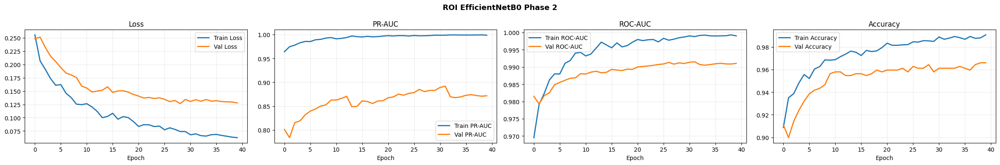

 Reloaded best checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_EfficientNetB0_P2.keras
ROI EfficientNetB0 training complete.


In [ ]:
# CELL 5A-4: Train ROI EfficientNetB0 on original Dataset 1 split
gen_roi_eff = balanced_batch_generator(
    X_roi_train, y_train_osteo, aug_gen,
    batch_size=BATCH_SIZE, seed=144
)

roi_model_eff, roi_eff_base = build_efficientnet_transfer()
roi_model_eff = compile_transfer_head(roi_model_eff, lr=5e-5)

hist_roi_eff_p1 = fit_model(
    roi_model_eff,
    gen_roi_eff,
    steps_per_epoch=STEPS_ROI,
    epochs=20,
    validation_data=(X_roi_val, y_val_osteo),
    callbacks=get_callbacks('ROI_EfficientNetB0_P1', patience=12, lr_patience=4),
    verbose=1
)
plot_history(hist_roi_eff_p1, 'ROI EfficientNetB0 Phase 1')
print(f"Best ROI EfficientNet Phase 1 checkpoint: {best_checkpoint_path('ROI_EfficientNetB0_P1')}")

roi_eff_base.trainable = True
for layer in roi_eff_base.layers[:-20]:
    layer.trainable = False
roi_model_eff = compile_transfer_head(roi_model_eff, lr=1e-5)

gen_roi_eff_p2 = balanced_batch_generator(
    X_roi_train, y_train_osteo, aug_gen,
    batch_size=BATCH_SIZE, seed=145
)

hist_roi_eff_p2 = fit_model(
    roi_model_eff,
    gen_roi_eff_p2,
    steps_per_epoch=STEPS_ROI,
    epochs=EPOCHS_FINETUNE,
    validation_data=(X_roi_val, y_val_osteo),
    callbacks=get_callbacks('ROI_EfficientNetB0_P2', patience=12, lr_patience=5),
    verbose=1
)
plot_history(hist_roi_eff_p2, 'ROI EfficientNetB0 Phase 2')
roi_model_eff = restore_best_trained_model(roi_model_eff, 'ROI_EfficientNetB0_P2')
print("ROI EfficientNetB0 training complete.")


##Experiment: I retrained the models on a secondary split to see if there will be any improvment to the results

We train Custom CNN and ResNet models on a secondary, stratified data split to test split robustness.


ROI stratified split steps per epoch: 150
Stratified test positives: 59 / 750
  Balanced generator: 208 positives, 2413 negatives
  Each batch: 16 pos (oversampled) + 16 neg = 32
Epoch 1/50
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - accuracy: 0.6321 - auc: 0.6774 - loss: 0.8980 - pr_auc: 0.6540 - precision: 0.6267 - recall: 0.6471
Epoch 1: val_pr_auc improved from None to 0.26612, saving model to /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_STRAT_CustomCNN.keras
150/150 ━━━━━━━━━━━━━━━━━━━━ 31s 159ms/step - accuracy: 0.6985 - auc: 0.7680 - loss: 0.7915 - pr_auc: 0.7342 - precision: 0.6872 - recall: 0.7287 - val_accuracy: 0.2187 - val_auc: 0.8138 - val_loss: 0.9169 - val_pr_auc: 0.2661 - val_precision: 0.0929 - val_recall: 1.0000 - learning_rate: 8.0000e-05
Epoch 2/50
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - accuracy: 0.7574 - auc: 0.8296 - loss: 0.6986 - pr_auc: 0.7853 - precision: 0.7352 - recall: 0.8045
Epoch 2: val_pr_auc improved from 0.26612 to 0.27463, saving mode

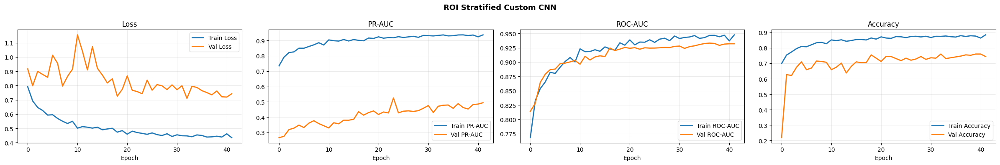

 Reloaded best checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_STRAT_CustomCNN.keras
  Balanced generator: 208 positives, 2413 negatives
  Each batch: 16 pos (oversampled) + 16 neg = 32
Epoch 1/50
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step - accuracy: 0.6451 - auc: 0.6920 - loss: 0.9990 - pr_auc: 0.6591 - precision: 0.6403 - recall: 0.6601
Epoch 1: val_pr_auc improved from None to 0.24825, saving model to /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_STRAT_CustomResNet.keras
150/150 ━━━━━━━━━━━━━━━━━━━━ 33s 164ms/step - accuracy: 0.6885 - auc: 0.7582 - loss: 0.9134 - pr_auc: 0.7199 - precision: 0.6801 - recall: 0.7121 - val_accuracy: 0.8960 - val_auc: 0.7986 - val_loss: 0.6051 - val_pr_auc: 0.2482 - val_precision: 0.2353 - val_recall: 0.1333 - learning_rate: 7.0000e-05
Epoch 2/50
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step - accuracy: 0.7364 - auc: 0.8102 - loss: 0.8322 - pr_auc: 0.7751 - precision: 0.7204 - recall: 0.7727
Epoch 2: val_pr_auc improved from 0.

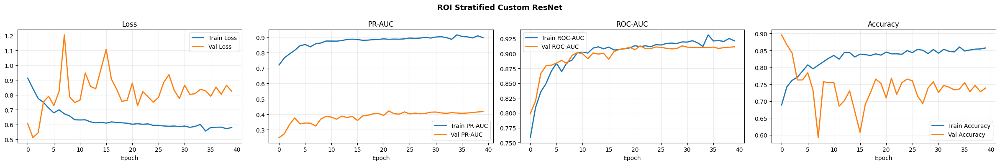

 Reloaded best checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_STRAT_CustomResNet.keras


In [ ]:
# Train ROI models on secondary stratified split
roi_strat_results = []

n_pos_strat = int((y_roi_strat_train == 1).sum())
n_neg_strat = int((y_roi_strat_train == 0).sum())
STEPS_ROI_STRAT = max(n_neg_strat // (BATCH_SIZE // 2), 10)
print(f"ROI stratified split steps per epoch: {STEPS_ROI_STRAT}")
print(f"Stratified test positives: {int(y_roi_strat_test.sum())} / {len(y_roi_strat_test)}")

gen_roi_strat_cnn = balanced_batch_generator(
    X_roi_strat_train, y_roi_strat_train, aug_gen,
    batch_size=BATCH_SIZE, seed=242
)
roi_strat_model_cnn = build_custom_cnn()
roi_strat_model_cnn = compile_scratch_model(roi_strat_model_cnn, lr=8e-5)
hist_roi_strat_cnn = fit_model(
    roi_strat_model_cnn,
    gen_roi_strat_cnn,
    steps_per_epoch=STEPS_ROI_STRAT,
    epochs=EPOCHS_SCRATCH,
    validation_data=(X_roi_strat_val, y_roi_strat_val),
    callbacks=get_callbacks('ROI_STRAT_CustomCNN', patience=18, lr_patience=6),
    verbose=1
)
plot_history(hist_roi_strat_cnn, 'ROI Stratified Custom CNN')
roi_strat_model_cnn = restore_best_trained_model(roi_strat_model_cnn, 'ROI_STRAT_CustomCNN')

gen_roi_strat_res = balanced_batch_generator(
    X_roi_strat_train, y_roi_strat_train, aug_gen,
    batch_size=BATCH_SIZE, seed=243
)
roi_strat_model_res = build_custom_resnet()
roi_strat_model_res = compile_scratch_model(roi_strat_model_res, lr=7e-5)
hist_roi_strat_res = fit_model(
    roi_strat_model_res,
    gen_roi_strat_res,
    steps_per_epoch=STEPS_ROI_STRAT,
    epochs=EPOCHS_SCRATCH,
    validation_data=(X_roi_strat_val, y_roi_strat_val),
    callbacks=get_callbacks('ROI_STRAT_CustomResNet', patience=18, lr_patience=6),
    verbose=1
)
plot_history(hist_roi_strat_res, 'ROI Stratified Custom ResNet')
roi_strat_model_res = restore_best_trained_model(roi_strat_model_res, 'ROI_STRAT_CustomResNet')


We train and fine-tune EfficientNetB0 on the secondary stratified data split.


  Balanced generator: 208 positives, 2413 negatives
  Each batch: 16 pos (oversampled) + 16 neg = 32
Epoch 1/20
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step - accuracy: 0.6761 - auc: 0.7346 - loss: 0.6572 - pr_auc: 0.7140 - precision: 0.6334 - recall: 0.8434

2026-05-28 04:35:17.090206: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2142', 232 bytes spill stores, 232 bytes spill loads

2026-05-28 04:35:17.157755: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2142_0', 404 bytes spill stores, 1284 bytes spill loads

2026-05-28 04:35:17.402623: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2142', 5524 bytes spill stores, 5564 bytes spill loads

2026-05-28 04:35:17.477669: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2142', 5380 bytes spill stores, 5380 bytes spill loads




Epoch 1: val_pr_auc improved from None to 0.52307, saving model to /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_STRAT_EfficientNetB0_P1.keras
150/150 ━━━━━━━━━━━━━━━━━━━━ 37s 197ms/step - accuracy: 0.7550 - auc: 0.8420 - loss: 0.5364 - pr_auc: 0.8157 - precision: 0.6986 - recall: 0.8971 - val_accuracy: 0.6800 - val_auc: 0.9310 - val_loss: 0.5886 - val_pr_auc: 0.5231 - val_precision: 0.1959 - val_recall: 0.9667 - learning_rate: 5.0000e-05
Epoch 2/20
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step - accuracy: 0.8351 - auc: 0.9098 - loss: 0.4115 - pr_auc: 0.8886 - precision: 0.7828 - recall: 0.9278
Epoch 2: val_pr_auc improved from 0.52307 to 0.67281, saving model to /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_STRAT_EfficientNetB0_P1.keras
150/150 ━━━━━━━━━━━━━━━━━━━━ 21s 140ms/step - accuracy: 0.8467 - auc: 0.9216 - loss: 0.3849 - pr_auc: 0.9038 - precision: 0.7976 - recall: 0.9292 - val_accuracy: 0.7973 - val_auc: 0.9530 - val_loss: 0.4578 - val_pr_auc: 0.6728 - val_pre

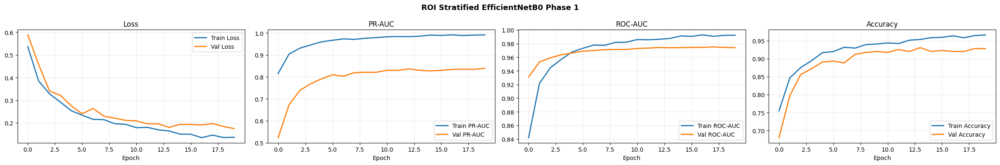

  Balanced generator: 208 positives, 2413 negatives
  Each batch: 16 pos (oversampled) + 16 neg = 32
Epoch 1/40
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step - accuracy: 0.9161 - auc: 0.9727 - loss: 0.2444 - pr_auc: 0.9689 - precision: 0.9277 - recall: 0.9029
Epoch 1: val_pr_auc improved from None to 0.75287, saving model to /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_STRAT_EfficientNetB0_P2.keras
150/150 ━━━━━━━━━━━━━━━━━━━━ 35s 169ms/step - accuracy: 0.9225 - auc: 0.9749 - loss: 0.2300 - pr_auc: 0.9711 - precision: 0.9229 - recall: 0.9221 - val_accuracy: 0.8933 - val_auc: 0.9646 - val_loss: 0.2449 - val_pr_auc: 0.7529 - val_precision: 0.4194 - val_recall: 0.8667 - learning_rate: 1.0000e-05
Epoch 2/40
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step - accuracy: 0.9397 - auc: 0.9805 - loss: 0.2017 - pr_auc: 0.9766 - precision: 0.9266 - recall: 0.9551
Epoch 2: val_pr_auc did not improve from 0.75287
150/150 ━━━━━━━━━━━━━━━━━━━━ 21s 138ms/step - accuracy: 0.9421 - auc: 0.9827 - loss: 0

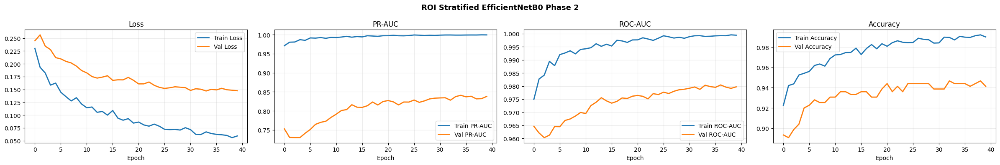

 Reloaded best checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_STRAT_EfficientNetB0_P2.keras


In [ ]:
#  Train ROI EfficientNetB0 on secondary stratified split
gen_roi_strat_eff = balanced_batch_generator(
    X_roi_strat_train, y_roi_strat_train, aug_gen,
    batch_size=BATCH_SIZE, seed=244
)
roi_strat_model_eff, roi_strat_eff_base = build_efficientnet_transfer()
roi_strat_model_eff = compile_transfer_head(roi_strat_model_eff, lr=5e-5)

hist_roi_strat_eff_p1 = fit_model(
    roi_strat_model_eff,
    gen_roi_strat_eff,
    steps_per_epoch=STEPS_ROI_STRAT,
    epochs=20,
    validation_data=(X_roi_strat_val, y_roi_strat_val),
    callbacks=get_callbacks('ROI_STRAT_EfficientNetB0_P1', patience=12, lr_patience=4),
    verbose=1
)
plot_history(hist_roi_strat_eff_p1, 'ROI Stratified EfficientNetB0 Phase 1')

roi_strat_eff_base.trainable = True
for layer in roi_strat_eff_base.layers[:-20]:
    layer.trainable = False
roi_strat_model_eff = compile_transfer_head(roi_strat_model_eff, lr=1e-5)

gen_roi_strat_eff_p2 = balanced_batch_generator(
    X_roi_strat_train, y_roi_strat_train, aug_gen,
    batch_size=BATCH_SIZE, seed=245
)
hist_roi_strat_eff_p2 = fit_model(
    roi_strat_model_eff,
    gen_roi_strat_eff_p2,
    steps_per_epoch=STEPS_ROI_STRAT,
    epochs=EPOCHS_FINETUNE,
    validation_data=(X_roi_strat_val, y_roi_strat_val),
    callbacks=get_callbacks('ROI_STRAT_EfficientNetB0_P2', patience=12, lr_patience=5),
    verbose=1
)
plot_history(hist_roi_strat_eff_p2, 'ROI Stratified EfficientNetB0 Phase 2')
roi_strat_model_eff = restore_best_trained_model(roi_strat_model_eff, 'ROI_STRAT_EfficientNetB0_P2')


##Experiment: I enhanced my two deep learning models that i made from scratch to analyze if there will be any improvment


```
Result:

1.  Custom ResNet v3 was better then Custom ResNet
2.  Original version of Custom CNN was better than the new version

```



We define helpers for mining hard negative samples to improve model robustness during training.


In [ ]:
#  Hard-negative mining helpers and v3 compile/generator utilities

ROI_SCRATCH_V3_POS_FRACTION = 0.30
ROI_SCRATCH_V3_HARD_NEG_FRACTION = 0.50
ROI_SCRATCH_V3_FOCAL_GAMMA = 2.0
ROI_SCRATCH_V3_FOCAL_ALPHA = 0.60
ROI_SCRATCH_V3_WEIGHT_DECAY = 2e-5
ROI_SCRATCH_V3_WARMUP_EPOCHS = 8
ROI_SCRATCH_V3_MIN_HARD_NEG = 64

required_v3_helpers = [
    'X_roi_train', 'X_roi_val', 'X_roi_test',
    'y_train_osteo', 'y_val_osteo', 'y_test_osteo',
    'aug_gen', 'BATCH_SIZE', 'EPOCHS_SCRATCH',
    'build_custom_cnn', 'build_custom_resnet',
    'balanced_batch_generator', 'fit_model', 'predict_model',
    'run_tf_work', 'best_checkpoint_path', 'get_callbacks', 'evaluate_model',
]
missing_v3_helpers = [name for name in required_v3_helpers if name not in globals()]
if missing_v3_helpers:
    raise RuntimeError(
        'SECTION 5A-V3 requires ROI arrays and original custom model helpers first. '
        f'Missing: {missing_v3_helpers}'
    )

def focal_loss_v3(gamma=ROI_SCRATCH_V3_FOCAL_GAMMA, alpha=ROI_SCRATCH_V3_FOCAL_ALPHA):
    # Binary focal loss tuned to reduce excessive positive predictions.
    def loss_fn(y_true, y_pred):
        y_true = tf.cast(tf.reshape(y_true, (-1, 1)), tf.float32)
        y_pred = tf.cast(y_pred, tf.float32)
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
        bce = tf.keras.backend.binary_crossentropy(y_true, y_pred)
        p_t = y_true * y_pred + (1.0 - y_true) * (1.0 - y_pred)
        alpha_t = y_true * alpha + (1.0 - y_true) * (1.0 - alpha)
        return tf.reduce_mean(alpha_t * tf.pow(1.0 - p_t, gamma) * bce)
    loss_fn.__name__ = f'focal_loss_v3_g{gamma}_a{alpha}'
    return loss_fn

FOCAL_V3 = focal_loss_v3()

def compile_scratch_model_v3(model, lr=7e-5):
    # Compile scratch v3 models with AdamW, focal loss, and gradient clipping.
    try:
        optimizer = tf.keras.optimizers.AdamW(
            learning_rate=lr,
            weight_decay=ROI_SCRATCH_V3_WEIGHT_DECAY,
            clipnorm=1.0,
        )
    except Exception:
        optimizer = tf.keras.optimizers.Adam(learning_rate=lr, clipnorm=1.0)
    model.compile(optimizer=optimizer, loss=FOCAL_V3, metrics=_metrics())
    return model

def _load_v3_mining_source(checkpoint_name, builder_fn, lr):
    # Prefer the original ROI custom checkpoint for mining;...
    ckpt_path = Path(best_checkpoint_path(checkpoint_name))
    if ckpt_path.exists():
        print(f'Using existing checkpoint for hard-negative mining: {ckpt_path}')
        return run_tf_work(
            lambda: tf.keras.models.load_model(ckpt_path, compile=False),
            description=f'load mining checkpoint {checkpoint_name}',
            fallback_to_cpu=False,
        ), 'v2_checkpoint'

    print(f'Missing {ckpt_path}; training {ROI_SCRATCH_V3_WARMUP_EPOCHS}-epoch warmup model for mining only.')
    warmup_model = builder_fn()
    warmup_model = compile_scratch_model_v3(warmup_model, lr=lr)
    warmup_gen = balanced_batch_generator(
        X_roi_train, y_train_osteo, aug_gen,
        batch_size=BATCH_SIZE, seed=932,
    )
    n_neg = int((np.asarray(y_train_osteo) == 0).sum())
    n_neg_batch = max(1, BATCH_SIZE - max(1, int(round(BATCH_SIZE * ROI_SCRATCH_V3_POS_FRACTION))))
    warmup_steps = max(min(n_neg // n_neg_batch, 120), 10)
    fit_model(
        warmup_model,
        warmup_gen,
        steps_per_epoch=warmup_steps,
        epochs=ROI_SCRATCH_V3_WARMUP_EPOCHS,
        validation_data=(X_roi_val.astype(np.float32, copy=False), y_val_osteo),
        callbacks=get_callbacks(f'{checkpoint_name}_warmup_for_hnm', patience=4, lr_patience=2),
        verbose=1,
        description=f'{checkpoint_name} warmup for hard-negative mining',
    )
    return warmup_model, 'warmup'

def mine_hard_negatives_v3(checkpoint_name, builder_fn, lr, model_label, quantile=0.80):
    # Mine high-score true negatives from X_roi_train only.
    mining_model, source = _load_v3_mining_source(checkpoint_name, builder_fn, lr)
    try:
        train_prob = predict_model(
            mining_model,
            X_roi_train.astype(np.float32, copy=False),
            batch_size=32,
            verbose=0,
            description=f'{model_label} train-only hard-negative mining',
        ).ravel()
    finally:
        del mining_model
        tf.keras.backend.clear_session()
        gc.collect()

    y_arr = np.asarray(y_train_osteo).astype(int)
    neg_idx = np.where(y_arr == 0)[0]
    neg_scores = train_prob[neg_idx]
    if len(neg_scores) == 0:
        raise ValueError(f'{model_label}: no negative training samples available for hard-negative mining.')

    score_cutoff = float(np.quantile(neg_scores, quantile))
    hard_neg_idx = neg_idx[neg_scores >= score_cutoff]
    if len(hard_neg_idx) < ROI_SCRATCH_V3_MIN_HARD_NEG:
        top_k = min(max(ROI_SCRATCH_V3_MIN_HARD_NEG, 1), len(neg_idx))
        hard_neg_idx = neg_idx[np.argsort(neg_scores)[-top_k:]]
        score_cutoff = float(train_prob[hard_neg_idx].min())

    hard_neg_idx = np.asarray(hard_neg_idx, dtype=int)
    report = pd.DataFrame({
        'model_family': model_label,
        'mining_source': source,
        'train_index': hard_neg_idx,
        'score': train_prob[hard_neg_idx],
        'current_label': y_arr[hard_neg_idx],
    }).sort_values('score', ascending=False)

    print(
        f'{model_label}: mined {len(hard_neg_idx)} hard negatives from TRAIN only '
        f'(source={source}, cutoff={score_cutoff:.4f}).'
    )
    return hard_neg_idx, report

def hard_negative_batch_generator_v3(
    X, y, aug_gen, hard_neg_idx,
    batch_size=32, seed=42,
    pos_fraction=ROI_SCRATCH_V3_POS_FRACTION,
    hard_neg_fraction=ROI_SCRATCH_V3_HARD_NEG_FRACTION,
):
    # Yield batches with positives, hard negatives, and regular negatives.
    y = np.asarray(y).astype(np.float32)
    pos_idx = np.where(y == 1)[0]
    neg_idx = np.where(y == 0)[0]
    hard_neg_idx = np.asarray(hard_neg_idx, dtype=int)
    hard_neg_idx = np.intersect1d(hard_neg_idx, neg_idx)
    easy_neg_idx = np.setdiff1d(neg_idx, hard_neg_idx)
    if len(pos_idx) == 0 or len(neg_idx) == 0:
        raise ValueError('hard_negative_batch_generator_v3 needs both classes.')
    if len(hard_neg_idx) == 0:
        hard_neg_idx = neg_idx
        easy_neg_idx = neg_idx

    n_pos = max(1, int(round(batch_size * pos_fraction)))
    n_neg = batch_size - n_pos
    n_hard = max(1, int(round(n_neg * hard_neg_fraction)))
    n_easy = max(0, n_neg - n_hard)
    rng = np.random.default_rng(seed)

    print(f'  V3 generator: {len(pos_idx)} positives, {len(hard_neg_idx)} hard negatives, {len(easy_neg_idx)} easy negatives')
    print(f'  Each batch: {n_pos} pos + {n_hard} hard-neg + {n_easy} easy-neg = {n_pos + n_hard + n_easy}')

    while True:
        chosen_pos = rng.choice(pos_idx, size=n_pos, replace=True)
        chosen_hard = rng.choice(hard_neg_idx, size=n_hard, replace=(len(hard_neg_idx) < n_hard))
        if n_easy > 0:
            chosen_easy = rng.choice(easy_neg_idx if len(easy_neg_idx) else neg_idx, size=n_easy, replace=True)
            idx = np.concatenate([chosen_pos, chosen_hard, chosen_easy])
        else:
            idx = np.concatenate([chosen_pos, chosen_hard])
        idx = rng.permutation(idx)
        X_raw = X[idx]
        y_raw = y[idx].copy()
        X_aug = np.array([
            aug_gen.random_transform(x.astype('float32')) for x in X_raw
        ], dtype=np.float32)
        brightness = rng.uniform(0.92, 1.08, size=(len(X_aug), 1, 1, 1)).astype(np.float32)
        X_aug = np.clip(X_aug * brightness, 0.0, 1.0)
        yield X_aug.astype(np.float32), y_raw.astype(np.float32)

print('ROI scratch v3 hard-negative mining helpers ready.')



ROI scratch v3 hard-negative mining helpers ready.


We retrain Custom CNN and ResNet models incorporating the mined hard negatives.


ROI scratch v3 train: 2445 Non-Osteo | 214 Osteo
ROI scratch v3 batch: 10 pos | 22 neg
ROI scratch v3 steps per epoch: 111
Using existing checkpoint for hard-negative mining: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_CustomCNN.keras
ROI-CustomCNN-v3: mined 489 hard negatives from TRAIN only (source=v2_checkpoint, cutoff=0.7360).
Using existing checkpoint for hard-negative mining: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_CustomResNet.keras
ROI-CustomResNet-v3: mined 489 hard negatives from TRAIN only (source=v2_checkpoint, cutoff=0.7032).
Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/roi_scratch_v3_hard_negative_report.csv
  V3 generator: 214 positives, 489 hard negatives, 1956 easy negatives
  Each batch: 10 pos + 11 hard-neg + 11 easy-neg = 32
Epoch 1/50


2026-05-29 21:42:53.176335: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_7449', 20 bytes spill stores, 20 bytes spill loads

2026-05-29 21:42:53.968633: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_7449', 32 bytes spill stores, 32 bytes spill loads



111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step - accuracy: 0.5378 - auc: 0.5816 - loss: 0.3722 - pr_auc: 0.3933 - precision: 0.3475 - recall: 0.5465
Epoch 1: val_pr_auc improved from None to 0.25119, saving model to /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_CustomCNN_v3.keras
111/111 ━━━━━━━━━━━━━━━━━━━━ 32s 182ms/step - accuracy: 0.5659 - auc: 0.6087 - loss: 0.3539 - pr_auc: 0.4121 - precision: 0.3767 - recall: 0.5946 - val_accuracy: 0.9142 - val_auc: 0.7999 - val_loss: 0.2169 - val_pr_auc: 0.2512 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 8.0000e-05
Epoch 2/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step - accuracy: 0.6161 - auc: 0.6566 - loss: 0.3200 - pr_auc: 0.4828 - precision: 0.4198 - recall: 0.5974
Epoch 2: val_pr_auc did not improve from 0.25119
111/111 ━━━━━━━━━━━━━━━━━━━━ 15s 138ms/step - accuracy: 0.6081 - auc: 0.6494 - loss: 0.3226 - pr_auc: 0.4636 - precision: 0.4115 - recall: 0.5910 - val_accuracy: 0.9142 - val_auc: 0.8091 - val_loss: 0.

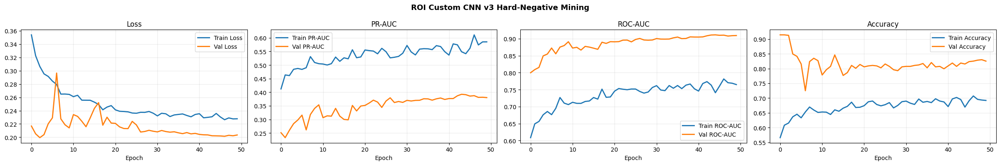

Best ROI Custom CNN v3 checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_CustomCNN_v3.keras
  V3 generator: 214 positives, 489 hard negatives, 1956 easy negatives
  Each batch: 10 pos + 11 hard-neg + 11 easy-neg = 32
Epoch 1/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step - accuracy: 0.5582 - auc: 0.5789 - loss: 0.5033 - pr_auc: 0.3729 - precision: 0.3724 - recall: 0.6051
Epoch 1: val_pr_auc improved from None to 0.22091, saving model to /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_CustomResNet_v3.keras
111/111 ━━━━━━━━━━━━━━━━━━━━ 33s 176ms/step - accuracy: 0.5642 - auc: 0.5985 - loss: 0.4862 - pr_auc: 0.3848 - precision: 0.3791 - recall: 0.6189 - val_accuracy: 0.1052 - val_auc: 0.7933 - val_loss: 0.3822 - val_pr_auc: 0.2209 - val_precision: 0.0875 - val_recall: 1.0000 - learning_rate: 7.0000e-05
Epoch 2/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step - accuracy: 0.5519 - auc: 0.5831 - loss: 0.4816 - pr_auc: 0.3676 - precision: 0.3616 - recall: 0.5678
Epoch 2: v

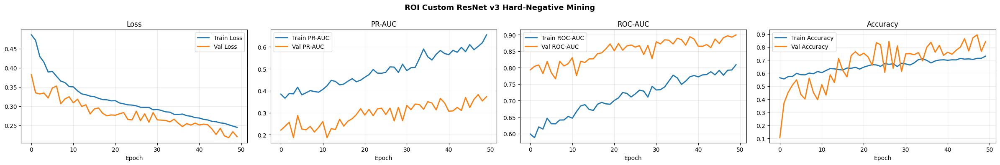

Best ROI Custom ResNet v3 checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_CustomResNet_v3.keras
ROI scratch v3 training complete. Best models are saved on disk.


In [ ]:
# Train ROI Custom CNN v3 and ROI Custom ResNET v3
required_v3_train = [
    'X_roi_train', 'X_roi_val', 'X_roi_test',
    'y_train_osteo', 'y_val_osteo', 'y_test_osteo',
]
missing_v3_train = [name for name in required_v3_train if name not in globals()]
if missing_v3_train:
    raise RuntimeError(f'Missing ROI inputs for Section 5A-V3: {missing_v3_train}. Run CELL 5A-1 first.')

X_roi_val_v3 = X_roi_val.astype(np.float32, copy=False)
n_pos_roi_v3 = int((np.asarray(y_train_osteo) == 1).sum())
n_neg_roi_v3 = int((np.asarray(y_train_osteo) == 0).sum())
n_pos_batch_v3 = max(1, int(round(BATCH_SIZE * ROI_SCRATCH_V3_POS_FRACTION)))
n_neg_batch_v3 = BATCH_SIZE - n_pos_batch_v3
STEPS_ROI_V3 = max(n_neg_roi_v3 // max(n_neg_batch_v3, 1), 10)

print(f'ROI scratch v3 train: {n_neg_roi_v3} Non-Osteo | {n_pos_roi_v3} Osteo')
print(f'ROI scratch v3 batch: {n_pos_batch_v3} pos | {n_neg_batch_v3} neg')
print(f'ROI scratch v3 steps per epoch: {STEPS_ROI_V3}')

hard_neg_cnn_v3, hard_report_cnn_v3 = mine_hard_negatives_v3(
    'ROI_CustomCNN',
    build_custom_cnn,
    8e-5,
    'ROI-CustomCNN-v3',
)
hard_neg_res_v3, hard_report_res_v3 = mine_hard_negatives_v3(
    'ROI_CustomResNet',
    build_custom_resnet,
    7e-5,
    'ROI-CustomResNet-v3',
)

roi_scratch_v3_hard_negative_report_df = pd.concat(
    [hard_report_cnn_v3, hard_report_res_v3],
    ignore_index=True,
)
hard_neg_report_path_v3 = os.path.join(OUTPUT_DIR, 'roi_scratch_v3_hard_negative_report.csv')
roi_scratch_v3_hard_negative_report_df.to_csv(hard_neg_report_path_v3, index=False)
print(f'Saved: {hard_neg_report_path_v3}')

gen_roi_cnn_v3 = hard_negative_batch_generator_v3(
    X_roi_train, y_train_osteo, aug_gen, hard_neg_cnn_v3,
    batch_size=BATCH_SIZE, seed=542,
)
roi_model_cnn_v3 = build_custom_cnn()
roi_model_cnn_v3 = compile_scratch_model_v3(roi_model_cnn_v3, lr=8e-5)

hist_roi_cnn_v3 = fit_model(
    roi_model_cnn_v3,
    gen_roi_cnn_v3,
    steps_per_epoch=STEPS_ROI_V3,
    epochs=EPOCHS_SCRATCH,
    validation_data=(X_roi_val_v3, y_val_osteo),
    callbacks=get_callbacks('ROI_CustomCNN_v3', patience=22, lr_patience=7),
    verbose=1,
)
plot_history(hist_roi_cnn_v3, 'ROI Custom CNN v3 Hard-Negative Mining')
print(f"Best ROI Custom CNN v3 checkpoint: {best_checkpoint_path('ROI_CustomCNN_v3')}")

del roi_model_cnn_v3
tf.keras.backend.clear_session()
gc.collect()

gen_roi_res_v3 = hard_negative_batch_generator_v3(
    X_roi_train, y_train_osteo, aug_gen, hard_neg_res_v3,
    batch_size=BATCH_SIZE, seed=543,
)
roi_model_res_v3 = build_custom_resnet()
roi_model_res_v3 = compile_scratch_model_v3(roi_model_res_v3, lr=7e-5)

hist_roi_res_v3 = fit_model(
    roi_model_res_v3,
    gen_roi_res_v3,
    steps_per_epoch=STEPS_ROI_V3,
    epochs=EPOCHS_SCRATCH,
    validation_data=(X_roi_val_v3, y_val_osteo),
    callbacks=get_callbacks('ROI_CustomResNet_v3', patience=22, lr_patience=7),
    verbose=1,
)
plot_history(hist_roi_res_v3, 'ROI Custom ResNet v3 Hard-Negative Mining')
print(f"Best ROI Custom ResNet v3 checkpoint: {best_checkpoint_path('ROI_CustomResNet_v3')}")

del roi_model_res_v3
tf.keras.backend.clear_session()
gc.collect()
print('ROI scratch v3 training complete. Best models are saved on disk.')



We define helper functions to load pretrained ResNet50V2 and DenseNet121 transfer learning models.


In [ ]:
#  Pretrained ResNet50V2 and DenseNet121 helpers

ROI_PRETRAINED_POS_FRACTION = 0.33
ROI_PRETRAINED_PHASE1_EPOCHS = 20
ROI_PRETRAINED_UNFREEZE_LAST = 20

def _imagenet_densenet_normalization_layer():
    """Normalize [0,1] RGB images using DenseNet/ImageNet mean and std."""
    mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
    std = np.array([0.229, 0.224, 0.225], dtype=np.float32)
    return layers.Normalization(
        axis=-1,
        mean=mean,
        variance=np.square(std),
        name='imagenet_mean_std_normalization',
    )

def compile_roi_pretrained_model(model, lr=5e-5):
    """Compile pretrained ROI models with the same binary metrics as other image models."""
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss='binary_crossentropy',
        metrics=_metrics(),
    )
    return model

def _roi_pretrained_head(x, dropout=0.45):
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(
        192,
        kernel_regularizer=regularizers.l2(1e-4),
        kernel_initializer='he_normal',
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(1, activation='sigmoid', name='output')(x)
    return outputs

def build_resnet50v2_transfer(input_shape=(224, 224, 3), weights='imagenet'):
    """ResNet50V2 transfer model for ROI images stored in [0,1]."""
    base = ResNet50V2(
        weights=weights,
        include_top=False,
        input_shape=input_shape,
    )
    base.trainable = False

    inputs = layers.Input(shape=input_shape, name='img_input')
    x = layers.Rescaling(scale=2.0, offset=-1.0, name='rescale_for_resnet50v2')(inputs)
    x = base(x)
    outputs = _roi_pretrained_head(x, dropout=0.45)
    model = models.Model(inputs, outputs, name='ROI_ResNet50V2_Transfer')
    return model, base

def build_densenet121_transfer(input_shape=(224, 224, 3), weights='imagenet'):
    """DenseNet121 transfer model for ROI images stored in [0,1]."""
    base = DenseNet121(
        weights=weights,
        include_top=False,
        input_shape=input_shape,
    )
    base.trainable = False

    inputs = layers.Input(shape=input_shape, name='img_input')
    x = _imagenet_densenet_normalization_layer()(inputs)
    x = base(x)
    outputs = _roi_pretrained_head(x, dropout=0.45)
    model = models.Model(inputs, outputs, name='ROI_DenseNet121_Transfer')
    return model, base

def make_roi_pretrained_generator(X, y, seed):
    """Use the v2 balanced generator when available; otherwise fall back safely."""
    if 'balanced_batch_generator_v2' in globals():
        return balanced_batch_generator_v2(
            X, y, aug_gen,
            batch_size=BATCH_SIZE,
            seed=seed,
            pos_fraction=ROI_PRETRAINED_POS_FRACTION,
        )
    print('balanced_batch_generator_v2 not found; using original 50/50 balanced_batch_generator.')
    return balanced_batch_generator(X, y, aug_gen, batch_size=BATCH_SIZE, seed=seed)

def roi_pretrained_steps_per_epoch(y):
    n_neg = int((np.asarray(y) == 0).sum())
    if 'balanced_batch_generator_v2' in globals():
        n_pos_batch = max(1, int(round(BATCH_SIZE * ROI_PRETRAINED_POS_FRACTION)))
        n_neg_batch = BATCH_SIZE - n_pos_batch
    else:
        n_neg_batch = BATCH_SIZE // 2
    return max(n_neg // max(n_neg_batch, 1), 10)

def fine_tune_last_layers(base_model, n_layers=ROI_PRETRAINED_UNFREEZE_LAST):
    base_model.trainable = True
    for layer in base_model.layers[:-n_layers]:
        layer.trainable = False
    for layer in base_model.layers[-n_layers:]:
        layer.trainable = True

def load_roi_pretrained_checkpoint(checkpoint_name):
    ckpt_path = best_checkpoint_path(checkpoint_name)
    if not os.path.exists(ckpt_path):
        raise FileNotFoundError(f'Missing checkpoint: {ckpt_path}. Run the matching training cell first.')
    load_kwargs = {'compile': False}
    if 'CBAM' in checkpoint_name:
        # Older CBAM checkpoints may contain Lambda layers from the first CBAM implementation.
        # The notebook creates these artifacts locally, so safe_mode=False is acceptable here.
        load_kwargs['safe_mode'] = False
    return run_tf_work(
        lambda: tf.keras.models.load_model(ckpt_path, **load_kwargs),
        description=f'load {checkpoint_name}',
        fallback_to_cpu=False,
    )

print('ROI pretrained ResNet50V2/DenseNet121 helpers ready.')




ROI pretrained ResNet50V2/DenseNet121 helpers ready.


We train a pretrained ResNet50V2 classifier on the cropped ROI dataset split.


ROI pretrained steps per epoch: 116
94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 28s 0us/step
  V2 generator: 214 positives, 2445 negatives
  Each batch: 11 pos + 21 neg = 32
  Positive MixUp: True (threshold=500)
Epoch 1/20


2026-05-29 22:13:59.916975: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_5288', 204 bytes spill stores, 204 bytes spill loads

2026-05-29 22:14:00.054928: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_5882', 4 bytes spill stores, 4 bytes spill loads

2026-05-29 22:14:00.245281: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_5288', 3960 bytes spill stores, 3940 bytes spill loads

2026-05-29 22:14:00.279733: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_5288', 1000 bytes spill stores, 1000 bytes spill loads



116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step - accuracy: 0.5368 - auc: 0.7358 - loss: 0.9220 - pr_auc: 0.5781 - precision: 0.4228 - recall: 0.9322

2026-05-29 22:14:23.221005: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1600', 104 bytes spill stores, 104 bytes spill loads

2026-05-29 22:14:23.462922: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1600', 4044 bytes spill stores, 4024 bytes spill loads

2026-05-29 22:14:23.552897: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1600', 1020 bytes spill stores, 1020 bytes spill loads




Epoch 1: val_pr_auc improved from None to 0.44560, saving model to /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_ResNet50V2_P1.keras
116/116 ━━━━━━━━━━━━━━━━━━━━ 30s 189ms/step - accuracy: 0.6126 - auc: 0.8302 - loss: 0.8069 - pr_auc: 0.6988 - precision: 0.4689 - recall: 0.9585 - val_accuracy: 0.6100 - val_auc: 0.8943 - val_loss: 0.8603 - val_pr_auc: 0.4456 - val_precision: 0.1736 - val_recall: 0.9434 - learning_rate: 5.0000e-05
Epoch 2/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step - accuracy: 0.7438 - auc: 0.9251 - loss: 0.5752 - pr_auc: 0.8583 - precision: 0.5767 - recall: 0.9635
Epoch 2: val_pr_auc improved from 0.44560 to 0.55344, saving model to /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_ResNet50V2_P1.keras
116/116 ━━━━━━━━━━━━━━━━━━━━ 16s 140ms/step - accuracy: 0.7667 - auc: 0.9253 - loss: 0.5507 - pr_auc: 0.8585 - precision: 0.6005 - recall: 0.9600 - val_accuracy: 0.7168 - val_auc: 0.9309 - val_loss: 0.6593 - val_pr_auc: 0.5534 - val_precision: 0.2252 - val

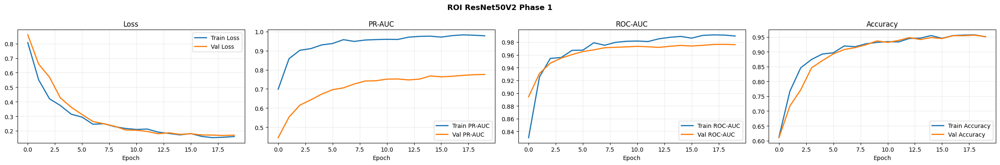

Best ROI ResNet50V2 Phase 1 checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_ResNet50V2_P1.keras
  V2 generator: 214 positives, 2445 negatives
  Each batch: 11 pos + 21 neg = 32
  Positive MixUp: True (threshold=500)
Epoch 1/40


2026-05-29 22:19:32.364677: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_6873', 500 bytes spill stores, 500 bytes spill loads



116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step - accuracy: 0.9327 - auc: 0.9834 - loss: 0.1932 - pr_auc: 0.9708 - precision: 0.9121 - recall: 0.8899
Epoch 1: val_pr_auc improved from None to 0.79953, saving model to /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_ResNet50V2_P2.keras
116/116 ━━━━━━━━━━━━━━━━━━━━ 29s 193ms/step - accuracy: 0.9386 - auc: 0.9852 - loss: 0.1856 - pr_auc: 0.9721 - precision: 0.9113 - recall: 0.9099 - val_accuracy: 0.9466 - val_auc: 0.9738 - val_loss: 0.1735 - val_pr_auc: 0.7995 - val_precision: 0.6429 - val_recall: 0.8491 - learning_rate: 1.0000e-05
Epoch 2/40
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - accuracy: 0.9562 - auc: 0.9925 - loss: 0.1484 - pr_auc: 0.9855 - precision: 0.9271 - recall: 0.9474
Epoch 2: val_pr_auc improved from 0.79953 to 0.80578, saving model to /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_ResNet50V2_P2.keras
116/116 ━━━━━━━━━━━━━━━━━━━━ 18s 154ms/step - accuracy: 0.9539 - auc: 0.9911 - loss: 0.1535 - pr_auc: 0.9820 - p

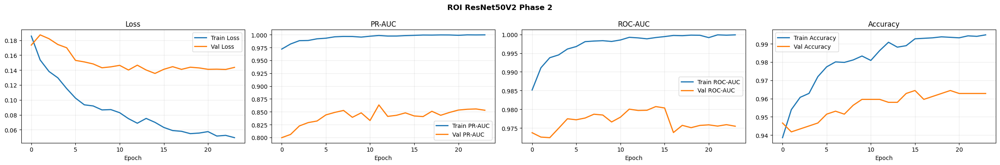

Best ROI ResNet50V2 Phase 2 checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_ResNet50V2_P2.keras
ROI ResNet50V2 training complete. Best checkpoint saved on disk.


In [ ]:
# Train ROI ResNet50V2 on original Dataset 1 split
required_pretrained = ['X_roi_train', 'X_roi_val', 'X_roi_test', 'y_train_osteo', 'y_val_osteo', 'y_test_osteo']
missing_pretrained = [name for name in required_pretrained if name not in globals()]
if missing_pretrained:
    raise RuntimeError(f'Missing ROI inputs for Section 5A-P: {missing_pretrained}. Run CELL 5A-1 first.')

X_roi_val_pretrained = X_roi_val.astype(np.float32, copy=False)
STEPS_ROI_PRETRAINED = roi_pretrained_steps_per_epoch(y_train_osteo)
print(f'ROI pretrained steps per epoch: {STEPS_ROI_PRETRAINED}')

gen_roi_resnet50v2_p1 = make_roi_pretrained_generator(X_roi_train, y_train_osteo, seed=442)
roi_resnet50v2_model, roi_resnet50v2_base = build_resnet50v2_transfer()
roi_resnet50v2_model = compile_roi_pretrained_model(roi_resnet50v2_model, lr=5e-5)

hist_roi_resnet50v2_p1 = fit_model(
    roi_resnet50v2_model,
    gen_roi_resnet50v2_p1,
    steps_per_epoch=STEPS_ROI_PRETRAINED,
    epochs=ROI_PRETRAINED_PHASE1_EPOCHS,
    validation_data=(X_roi_val_pretrained, y_val_osteo),
    callbacks=get_callbacks('ROI_ResNet50V2_P1', patience=12, lr_patience=5),
    verbose=1,
)
plot_history(hist_roi_resnet50v2_p1, 'ROI ResNet50V2 Phase 1')
print(f"Best ROI ResNet50V2 Phase 1 checkpoint: {best_checkpoint_path('ROI_ResNet50V2_P1')}")

fine_tune_last_layers(roi_resnet50v2_base, ROI_PRETRAINED_UNFREEZE_LAST)
roi_resnet50v2_model = compile_roi_pretrained_model(roi_resnet50v2_model, lr=1e-5)
gen_roi_resnet50v2_p2 = make_roi_pretrained_generator(X_roi_train, y_train_osteo, seed=443)

hist_roi_resnet50v2_p2 = fit_model(
    roi_resnet50v2_model,
    gen_roi_resnet50v2_p2,
    steps_per_epoch=STEPS_ROI_PRETRAINED,
    epochs=EPOCHS_FINETUNE,
    validation_data=(X_roi_val_pretrained, y_val_osteo),
    callbacks=get_callbacks('ROI_ResNet50V2_P2', patience=12, lr_patience=5),
    verbose=1,
)
plot_history(hist_roi_resnet50v2_p2, 'ROI ResNet50V2 Phase 2')
print(f"Best ROI ResNet50V2 Phase 2 checkpoint: {best_checkpoint_path('ROI_ResNet50V2_P2')}")

del roi_resnet50v2_model, roi_resnet50v2_base
tf.keras.backend.clear_session()
gc.collect()
print('ROI ResNet50V2 training complete. Best checkpoint saved on disk.')


We train a pretrained DenseNet121 classifier on the cropped ROI dataset split.


ROI pretrained steps per epoch: 116
29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 8s 0us/step
  V2 generator: 214 positives, 2445 negatives
  Each batch: 11 pos + 21 neg = 32
  Positive MixUp: True (threshold=500)
Epoch 1/20


2026-05-29 22:26:39.877248: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_9073', 160 bytes spill stores, 448 bytes spill loads

2026-05-29 22:26:39.932985: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_18196', 4 bytes spill stores, 4 bytes spill loads

2026-05-29 22:26:39.972919: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_9073_0', 308 bytes spill stores, 720 bytes spill loads

2026-05-29 22:26:40.068772: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_9073', 3908 bytes spill stores, 3896 bytes spill loads

2026-05-29 22:26:40.353772: I e

116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step - accuracy: 0.6665 - auc: 0.6547 - loss: 0.6787 - pr_auc: 0.4790 - precision: 0.5060 - recall: 0.3296

2026-05-29 22:27:13.631862: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_3396', 104 bytes spill stores, 104 bytes spill loads

2026-05-29 22:27:13.705249: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_3396_0', 224 bytes spill stores, 376 bytes spill loads

2026-05-29 22:27:14.000302: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_3396', 3992 bytes spill stores, 3976 bytes spill loads

2026-05-29 22:27:14.083687: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_3396', 1004 bytes spill stores, 1004 bytes spill loads




Epoch 1: val_pr_auc improved from None to 0.26113, saving model to /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_DenseNet121_P1.keras
116/116 ━━━━━━━━━━━━━━━━━━━━ 48s 269ms/step - accuracy: 0.7209 - auc: 0.7666 - loss: 0.5837 - pr_auc: 0.5993 - precision: 0.6205 - recall: 0.4843 - val_accuracy: 0.7896 - val_auc: 0.8430 - val_loss: 0.4251 - val_pr_auc: 0.2611 - val_precision: 0.2381 - val_recall: 0.6604 - learning_rate: 5.0000e-05
Epoch 2/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step - accuracy: 0.8077 - auc: 0.8928 - loss: 0.4259 - pr_auc: 0.7912 - precision: 0.7279 - recall: 0.7042
Epoch 2: val_pr_auc improved from 0.26113 to 0.39927, saving model to /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_DenseNet121_P1.keras
116/116 ━━━━━━━━━━━━━━━━━━━━ 17s 151ms/step - accuracy: 0.8252 - auc: 0.9107 - loss: 0.3982 - pr_auc: 0.8182 - precision: 0.7410 - recall: 0.7555 - val_accuracy: 0.8123 - val_auc: 0.8951 - val_loss: 0.3996 - val_pr_auc: 0.3993 - val_precision: 0.2886 - v

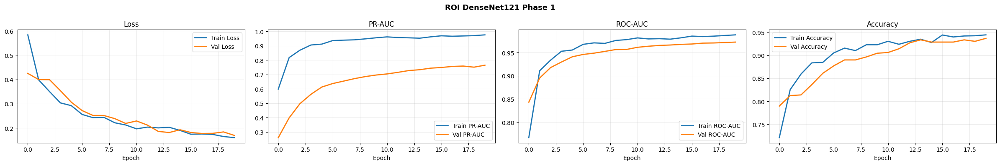

Best ROI DenseNet121 Phase 1 checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_DenseNet121_P1.keras
  V2 generator: 214 positives, 2445 negatives
  Each batch: 11 pos + 21 neg = 32
  Positive MixUp: True (threshold=500)
Epoch 1/40


2026-05-29 22:32:38.306477: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_14139', 500 bytes spill stores, 500 bytes spill loads



116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - accuracy: 0.9335 - auc: 0.9825 - loss: 0.1837 - pr_auc: 0.9617 - precision: 0.8963 - recall: 0.9120
Epoch 1: val_pr_auc improved from None to 0.75013, saving model to /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_DenseNet121_P2.keras
116/116 ━━━━━━━━━━━━━━━━━━━━ 40s 234ms/step - accuracy: 0.9367 - auc: 0.9831 - loss: 0.1808 - pr_auc: 0.9617 - precision: 0.9032 - recall: 0.9138 - val_accuracy: 0.9466 - val_auc: 0.9749 - val_loss: 0.1635 - val_pr_auc: 0.7501 - val_precision: 0.6515 - val_recall: 0.8113 - learning_rate: 1.0000e-05
Epoch 2/40
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step - accuracy: 0.9443 - auc: 0.9880 - loss: 0.1596 - pr_auc: 0.9749 - precision: 0.9085 - recall: 0.9320
Epoch 2: val_pr_auc improved from 0.75013 to 0.75773, saving model to /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_DenseNet121_P2.keras
116/116 ━━━━━━━━━━━━━━━━━━━━ 18s 154ms/step - accuracy: 0.9485 - auc: 0.9885 - loss: 0.1578 - pr_auc: 0.9759 -

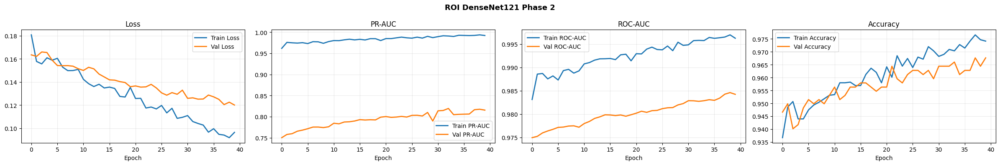

Best ROI DenseNet121 Phase 2 checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_DenseNet121_P2.keras
ROI DenseNet121 training complete. Best checkpoint saved on disk.


In [ ]:
#Train ROI DenseNet121 on original Dataset 1 split
required_pretrained = ['X_roi_train', 'X_roi_val', 'X_roi_test', 'y_train_osteo', 'y_val_osteo', 'y_test_osteo']
missing_pretrained = [name for name in required_pretrained if name not in globals()]
if missing_pretrained:
    raise RuntimeError(f'Missing ROI inputs for Section 5A-P: {missing_pretrained}. Run CELL 5A-1 first.')

X_roi_val_pretrained = X_roi_val.astype(np.float32, copy=False)
STEPS_ROI_PRETRAINED = roi_pretrained_steps_per_epoch(y_train_osteo)
print(f'ROI pretrained steps per epoch: {STEPS_ROI_PRETRAINED}')

gen_roi_densenet121_p1 = make_roi_pretrained_generator(X_roi_train, y_train_osteo, seed=452)
roi_densenet121_model, roi_densenet121_base = build_densenet121_transfer()
roi_densenet121_model = compile_roi_pretrained_model(roi_densenet121_model, lr=5e-5)

hist_roi_densenet121_p1 = fit_model(
    roi_densenet121_model,
    gen_roi_densenet121_p1,
    steps_per_epoch=STEPS_ROI_PRETRAINED,
    epochs=ROI_PRETRAINED_PHASE1_EPOCHS,
    validation_data=(X_roi_val_pretrained, y_val_osteo),
    callbacks=get_callbacks('ROI_DenseNet121_P1', patience=12, lr_patience=5),
    verbose=1,
)
plot_history(hist_roi_densenet121_p1, 'ROI DenseNet121 Phase 1')
print(f"Best ROI DenseNet121 Phase 1 checkpoint: {best_checkpoint_path('ROI_DenseNet121_P1')}")

fine_tune_last_layers(roi_densenet121_base, ROI_PRETRAINED_UNFREEZE_LAST)
roi_densenet121_model = compile_roi_pretrained_model(roi_densenet121_model, lr=1e-5)
gen_roi_densenet121_p2 = make_roi_pretrained_generator(X_roi_train, y_train_osteo, seed=453)

hist_roi_densenet121_p2 = fit_model(
    roi_densenet121_model,
    gen_roi_densenet121_p2,
    steps_per_epoch=STEPS_ROI_PRETRAINED,
    epochs=EPOCHS_FINETUNE,
    validation_data=(X_roi_val_pretrained, y_val_osteo),
    callbacks=get_callbacks('ROI_DenseNet121_P2', patience=12, lr_patience=5),
    verbose=1,
)
plot_history(hist_roi_densenet121_p2, 'ROI DenseNet121 Phase 2')
print(f"Best ROI DenseNet121 Phase 2 checkpoint: {best_checkpoint_path('ROI_DenseNet121_P2')}")

del roi_densenet121_model, roi_densenet121_base
tf.keras.backend.clear_session()
gc.collect()
print('ROI DenseNet121 training complete. Best checkpoint saved on disk.')


We define helper functions to build a ResNet50 network modified with Convolutional Block Attention Module (CBAM).


In [ ]:
#  ResNet50-CBAM helpers

ROI_CBAM_REDUCTION_RATIO = 8
ROI_CBAM_DROPOUT = 0.45
ROI_CBAM_LABEL_SMOOTHING = 0.03

def cbam_channel_attention(x, ratio=ROI_CBAM_REDUCTION_RATIO, name='cbam_channel'):
    # CBAM channel attention: avg/max pooling plus shared MLP.
    channels = int(x.shape[-1])
    hidden = max(channels // ratio, 8)
    shared_dense_1 = layers.Dense(hidden, activation='relu', kernel_initializer='he_normal', name=f'{name}_shared_dense_1')
    shared_dense_2 = layers.Dense(channels, kernel_initializer='he_normal', name=f'{name}_shared_dense_2')
    avg_pool = layers.GlobalAveragePooling2D(name=f'{name}_avg_pool')(x)
    max_pool = layers.GlobalMaxPooling2D(name=f'{name}_max_pool')(x)
    avg_out = shared_dense_2(shared_dense_1(avg_pool))
    max_out = shared_dense_2(shared_dense_1(max_pool))
    attention = layers.Add(name=f'{name}_add')([avg_out, max_out])
    attention = layers.Activation('sigmoid', name=f'{name}_sigmoid')(attention)
    attention = layers.Reshape((1, 1, channels), name=f'{name}_reshape')(attention)
    return layers.Multiply(name=f'{name}_scale')([x, attention])

class ChannelMean(layers.Layer):
    def call(self, inputs):
        return tf.reduce_mean(inputs, axis=-1, keepdims=True)

    def get_config(self):
        return super().get_config()

class ChannelMax(layers.Layer):
    def call(self, inputs):
        return tf.reduce_max(inputs, axis=-1, keepdims=True)

    def get_config(self):
        return super().get_config()

def cbam_spatial_attention(x, name='cbam_spatial'):
    # CBAM spatial attention: avg/max channel maps plus 7x7 sigmoid conv.
    avg_map = ChannelMean(name=f'{name}_avg_map')(x)
    max_map = ChannelMax(name=f'{name}_max_map')(x)
    concat = layers.Concatenate(axis=-1, name=f'{name}_concat')([avg_map, max_map])
    attention = layers.Conv2D(1, 7, padding='same', activation='sigmoid', kernel_initializer='he_normal', use_bias=False, name=f'{name}_conv7')(concat)
    return layers.Multiply(name=f'{name}_scale')([x, attention])

def cbam_block(x, name='cbam'):
    x = cbam_channel_attention(x, name=f'{name}_channel')
    return cbam_spatial_attention(x, name=f'{name}_spatial')

def _binary_crossentropy_with_optional_label_smoothing(label_smoothing=ROI_CBAM_LABEL_SMOOTHING):
    try:
        return tf.keras.losses.BinaryCrossentropy(label_smoothing=label_smoothing)
    except TypeError:
        print('BinaryCrossentropy label_smoothing not supported; using regular binary crossentropy.')
        return 'binary_crossentropy'

def compile_roi_cbam_model(model, lr=5e-5):
    # Compile ResNet50-CBAM with AdamW when available, otherwise Adam.
    try:
        optimizer = tf.keras.optimizers.AdamW(learning_rate=lr, weight_decay=1e-5, clipnorm=1.0)
    except Exception:
        optimizer = tf.keras.optimizers.Adam(learning_rate=lr, clipnorm=1.0)
    model.compile(
        optimizer=optimizer,
        loss=_binary_crossentropy_with_optional_label_smoothing(),
        metrics=_metrics(),
    )
    return model

class ResNet50Preprocess(layers.Layer):
    def call(self, inputs):
        return resnet50_preprocess_input(inputs * 255.0)

    def get_config(self):
        return super().get_config()

def build_resnet50_cbam_transfer(input_shape=(224, 224, 3), weights='imagenet'):
    # Paper-style ResNet50-CBAM for ROI images in [0,1].
    inputs = layers.Input(shape=input_shape, name='img_input')
    x = ResNet50Preprocess(name='resnet50_preprocess')(inputs)
    base = ResNet50(weights=weights, include_top=False, input_tensor=x)
    base.trainable = False
    x = cbam_block(base.output, name='final_cbam')
    x = layers.GlobalAveragePooling2D(name='gap_after_cbam')(x)
    x = layers.Dense(192, kernel_regularizer=regularizers.l2(1e-4), kernel_initializer='he_normal', name='cbam_dense')(x)
    x = layers.BatchNormalization(name='cbam_bn')(x)
    x = layers.Activation('relu', name='cbam_relu')(x)
    x = layers.Dropout(ROI_CBAM_DROPOUT, name='cbam_dropout')(x)
    outputs = layers.Dense(1, activation='sigmoid', name='output')(x)
    return models.Model(inputs, outputs, name='ROI_ResNet50_CBAM'), base

def get_cbam_callbacks(model_name, patience=12, lr_patience=5):
    # Paper-style callbacks on validation loss.
    return [
        tf.keras.callbacks.ModelCheckpoint(best_checkpoint_path(model_name), monitor='val_loss', mode='min', save_best_only=True, verbose=1),
        tf.keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', patience=patience, restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', mode='min', factor=0.5, patience=lr_patience, min_lr=1e-8, cooldown=2, verbose=1),
    ]

print('ROI ResNet50-CBAM helpers ready.')



ROI ResNet50-CBAM helpers ready.


We train the ResNet50-CBAM model on the cropped ROI dataset split.


ROI ResNet50-CBAM steps per epoch: 116
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 27s 0us/step
  V2 generator: 214 positives, 2445 negatives
  Each batch: 11 pos + 21 neg = 32
  Positive MixUp: True (threshold=500)
Epoch 1/20


2026-05-29 23:47:46.331726: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_6', 120 bytes spill stores, 120 bytes spill loads

2026-05-29 23:47:46.398859: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_6', 36 bytes spill stores, 36 bytes spill loads



  1/116 ━━━━━━━━━━━━━━━━━━━━ 15:25 8s/step - accuracy: 0.5000 - auc: 0.3550 - loss: 0.8883 - pr_auc: 0.2624 - precision: 0.2222 - recall: 0.1818

2026-05-29 23:47:49.867557: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'input_reduce_fusion_6', 184 bytes spill stores, 180 bytes spill loads



116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step - accuracy: 0.7168 - auc: 0.7766 - loss: 0.6021 - pr_auc: 0.6186 - precision: 0.5729 - recall: 0.6516
Epoch 1: val_loss improved from None to 0.39587, saving model to /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_ResNet50_CBAM_P1.keras
116/116 ━━━━━━━━━━━━━━━━━━━━ 31s 202ms/step - accuracy: 0.7961 - auc: 0.8801 - loss: 0.4901 - pr_auc: 0.7742 - precision: 0.6743 - recall: 0.7868 - val_accuracy: 0.8511 - val_auc: 0.9348 - val_loss: 0.3959 - val_pr_auc: 0.5816 - val_precision: 0.3511 - val_recall: 0.8679 - learning_rate: 5.0000e-05
Epoch 2/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 130ms/step - accuracy: 0.8807 - auc: 0.9495 - loss: 0.3601 - pr_auc: 0.9006 - precision: 0.7949 - recall: 0.8801
Epoch 2: val_loss improved from 0.39587 to 0.30904, saving model to /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_ResNet50_CBAM_P1.keras
116/116 ━━━━━━━━━━━━━━━━━━━━ 17s 145ms/step - accuracy: 0.8944 - auc: 0.9604 - loss: 0.3357 - pr_auc: 0.9194 -

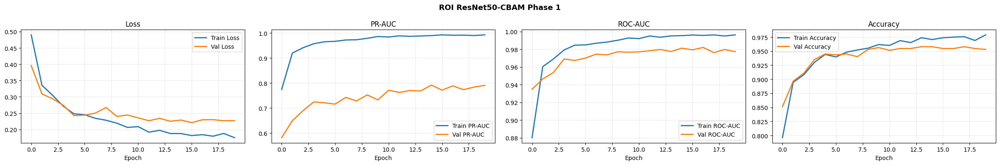

Best ROI ResNet50-CBAM Phase 1 checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_ResNet50_CBAM_P1.keras
  V2 generator: 214 positives, 2445 negatives
  Each batch: 11 pos + 21 neg = 32
  Positive MixUp: True (threshold=500)
Epoch 1/40
  2/116 ━━━━━━━━━━━━━━━━━━━━ 8s 76ms/step - accuracy: 0.9297 - auc: 0.9692 - loss: 0.2871 - pr_auc: 0.9366 - precision: 0.8732 - recall: 0.9318 

2026-05-29 23:53:29.476850: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'input_compare_reduce_fusion_1', 24 bytes spill stores, 20 bytes spill loads



116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step - accuracy: 0.9694 - auc: 0.9935 - loss: 0.1952 - pr_auc: 0.9853 - precision: 0.9490 - recall: 0.9630
Epoch 1: val_loss improved from None to 0.22409, saving model to /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_ResNet50_CBAM_P2.keras
116/116 ━━━━━━━━━━━━━━━━━━━━ 31s 195ms/step - accuracy: 0.9747 - auc: 0.9950 - loss: 0.1873 - pr_auc: 0.9888 - precision: 0.9596 - recall: 0.9671 - val_accuracy: 0.9563 - val_auc: 0.9803 - val_loss: 0.2241 - val_pr_auc: 0.7576 - val_precision: 0.7097 - val_recall: 0.8302 - learning_rate: 1.0000e-05
Epoch 2/40
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step - accuracy: 0.9720 - auc: 0.9969 - loss: 0.1769 - pr_auc: 0.9936 - precision: 0.9557 - recall: 0.9633
Epoch 2: val_loss did not improve from 0.22409
116/116 ━━━━━━━━━━━━━━━━━━━━ 18s 152ms/step - accuracy: 0.9763 - auc: 0.9973 - loss: 0.1723 - pr_auc: 0.9946 - precision: 0.9605 - recall: 0.9710 - val_accuracy: 0.9547 - val_auc: 0.9814 - val_loss: 0.2241 - v

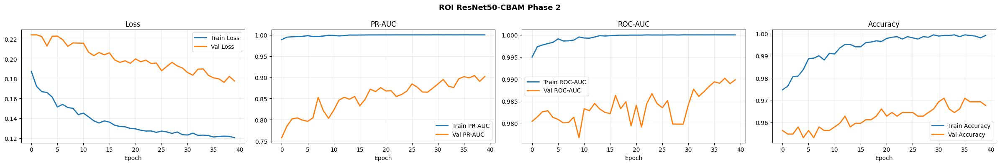

Best ROI ResNet50-CBAM Phase 2 checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_ResNet50_CBAM_P2.keras
ROI ResNet50-CBAM training complete. Best checkpoint saved on disk.


In [ ]:
# Train ROI ResNet50-CBAM on original Dataset 1 split
required_cbam = ['X_roi_train', 'X_roi_val', 'X_roi_test', 'y_train_osteo', 'y_val_osteo', 'y_test_osteo']
missing_cbam = [name for name in required_cbam if name not in globals()]
if missing_cbam:
    raise RuntimeError(f'Missing ROI inputs for ResNet50-CBAM: {missing_cbam}. Run CELL 5A-1 first.')

X_roi_val_cbam = X_roi_val.astype(np.float32, copy=False)
STEPS_ROI_CBAM = roi_pretrained_steps_per_epoch(y_train_osteo)
print(f'ROI ResNet50-CBAM steps per epoch: {STEPS_ROI_CBAM}')

gen_roi_resnet50_cbam_p1 = make_roi_pretrained_generator(X_roi_train, y_train_osteo, seed=462)
roi_resnet50_cbam_model, roi_resnet50_cbam_base = build_resnet50_cbam_transfer()
roi_resnet50_cbam_model = compile_roi_cbam_model(roi_resnet50_cbam_model, lr=5e-5)

hist_roi_resnet50_cbam_p1 = fit_model(
    roi_resnet50_cbam_model,
    gen_roi_resnet50_cbam_p1,
    steps_per_epoch=STEPS_ROI_CBAM,
    epochs=ROI_PRETRAINED_PHASE1_EPOCHS,
    validation_data=(X_roi_val_cbam, y_val_osteo),
    callbacks=get_cbam_callbacks('ROI_ResNet50_CBAM_P1', patience=12, lr_patience=5),
    verbose=1,
)
plot_history(hist_roi_resnet50_cbam_p1, 'ROI ResNet50-CBAM Phase 1')
print(f"Best ROI ResNet50-CBAM Phase 1 checkpoint: {best_checkpoint_path('ROI_ResNet50_CBAM_P1')}")

fine_tune_last_layers(roi_resnet50_cbam_base, ROI_PRETRAINED_UNFREEZE_LAST)
roi_resnet50_cbam_model = compile_roi_cbam_model(roi_resnet50_cbam_model, lr=1e-5)
gen_roi_resnet50_cbam_p2 = make_roi_pretrained_generator(X_roi_train, y_train_osteo, seed=463)

hist_roi_resnet50_cbam_p2 = fit_model(
    roi_resnet50_cbam_model,
    gen_roi_resnet50_cbam_p2,
    steps_per_epoch=STEPS_ROI_CBAM,
    epochs=EPOCHS_FINETUNE,
    validation_data=(X_roi_val_cbam, y_val_osteo),
    callbacks=get_cbam_callbacks('ROI_ResNet50_CBAM_P2', patience=12, lr_patience=5),
    verbose=1,
)
plot_history(hist_roi_resnet50_cbam_p2, 'ROI ResNet50-CBAM Phase 2')
print(f"Best ROI ResNet50-CBAM Phase 2 checkpoint: {best_checkpoint_path('ROI_ResNet50_CBAM_P2')}")

del roi_resnet50_cbam_model, roi_resnet50_cbam_base
tf.keras.backend.clear_session()
gc.collect()
print('ROI ResNet50-CBAM training complete. Best checkpoint saved on disk.')


We configure PyTorch settings, paths, and hyperparameters for our ConvNeXt-Tiny deep learning models.


In [ ]:
# setup ConvNeXt configuration




CONTRIB_MODEL_NAME = 'convnext_tiny'
CONTRIB_OPTIONAL_MODEL_NAME = 'convnextv2_tiny'
CONTRIB_BATCH_SIZE = 16
CONTRIB_EPOCHS = 30
CONTRIB_PATIENCE = 8
CONTRIB_BACKBONE_LR = 2e-5
CONTRIB_HEAD_LR = 1e-4
CONTRIB_WEIGHT_DECAY = 1e-4
CONTRIB_NUM_WORKERS = 0  # safer inside notebooks
CONTRIB_RANDOM_SEED = 42
CONTRIB_DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

required_convnext = [
    'X_roi_train', 'X_roi_val', 'X_roi_test',
    'y_train_osteo', 'y_val_osteo', 'y_test_osteo',
]
missing_convnext = [name for name in required_convnext if name not in globals()]
if missing_convnext:
    raise RuntimeError(
        'Section 5A-C requires ROI arrays from CELL 5A-1 first. '
        f'Missing: {missing_convnext}'
    )

CONTRIB_HAS_METADATA = all(name in globals() for name in ['X_tab_train', 'X_tab_val', 'X_tab_test'])
if CONTRIB_HAS_METADATA:
    TABULAR_DIM_CONTRIB = int(X_tab_train.shape[1])
else:
    TABULAR_DIM_CONTRIB = 0
    print('Metadata arrays are missing; ROI multimodal ConvNeXt branches will be skipped.')

torch.manual_seed(CONTRIB_RANDOM_SEED)
np.random.seed(CONTRIB_RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(CONTRIB_RANDOM_SEED)

print('=' * 72)
print('CONTRIBUTION: ROI LESION-AWARE CONVNEXT')
print('=' * 72)
print(f'Device                  : {CONTRIB_DEVICE}')
print(f'timm model              : {CONTRIB_MODEL_NAME}')
print(f'Optional model available: {CONTRIB_OPTIONAL_MODEL_NAME in timm.list_models(CONTRIB_OPTIONAL_MODEL_NAME)}')
print(f'ROI train/val/test     : {X_roi_train.shape} | {X_roi_val.shape} | {X_roi_test.shape}')
print(f'Labels train/val/test  : {len(y_train_osteo)} | {len(y_val_osteo)} | {len(y_test_osteo)}')
print(f'Metadata available     : {CONTRIB_HAS_METADATA} (dim={TABULAR_DIM_CONTRIB})')
print('Leakage guard          : split already exists; augmentation train-only; SMOTE train embeddings only.')
print('=' * 72)


CONTRIBUTION: ROI LESION-AWARE CONVNEXT
Device                  : cuda
timm model              : convnext_tiny
Optional model available: True
ROI train/val/test     : (2659, 224, 224, 3) | (618, 224, 224, 3) | (469, 224, 224, 3)
Labels train/val/test  : 2659 | 618 | 469
Metadata available     : True (dim=8)
Leakage guard          : split already exists; augmentation train-only; SMOTE train embeddings only.


We build custom PyTorch Datasets and DataLoaders to batch and augment ROI crops for ConvNeXt models.


In [ ]:
# ROI ConvNeXt datasets and dataloaders
CONVNEXT_MEAN = torch.tensor([0.485, 0.456, 0.406], dtype=torch.float32).view(3, 1, 1)
CONVNEXT_STD = torch.tensor([0.229, 0.224, 0.225], dtype=torch.float32).view(3, 1, 1)

class ConvNeXtImageDataset(Dataset):
    """ROI image dataset. Augmentation is applied only when augment=True."""
    def __init__(self, X, y, augment=False, seed=42):
        self.X = np.asarray(X)
        self.y = np.asarray(y).astype(np.float32)
        self.augment = bool(augment)
        self.rng = np.random.default_rng(seed)

    def __len__(self):
        return len(self.y)

    def _augment(self, img):
        if self.rng.random() < 0.5:
            img = TVF.hflip(img)
        angle = float(self.rng.uniform(-10.0, 10.0))
        img = TVF.rotate(img, angle=angle, interpolation=InterpolationMode.BILINEAR, fill=0.0)
        if self.rng.random() < 0.35:
            img = TVF.adjust_brightness(img, float(self.rng.uniform(0.90, 1.10)))
        if self.rng.random() < 0.35:
            img = TVF.adjust_contrast(img, float(self.rng.uniform(0.90, 1.10)))
        return torch.clamp(img, 0.0, 1.0)

    def __getitem__(self, idx):
        img = torch.from_numpy(self.X[idx].astype(np.float32)).permute(2, 0, 1)
        if self.augment:
            img = self._augment(img)
        img = (img - CONVNEXT_MEAN) / CONVNEXT_STD
        label = torch.tensor(self.y[idx], dtype=torch.float32)
        return img, label

class ConvNeXtMultiModalDataset(Dataset):
    """ROI image + metadata dataset for multimodal ConvNeXt."""
    def __init__(self, X, X_tab, y, augment=False, seed=42):
        self.image_ds = ConvNeXtImageDataset(X, y, augment=augment, seed=seed)
        self.X_tab = np.asarray(X_tab).astype(np.float32)

    def __len__(self):
        return len(self.image_ds)

    def __getitem__(self, idx):
        img, label = self.image_ds[idx]
        tab = torch.from_numpy(self.X_tab[idx])
        return (img, tab), label

def make_convnext_image_loaders(X_train_arr, y_train_arr, X_val_arr, y_val_arr, X_test_arr, y_test_arr):
    train_ds = ConvNeXtImageDataset(X_train_arr, y_train_arr, augment=True, seed=CONTRIB_RANDOM_SEED)
    val_ds = ConvNeXtImageDataset(X_val_arr, y_val_arr, augment=False)
    test_ds = ConvNeXtImageDataset(X_test_arr, y_test_arr, augment=False)
    return (
        DataLoader(train_ds, batch_size=CONTRIB_BATCH_SIZE, shuffle=True, num_workers=CONTRIB_NUM_WORKERS, pin_memory=torch.cuda.is_available()),
        DataLoader(val_ds, batch_size=CONTRIB_BATCH_SIZE, shuffle=False, num_workers=CONTRIB_NUM_WORKERS, pin_memory=torch.cuda.is_available()),
        DataLoader(test_ds, batch_size=CONTRIB_BATCH_SIZE, shuffle=False, num_workers=CONTRIB_NUM_WORKERS, pin_memory=torch.cuda.is_available()),
    )

def make_convnext_multimodal_loaders(X_train_arr, X_tab_train_arr, y_train_arr, X_val_arr, X_tab_val_arr, y_val_arr, X_test_arr, X_tab_test_arr, y_test_arr):
    train_ds = ConvNeXtMultiModalDataset(X_train_arr, X_tab_train_arr, y_train_arr, augment=True, seed=CONTRIB_RANDOM_SEED)
    val_ds = ConvNeXtMultiModalDataset(X_val_arr, X_tab_val_arr, y_val_arr, augment=False)
    test_ds = ConvNeXtMultiModalDataset(X_test_arr, X_tab_test_arr, y_test_arr, augment=False)
    return (
        DataLoader(train_ds, batch_size=CONTRIB_BATCH_SIZE, shuffle=True, num_workers=CONTRIB_NUM_WORKERS, pin_memory=torch.cuda.is_available()),
        DataLoader(val_ds, batch_size=CONTRIB_BATCH_SIZE, shuffle=False, num_workers=CONTRIB_NUM_WORKERS, pin_memory=torch.cuda.is_available()),
        DataLoader(test_ds, batch_size=CONTRIB_BATCH_SIZE, shuffle=False, num_workers=CONTRIB_NUM_WORKERS, pin_memory=torch.cuda.is_available()),
    )

train_loader_roi, val_loader_roi, test_loader_roi = make_convnext_image_loaders(
    X_roi_train, y_train_osteo, X_roi_val, y_val_osteo, X_roi_test, y_test_osteo)

if CONTRIB_HAS_METADATA:
    train_loader_roi_mm, val_loader_roi_mm, test_loader_roi_mm = make_convnext_multimodal_loaders(
        X_roi_train, X_tab_train, y_train_osteo,
        X_roi_val, X_tab_val, y_val_osteo,
        X_roi_test, X_tab_test, y_test_osteo)

print('ConvNeXt ROI dataloaders ready. Validation/test loaders are not augmented.')


ConvNeXt ROI dataloaders ready. Validation/test loaders are not augmented.


We write PyTorch functions to compile, train, evaluate, and predict using ConvNeXt networks.


In [ ]:
# ConvNeXt models, training, prediction, and metrics
class TimmConvNeXtBinary(nn.Module):
    def __init__(self, model_name=CONTRIB_MODEL_NAME, pretrained=True, dropout=0.45):
        super().__init__()
        self.backbone = timm.create_model(model_name, pretrained=pretrained, num_classes=0, global_pool='avg')
        feat_dim = int(getattr(self.backbone, 'num_features'))
        self.head = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(feat_dim, 256),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(256, 1),
        )

    def extract_features(self, x):
        feats = self.backbone(x)
        if feats.ndim > 2:
            feats = feats.mean(dim=tuple(range(2, feats.ndim)))
        return feats

    def forward(self, x):
        return self.head(self.extract_features(x)).squeeze(1)

class TimmConvNeXtMultiModalBinary(nn.Module):
    def __init__(self, tabular_dim, model_name=CONTRIB_MODEL_NAME, pretrained=True, dropout=0.40):
        super().__init__()
        self.backbone = timm.create_model(model_name, pretrained=pretrained, num_classes=0, global_pool='avg')
        feat_dim = int(getattr(self.backbone, 'num_features'))
        self.tabular_branch = nn.Sequential(
            nn.Linear(tabular_dim, 32),
            nn.BatchNorm1d(32),
            nn.GELU(),
            nn.Dropout(0.25),
            nn.Linear(32, 16),
            nn.GELU(),
        )
        self.classifier = nn.Sequential(
            nn.Linear(feat_dim + 16, 128),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(128, 1),
        )

    def extract_features(self, x):
        feats = self.backbone(x)
        if feats.ndim > 2:
            feats = feats.mean(dim=tuple(range(2, feats.ndim)))
        return feats

    def forward(self, x, tab):
        img_feats = self.extract_features(x)
        tab_feats = self.tabular_branch(tab)
        fused = torch.cat([img_feats, tab_feats], dim=1)
        return self.classifier(fused).squeeze(1)

def contrib_checkpoint_path(name):
    return os.path.join(OUTPUT_DIR, f'best_{name}.pt')

def make_torch_optimizer(model):
    backbone_params, head_params = [], []
    for name, param in model.named_parameters():
        if not param.requires_grad:
            continue
        if name.startswith('backbone.'):
            backbone_params.append(param)
        else:
            head_params.append(param)
    groups = []
    if backbone_params:
        groups.append({'params': backbone_params, 'lr': CONTRIB_BACKBONE_LR})
    if head_params:
        groups.append({'params': head_params, 'lr': CONTRIB_HEAD_LR})
    return torch.optim.AdamW(groups, weight_decay=CONTRIB_WEIGHT_DECAY)

def pos_weight_from_labels(y):
    y = np.asarray(y).astype(int)
    n_pos = max(int((y == 1).sum()), 1)
    n_neg = max(int((y == 0).sum()), 1)
    return torch.tensor([n_neg / n_pos], dtype=torch.float32, device=CONTRIB_DEVICE)

def _move_batch_to_device(batch):
    inputs, labels = batch
    labels = labels.to(CONTRIB_DEVICE, non_blocking=True).float()
    if isinstance(inputs, (tuple, list)):
        inputs = tuple(x.to(CONTRIB_DEVICE, non_blocking=True).float() for x in inputs)
    else:
        inputs = inputs.to(CONTRIB_DEVICE, non_blocking=True).float()
    return inputs, labels

def _forward_model(model, inputs):
    if isinstance(inputs, (tuple, list)):
        return model(*inputs)
    return model(inputs)

def find_best_threshold_on_val(y_true, y_prob):
    fpr, tpr, thr = roc_curve(y_true, y_prob)
    return float(np.clip(thr[np.argmax(tpr - fpr)], 0.05, 0.95))

def evaluate_torch_binary_predictions(y_true, y_prob, model_name, threshold=None):
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob).astype(float)
    if threshold is None:
        threshold = 0.5
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        'model': model_name,
        'accuracy': accuracy_score(y_true, y_pred),
        'balanced_acc': balanced_accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall': recall_score(y_true, y_pred, zero_division=0),
        'specificity': tn / max(tn + fp, 1),
        'f1': f1_score(y_true, y_pred, zero_division=0),
        'macro_f1': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'mcc': matthews_corrcoef(y_true, y_pred),
        'auc': roc_auc_score(y_true, y_prob) if len(np.unique(y_true)) == 2 else np.nan,
        'pr_auc': average_precision_score(y_true, y_prob) if len(np.unique(y_true)) == 2 else np.nan,
        'npv': tn / max(tn + fn, 1),
        'threshold': float(threshold),
    }

@torch.no_grad()
def predict_torch_binary_model(model, loader):
    model.eval()
    probs, labels_out = [], []
    for batch in loader:
        inputs, labels = _move_batch_to_device(batch)
        logits = _forward_model(model, inputs)
        probs.append(torch.sigmoid(logits).detach().cpu().numpy())
        labels_out.append(labels.detach().cpu().numpy())
    return np.concatenate(labels_out).astype(int), np.concatenate(probs).astype(float)

def train_torch_binary_model(model, train_loader, val_loader, checkpoint_name, y_train_for_weight):
    model = model.to(CONTRIB_DEVICE)
    optimizer = make_torch_optimizer(model)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight_from_labels(y_train_for_weight))
    best_pr_auc = -np.inf
    best_epoch = 0
    history = []
    ckpt_path = contrib_checkpoint_path(checkpoint_name)

    for epoch in range(1, CONTRIB_EPOCHS + 1):
        model.train()
        losses = []
        for batch in train_loader:
            inputs, labels = _move_batch_to_device(batch)
            optimizer.zero_grad(set_to_none=True)
            logits = _forward_model(model, inputs)
            loss = criterion(logits, labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            losses.append(float(loss.detach().cpu()))

        y_val_true, y_val_prob = predict_torch_binary_model(model, val_loader)
        val_pr_auc = average_precision_score(y_val_true, y_val_prob) if len(np.unique(y_val_true)) == 2 else np.nan
        val_auc = roc_auc_score(y_val_true, y_val_prob) if len(np.unique(y_val_true)) == 2 else np.nan
        row = {'epoch': epoch, 'loss': float(np.mean(losses)), 'val_pr_auc': float(val_pr_auc), 'val_auc': float(val_auc)}
        history.append(row)
        print(f"{checkpoint_name} epoch {epoch:02d}/{CONTRIB_EPOCHS} - loss={row['loss']:.4f} val_pr_auc={row['val_pr_auc']:.4f} val_auc={row['val_auc']:.4f}")

        if val_pr_auc > best_pr_auc:
            best_pr_auc = float(val_pr_auc)
            best_epoch = epoch
            torch.save({'model_state_dict': model.state_dict(), 'checkpoint_name': checkpoint_name, 'epoch': epoch, 'val_pr_auc': best_pr_auc}, ckpt_path)
            print(f'  Saved best checkpoint: {ckpt_path}')

        if epoch - best_epoch >= CONTRIB_PATIENCE:
            print(f'Early stopping {checkpoint_name} at epoch {epoch}; best epoch={best_epoch}.')
            break

    best = torch.load(ckpt_path, map_location=CONTRIB_DEVICE)
    model.load_state_dict(best['model_state_dict'])
    return model, pd.DataFrame(history)

def plot_torch_history(history_df, title):
    if history_df is None or history_df.empty:
        print(f'No history to plot for {title}.')
        return
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history_df['epoch'], history_df['loss'], marker='o')
    axes[0].set_title('Training Loss'); axes[0].grid(alpha=0.25)
    axes[1].plot(history_df['epoch'], history_df['val_pr_auc'], marker='o', label='Val PR-AUC')
    axes[1].plot(history_df['epoch'], history_df['val_auc'], marker='o', label='Val ROC-AUC')
    axes[1].legend(); axes[1].grid(alpha=0.25); axes[1].set_title('Validation Curves')
    fig.suptitle(title)
    plt.tight_layout(); plt.show()

print('ConvNeXt PyTorch models and training helpers ready.')


ConvNeXt PyTorch models and training helpers ready.


We train a ConvNeXt-Tiny architecture in image-only mode on the cropped ROI dataset.


model.safetensors:   0%|          | 0.00/114M [00:00<?, ?B/s]

CONTRIB_ConvNeXtTiny_ROI epoch 01/30 - loss=0.9892 val_pr_auc=0.7085 val_auc=0.9330
  Saved best checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_CONTRIB_ConvNeXtTiny_ROI.pt
CONTRIB_ConvNeXtTiny_ROI epoch 02/30 - loss=1.3689 val_pr_auc=0.8016 val_auc=0.9746
  Saved best checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_CONTRIB_ConvNeXtTiny_ROI.pt
CONTRIB_ConvNeXtTiny_ROI epoch 03/30 - loss=0.9428 val_pr_auc=0.8024 val_auc=0.9745
  Saved best checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_CONTRIB_ConvNeXtTiny_ROI.pt
CONTRIB_ConvNeXtTiny_ROI epoch 04/30 - loss=1.0421 val_pr_auc=0.8400 val_auc=0.9826
  Saved best checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_CONTRIB_ConvNeXtTiny_ROI.pt
CONTRIB_ConvNeXtTiny_ROI epoch 05/30 - loss=0.6510 val_pr_auc=0.8659 val_auc=0.9848
  Saved best checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_CONTRIB_ConvNeXtTiny_ROI.pt
CONTRIB_ConvNeXtTiny_ROI epoch 06/30 - loss=0.3296 val_pr_au

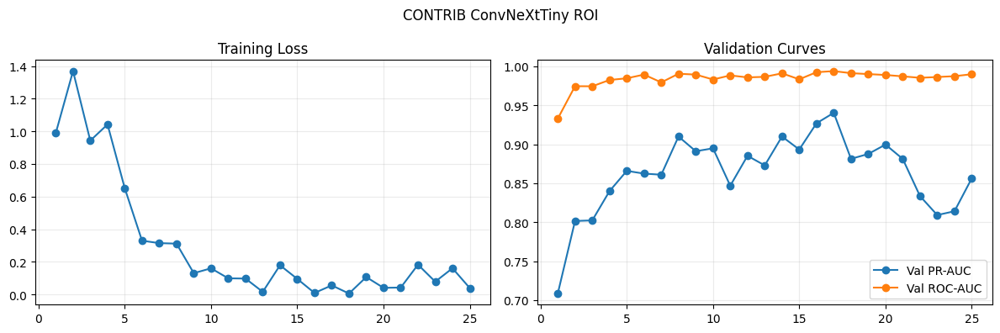

ROI ConvNeXt-Tiny image-only training complete.


In [ ]:
#  Train ROI ConvNeXt-Tiny image-only
convnext_roi_model = TimmConvNeXtBinary(model_name=CONTRIB_MODEL_NAME, pretrained=True, dropout=0.45)
convnext_roi_model, hist_convnext_roi = train_torch_binary_model(
    convnext_roi_model,
    train_loader_roi,
    val_loader_roi,
    'CONTRIB_ConvNeXtTiny_ROI',
    y_train_osteo,
)
plot_torch_history(hist_convnext_roi, 'CONTRIB ConvNeXtTiny ROI')
del convnext_roi_model
torch.cuda.empty_cache() if torch.cuda.is_available() else None
gc.collect()
print('ROI ConvNeXt-Tiny image-only training complete.')


### Evaluation of ROI Image-Only Models
Detailed evaluations of full-image and ROI image-only classifiers.


We display a comparison table compiling performance metrics across our full-image binary classifiers.


Evaluation of first 3 models (Custom CNN ,Custom ResNet , EfficientNet)

In [ ]:
# ── Final comparison table ───────────────────────────────────────────────────
results_df = pd.DataFrame(all_results).set_index('model')

# Reorder columns for readability
col_order = ['accuracy', 'balanced_acc', 'precision', 'recall',
             'specificity', 'f1', 'macro_f1', 'mcc', 'auc', 'pr_auc', 'npv']
col_order = [c for c in col_order if c in results_df.columns]
results_df = results_df[col_order]

print("\n" + "═"*70)
print("  MODEL COMPARISON — All Metrics")
print("═"*70)
display(results_df.style
        .format("{:.4f}")
        .highlight_max(color='lightgreen', axis=0)
        .highlight_min(color='# ffcccc', axis=0))

print("\nKey:")
print("  balanced_acc : ideal ≥ 0.70  |  mcc    : ideal ≥ 0.40")
print("  recall       : ideal ≥ 0.80  |  pr_auc : ideal ≥ 0.40")
print("  specificity  : ideal ≥ 0.70  |  auc    : ideal ≥ 0.75")

# Save to CSV
results_df.to_csv(os.path.join(OUTPUT_DIR, 'model_comparison.csv'))
print(f"\nResults saved to {OUTPUT_DIR}/model_comparison.csv")



══════════════════════════════════════════════════════════════════════
  MODEL COMPARISON — All Metrics
══════════════════════════════════════════════════════════════════════


,accuracy,balanced_acc,precision,recall,specificity,f1,macro_f1,mcc,auc,pr_auc,npv
model,,,,,,,,,,,
Custom CNN,0.8380,0.8047,0.2500,0.7667,0.8428,0.3770,0.6420,0.3756,0.8789,0.4884,0.9814
Custom ResNet,0.8678,0.7586,0.2714,0.6333,0.8838,0.3800,0.6530,0.3551,0.8689,0.5265,0.9724
EfficientNetB0,0.7655,0.8592,0.2101,0.9667,0.7517,0.3452,0.6012,0.3857,0.9678,0.7594,0.9970



Key:
  balanced_acc : ideal ≥ 0.70  |  mcc    : ideal ≥ 0.40
  recall       : ideal ≥ 0.80  |  pr_auc : ideal ≥ 0.40
  specificity  : ideal ≥ 0.70  |  auc    : ideal ≥ 0.75

Results saved to /media/hazem/6A47B344CD80864E/JANA/GP/outputs/model_comparison.csv


We plot the ROC curves for our full-image classifiers to evaluate and compare their diagnostic sensitivity and specificity.


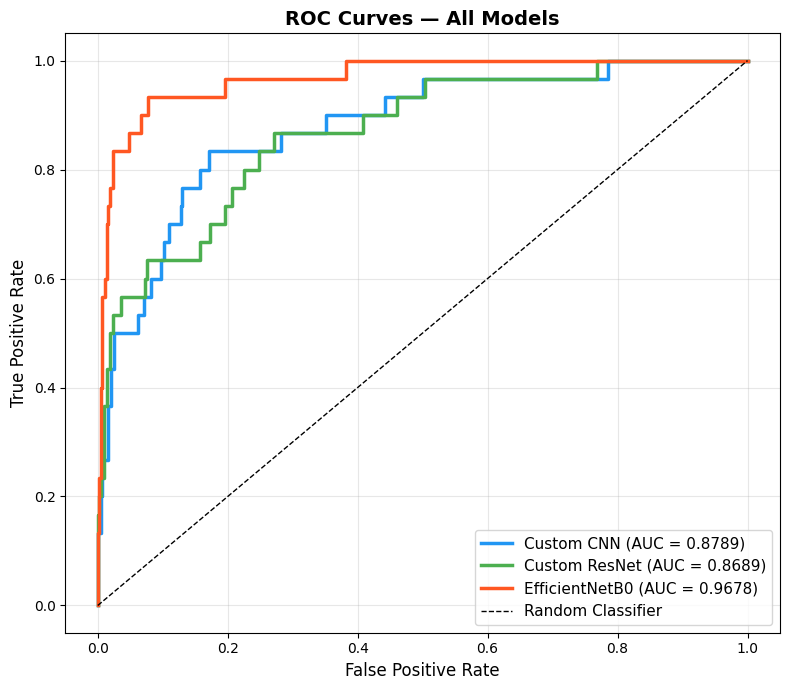

In [ ]:
fig, ax = plt.subplots(figsize=(8, 7))
colors = ['# 2196F3', '#4CAF50', '#FF5722']
probs  = [prob1, prob2, prob3]
names  = ['Custom CNN', 'Custom ResNet', 'EfficientNetB0']

for prob, name, color in zip(probs, names, colors):
    fpr, tpr, _ = roc_curve(y_test_osteo, prob)
    auc_val = roc_auc_score(y_test_osteo, prob)
    ax.plot(fpr, tpr, color=color, linewidth=2.5,
            label=f'{name} (AUC = {auc_val:.4f})')

ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random Classifier')
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('ROC Curves — All Models', fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=11)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'roc_curves_comparison.png'), dpi=150)
plt.show()


We select the highest-performing full-image model and generate Grad-CAM heatmaps to visualize focus areas.


 Best model: EfficientNetB0 (AUC=0.9678)
Best model saved.





 PART 5 (Evaluation & Comparison) complete.


In [ ]:
# select best model
best_name = results_df['auc'].idxmax()
print(f" Best model: {best_name} (AUC={results_df.loc[best_name,'auc']:.4f})")

best_model = {'Custom CNN': model1,
              'Custom ResNet': model2,
              'EfficientNetB0': model3}[best_name]
best_model.save(os.path.join(OUTPUT_DIR, 'best_final_model.keras'))
print("Best model saved.")

# GradCAM helper for explainability
def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    """Generate GradCAM heatmap for a given image."""
    target_layer = last_conv_layer_name
    if isinstance(target_layer, str):
        target_layer = model.get_layer(target_layer)
    grad_model = tf.keras.models.Model(
        model.inputs,
        [target_layer.output, model.output]
    )
    with tf.GradientTape() as tape:
        conv_out, preds = grad_model(img_array[np.newaxis], training=False)
        if pred_index is None:
            pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]
    grads = tape.gradient(class_channel, conv_out)
    pooled = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_out = conv_out[0]
    heatmap = conv_out @ pooled[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()

def overlay_gradcam(img, heatmap, alpha=0.4):
    heatmap_resized = cv2.resize(heatmap, (img.shape[1], img.shape[0]))
    heatmap_colored = cv2.applyColorMap(
        (heatmap_resized * 255).astype(np.uint8), cv2.COLORMAP_JET)
    heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB)
    overlay = (img * 255).astype(np.uint8)
    superimposed = cv2.addWeighted(overlay, 1 - alpha, heatmap_colored, alpha, 0)
    return superimposed

osteo_test_idxs = np.where(y_test_osteo == 1)[0][:3]
if len(osteo_test_idxs) == 0:
    print(" No osteosarcoma test samples found for GradCAM preview.")
else:
    try:
        last_conv = find_last_conv_layer_name(best_model)
    except Exception:
        def _iter_layers_recursive_local(model):
            yield model
            for layer in getattr(model, 'layers', []):
                yield layer
                if isinstance(layer, tf.keras.Model):
                    yield from _iter_layers_recursive_local(layer)

        conv_types = (
            tf.keras.layers.Conv2D,
            tf.keras.layers.DepthwiseConv2D,
            tf.keras.layers.SeparableConv2D,
        )
        last_conv = None
        for layer in reversed(list(_iter_layers_recursive_local(best_model))):
            if isinstance(layer, conv_types):
                last_conv = layer
                break
        if last_conv is None:
            raise ValueError(f"No convolutional layer found in model: {best_model.name}")

    fig, axes = plt.subplots(len(osteo_test_idxs), 2, figsize=(10, 4 * len(osteo_test_idxs)), squeeze=False)
    fig.suptitle(f'GradCAM — {best_name} on Osteosarcoma Cases', fontsize=13)

    for row_i, idx in enumerate(osteo_test_idxs):
        img = X_test[idx]
        try:
            heatmap = make_gradcam_heatmap(img, best_model, last_conv)
            overlay = overlay_gradcam(img, heatmap)
            axes[row_i, 0].imshow(img); axes[row_i, 0].set_title('Original'); axes[row_i, 0].axis('off')
            axes[row_i, 1].imshow(overlay); axes[row_i, 1].set_title('GradCAM'); axes[row_i, 1].axis('off')
        except Exception as e:
            axes[row_i, 0].imshow(img); axes[row_i, 0].axis('off')
            axes[row_i, 1].text(0.5, 0.5, f'GradCAM N/A\n{e}', ha='center')
            axes[row_i, 1].axis('off')

    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'gradcam_samples.png'), dpi=150)
    plt.show()

print(" PART 5 (Evaluation & Comparison) complete.")


We evaluate the primary ROI classifiers on test data, calculate confidence intervals via bootstrapping, and log false positives.


In [ ]:
# evaluate ROI models

def _load_model_if_missing(var_name, checkpoint_name, force_reload=False):
    if var_name in globals() and not force_reload:
        return globals()[var_name]
    ckpt = Path(best_checkpoint_path(checkpoint_name))
    if not ckpt.exists():
        raise FileNotFoundError(f"Missing checkpoint: {ckpt}. Run the ROI training cell first.")
    reload_note = "best saved checkpoint" if force_reload else "checkpoint"
    print(f"Loading {checkpoint_name} from {reload_note}: {ckpt}")
    model = run_tf_work(
        lambda: tf.keras.models.load_model(ckpt, **_best_model_load_kwargs()),
        description=f'load {checkpoint_name}',
        fallback_to_cpu=False,
    )
    globals()[var_name] = model
    return model

def bootstrap_metric_ci(y_true, y_prob, threshold, n_boot=1000, seed=42):
    rng = np.random.default_rng(seed)
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob).astype(float)
    rows = []
    n = len(y_true)
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        yt = y_true[idx]
        yp = y_prob[idx]
        pred = (yp >= threshold).astype(int)
        cm = confusion_matrix(yt, pred, labels=[0, 1])
        tn, fp, fn, tp = cm.ravel()
        rows.append({
            'recall': recall_score(yt, pred, zero_division=0),
            'precision': precision_score(yt, pred, zero_division=0),
            'specificity': tn / max(tn + fp, 1),
            'balanced_acc': balanced_accuracy_score(yt, pred),
            'mcc': matthews_corrcoef(yt, pred),
            'auc': roc_auc_score(yt, yp) if len(np.unique(yt)) == 2 else np.nan,
            'pr_auc': average_precision_score(yt, yp) if len(np.unique(yt)) == 2 else np.nan,
        })
    boot = pd.DataFrame(rows)
    return boot.quantile([0.025, 0.5, 0.975]).T.rename(columns={0.025: 'ci_low', 0.5: 'median', 0.975: 'ci_high'})

roi_model_cnn = _load_model_if_missing('roi_model_cnn', 'ROI_CustomCNN')
roi_model_res = _load_model_if_missing('roi_model_res', 'ROI_CustomResNet')
roi_model_eff = _load_model_if_missing('roi_model_eff', 'ROI_EfficientNetB0_P2', force_reload=True)
print("Using ROI EfficientNetB0 Phase 2 best checkpoint for evaluation.")

# ImageDataGenerator TTA uses SciPy transforms, which do not support float16.
# Keep the stored ROI arrays compact, but evaluate/TTA on float32 views/copies.
X_roi_val_eval = X_roi_val.astype(np.float32, copy=False)
X_roi_test_eval = X_roi_test.astype(np.float32, copy=False)

roi_results = []
roi_res_cnn, roi_prob_cnn = evaluate_model(roi_model_cnn, X_roi_test_eval, y_test_osteo, 'ROI-CustomCNN', X_roi_val_eval, y_val_osteo)
roi_results.append(roi_res_cnn)
roi_res_res, roi_prob_res = evaluate_model(roi_model_res, X_roi_test_eval, y_test_osteo, 'ROI-CustomResNet', X_roi_val_eval, y_val_osteo)
roi_results.append(roi_res_res)
roi_res_eff, roi_prob_eff = evaluate_model(roi_model_eff, X_roi_test_eval, y_test_osteo, 'ROI-EfficientNetB0', X_roi_val_eval, y_val_osteo)
roi_results.append(roi_res_eff)

roi_results_df = pd.DataFrame(roi_results).set_index('model')
metric_cols = ['accuracy','balanced_acc','precision','recall','specificity','f1','macro_f1','mcc','auc','pr_auc','npv','threshold']
metric_cols = [c for c in metric_cols if c in roi_results_df.columns]

full_results_df = pd.DataFrame(all_results).set_index('model') if 'all_results' in globals() and len(all_results) else pd.DataFrame()
if not full_results_df.empty:
    full_metric_cols = [c for c in metric_cols if c in full_results_df.columns]
    roi_comparison_df = pd.concat([full_results_df[full_metric_cols],
                                   roi_results_df[metric_cols]], axis=0)
else:
    roi_comparison_df = roi_results_df[metric_cols]

print("\nROI MODEL COMPARISON")
display(roi_comparison_df.style.format("{:.4f}").highlight_max(color='lightgreen', axis=0))
roi_comparison_df.to_csv(os.path.join(OUTPUT_DIR, 'roi_model_comparison.csv'))
print(f"Saved: {OUTPUT_DIR}/roi_model_comparison.csv")

ci_frames = []
for result, prob in zip(roi_results, [roi_prob_cnn, roi_prob_res, roi_prob_eff]):
    ci = bootstrap_metric_ci(y_test_osteo, prob, result['threshold'], n_boot=1000, seed=42)
    ci.insert(0, 'model', result['model'])
    ci.insert(1, 'metric', ci.index)
    ci_frames.append(ci.reset_index(drop=True))
roi_bootstrap_ci_df = pd.concat(ci_frames, ignore_index=True)
roi_bootstrap_ci_df.to_csv(os.path.join(OUTPUT_DIR, 'roi_bootstrap_confidence_intervals.csv'), index=False)
print(f"Saved: {OUTPUT_DIR}/roi_bootstrap_confidence_intervals.csv")
display(roi_bootstrap_ci_df)

def _plain_prob(model, X):
    return predict_model(model, X, batch_size=32, verbose=0, description=f'{model.name} FP review').ravel()

fp_rows = []
full_pairs = [
    ('Custom CNN', 'model1', 'CustomCNN', 'prob1', roi_prob_cnn, roi_res_cnn),
    ('Custom ResNet', 'model2', 'CustomResNet', 'prob2', roi_prob_res, roi_res_res),
    ('EfficientNetB0', 'model3', 'EfficientNet_finetuned', 'prob3', roi_prob_eff, roi_res_eff),
]
for full_name, full_var, ckpt_name, prob_var, roi_prob, roi_result in full_pairs:
    try:
        full_model = _load_model_if_missing(full_var, ckpt_name)
        full_prob = globals().get(prob_var)
        if full_prob is None or len(full_prob) != len(y_test_osteo):
            full_prob = _plain_prob(full_model, X_test)
        if not full_results_df.empty and full_name in full_results_df.index and 'threshold' in full_results_df.columns:
            full_thr = float(full_results_df.loc[full_name, 'threshold'])
        else:
            full_thr = 0.5
        roi_thr = roi_result['threshold']
        neg_mask = (y_test_osteo == 0)
        reduced = neg_mask & (full_prob >= full_thr) & (roi_prob < roi_thr)
        for test_pos in np.where(reduced)[0]:
            df_row = df_valid.iloc[test_idx[test_pos]]
            fp_rows.append({
                'model_pair': full_name,
                'test_pos': int(test_pos),
                'image_id': df_row['image_id'],
                'image_filename': df_row['image_filename'],
                'full_prob': float(full_prob[test_pos]),
                'full_threshold': float(full_thr),
                'roi_prob': float(roi_prob[test_pos]),
                'roi_threshold': float(roi_thr),
            })
    except Exception as exc:
        print(f"False-positive review skipped for {full_name}: {type(exc).__name__}: {exc}")

roi_false_positive_review_df = pd.DataFrame(fp_rows)
roi_false_positive_review_df.to_csv(os.path.join(OUTPUT_DIR, 'roi_false_positive_review.csv'), index=False)
print(f"Saved: {OUTPUT_DIR}/roi_false_positive_review.csv")
print(f"False positives reduced by ROI: {len(roi_false_positive_review_df)}")
display(roi_false_positive_review_df.head(20))


Loading ROI_EfficientNetB0_P2 from best saved checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_EfficientNetB0_P2.keras
Using ROI EfficientNetB0 Phase 2 best checkpoint for evaluation.
  Predicted probs — min:0.000  max:0.998  mean:0.263  median:0.070
  Threshold source : validation set (no test leakage)
  Optimal threshold: 0.8569

ROI-CustomCNN
              precision    recall  f1-score   support

           0     0.9788    0.9476    0.9630       439
           1     0.4773    0.7000    0.5676        30

    accuracy                         0.9318       469
   macro avg     0.7280    0.8238    0.7653       469
weighted avg     0.9467    0.9318    0.9377       469

Confusion matrix:
[[416  23]
 [  9  21]]
  Predicted probs — min:0.001  max:0.995  mean:0.273  median:0.068
  Threshold source : validation set (no test leakage)
  Optimal threshold: 0.6707

ROI-CustomResNet
              precision    recall  f1-score   support

           0     0.9920    0.8497    0.9153 

2026-05-28 02:04:25.069809: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2048', 232 bytes spill stores, 232 bytes spill loads

2026-05-28 02:04:25.208244: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2048_0', 404 bytes spill stores, 1284 bytes spill loads

2026-05-28 02:04:25.404631: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2048', 5380 bytes spill stores, 5380 bytes spill loads

2026-05-28 02:04:25.462323: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2048', 5524 bytes spill stores, 5564 bytes spill loads



  Predicted probs — min:0.000  max:1.000  mean:0.088  median:0.002
  Threshold source : validation set (no test leakage)
  Optimal threshold: 0.5977

ROI-EfficientNetB0
              precision    recall  f1-score   support

           0     0.9931    0.9886    0.9909       439
           1     0.8438    0.9000    0.8710        30

    accuracy                         0.9829       469
   macro avg     0.9184    0.9443    0.9309       469
weighted avg     0.9836    0.9829    0.9832       469

Confusion matrix:
[[434   5]
 [  3  27]]

ROI MODEL COMPARISON


,accuracy,balanced_acc,precision,recall,specificity,f1,macro_f1,mcc,auc,pr_auc,npv,threshold
model,,,,,,,,,,,,
ROI-CustomCNN,0.9318,0.8238,0.4773,0.7000,0.9476,0.5676,0.7653,0.5435,0.9359,0.5605,0.9788,0.8569
ROI-CustomResNet,0.8529,0.8748,0.2903,0.9000,0.8497,0.4390,0.6772,0.4601,0.9403,0.5552,0.9920,0.6707
ROI-EfficientNetB0,0.9829,0.9443,0.8438,0.9000,0.9886,0.8710,0.9309,0.8624,0.9943,0.9264,0.9931,0.5977


Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/roi_model_comparison.csv
Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/roi_bootstrap_confidence_intervals.csv


,model,metric,ci_low,median,ci_high
0,ROI-CustomCNN,recall,0.526253,0.700000,0.863636
1,ROI-CustomCNN,precision,0.324324,0.476190,0.620713
2,ROI-CustomCNN,specificity,0.924829,0.947429,0.967746
3,ROI-CustomCNN,balanced_acc,0.735510,0.822428,0.908355
4,ROI-CustomCNN,mcc,0.393700,0.544576,0.672862
5,ROI-CustomCNN,auc,0.900852,0.936409,0.965499
6,ROI-CustomCNN,pr_auc,0.376069,0.572875,0.730191
7,ROI-CustomResNet,recall,0.774194,0.906250,1.000000
8,ROI-CustomResNet,precision,0.200000,0.288889,0.386427
9,ROI-CustomResNet,specificity,0.814811,0.850729,0.881828


Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/roi_false_positive_review.csv
False positives reduced by ROI: 1184


,model_pair,test_pos,image_id,image_filename,full_prob,full_threshold,roi_prob,roi_threshold
0,Custom CNN,0,IMG000012,IMG000012.jpeg,0.500595,0.5,0.320519,0.856892
1,Custom CNN,2,IMG000032,IMG000032.jpeg,0.500590,0.5,0.698663,0.856892
2,Custom CNN,25,IMG000251,IMG000251.jpeg,0.500640,0.5,0.511743,0.856892
3,Custom CNN,26,IMG000266,IMG000266.jpeg,0.500543,0.5,0.370794,0.856892
4,Custom CNN,27,IMG000284,IMG000284.jpeg,0.500483,0.5,0.086636,0.856892
5,Custom CNN,28,IMG000288,IMG000288.jpeg,0.500253,0.5,0.755615,0.856892
6,Custom CNN,29,IMG000291,IMG000291.jpeg,0.500212,0.5,0.396522,0.856892
7,Custom CNN,30,IMG000302,IMG000302.jpeg,0.500403,0.5,0.022973,0.856892
8,Custom CNN,31,IMG000306,IMG000306.jpeg,0.500330,0.5,0.066564,0.856892
9,Custom CNN,32,IMG000309,IMG000309.jpeg,0.500520,0.5,0.097051,0.856892


We evaluate the Custom CNN and ResNet models trained with hard-negative mining (v3).


In [ ]:
# Evaluate ROI scratch v3 models and save comparisons

def load_best_scratch_v3_model(checkpoint_name):
    ckpt_path = best_checkpoint_path(checkpoint_name)
    if not os.path.exists(ckpt_path):
        raise FileNotFoundError(f'Missing checkpoint: {ckpt_path}. Run CELL 5A-V3-2 first.')
    return run_tf_work(
        lambda: tf.keras.models.load_model(ckpt_path, compile=False),
        description=f'load {checkpoint_name}',
        fallback_to_cpu=False,
    )

def bootstrap_metric_ci_v3(y_true, y_prob, threshold, n_boot=1000, seed=42):
    rng = np.random.default_rng(seed)
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob).astype(float)
    rows = []
    n = len(y_true)
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        yt = y_true[idx]
        yp = y_prob[idx]
        pred = (yp >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(yt, pred, labels=[0, 1]).ravel()
        rows.append({
            'recall': recall_score(yt, pred, zero_division=0),
            'precision': precision_score(yt, pred, zero_division=0),
            'specificity': tn / max(tn + fp, 1),
            'balanced_acc': balanced_accuracy_score(yt, pred),
            'mcc': matthews_corrcoef(yt, pred),
            'auc': roc_auc_score(yt, yp) if len(np.unique(yt)) == 2 else np.nan,
            'pr_auc': average_precision_score(yt, yp) if len(np.unique(yt)) == 2 else np.nan,
        })
    boot = pd.DataFrame(rows)
    return boot.quantile([0.025, 0.5, 0.975]).T.rename(
        columns={0.025: 'ci_low', 0.5: 'median', 0.975: 'ci_high'}
    )

def probability_diagnostics_v3(model_name, y_true, y_prob):
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob).astype(float)
    rows = []
    for label_value, label_name in [(0, 'negative'), (1, 'positive')]:
        vals = y_prob[y_true == label_value]
        if len(vals) == 0:
            continue
        rows.append({
            'model': model_name,
            'class': label_name,
            'n': int(len(vals)),
            'mean': float(np.mean(vals)),
            'std': float(np.std(vals)),
            'q05': float(np.quantile(vals, 0.05)),
            'q25': float(np.quantile(vals, 0.25)),
            'median': float(np.quantile(vals, 0.50)),
            'q75': float(np.quantile(vals, 0.75)),
            'q95': float(np.quantile(vals, 0.95)),
        })
    return rows

X_roi_val_v3_eval = X_roi_val.astype(np.float32, copy=False)
X_roi_test_v3_eval = X_roi_test.astype(np.float32, copy=False)

roi_scratch_v3_results = []
roi_scratch_v3_probs = {}

for checkpoint_name, display_name in [
    ('ROI_CustomCNN_v3', 'ROI-CustomCNN-v3'),
    ('ROI_CustomResNet_v3', 'ROI-CustomResNet-v3'),
]:
    print(f'\nLoading and evaluating {display_name} from best checkpoint...')
    model_v3 = load_best_scratch_v3_model(checkpoint_name)
    try:
        result_v3, prob_v3 = evaluate_model(
            model_v3,
            X_roi_test_v3_eval,
            y_test_osteo,
            display_name,
            X_roi_val_v3_eval,
            y_val_osteo,
        )
    finally:
        del model_v3
        tf.keras.backend.clear_session()
        gc.collect()
    roi_scratch_v3_results.append(result_v3)
    roi_scratch_v3_probs[display_name] = prob_v3

roi_scratch_v3_results_df = pd.DataFrame(roi_scratch_v3_results)

metric_cols_v3 = [
    'model', 'accuracy', 'balanced_acc', 'precision', 'recall',
    'specificity', 'f1', 'macro_f1', 'mcc', 'auc', 'pr_auc', 'npv', 'threshold'
]
metric_cols_v3 = [c for c in metric_cols_v3 if c in roi_scratch_v3_results_df.columns]

comparison_frames_v3 = []
base_roi_path_v3 = os.path.join(OUTPUT_DIR, 'roi_model_comparison.csv')
base_roi_keep_v3 = ['ROI-CustomCNN', 'ROI-CustomResNet', 'ROI-EfficientNetB0']
if os.path.exists(base_roi_path_v3):
    df_prev = pd.read_csv(base_roi_path_v3)
    if 'model' in df_prev.columns:
        df_prev = df_prev[df_prev['model'].isin(base_roi_keep_v3)].copy()
    keep_cols = [c for c in metric_cols_v3 if c in df_prev.columns]
    if keep_cols:
        comparison_frames_v3.append(df_prev[keep_cols])
else:
    print(f'Optional comparison file not found: {base_roi_path_v3}')

comparison_frames_v3.append(roi_scratch_v3_results_df[metric_cols_v3])
roi_scratch_v3_comparison_df = pd.concat(comparison_frames_v3, ignore_index=True, sort=False)

comparison_out_v3 = os.path.join(OUTPUT_DIR, 'roi_scratch_v3_model_comparison.csv')
roi_scratch_v3_comparison_df.to_csv(comparison_out_v3, index=False)
print(f'Saved: {comparison_out_v3}')

display_cols_v3 = [c for c in metric_cols_v3 if c != 'model']
display(roi_scratch_v3_comparison_df.set_index('model')[display_cols_v3].style.format('{:.4f}').highlight_max(color='lightgreen', axis=0))

ci_frames_v3 = []
diag_rows_v3 = []
for result_v3 in roi_scratch_v3_results:
    model_name = result_v3['model']
    prob = roi_scratch_v3_probs[model_name]
    ci = bootstrap_metric_ci_v3(y_test_osteo, prob, result_v3['threshold'], n_boot=1000, seed=42)
    ci.insert(0, 'model', model_name)
    ci.insert(1, 'metric', ci.index)
    ci_frames_v3.append(ci.reset_index(drop=True))
    diag_rows_v3.extend(probability_diagnostics_v3(model_name, y_test_osteo, prob))

roi_scratch_v3_ci_df = pd.concat(ci_frames_v3, ignore_index=True)
ci_out_v3 = os.path.join(OUTPUT_DIR, 'roi_scratch_v3_bootstrap_confidence_intervals.csv')
roi_scratch_v3_ci_df.to_csv(ci_out_v3, index=False)
print(f'Saved: {ci_out_v3}')

roi_scratch_v3_probability_diagnostics_df = pd.DataFrame(diag_rows_v3)
diag_out_v3 = os.path.join(OUTPUT_DIR, 'roi_scratch_v3_probability_diagnostics.csv')
roi_scratch_v3_probability_diagnostics_df.to_csv(diag_out_v3, index=False)
print(f'Saved: {diag_out_v3}')

display(roi_scratch_v3_ci_df)
display(roi_scratch_v3_probability_diagnostics_df)

for result_v3 in roi_scratch_v3_results:
    recall_ok = result_v3.get('recall', 0) >= 0.70
    print(f"{result_v3['model']} recall >= 0.70: {recall_ok} (recall={result_v3.get('recall', np.nan):.4f})")




Loading and evaluating ROI-CustomCNN-v3 from best checkpoint...
  Evaluation mode: no TTA (main reported metrics).
  Predicted probs — min:0.000  max:0.966  mean:0.275  median:0.224
  Threshold source : validation set (no test leakage)
  Optimal threshold: 0.4874

ROI-CustomCNN-v3
              precision    recall  f1-score   support

           0     0.9891    0.8269    0.9007       439
           1     0.2549    0.8667    0.3939        30

    accuracy                         0.8294       469
   macro avg     0.6220    0.8468    0.6473       469
weighted avg     0.9421    0.8294    0.8683       469

Confusion matrix:
[[363  76]
 [  4  26]]

Loading and evaluating ROI-CustomResNet-v3 from best checkpoint...
  Evaluation mode: no TTA (main reported metrics).
  Predicted probs — min:0.000  max:0.740  mean:0.218  median:0.158
  Threshold source : validation set (no test leakage)
  Optimal threshold: 0.4511

ROI-CustomResNet-v3
              precision    recall  f1-score   support

     

,accuracy,balanced_acc,precision,recall,specificity,f1,macro_f1,mcc,auc,pr_auc,npv,threshold
model,,,,,,,,,,,,
ROI-CustomCNN,0.9318,0.8238,0.4773,0.7000,0.9476,0.5676,0.7653,0.5435,0.9359,0.5605,0.9788,0.8569
ROI-CustomResNet,0.8529,0.8748,0.2903,0.9000,0.8497,0.4390,0.6772,0.4601,0.9403,0.5552,0.9920,0.6707
ROI-EfficientNetB0,0.9829,0.9443,0.8438,0.9000,0.9886,0.8710,0.9309,0.8624,0.9943,0.9264,0.9931,0.5977
ROI-CustomCNN-v2,0.7953,0.8285,0.2203,0.8667,0.7904,0.3514,0.6149,0.3705,0.9306,0.5271,0.9886,0.5743
ROI-CustomResNet-v2,0.7910,0.8263,0.2167,0.8667,0.7859,0.3467,0.6112,0.3659,0.9182,0.4928,0.9885,0.6162
ROI-CustomCNN-v3,0.8294,0.8468,0.2549,0.8667,0.8269,0.3939,0.6473,0.4114,0.9253,0.4762,0.9891,0.4874
ROI-CustomResNet-v3,0.8785,0.8730,0.3291,0.8667,0.8793,0.4771,0.7042,0.4877,0.9456,0.5805,0.9897,0.4511


Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/roi_scratch_v3_bootstrap_confidence_intervals.csv
Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/roi_scratch_v3_probability_diagnostics.csv


,model,metric,ci_low,median,ci_high
0,ROI-CustomCNN-v3,recall,0.733333,0.870968,0.970588
1,ROI-CustomCNN-v3,precision,0.171704,0.252810,0.339632
2,ROI-CustomCNN-v3,specificity,0.790517,0.827189,0.862077
3,ROI-CustomCNN-v3,balanced_acc,0.778282,0.849962,0.906192
4,ROI-CustomCNN-v3,mcc,0.307441,0.412177,0.501052
5,ROI-CustomCNN-v3,auc,0.893824,0.925694,0.955176
6,ROI-CustomCNN-v3,pr_auc,0.315858,0.493342,0.659810
7,ROI-CustomResNet-v3,recall,0.740700,0.871795,0.971448
8,ROI-CustomResNet-v3,precision,0.225795,0.328571,0.434225
9,ROI-CustomResNet-v3,specificity,0.848956,0.878995,0.909916


,model,class,n,mean,std,q05,q25,median,q75,q95
0,ROI-CustomCNN-v3,negative,439,0.250436,0.201115,0.006514,0.072067,0.201366,0.437835,0.572592
1,ROI-CustomCNN-v3,positive,30,0.636847,0.156143,0.460308,0.509944,0.570835,0.735001,0.924005
2,ROI-CustomResNet-v3,negative,439,0.195138,0.189542,0.000006,0.004856,0.131598,0.385131,0.501499
3,ROI-CustomResNet-v3,positive,30,0.549322,0.097250,0.420280,0.479376,0.531191,0.609420,0.734973


ROI-CustomCNN-v3 recall >= 0.70: True (recall=0.8667)
ROI-CustomResNet-v3 recall >= 0.70: True (recall=0.8667)


We evaluate the ResNet50V2, DenseNet121, and ResNet50-CBAM checkpoints and compare their performance metrics.


In [ ]:
# evaluate pretrained ROI models


# Local safe loader override for this evaluation cell.
# CBAM checkpoints from the earlier Lambda-based implementation may not be
# deserializable. For CBAM, rebuild the current serializable architecture first
# and load weights from the checkpoint archive. If...
# training cell so the checkpoint is saved with serializable layers.
def load_roi_pretrained_checkpoint(checkpoint_name):
    ckpt_path = best_checkpoint_path(checkpoint_name)
    if not os.path.exists(ckpt_path):
        raise FileNotFoundError(f'Missing checkpoint: {ckpt_path}. Run the matching training cell first.')

    def _load_standard():
        return tf.keras.models.load_model(ckpt_path, compile=False)

    def _load_cbam():
        if 'build_resnet50_cbam_transfer' not in globals():
            raise RuntimeError('Run CELL 5A-P-CBAM-1 before evaluating ResNet50-CBAM.')
        model, _ = build_resnet50_cbam_transfer(weights='imagenet')
        try:
            model.load_weights(ckpt_path)
            print('Loaded ResNet50-CBAM weights into rebuilt serializable architecture.')
            return model
        except Exception as weight_exc:
            print('Could not load CBAM weights directly into rebuilt architecture.')
            print(f'Weight-load error: {type(weight_exc).__name__}: {weight_exc}')
            print('Trying full-model load with safe_mode=False as a compatibility fallback...')
            try:
                return tf.keras.models.load_model(ckpt_path, compile=False, safe_mode=False)
            except Exception as full_exc:
                raise RuntimeError(
                    'This old CBAM checkpoint cannot be loaded because it was saved with Lambda layers. '
                    'Please rerun CELL 5A-P-CBAM-2 once to create a new serializable CBAM checkpoint, '
                    'then rerun CELL 5A-P-4.'
                ) from full_exc

    return run_tf_work(
        _load_cbam if 'CBAM' in checkpoint_name else _load_standard,
        description=f'load {checkpoint_name}',
        fallback_to_cpu=False,
    )

def bootstrap_metric_ci_pretrained(y_true, y_prob, threshold, n_boot=1000, seed=42):
    rng = np.random.default_rng(seed)
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob).astype(float)
    rows = []
    n = len(y_true)
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        yt = y_true[idx]
        yp = y_prob[idx]
        pred = (yp >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(yt, pred, labels=[0, 1]).ravel()
        rows.append({
            'recall': recall_score(yt, pred, zero_division=0),
            'precision': precision_score(yt, pred, zero_division=0),
            'specificity': tn / max(tn + fp, 1),
            'balanced_acc': balanced_accuracy_score(yt, pred),
            'mcc': matthews_corrcoef(yt, pred),
            'auc': roc_auc_score(yt, yp) if len(np.unique(yt)) == 2 else np.nan,
            'pr_auc': average_precision_score(yt, yp) if len(np.unique(yt)) == 2 else np.nan,
        })
    boot = pd.DataFrame(rows)
    return boot.quantile([0.025, 0.5, 0.975]).T.rename(
        columns={0.025: 'ci_low', 0.5: 'median', 0.975: 'ci_high'}
    )

def probability_diagnostics_pretrained(model_name, y_true, y_prob):
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob).astype(float)
    rows = []
    for label_value, label_name in [(0, 'negative'), (1, 'positive')]:
        vals = y_prob[y_true == label_value]
        if len(vals) == 0:
            continue
        rows.append({
            'model': model_name,
            'class': label_name,
            'n': int(len(vals)),
            'mean': float(np.mean(vals)),
            'std': float(np.std(vals)),
            'q05': float(np.quantile(vals, 0.05)),
            'q25': float(np.quantile(vals, 0.25)),
            'median': float(np.quantile(vals, 0.50)),
            'q75': float(np.quantile(vals, 0.75)),
            'q95': float(np.quantile(vals, 0.95)),
        })
    return rows

def _read_existing_comparison(path, keep_models=None):
    if not os.path.exists(path):
        return pd.DataFrame()
    df_cmp = pd.read_csv(path)
    if keep_models is not None and 'model' in df_cmp.columns:
        df_cmp = df_cmp[df_cmp['model'].isin(keep_models)].copy()
    return df_cmp

X_roi_val_pretrained_eval = X_roi_val.astype(np.float32, copy=False)
X_roi_test_pretrained_eval = X_roi_test.astype(np.float32, copy=False)

roi_pretrained_results = []
roi_pretrained_probs = {}

for checkpoint_name, display_name in [
    ('ROI_ResNet50V2_P2', 'ROI-ResNet50V2'),
    ('ROI_DenseNet121_P2', 'ROI-DenseNet121'),
    ('ROI_ResNet50_CBAM_P2', 'ROI-ResNet50-CBAM'),
]:
    print(f'\nLoading and evaluating {display_name} from best P2 checkpoint...')
    model_pretrained = load_roi_pretrained_checkpoint(checkpoint_name)
    result_pretrained, prob_pretrained = evaluate_model(
        model_pretrained,
        X_roi_test_pretrained_eval,
        y_test_osteo,
        display_name,
        X_roi_val_pretrained_eval,
        y_val_osteo,
    )
    roi_pretrained_results.append(result_pretrained)
    roi_pretrained_probs[display_name] = prob_pretrained
    del model_pretrained
    tf.keras.backend.clear_session()
    gc.collect()

roi_pretrained_results_df = pd.DataFrame(roi_pretrained_results)

old_roi_keep = ['ROI-CustomCNN', 'ROI-CustomResNet', 'ROI-EfficientNetB0']
comparison_sources = [
    _read_existing_comparison(os.path.join(OUTPUT_DIR, 'roi_model_comparison.csv'), old_roi_keep),
    roi_pretrained_results_df,
]
roi_pretrained_comparison_df = pd.concat(
    [df_cmp for df_cmp in comparison_sources if not df_cmp.empty],
    ignore_index=True,
)
if 'model' in roi_pretrained_comparison_df.columns:
    roi_pretrained_comparison_df = roi_pretrained_comparison_df.drop_duplicates('model', keep='last')

metric_cols = ['model','accuracy','balanced_acc','precision','recall','specificity','f1','macro_f1','mcc','auc','pr_auc','npv','threshold']
metric_cols = [c for c in metric_cols if c in roi_pretrained_comparison_df.columns]
roi_pretrained_comparison_df = roi_pretrained_comparison_df[metric_cols]

comparison_out = os.path.join(OUTPUT_DIR, 'roi_pretrained_resnet_densenet_comparison.csv')
roi_pretrained_comparison_df.to_csv(comparison_out, index=False)
print(f'Saved: {comparison_out}')
display_cols = [c for c in metric_cols if c != 'model']
display(roi_pretrained_comparison_df.set_index('model')[display_cols].style.format('{:.4f}').highlight_max(color='lightgreen', axis=0))

ci_frames = []
diag_rows = []
for result_pretrained in roi_pretrained_results:
    model_name = result_pretrained['model']
    prob = roi_pretrained_probs[model_name]
    ci = bootstrap_metric_ci_pretrained(y_test_osteo, prob, result_pretrained['threshold'], n_boot=1000, seed=42)
    ci.insert(0, 'model', model_name)
    ci.insert(1, 'metric', ci.index)
    ci_frames.append(ci.reset_index(drop=True))
    diag_rows.extend(probability_diagnostics_pretrained(model_name, y_test_osteo, prob))

roi_pretrained_ci_df = pd.concat(ci_frames, ignore_index=True)
ci_out = os.path.join(OUTPUT_DIR, 'roi_pretrained_resnet_densenet_bootstrap_ci.csv')
roi_pretrained_ci_df.to_csv(ci_out, index=False)
print(f'Saved: {ci_out}')

roi_pretrained_probability_diagnostics_df = pd.DataFrame(diag_rows)
diag_out = os.path.join(OUTPUT_DIR, 'roi_pretrained_resnet_densenet_probability_diagnostics.csv')
roi_pretrained_probability_diagnostics_df.to_csv(diag_out, index=False)
print(f'Saved: {diag_out}')

display(roi_pretrained_ci_df)
display(roi_pretrained_probability_diagnostics_df)






Loading and evaluating ROI-ResNet50V2 from best P2 checkpoint...
  Evaluation mode: no TTA (main reported metrics).
  Predicted probs — min:0.000  max:1.000  mean:0.070  median:0.004
  Threshold source : validation set (no test leakage)
  Optimal threshold: 0.0500

ROI-ResNet50V2
              precision    recall  f1-score   support

           0     0.9903    0.9294    0.9589       439
           1     0.4561    0.8667    0.5977        30

    accuracy                         0.9254       469
   macro avg     0.7232    0.8980    0.7783       469
weighted avg     0.9561    0.9254    0.9358       469

Confusion matrix:
[[408  31]
 [  4  26]]

Loading and evaluating ROI-DenseNet121 from best P2 checkpoint...
  Evaluation mode: no TTA (main reported metrics).
  Predicted probs — min:0.000  max:1.000  mean:0.086  median:0.002
  Threshold source : validation set (no test leakage)
  Optimal threshold: 0.1912

ROI-DenseNet121
              precision    recall  f1-score   support

           

,accuracy,balanced_acc,precision,recall,specificity,f1,macro_f1,mcc,auc,pr_auc,npv,threshold
model,,,,,,,,,,,,
ROI-CustomCNN,0.9318,0.8238,0.4773,0.7000,0.9476,0.5676,0.7653,0.5435,0.9359,0.5605,0.9788,0.8569
ROI-CustomResNet,0.8529,0.8748,0.2903,0.9000,0.8497,0.4390,0.6772,0.4601,0.9403,0.5552,0.9920,0.6707
ROI-EfficientNetB0,0.9829,0.9443,0.8438,0.9000,0.9886,0.8710,0.9309,0.8624,0.9943,0.9264,0.9931,0.5977
ROI-ResNet50V2,0.9254,0.8980,0.4561,0.8667,0.9294,0.5977,0.7783,0.5961,0.9702,0.8122,0.9903,0.0500
ROI-DenseNet121,0.9446,0.9393,0.5385,0.9333,0.9453,0.6829,0.8263,0.6848,0.9828,0.8288,0.9952,0.1912
ROI-ResNet50-CBAM,0.9424,0.9382,0.5283,0.9333,0.9431,0.6747,0.8216,0.6773,0.9447,0.8695,0.9952,0.0792


Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/roi_pretrained_resnet_densenet_bootstrap_ci.csv
Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/roi_pretrained_resnet_densenet_probability_diagnostics.csv


,model,metric,ci_low,median,ci_high
0,ROI-ResNet50V2,recall,0.727194,0.864865,0.969697
1,ROI-ResNet50V2,precision,0.319107,0.454545,0.588273
2,ROI-ResNet50V2,specificity,0.904323,0.930023,0.952286
3,ROI-ResNet50V2,balanced_acc,0.825397,0.898095,0.951487
4,ROI-ResNet50V2,mcc,0.469376,0.592928,0.706677
5,ROI-ResNet50V2,auc,0.942443,0.970613,0.990092
6,ROI-ResNet50V2,pr_auc,0.684723,0.814963,0.913972
7,ROI-DenseNet121,recall,0.833333,0.937500,1.000000
8,ROI-DenseNet121,precision,0.399884,0.535714,0.672422
9,ROI-DenseNet121,specificity,0.923256,0.945701,0.965517


,model,class,n,mean,std,q05,q25,median,q75,q95
0,ROI-ResNet50V2,negative,439,0.027800,0.107014,0.000128,0.001166,0.003221,0.009070,0.075270
1,ROI-ResNet50V2,positive,30,0.692061,0.359346,0.015211,0.474623,0.913537,0.997022,0.999966
2,ROI-DenseNet121,negative,439,0.041099,0.143213,0.000056,0.000419,0.001850,0.010060,0.247467
3,ROI-DenseNet121,positive,30,0.742320,0.314592,0.163691,0.462237,0.919537,0.975286,0.996574
4,ROI-ResNet50-CBAM,negative,439,0.031201,0.101549,0.000787,0.005399,0.009944,0.016693,0.120036
5,ROI-ResNet50-CBAM,positive,30,0.779554,0.299767,0.102031,0.714913,0.950423,0.996394,0.999367


## Subsection 2.2 - Multimodal Fusion Models
Multi-input models combining image features and clinical tabular metadata.


We load tabular configuration parameters and verify consistency of the tabular data shapes.


In [ ]:
# ============================================================
# MULTI-MODAL FUSION CONFIG
# X_tab_train, X_tab_val, X_tab_test already exist — do NOT recreate
# ============================================================
TABULAR_DIM = int(X_tab_train.shape[1])
if X_tab_val.shape[1] != TABULAR_DIM or X_tab_test.shape[1] != TABULAR_DIM:
    raise ValueError("Tabular feature dimension mismatch across train/val/test splits.")
print(f'TABULAR_DIM           : {TABULAR_DIM}')
print(f'X_tab_train shape     : {X_tab_train.shape}')
print(f'X_tab_val   shape     : {X_tab_val.shape}')
print(f'X_tab_test  shape     : {X_tab_test.shape}')


TABULAR_DIM           : 8
X_tab_train shape     : (2659, 8)
X_tab_val   shape     : (618, 8)
X_tab_test  shape     : (469, 8)


We define a batch generator that serves balanced classes with both image arrays and tabular features.


In [ ]:
def squeeze_excite(x, ratio=8):
    """Lightweight channel attention (SE block)."""
    filters = x.shape[-1]
    se = layers.GlobalAveragePooling2D()(x)
    se = layers.Dense(max(filters // ratio, 4), activation='relu')(se)
    se = layers.Dense(filters, activation='sigmoid')(se)
    se = layers.Reshape((1, 1, filters))(se)
    return layers.Multiply()([x, se])

def build_custom_cnn(input_shape=(224, 224, 3)):
    """
    Redesigned Custom CNN:
    - 4 conv blocks (not 5) to reduce over-parameterisation
    - SE channel attention after each block
    - SpatialDropout2D instead of Dropout in conv blocks (more effective)
    - BatchNorm before activation (pre-activation style)
    - Smaller dense head to reduce over-fitting
    """
    inputs = layers.Input(shape=input_shape, name='img_input')
    x = inputs

    # Block 1 — 32 filters
    x = layers.Conv2D(32, (3,3), padding='same',
                       kernel_regularizer=regularizers.l2(1e-4),
                       kernel_initializer='he_normal')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(32, (3,3), padding='same',
                       kernel_regularizer=regularizers.l2(1e-4),
                       kernel_initializer='he_normal')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = squeeze_excite(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.SpatialDropout2D(0.1)(x)

    # Block 2 — 64 filters
    x = layers.Conv2D(64, (3,3), padding='same',
                       kernel_regularizer=regularizers.l2(1e-4),
                       kernel_initializer='he_normal')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(64, (3,3), padding='same',
                       kernel_regularizer=regularizers.l2(1e-4),
                       kernel_initializer='he_normal')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = squeeze_excite(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.SpatialDropout2D(0.15)(x)

    # Block 3 — 128 filters
    x = layers.Conv2D(128, (3,3), padding='same',
                        kernel_regularizer=regularizers.l2(1e-4),
                        kernel_initializer='he_normal')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(128, (3,3), padding='same',
                        kernel_regularizer=regularizers.l2(1e-4),
                        kernel_initializer='he_normal')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = squeeze_excite(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.SpatialDropout2D(0.2)(x)

    # Block 4 — 256 filters
    x = layers.Conv2D(256, (3,3), padding='same',
                        kernel_regularizer=regularizers.l2(1e-4),
                        kernel_initializer='he_normal')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = squeeze_excite(x)
    x = layers.GlobalAveragePooling2D()(x)

    # Classifier head — lighter to reduce overfitting
    x = layers.Dense(128, activation='relu',
                      kernel_regularizer=regularizers.l2(1e-4),
                      kernel_initializer='he_normal')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(1, activation='sigmoid', name='output')(x)

    model = models.Model(inputs, outputs, name='CustomCNN')
    return model

def _metrics():
    return [
        tf.keras.metrics.BinaryAccuracy(name='accuracy'),
        tf.keras.metrics.AUC(name='auc'),
        tf.keras.metrics.AUC(name='pr_auc', curve='PR'), # Precision-Recall AUC
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall')
    ]

def compile_scratch_model(model, lr=1e-4):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss='binary_crossentropy', # Assuming binary classification for sigmoid output
        metrics=_metrics()
    )
    return model

model1 = build_custom_cnn()
model1 = compile_scratch_model(model1, lr=1e-4)
model1.summary()


Model: "CustomCNN"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ img_input           │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 224, 224,  │        896 │ img_input[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 224, 224,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 224, 224,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 224, 224,  │      9,248 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 224, 224,  │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 224, 224,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 32)        │          0 │ activation_1[0][… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 4)         │        132 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32)        │        160 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 1, 1, 32)  │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 224, 224,  │          0 │ activation_1[0][… │
│                     │ 32)               │            │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 112, 112,  │          0 │ multiply[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout2d   │ (None, 112, 112,  │          0 │ max_pooling2d[0]… │
│ (SpatialDropout2D)  │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 112, 112,  │     18,496 │ spatial_dropout2… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 112, 112,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 112, 112,  │     36,928 │ activation_2[0][

 Total params: 640,829 (2.44 MB)

 Trainable params: 639,165 (2.44 MB)

 Non-trainable params: 1,664 (6.50 KB)

We create evaluation routines customized for dual-input (image + tabular) multimodal architectures.


In [ ]:
def evaluate_multimodal_model(model, X_img_test, X_tab_test_data, y_test,
                             model_name, X_img_val=None,
                             X_tab_val_data=None, y_val=None):
    """evaluate_model() adapted for dual-input [image, tabular] models."""
    if globals().get('USE_TTA', False):
        print("  Evaluation mode: TTA enabled (report separately from main metrics).")
        tta_preds = [predict_model(
            model, [X_img_test, X_tab_test_data],
            batch_size=32, verbose=0,
            description=f'{model_name} test prediction').ravel()]
        for _ in range(globals().get('N_TTA', 8) - 1):
            X_tta = np.clip(
                np.array([aug_gen.random_transform(x) for x in X_img_test]),
                0.0, 1.0).astype(np.float32)
            tta_preds.append(predict_model(
                model, [X_tta, X_tab_test_data],
                batch_size=32, verbose=0,
                description=f'{model_name} TTA prediction').ravel())
        y_prob = np.mean(tta_preds, axis=0)
    else:
        print("  Evaluation mode: no TTA (main reported metrics).")
        y_prob = predict_model(
            model, [X_img_test, X_tab_test_data],
            batch_size=32, verbose=0,
            description=f'{model_name} test prediction').ravel()


    print(f"  Predicted probs — min:{y_prob.min():.3f}  max:{y_prob.max():.3f}"
          f"  mean:{y_prob.mean():.3f}  median:{np.median(y_prob):.3f}")
    if y_prob.max() - y_prob.min() < 0.05:
        print("    WARNING: probability range < 0.05 — model may not have learned.")

    # Threshold via Youden J on validation set
    if X_img_val is not None and y_val is not None:
        y_prob_val = predict_model(
            model, [X_img_val, X_tab_val_data],
            batch_size=32, verbose=0,
            description=f'{model_name} validation prediction').ravel()
        fpr_v, tpr_v, thr_v = roc_curve(y_val, y_prob_val)
        j_v      = tpr_v - fpr_v
        best_thr = float(np.clip(thr_v[np.argmax(j_v)], 0.05, 0.95))
        thr_src  = "validation set (no test leakage)"
    else:
        fpr_t, tpr_t, thr_t = roc_curve(y_test, y_prob)
        j_t      = tpr_t - fpr_t
        best_thr = float(np.clip(thr_t[np.argmax(j_t)], 0.05, 0.95))
        thr_src  = "test set (optimistic — debug only)"

    print(f"  Threshold source : {thr_src}")
    print(f"  Optimal threshold: {best_thr:.4f}")
    y_pred = (y_prob >= best_thr).astype(int)

    cm               = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp   = cm.ravel()
    sensitivity      = tp / max(tp + fn, 1)
    specificity      = tn / max(tn + fp, 1)
    ppv              = tp / max(tp + fp, 1)
    npv_val          = tn / max(tn + fn, 1)

    results = {
        'model'        : model_name,
        'accuracy'     : accuracy_score(y_test, y_pred),
        'balanced_acc' : balanced_accuracy_score(y_test, y_pred),
        'precision'    : ppv,
        'recall'       : sensitivity,
        'specificity'  : specificity,
        'npv'          : npv_val,
        'f1'           : f1_score(y_test, y_pred, zero_division=0),
        'macro_f1'     : f1_score(y_test, y_pred, average="macro", zero_division=0),
        'mcc'          : matthews_corrcoef(y_test, y_pred),
        'auc'          : roc_auc_score(y_test, y_prob),
        'pr_auc'       : average_precision_score(y_test, y_prob),
    }

    sep = "─" * 42
    print(f"{chr(9552)*42}")
    print(f"  {model_name}")
    print(sep)
    for k, v in results.items():
        if k == "model": continue
        print(f"  {k:<18} {v:>8.4f}")
    print(sep)
    print(f"  TP={tp:<5} FP={fp:<5} FN={fn:<5} TN={tn}")

    # Confusion matrix + ROC plot
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    fig.suptitle(f"{model_name} — Evaluation", fontsize=13, fontweight="bold")
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
                xticklabels=["Non-Osteo","Osteo"],
                yticklabels=["Non-Osteo","Osteo"])
    axes[0].set_title("Confusion Matrix")
    fpr_p, tpr_p, _ = roc_curve(y_test, y_prob)
    axes[1].plot(fpr_p, tpr_p, lw=2, label=f"ROC (AUC={results['auc']:.3f})")
    axes[1].plot([0,1],[0,1],"--",color="gray",lw=1)
    axes[1].set_xlabel("False Positive Rate"); axes[1].set_ylabel("True Positive Rate")
    axes[1].set_title("ROC Curve"); axes[1].legend(); axes[1].grid(alpha=0.3)
    plt.tight_layout()
    safe_model_name = str(model_name).replace(" ", "_").replace("/", "_")
    plt.savefig(os.path.join(OUTPUT_DIR, f"eval_mm_{safe_model_name}.png"), dpi=150)
    plt.show()
    return results, y_prob


We define Grad-CAM visualization helpers for multimodal architectures.


In [ ]:
def gradcam_multimodal(model, img_array, tab_array, layer_name, model_name):
    """GradCAM for dual-input models. img_array: (1,224,224,3), tab_array: (1,8)."""
    grad_model = tf.keras.Model(
        inputs=model.inputs,
        outputs=[model.get_layer(layer_name).output, model.output]
    )
    img_t = tf.cast(img_array, tf.float32)
    tab_t = tf.cast(tab_array, tf.float32)
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model([img_t, tab_t], training=False)
        loss = predictions[:, 0]
    grads       = tape.gradient(loss, conv_outputs)
    pooled      = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_out    = conv_outputs[0]
    heatmap     = conv_out @ pooled[..., tf.newaxis]
    heatmap     = tf.squeeze(heatmap)
    heatmap     = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    heatmap_np  = heatmap.numpy()

    h_resized  = cv2.resize(heatmap_np, (224, 224))
    h_color    = cv2.applyColorMap(np.uint8(255 * h_resized), cv2.COLORMAP_JET)
    orig       = np.uint8(255 * img_array[0])
    overlay    = cv2.addWeighted(orig, 0.6, h_color, 0.4, 0)

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    fig.suptitle(f"GradCAM — {model_name}", fontsize=13, fontweight="bold")
    axes[0].imshow(img_array[0], cmap="bone"); axes[0].set_title("Original X-Ray"); axes[0].axis("off")
    axes[1].imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
    axes[1].set_title("Attention Heatmap"); axes[1].axis("off")
    plt.tight_layout()
    save_path = os.path.join(OUTPUT_DIR, f"gradcam_mm_{model_name}.png")
    plt.savefig(save_path, dpi=150); plt.show()
    return heatmap_np, save_path


We build a prediction helper function for patient diagnostics with multimodal data.


In [ ]:
def predict_multimodal_patient(model, image_path, tab_row,
                               target_size=(224, 224)):
    """
    End-to-end inference for one patient.
    tab_row: np.array shape (8,) — already-scaled tabular features (X_tab_test[i]).
    """
    img = cv2.imread(image_path)
    if img is None:
        raise FileNotFoundError(f"Cannot read image: {image_path}")
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, target_size).astype(np.float32) / 255.0
    img_tensor = np.expand_dims(img, axis=0)              # (1,224,224,3)
    tab_tensor = np.expand_dims(tab_row, axis=0).astype(np.float32)  # (1,8)

    prob  = float(predict_model(
        model, [img_tensor, tab_tensor], verbose=0,
        description='multimodal patient inference')[0][0])
    label = 1 if prob >= 0.5 else 0
    conf  = prob if label == 1 else 1.0 - prob

    result = {
        "probability"    : round(prob, 4),
        "predicted_label": label,
        "label_text"     : "Osteosarcoma" if label == 1 else "Non-Osteosarcoma",
        "confidence_pct" : round(conf * 100, 2),
    }
    print(f"Prediction   : {result[chr(39)+'label_text'+chr(39)]}")
    print(f"Probability  : {result[chr(39)+'probability'+chr(39)]:.4f}")
    print(f"Confidence   : {result[chr(39)+'confidence_pct'+chr(39)]}%")
    return result


We implement the Focal Loss function to improve model handling of highly imbalanced datasets.


In [ ]:

#  FOCAL LOSS
# Binary cross-entropy treats every error equally — with 11.4:1 imbalance
# the model learns to predict negative for everything.
# Focal Loss down-weights easy negatives and forces the model to focus
# on hard-to-classify positive (osteosarcoma) samples.
# gamma=2.0 is the standard clinical setting; alpha=0.75 upweights positives.


def focal_loss(gamma=2.0, alpha=0.75):
    """
    Binary Focal Loss for class-imbalanced medical datasets.
    alpha: weight for positive class (osteosarcoma). Set > 0.5 to upweight minority.
    gamma: focusing parameter. gamma=0 == binary cross-entropy. gamma=2 is standard.
    """
    def loss_fn(y_true, y_pred):
        y_pred  = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
        bce     = -y_true * tf.math.log(y_pred) - (1 - y_true) * tf.math.log(1 - y_pred)
        p_t     = tf.where(tf.equal(y_true, 1), y_pred, 1 - y_pred)
        alpha_t = tf.where(tf.equal(y_true, 1),
                           tf.ones_like(y_true) * alpha,
                           tf.ones_like(y_true) * (1 - alpha))
        fl      = alpha_t * tf.pow(1.0 - p_t, gamma) * bce
        return tf.reduce_mean(fl)
    loss_fn.__name__ = f"focal_loss_g{gamma}_a{alpha}"
    return loss_fn

FOCAL = focal_loss(gamma=2.0, alpha=0.75)
print("Focal loss defined. gamma=2.0, alpha=0.75 (upweights osteosarcoma positives)")


Focal loss defined. gamma=2.0, alpha=0.75 (upweights osteosarcoma positives)


We implement the multimodal model compilation utility, binding AdamW optimizer and Focal Loss.


In [ ]:

# COMPILE WITH FOCAL LOSS

def compile_mm_model(model, lr=5e-5):
    """
    Compile multimodal model with Focal Loss + AdamW + gradient clipping.
    lr lowered to 5e-5 to reduce training instability on imbalanced data.
    clipnorm=0.5 (tighter than 1.0) to prevent exploding gradients at fusion.
    """
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr, clipnorm=0.5),
        loss=FOCAL,
        metrics=_metrics()
    )
    return model

print("compile_mm_model defined with Focal Loss.")


compile_mm_model defined with Focal Loss.


We build a dual-input architecture combining our Custom CNN with a tabular feature dense network.


In [ ]:

# REDESIGNED MULTIMODAL CNN
# Key changes vs original:
# - Image branch: increased SpatialDropout rates (0.2/0.3/0.4) to fight memorisation
# - Image branch: added l2=3e-4 (3x stronger regularization)
# - Tabular branch: bottlenecked to max 8 neurons...
# (image branch produces 64 dims; tab produces 8 → image always leads)
# - Fusion Dense reduced from 64 to 32...
# - Fusion Dropout raised to 0.5

def build_multimodal_cnn_v2(input_shape=(224,224,3), tabular_dim=TABULAR_DIM):
    """Anti-overfitting MultiModal CNN v2."""
    L2 = 3e-4

    img_input = layers.Input(shape=input_shape, name='image_input')
    x = img_input

    # Block 1 — 32 filters
    x = layers.Conv2D(32,(3,3),padding='same',kernel_regularizer=regularizers.l2(L2),kernel_initializer='he_normal')(x)
    x = layers.BatchNormalization()(x); x = layers.Activation('relu')(x)
    x = layers.Conv2D(32,(3,3),padding='same',kernel_regularizer=regularizers.l2(L2),kernel_initializer='he_normal')(x)
    x = layers.BatchNormalization()(x); x = layers.Activation('relu')(x)
    x = squeeze_excite(x); x = layers.MaxPooling2D(2)(x)
    x = layers.SpatialDropout2D(0.2)(x)   # was 0.1

    # Block 2 — 64 filters
    x = layers.Conv2D(64,(3,3),padding='same',kernel_regularizer=regularizers.l2(L2),kernel_initializer='he_normal')(x)
    x = layers.BatchNormalization()(x); x = layers.Activation('relu')(x)
    x = layers.Conv2D(64,(3,3),padding='same',kernel_regularizer=regularizers.l2(L2),kernel_initializer='he_normal')(x)
    x = layers.BatchNormalization()(x); x = layers.Activation('relu')(x)
    x = squeeze_excite(x); x = layers.MaxPooling2D(2)(x)
    x = layers.SpatialDropout2D(0.3)(x)   # was 0.15

    # Block 3 — 128 filters
    x = layers.Conv2D(128,(3,3),padding='same',kernel_regularizer=regularizers.l2(L2),kernel_initializer='he_normal')(x)
    x = layers.BatchNormalization()(x); x = layers.Activation('relu')(x)
    x = squeeze_excite(x); x = layers.MaxPooling2D(2)(x)
    x = layers.SpatialDropout2D(0.4)(x)   # was 0.20

    # Block 4 — 128 filters (removed block of...
    x = layers.Conv2D(128,(3,3),padding='same',kernel_regularizer=regularizers.l2(L2),kernel_initializer='he_normal')(x)
    x = layers.BatchNormalization()(x); x = layers.Activation('relu')(x)
    x = squeeze_excite(x)

    x = layers.GlobalAveragePooling2D()(x)
    img_features = layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(L2))(x)  # was 128
    img_features = layers.BatchNormalization()(img_features)
    img_features = layers.Dropout(0.5)(img_features)   # was 0.4

    # Tabular branch — bottlenecked to 8 neurons max
    # Prevents tabular from dominating the 64-dim image features
    tab_input = layers.Input(shape=(tabular_dim,), name='tabular_input')
    t = layers.Dense(8, activation='relu', kernel_regularizer=regularizers.l2(L2))(tab_input)  # was 16
    t = layers.Dropout(0.3)(t)
    tab_features = layers.BatchNormalization()(t)

    # Fusion — 64+8 = 72 dims concatenated
    fused = layers.Concatenate()([img_features, tab_features])
    x = layers.Dense(32, activation='relu', kernel_regularizer=regularizers.l2(L2))(fused)   # was 64
    x = layers.Dropout(0.5)(x)   # was 0.3
    output = layers.Dense(1, activation='sigmoid', dtype='float32', name='output')(x)

    return models.Model(inputs=[img_input, tab_input], outputs=output, name='MultiModalCNN_v2')

mm_model1_v2 = build_multimodal_cnn_v2()
mm_model1_v2 = compile_mm_model(mm_model1_v2, lr=5e-5)
mm_model1_v2.summary()


Model: "MultiModalCNN_v2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_input         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_47 (Conv2D)  │ (None, 224, 224,  │        896 │ image_input[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 224, 224,  │        128 │ conv2d_47[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_48       │ (None, 224, 224,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_48 (Conv2D)  │ (None, 224, 224,  │      9,248 │ activation_48[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 224, 224,  │        128 │ conv2d_48[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_49       │ (None, 224, 224,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 32)        │          0 │ activation_49[0]… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_54 (Dense)    │ (None, 4)         │        132 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_55 (Dense)    │ (None, 32)        │        160 │ dense_54[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_22          │ (None, 1, 1, 32)  │          0 │ dense_55[0][0]    │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_22         │ (None, 224, 224,  │          0 │ activation_49[0]… │
│ (Multiply)          │ 32)               │            │ reshape_22[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_11    │ (None, 112, 112,  │          0 │ multiply_22[0][0] │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout2d_… │ (None, 112, 112,  │          0 │ max_pooling2d_11… │
│ (SpatialDropout2D)  │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_49 (Conv2D)  │ (None, 112, 112,  │     18,496 │ spatial_dropout2… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        256 │ conv2d_49[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_50       │ (None, 112, 112,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 309,653 (1.18 MB)

 Trainable params: 308,613 (1.18 MB)

 Non-trainable params: 1,040 (4.06 KB)

We build a dual-input architecture combining our Custom ResNet with a tabular feature dense network.


In [ ]:

# REDESIGNED MULTIMODAL RESNET
# Key changes:
# - Fewer residual stages (2 stages not 3)...
# - Tabular bottlenecked to 8 neurons
# - Higher dropout on image projection (0.5)
# - Fusion dropout 0.5
# ============================================================
def build_multimodal_resnet_v2(input_shape=(224,224,3), tabular_dim=TABULAR_DIM):
    """Anti-overfitting MultiModal ResNet v2."""
    L2 = 3e-4

    img_input = layers.Input(shape=input_shape, name='image_input')

    # Stem
    x = layers.Conv2D(64,(7,7),strides=2,padding='same',
                      kernel_regularizer=regularizers.l2(L2),
                      kernel_initializer='he_normal',use_bias=False)(img_input)
    x = layers.BatchNormalization()(x); x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D((3,3),strides=2,padding='same')(x)

    # Stage 1 — 64 filters x2 blocks
    x = residual_block(x, 64, dropout_rate=0.20)
    x = residual_block(x, 64, dropout_rate=0.20)

    # Stage 2 — 128 filters x2 blocks (strided)
    x = residual_block(x, 128, stride=2, dropout_rate=0.30)
    x = residual_block(x, 128, dropout_rate=0.30)

    x = layers.GlobalAveragePooling2D()(x)
    img_features = layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(L2))(x)
    img_features = layers.BatchNormalization()(img_features)
    img_features = layers.Dropout(0.5)(img_features)

    # Tabular branch — bottlenecked
    tab_input = layers.Input(shape=(tabular_dim,), name='tabular_input')
    t = layers.Dense(8, activation='relu', kernel_regularizer=regularizers.l2(L2))(tab_input)
    t = layers.Dropout(0.3)(t)
    tab_features = layers.BatchNormalization()(t)

    # Fusion
    fused = layers.Concatenate()([img_features, tab_features])
    x = layers.Dense(32, activation='relu', kernel_regularizer=regularizers.l2(L2))(fused)
    x = layers.Dropout(0.5)(x)
    output = layers.Dense(1, activation='sigmoid', dtype='float32', name='output')(x)

    return models.Model(inputs=[img_input, tab_input], outputs=output, name='MultiModalResNet_v2')

mm_model2_v2 = build_multimodal_resnet_v2()
mm_model2_v2 = compile_mm_model(mm_model2_v2, lr=5e-5)
mm_model2_v2.summary()


Model: "MultiModalResNet_v2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_input         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_53 (Conv2D)  │ (None, 112, 112,  │      9,408 │ image_input[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        256 │ conv2d_53[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_54       │ (None, 112, 112,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_14    │ (None, 56, 56,    │          0 │ activation_54[0]… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_54 (Conv2D)  │ (None, 56, 56,    │     36,864 │ max_pooling2d_14… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv2d_54[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_55       │ (None, 56, 56,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_55 (Conv2D)  │ (None, 56, 56,    │     36,864 │ activation_55[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv2d_55[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ batch_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_65 (Dense)    │ (None, 8)         │        520 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_66 (Dense)    │ (None, 64)        │        576 │ dense_65[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_26          │ (None, 1, 1, 64)  │          0 │ dense_66[0][0]    │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_26         │ (None, 56, 56,    │          0 │ batch_normalizat… │
│ (Multiply)          │ 64)               │            │ reshape_26[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_10 (Add)        │ (None, 56, 56,    │          0 │ multiply_26[0][0… │
│                     │ 64)               │            │ max_pooling2d_14… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_56       │ (None, 56, 56,    │          0 │ add_10[0][0]      │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 706,649 (2.70 MB)

 Trainable params: 704,585 (2.69 MB)

 Non-trainable params: 2,064 (8.06 KB)

We build a dual-input architecture combining EfficientNetB0 features with tabular metadata.


In [ ]:

#  REDESIGNED EFFICIENTNETB0
# Key changes:
# - Tabular bottlenecked to 8 neurons
# - Image projection dropout raised to 0.5
# - Phase 1 LR lowered to 2e-5 (safer for imbalanced focal loss)

def build_multimodal_efficientnet_v2(input_shape=(224,224,3), tabular_dim=TABULAR_DIM):
    """Anti-overfitting MultiModal EfficientNetB0 v2."""
    L2 = 3e-4

    img_input  = layers.Input(shape=input_shape, name='image_input')
    x_rescaled = layers.Rescaling(scale=255.0)(img_input)
    base_model  = EfficientNetB0(weights='imagenet', include_top=False,
                                  input_tensor=x_rescaled)
    base_model.trainable = False  # Phase 1: frozen

    x = base_model.output
    x = layers.GlobalAveragePooling2D()(x)
    img_features = layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(L2))(x)
    img_features = layers.BatchNormalization()(img_features)
    img_features = layers.Dropout(0.5)(img_features)

    tab_input = layers.Input(shape=(tabular_dim,), name='tabular_input')
    t = layers.Dense(8, activation='relu', kernel_regularizer=regularizers.l2(L2))(tab_input)
    t = layers.Dropout(0.3)(t)
    tab_features = layers.BatchNormalization()(t)

    fused  = layers.Concatenate()([img_features, tab_features])
    x      = layers.Dense(32, activation='relu', kernel_regularizer=regularizers.l2(L2))(fused)
    x      = layers.Dropout(0.5)(x)
    output = layers.Dense(1, activation='sigmoid', dtype='float32', name='output')(x)

    model = models.Model(inputs=[img_input, tab_input], outputs=output,
                         name='MultiModalEfficientNet_v2')
    return model, base_model

mm_model3_v2, mm_base_v2 = build_multimodal_efficientnet_v2()
mm_model3_v2 = compile_mm_model(mm_model3_v2, lr=2e-5)
mm_model3_v2.summary()


Model: "MultiModalEfficientNet_v2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_input         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_10        │ (None, 224, 224,  │          0 │ image_input[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_11        │ (None, 224, 224,  │          0 │ rescaling_10[0][… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization_5     │ (None, 224, 224,  │          7 │ rescaling_11[0][… │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_12        │ (None, 224, 224,  │          0 │ normalization_5[… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_12[0][… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati

 Total params: 4,134,284 (15.77 MB)

 Trainable params: 84,569 (330.35 KB)

 Non-trainable params: 4,049,715 (15.45 MB)

We train our dual-input CNN, ResNet, and EfficientNet v2 models on full-image arrays and tabular metadata.


Epoch 1/50
152/152 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step - accuracy: 0.4904 - auc: 0.5106 - loss: 0.5203 - pr_auc: 0.5214 - precision: 0.4934 - recall: 0.7119
Epoch 1: val_pr_auc improved from None to 0.07663, saving model to /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_MultiModalCNN_v2.keras
152/152 ━━━━━━━━━━━━━━━━━━━━ 33s 157ms/step - accuracy: 0.4928 - auc: 0.5026 - loss: 0.5252 - pr_auc: 0.5118 - precision: 0.4950 - recall: 0.7118 - val_accuracy: 0.6602 - val_auc: 0.4200 - val_loss: 0.3597 - val_pr_auc: 0.0766 - val_precision: 0.0663 - val_recall: 0.2264 - learning_rate: 5.0000e-05
Epoch 2/50
152/152 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - accuracy: 0.5014 - auc: 0.5036 - loss: 0.5149 - pr_auc: 0.5033 - precision: 0.5009 - recall: 0.7298
Epoch 2: val_pr_auc improved from 0.07663 to 0.09950, saving model to /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_MultiModalCNN_v2.keras
152/152 ━━━━━━━━━━━━━━━━━━━━ 22s 142ms/step - accuracy: 0.5000 - auc: 0.5079 - loss: 0.5124 - pr_auc: 0

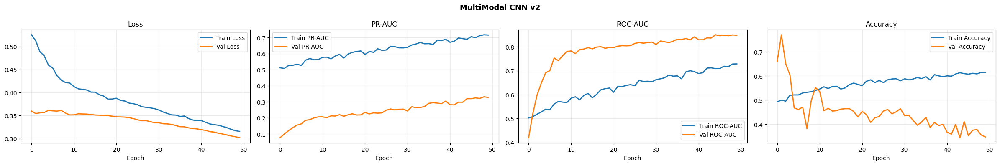

 Reloaded best checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_MultiModalCNN_v2.keras
 MultiModal CNN v2 done.
Epoch 1/50
152/152 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step - accuracy: 0.4969 - auc: 0.4882 - loss: 0.7208 - pr_auc: 0.4940 - precision: 0.4952 - recall: 0.3154
Epoch 1: val_pr_auc improved from None to 0.09477, saving model to /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_MultiModalResNet_v2.keras
152/152 ━━━━━━━━━━━━━━━━━━━━ 35s 169ms/step - accuracy: 0.5004 - auc: 0.4990 - loss: 0.7044 - pr_auc: 0.5057 - precision: 0.5006 - recall: 0.3285 - val_accuracy: 0.4822 - val_auc: 0.5114 - val_loss: 0.2840 - val_pr_auc: 0.0948 - val_precision: 0.0917 - val_recall: 0.5660 - learning_rate: 5.0000e-05
Epoch 2/50
152/152 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step - accuracy: 0.5107 - auc: 0.5144 - loss: 0.6381 - pr_auc: 0.5150 - precision: 0.5149 - recall: 0.3668
Epoch 2: val_pr_auc improved from 0.09477 to 0.11471, saving model to /media/hazem/6A47B344CD80864E/JANA/GP/outputs/be

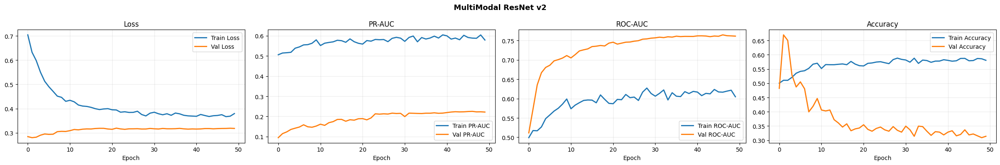

 Reloaded best checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_MultiModalResNet_v2.keras
 MultiModal ResNet v2 done.
Epoch 1/40


2026-05-27 10:19:45.963061: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_12790', 20 bytes spill stores, 20 bytes spill loads

2026-05-27 10:19:46.061946: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_11642', 204 bytes spill stores, 204 bytes spill loads

2026-05-27 10:19:46.366946: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_11642', 5616 bytes spill stores, 5612 bytes spill loads

2026-05-27 10:19:46.418017: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_11642', 5372 bytes spill stores, 5352 bytes spill loads



152/152 ━━━━━━━━━━━━━━━━━━━━ 0s 145ms/step - accuracy: 0.5102 - auc: 0.5089 - loss: 0.4225 - pr_auc: 0.5088 - precision: 0.5127 - recall: 0.4151

2026-05-27 10:20:16.369041: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2217', 104 bytes spill stores, 104 bytes spill loads

2026-05-27 10:20:16.606840: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2217', 5144 bytes spill stores, 5204 bytes spill loads

2026-05-27 10:20:16.787878: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2217', 4964 bytes spill stores, 4964 bytes spill loads




Epoch 1: val_pr_auc improved from None to 0.12362, saving model to /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_MultiModalEfficientNet_v2_P1.keras
152/152 ━━━━━━━━━━━━━━━━━━━━ 39s 190ms/step - accuracy: 0.5173 - auc: 0.5223 - loss: 0.4109 - pr_auc: 0.5117 - precision: 0.5215 - recall: 0.4182 - val_accuracy: 0.6990 - val_auc: 0.6252 - val_loss: 0.0993 - val_pr_auc: 0.1236 - val_precision: 0.1405 - val_recall: 0.4906 - learning_rate: 2.0000e-05
Epoch 2/40
152/152 ━━━━━━━━━━━━━━━━━━━━ 0s 145ms/step - accuracy: 0.5296 - auc: 0.5427 - loss: 0.3981 - pr_auc: 0.5345 - precision: 0.5371 - recall: 0.4277
Epoch 2: val_pr_auc improved from 0.12362 to 0.17526, saving model to /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_MultiModalEfficientNet_v2_P1.keras
152/152 ━━━━━━━━━━━━━━━━━━━━ 23s 151ms/step - accuracy: 0.5364 - auc: 0.5503 - loss: 0.3804 - pr_auc: 0.5412 - precision: 0.5451 - recall: 0.4400 - val_accuracy: 0.7816 - val_auc: 0.7170 - val_loss: 0.0944 - val_pr_auc: 0.1753 - val_p

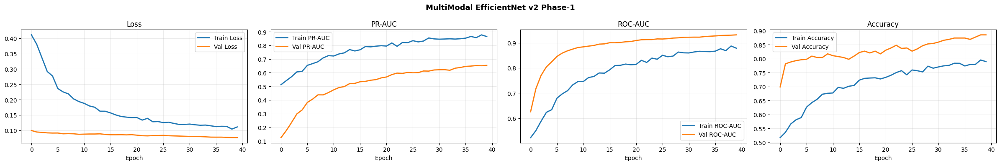

 Best multimodal EfficientNet Phase 1 checkpoint saved to: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_MultiModalEfficientNet_v2_P1.keras
Epoch 1/40
152/152 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step - accuracy: 0.7298 - auc: 0.8043 - loss: 0.1564 - pr_auc: 0.7810 - precision: 0.6977 - recall: 0.8105
Epoch 1: val_pr_auc improved from None to 0.61910, saving model to /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_MultiModalEfficientNet_v2_P2.keras
152/152 ━━━━━━━━━━━━━━━━━━━━ 38s 178ms/step - accuracy: 0.7218 - auc: 0.7983 - loss: 0.1590 - pr_auc: 0.7803 - precision: 0.6933 - recall: 0.7956 - val_accuracy: 0.8608 - val_auc: 0.9096 - val_loss: 0.0813 - val_pr_auc: 0.6191 - val_precision: 0.3636 - val_recall: 0.8302 - learning_rate: 1.0000e-06
Epoch 2/40
152/152 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step - accuracy: 0.7108 - auc: 0.7903 - loss: 0.1624 - pr_auc: 0.7667 - precision: 0.6809 - recall: 0.7941
Epoch 2: val_pr_auc did not improve from 0.61910
152/152 ━━━━━━━━━━━━━━━━━━━━ 22s 145ms/st

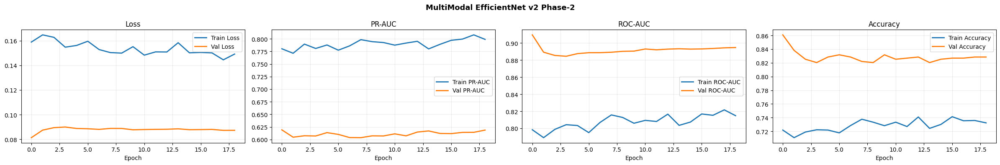

 Reloaded best checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_MultiModalEfficientNet_v2_P2.keras
 MultiModal EfficientNet v2 done.


In [ ]:

# MM-FIX 7: RETRAIN WITH FIXED SETUP

STEPS_MM_V2  = max(n_neg_train // (BATCH_SIZE // 2), 10)
val_mm_data  = ([X_val, X_tab_val], y_val_osteo)

# CNN v2
gen_cnn_v2 = balanced_multimodal_generator(
    X_train, y_train_osteo, X_tab_train, aug_gen,
    batch_size=BATCH_SIZE, seed=42)

history_mm1_v2 = fit_model(mm_model1_v2,
    gen_cnn_v2,
    steps_per_epoch=STEPS_MM_V2,
    epochs=EPOCHS_SCRATCH,
    validation_data=val_mm_data,
    callbacks=get_callbacks('MultiModalCNN_v2'),
    verbose=1
)
plot_history(history_mm1_v2, 'MultiModal CNN v2')
mm_model1_v2 = restore_best_trained_model(mm_model1_v2, 'MultiModalCNN_v2')
print(" MultiModal CNN v2 done.")

#ResNet v2
gen_res_v2 = balanced_multimodal_generator(
    X_train, y_train_osteo, X_tab_train, aug_gen,
    batch_size=BATCH_SIZE, seed=42)

history_mm2_v2 = fit_model(mm_model2_v2,
    gen_res_v2,
    steps_per_epoch=STEPS_MM_V2,
    epochs=EPOCHS_SCRATCH,
    validation_data=val_mm_data,
    callbacks=get_callbacks('MultiModalResNet_v2'),
    verbose=1
)
plot_history(history_mm2_v2, 'MultiModal ResNet v2')
mm_model2_v2 = restore_best_trained_model(mm_model2_v2, 'MultiModalResNet_v2')
print(" MultiModal ResNet v2 done.")

#EfficientNetB0 v2 Phase 1
gen_eff_v2 = balanced_multimodal_generator(
    X_train, y_train_osteo, X_tab_train, aug_gen,
    batch_size=BATCH_SIZE, seed=42)

history_mm3_v2a = fit_model(mm_model3_v2,
    gen_eff_v2,
    steps_per_epoch=STEPS_MM_V2,
    epochs=40,
    validation_data=val_mm_data,
    callbacks=get_callbacks('MultiModalEfficientNet_v2_P1'),
    verbose=1
)
plot_history(history_mm3_v2a, 'MultiModal EfficientNet v2 Phase-1')
print(f" Best multimodal EfficientNet Phase 1 checkpoint saved to: {best_checkpoint_path('MultiModalEfficientNet_v2_P1')}")

#EfficientNetB0 v2 Phase 2 — Fine-tune last 20 layers
for layer in mm_base_v2.layers[:-20]:
    layer.trainable = False
for layer in mm_base_v2.layers[-20:]:
    layer.trainable = True

mm_model3_v2 = compile_mm_model(mm_model3_v2, lr=1e-6)  # very low LR for fine-tuning

gen_eff_v2_ft = balanced_multimodal_generator(
    X_train, y_train_osteo, X_tab_train, aug_gen,
    batch_size=BATCH_SIZE, seed=42)

history_mm3_v2b = fit_model(mm_model3_v2,
    gen_eff_v2_ft,
    steps_per_epoch=STEPS_MM_V2,
    epochs=40,
    validation_data=val_mm_data,
    callbacks=get_callbacks('MultiModalEfficientNet_v2_P2'),
    verbose=1
)
plot_history(history_mm3_v2b, 'MultiModal EfficientNet v2 Phase-2')
mm_model3_v2 = restore_best_trained_model(mm_model3_v2, 'MultiModalEfficientNet_v2_P2')
print(" MultiModal EfficientNet v2 done.")


We run consistency checks on variables before training multimodal networks on the cropped ROI dataset.


In [ ]:
# ROI multimodal config and preflight checks
required_5b_names = [
    'X_roi_train', 'X_roi_val', 'X_roi_test',
    'X_tab_train', 'X_tab_val', 'X_tab_test',
    'y_train_osteo', 'y_val_osteo', 'y_test_osteo',
    'balanced_multimodal_generator', 'compile_mm_model',
    'evaluate_multimodal_model',
    'build_multimodal_cnn_v2', 'build_multimodal_resnet_v2',
    'build_multimodal_efficientnet_v2',
]
missing_5b = [name for name in required_5b_names if name not in globals()]
if missing_5b:
    raise NameError(
        "Section 5B needs Section 5A-1 and Section 5 multimodal helper/build cells first. "
        f"Missing: {missing_5b}"
    )

if X_roi_train.shape[0] != X_tab_train.shape[0] or X_roi_val.shape[0] != X_tab_val.shape[0] or X_roi_test.shape[0] != X_tab_test.shape[0]:
    raise ValueError("ROI image arrays and tabular arrays are not aligned by split length.")

TABULAR_DIM = int(X_tab_train.shape[1])
STEPS_ROI_MM_V2 = max(int((y_train_osteo == 0).sum()) // (BATCH_SIZE // 2), 10)

# Keep compact ROI arrays as-is for storage/training generator. Use float32 for val/test
# because TTA uses SciPy transforms, which do not support float16.
X_roi_val_mm_eval = X_roi_val.astype(np.float32, copy=False)
X_roi_test_mm_eval = X_roi_test.astype(np.float32, copy=False)
X_tab_train_mm = X_tab_train.astype(np.float32, copy=False)
X_tab_val_mm = X_tab_val.astype(np.float32, copy=False)
X_tab_test_mm = X_tab_test.astype(np.float32, copy=False)
roi_mm_val_data = ([X_roi_val_mm_eval, X_tab_val_mm], y_val_osteo)

print("=" * 64)
print("ROI MULTIMODAL CONFIG")
print("=" * 64)
print(f"ROI train/val/test : {X_roi_train.shape} | {X_roi_val.shape} | {X_roi_test.shape}")
print(f"Tab train/val/test : {X_tab_train.shape} | {X_tab_val.shape} | {X_tab_test.shape}")
print(f"TABULAR_DIM        : {TABULAR_DIM}")
print(f"Steps per epoch    : {STEPS_ROI_MM_V2}")
print(f"Validation threshold tuning will use validation split only.")
print("=" * 64)


We train dual-input Custom CNN and ResNet models using the cropped ROI image arrays.


Epoch 1/50
152/152 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step - accuracy: 0.5014 - auc: 0.5229 - loss: 0.5831 - pr_auc: 0.5375 - precision: 0.5008 - recall: 0.8477
Epoch 1: val_pr_auc improved from None to 0.07184, saving model to /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_MultiModalCNN_v2.keras
152/152 ━━━━━━━━━━━━━━━━━━━━ 36s 173ms/step - accuracy: 0.5107 - auc: 0.5467 - loss: 0.5616 - pr_auc: 0.5563 - precision: 0.5064 - recall: 0.8520 - val_accuracy: 0.0955 - val_auc: 0.3930 - val_loss: 0.3867 - val_pr_auc: 0.0718 - val_precision: 0.0866 - val_recall: 1.0000 - learning_rate: 5.0000e-05
Epoch 2/50
152/152 ━━━━━━━━━━━━━━━━━━━━ 0s 151ms/step - accuracy: 0.5196 - auc: 0.5915 - loss: 0.5276 - pr_auc: 0.6027 - precision: 0.5121 - recall: 0.8305
Epoch 2: val_pr_auc improved from 0.07184 to 0.19933, saving model to /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_MultiModalCNN_v2.keras
152/152 ━━━━━━━━━━━━━━━━━━━━ 24s 155ms/step - accuracy: 0.5360 - auc: 0.6137 - loss: 0.5094 - p

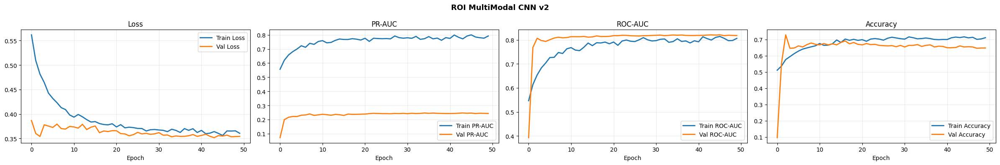

 Reloaded best checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_MultiModalCNN_v2.keras
ROI MultiModal CNN v2 done.
Epoch 1/50
152/152 ━━━━━━━━━━━━━━━━━━━━ 0s 151ms/step - accuracy: 0.5208 - auc: 0.5403 - loss: 0.4632 - pr_auc: 0.5358 - precision: 0.5138 - recall: 0.7818
Epoch 1: val_pr_auc improved from None to 0.37124, saving model to /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_MultiModalResNet_v2.keras
152/152 ━━━━━━━━━━━━━━━━━━━━ 35s 170ms/step - accuracy: 0.5436 - auc: 0.5740 - loss: 0.4433 - pr_auc: 0.5690 - precision: 0.5290 - recall: 0.7944 - val_accuracy: 0.1149 - val_auc: 0.8448 - val_loss: 0.3107 - val_pr_auc: 0.3712 - val_precision: 0.0883 - val_recall: 1.0000 - learning_rate: 5.0000e-05
Epoch 2/50
152/152 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step - accuracy: 0.6052 - auc: 0.6512 - loss: 0.4118 - pr_auc: 0.6266 - precision: 0.5727 - recall: 0.8289
Epoch 2: val_pr_auc did not improve from 0.37124
152/152 ━━━━━━━━━━━━━━━━━━━━ 23s 151ms/step - accuracy: 0.

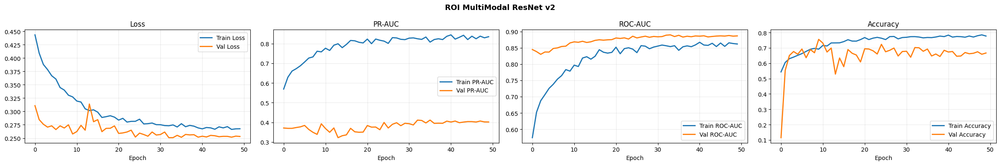

 Reloaded best checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_MultiModalResNet_v2.keras
ROI MultiModal ResNet v2 done.


In [ ]:
# Train ROI MultiModal CNN v2 and ROI MultiModal ResNet v2
roi_mm_results = []

# ROI MultiModal CNN v2
roi_mm_model1_v2 = build_multimodal_cnn_v2(tabular_dim=TABULAR_DIM)
roi_mm_model1_v2 = compile_mm_model(roi_mm_model1_v2, lr=5e-5)

gen_roi_mm_cnn_v2 = balanced_multimodal_generator(
    X_roi_train, y_train_osteo, X_tab_train_mm, aug_gen,
    batch_size=BATCH_SIZE, seed=342
)

history_roi_mm1_v2 = fit_model(
    roi_mm_model1_v2,
    gen_roi_mm_cnn_v2,
    steps_per_epoch=STEPS_ROI_MM_V2,
    epochs=EPOCHS_SCRATCH,
    validation_data=roi_mm_val_data,
    callbacks=get_callbacks('ROI_MultiModalCNN_v2'),
    verbose=1
)
plot_history(history_roi_mm1_v2, 'ROI MultiModal CNN v2')
roi_mm_model1_v2 = restore_best_trained_model(roi_mm_model1_v2, 'ROI_MultiModalCNN_v2')
print("ROI MultiModal CNN v2 done.")

# ROI MultiModal ResNet v2
roi_mm_model2_v2 = build_multimodal_resnet_v2(tabular_dim=TABULAR_DIM)
roi_mm_model2_v2 = compile_mm_model(roi_mm_model2_v2, lr=5e-5)

gen_roi_mm_res_v2 = balanced_multimodal_generator(
    X_roi_train, y_train_osteo, X_tab_train_mm, aug_gen,
    batch_size=BATCH_SIZE, seed=343
)

history_roi_mm2_v2 = fit_model(
    roi_mm_model2_v2,
    gen_roi_mm_res_v2,
    steps_per_epoch=STEPS_ROI_MM_V2,
    epochs=EPOCHS_SCRATCH,
    validation_data=roi_mm_val_data,
    callbacks=get_callbacks('ROI_MultiModalResNet_v2'),
    verbose=1
)
plot_history(history_roi_mm2_v2, 'ROI MultiModal ResNet v2')
roi_mm_model2_v2 = restore_best_trained_model(roi_mm_model2_v2, 'ROI_MultiModalResNet_v2')
print("ROI MultiModal ResNet v2 done.")


We train the dual-input EfficientNetB0 transfer learning model using the cropped ROI dataset.


Epoch 1/40


2026-05-28 03:41:59.911281: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_12790', 20 bytes spill stores, 20 bytes spill loads

2026-05-28 03:42:00.228174: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_11642', 204 bytes spill stores, 204 bytes spill loads

2026-05-28 03:42:00.498157: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_11642', 5372 bytes spill stores, 5352 bytes spill loads

2026-05-28 03:42:00.508796: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_11642', 5616 bytes spill stores, 5612 bytes spill loads



152/152 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step - accuracy: 0.4834 - auc: 0.4805 - loss: 0.4626 - pr_auc: 0.4736 - precision: 0.4823 - recall: 0.4497

2026-05-28 03:42:30.435113: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2217', 104 bytes spill stores, 104 bytes spill loads

2026-05-28 03:42:30.674417: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2217', 5144 bytes spill stores, 5204 bytes spill loads

2026-05-28 03:42:30.823834: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2217', 4964 bytes spill stores, 4964 bytes spill loads




Epoch 1: val_pr_auc improved from None to 0.11586, saving model to /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_MultiModalEfficientNet_v2_P1.keras
152/152 ━━━━━━━━━━━━━━━━━━━━ 39s 190ms/step - accuracy: 0.5078 - auc: 0.5214 - loss: 0.4254 - pr_auc: 0.5001 - precision: 0.5084 - recall: 0.4753 - val_accuracy: 0.7379 - val_auc: 0.6242 - val_loss: 0.1000 - val_pr_auc: 0.1159 - val_precision: 0.1342 - val_recall: 0.3774 - learning_rate: 2.0000e-05
Epoch 2/40
152/152 ━━━━━━━━━━━━━━━━━━━━ 0s 145ms/step - accuracy: 0.5917 - auc: 0.6182 - loss: 0.3395 - pr_auc: 0.5865 - precision: 0.5949 - recall: 0.5740
Epoch 2: val_pr_auc improved from 0.11586 to 0.22604, saving model to /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_MultiModalEfficientNet_v2_P1.keras
152/152 ━━━━━━━━━━━━━━━━━━━━ 23s 151ms/step - accuracy: 0.6063 - auc: 0.6390 - loss: 0.3154 - pr_auc: 0.5991 - precision: 0.6080 - recall: 0.5983 - val_accuracy: 0.7282 - val_auc: 0.8032 - val_loss: 0.0952 - val_pr_auc: 0.2260

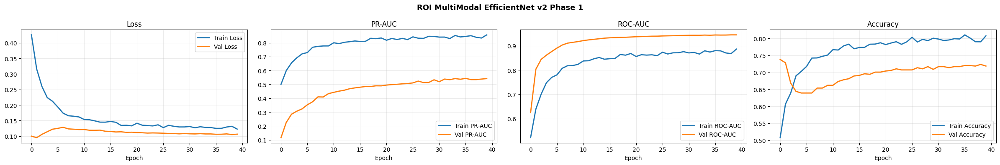

Best ROI multimodal EfficientNet Phase 1 checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_MultiModalEfficientNet_v2_P1.keras
Epoch 1/40
152/152 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step - accuracy: 0.7330 - auc: 0.7994 - loss: 0.2053 - pr_auc: 0.7588 - precision: 0.7148 - recall: 0.7757
Epoch 1: val_pr_auc improved from None to 0.51327, saving model to /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_MultiModalEfficientNet_v2_P2.keras
152/152 ━━━━━━━━━━━━━━━━━━━━ 38s 175ms/step - accuracy: 0.7344 - auc: 0.8060 - loss: 0.2005 - pr_auc: 0.7660 - precision: 0.7140 - recall: 0.7821 - val_accuracy: 0.6456 - val_auc: 0.9077 - val_loss: 0.1224 - val_pr_auc: 0.5133 - val_precision: 0.1903 - val_recall: 0.9623 - learning_rate: 1.0000e-06
Epoch 2/40
152/152 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step - accuracy: 0.7183 - auc: 0.8009 - loss: 0.1971 - pr_auc: 0.7607 - precision: 0.6980 - recall: 0.7696
Epoch 2: val_pr_auc did not improve from 0.51327
152/152 ━━━━━━━━━━━━━━━━━━━━ 22s 143ms/

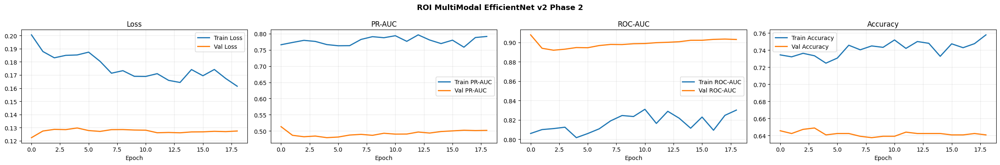

 Reloaded best checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_MultiModalEfficientNet_v2_P2.keras
ROI MultiModal EfficientNet v2 done.


In [ ]:
#  Train ROI MultiModal EfficientNetB0 v2
roi_mm_model3_v2, roi_mm_base_v2 = build_multimodal_efficientnet_v2(tabular_dim=TABULAR_DIM)
roi_mm_model3_v2 = compile_mm_model(roi_mm_model3_v2, lr=2e-5)

gen_roi_mm_eff_v2 = balanced_multimodal_generator(
    X_roi_train, y_train_osteo, X_tab_train_mm, aug_gen,
    batch_size=BATCH_SIZE, seed=344
)

history_roi_mm3_v2a = fit_model(
    roi_mm_model3_v2,
    gen_roi_mm_eff_v2,
    steps_per_epoch=STEPS_ROI_MM_V2,
    epochs=40,
    validation_data=roi_mm_val_data,
    callbacks=get_callbacks('ROI_MultiModalEfficientNet_v2_P1'),
    verbose=1
)
plot_history(history_roi_mm3_v2a, 'ROI MultiModal EfficientNet v2 Phase 1')
print(f"Best ROI multimodal EfficientNet Phase 1 checkpoint: {best_checkpoint_path('ROI_MultiModalEfficientNet_v2_P1')}")

for layer in roi_mm_base_v2.layers[:-20]:
    layer.trainable = False
for layer in roi_mm_base_v2.layers[-20:]:
    layer.trainable = True

roi_mm_model3_v2 = compile_mm_model(roi_mm_model3_v2, lr=1e-6)

gen_roi_mm_eff_v2_ft = balanced_multimodal_generator(
    X_roi_train, y_train_osteo, X_tab_train_mm, aug_gen,
    batch_size=BATCH_SIZE, seed=345
)

history_roi_mm3_v2b = fit_model(
    roi_mm_model3_v2,
    gen_roi_mm_eff_v2_ft,
    steps_per_epoch=STEPS_ROI_MM_V2,
    epochs=40,
    validation_data=roi_mm_val_data,
    callbacks=get_callbacks('ROI_MultiModalEfficientNet_v2_P2'),
    verbose=1
)
plot_history(history_roi_mm3_v2b, 'ROI MultiModal EfficientNet v2 Phase 2')
roi_mm_model3_v2 = restore_best_trained_model(roi_mm_model3_v2, 'ROI_MultiModalEfficientNet_v2_P2')
print("ROI MultiModal EfficientNet v2 done.")


We train the PyTorch ConvNeXt-Tiny dual-input model combining ROI images and tabular metadata.


CONTRIB_MM_ConvNeXtTiny_ROI epoch 01/30 - loss=1.1260 val_pr_auc=0.7249 val_auc=0.9698
  Saved best checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_CONTRIB_MM_ConvNeXtTiny_ROI.pt
CONTRIB_MM_ConvNeXtTiny_ROI epoch 02/30 - loss=1.1751 val_pr_auc=0.8235 val_auc=0.9811
  Saved best checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_CONTRIB_MM_ConvNeXtTiny_ROI.pt
CONTRIB_MM_ConvNeXtTiny_ROI epoch 03/30 - loss=0.8693 val_pr_auc=0.8550 val_auc=0.9762
  Saved best checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_CONTRIB_MM_ConvNeXtTiny_ROI.pt
CONTRIB_MM_ConvNeXtTiny_ROI epoch 04/30 - loss=0.8043 val_pr_auc=0.8669 val_auc=0.9867
  Saved best checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_CONTRIB_MM_ConvNeXtTiny_ROI.pt
CONTRIB_MM_ConvNeXtTiny_ROI epoch 05/30 - loss=0.5025 val_pr_auc=0.8296 val_auc=0.9700
CONTRIB_MM_ConvNeXtTiny_ROI epoch 06/30 - loss=0.3312 val_pr_auc=0.8972 val_auc=0.9903
  Saved best checkpoint: /media/hazem/6A47B344CD80

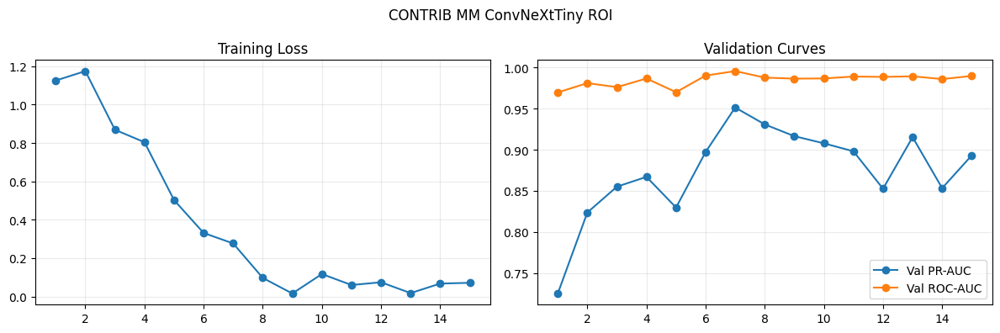

ROI ConvNeXt-Tiny multimodal training complete.


In [ ]:
#  Train ROI ConvNeXt-Tiny multimodal model
if not CONTRIB_HAS_METADATA:
    print('Skipping ROI multimodal ConvNeXt: metadata arrays are missing.')
    hist_convnext_roi_mm = pd.DataFrame()
else:
    convnext_roi_mm_model = TimmConvNeXtMultiModalBinary(
        tabular_dim=TABULAR_DIM_CONTRIB,
        model_name=CONTRIB_MODEL_NAME,
        pretrained=True,
        dropout=0.40,
    )
    convnext_roi_mm_model, hist_convnext_roi_mm = train_torch_binary_model(
        convnext_roi_mm_model,
        train_loader_roi_mm,
        val_loader_roi_mm,
        'CONTRIB_MM_ConvNeXtTiny_ROI',
        y_train_osteo,
    )
    plot_torch_history(hist_convnext_roi_mm, 'CONTRIB MM ConvNeXtTiny ROI')
    del convnext_roi_mm_model
    torch.cuda.empty_cache() if torch.cuda.is_available() else None
    gc.collect()
    print('ROI ConvNeXt-Tiny multimodal training complete.')


We set up embedding-level fusion settings to train classifiers on extracted model embeddings.


In [ ]:
#  ROI embedding-level multimodal setup and leakage guard



required_5c = [
    'X_roi_train', 'X_roi_val', 'X_roi_test',
    'X_tab_train', 'X_tab_val', 'X_tab_test',
    'y_train_osteo', 'y_val_osteo', 'y_test_osteo',
    'OUTPUT_DIR',
    'make_train_only_smote_features',
]
missing_5c = [name for name in required_5c if name not in globals()]
if missing_5c:
    raise RuntimeError(
        'SECTION 5C requires ROI arrays, tabular arrays, labels, and CELL 3S-1 SMOTE helper first. '
        f'Missing: {missing_5c}'
    )

for left, right, label in [
    (X_roi_train, X_tab_train, 'train ROI/tabular'),
    (X_roi_val, X_tab_val, 'val ROI/tabular'),
    (X_roi_test, X_tab_test, 'test ROI/tabular'),
]:
    if len(left) != len(right):
        raise ValueError(f'Length mismatch for {label}: {len(left)} vs {len(right)}')

if len(X_roi_train) != len(y_train_osteo):
    raise ValueError(f'Length mismatch: len(X_roi_train)={len(X_roi_train)} vs len(y_train_osteo)={len(y_train_osteo)}')
if len(X_roi_val) != len(y_val_osteo):
    raise ValueError(f'Length mismatch: len(X_roi_val)={len(X_roi_val)} vs len(y_val_osteo)={len(y_val_osteo)}')
if len(X_roi_test) != len(y_test_osteo):
    raise ValueError(f'Length mismatch: len(X_roi_test)={len(X_roi_test)} vs len(y_test_osteo)={len(y_test_osteo)}')

ROI_EMBED_MM_RANDOM_STATE = 42
ROI_EMBED_MM_BATCH_SIZE = 16
ROI_EMBED_MM_MLP_EPOCHS = 160
ROI_EMBED_MM_MLP_PATIENCE = 18

roi_embedding_mm_results = []
roi_embedding_mm_threshold_rows = []
roi_embedding_mm_smote_rows = []
roi_embedding_mm_plot_items = []

print('=' * 72)
print('SECTION 5C: ROI EMBEDDING-LEVEL MULTIMODAL MODELS')
print('=' * 72)
print(f'ROI train/val/test     : {X_roi_train.shape} | {X_roi_val.shape} | {X_roi_test.shape}')
print(f'Tabular train/val/test : {X_tab_train.shape} | {X_tab_val.shape} | {X_tab_test.shape}')
print(f'Labels train/val/test  : {len(y_train_osteo)} | {len(y_val_osteo)} | {len(y_test_osteo)}')
print('SMOTE policy           : dense training vectors only; validation/test untouched.')
print('=' * 72)


We run feed-forward inference to extract dense features (embeddings) from the ROI-trained EfficientNetB0.


In [ ]:
#  Extract dense ROI EfficientNet embeddings
def _find_gap_feature_layer(model):
    # Return the final GlobalAveragePooling2D layer in a loaded Keras model.
    gap_layers = [
        layer for layer in getattr(model, 'layers', [])
        if isinstance(layer, tf.keras.layers.GlobalAveragePooling2D)
    ]
    if not gap_layers:
        return None
    return gap_layers[-1]

def _predict_embeddings_batched(model, X, batch_size=ROI_EMBED_MM_BATCH_SIZE, description='embedding extraction'):
    X = np.asarray(X).astype(np.float32, copy=False)
    feats = []
    for start in range(0, len(X), batch_size):
        batch = X[start:start + batch_size]
        if 'predict_model' in globals():
            pred = predict_model(
                model, batch, batch_size=len(batch), verbose=0,
                description=f'{description} [{start}:{start + len(batch)}]'
            )
        else:
            pred = model.predict(batch, batch_size=len(batch), verbose=0)
        feats.append(np.asarray(pred))
    return np.concatenate(feats, axis=0).astype(np.float32)

def extract_roi_efficientnet_embeddings(force_recompute=False, batch_size=ROI_EMBED_MM_BATCH_SIZE):
    # Create dense ROI EfficientNet embeddings for train/val/test splits.
    # Preferred source: the saved best ROI EfficientNet checkpoint from SECTION 5A.
    # Fallback source: frozen ImageNet EfficientNetB0 no-top feature extractor.
    existing = [
        'X_roi_eff_embed_train', 'X_roi_eff_embed_val', 'X_roi_eff_embed_test'
    ]
    if not force_recompute and all(name in globals() for name in existing):
        print('Using existing ROI EfficientNet embeddings from memory.')
        return X_roi_eff_embed_train, X_roi_eff_embed_val, X_roi_eff_embed_test

    source = 'frozen_imagenet_efficientnetb0'
    feature_model = None
    loaded_model = None

    ckpt_path = Path(best_checkpoint_path('ROI_EfficientNetB0_P2')) if 'best_checkpoint_path' in globals() else None
    if ckpt_path is not None and ckpt_path.exists():
        try:
            load_kwargs = _best_model_load_kwargs() if '_best_model_load_kwargs' in globals() else {}
            load_kwargs = dict(load_kwargs)
            load_kwargs['compile'] = False
            print(f'Loading ROI EfficientNet checkpoint for embeddings: {ckpt_path}')
            loaded_model = tf.keras.models.load_model(ckpt_path, **load_kwargs)
            gap_layer = _find_gap_feature_layer(loaded_model)
            if gap_layer is None:
                raise ValueError('No GlobalAveragePooling2D layer found in loaded ROI EfficientNet model.')
            feature_model = tf.keras.Model(loaded_model.input, gap_layer.output, name='ROI_EfficientNet_EmbeddingExtractor')
            source = 'best_roi_efficientnet_checkpoint'
        except Exception as exc:
            print(f'Checkpoint feature extraction unavailable ({type(exc).__name__}: {exc}). Falling back to frozen ImageNet EfficientNetB0.')
            feature_model = None
            loaded_model = None
            tf.keras.backend.clear_session()
            gc.collect()

    if feature_model is None:
        feature_model = tf.keras.Sequential([
            layers.Rescaling(scale=255.0, input_shape=(224, 224, 3)),
            EfficientNetB0(weights='imagenet', include_top=False, input_shape=(224, 224, 3)),
            layers.GlobalAveragePooling2D(),
        ], name='Frozen_ImageNet_EfficientNetB0_ROI_EmbeddingExtractor')
        feature_model.trainable = False

    print(f'Embedding source: {source}')
    train_embed = _predict_embeddings_batched(feature_model, X_roi_train, batch_size, 'ROI EfficientNet train embeddings')
    val_embed = _predict_embeddings_batched(feature_model, X_roi_val, batch_size, 'ROI EfficientNet val embeddings')
    test_embed = _predict_embeddings_batched(feature_model, X_roi_test, batch_size, 'ROI EfficientNet test embeddings')

    globals()['X_roi_eff_embed_train'] = train_embed
    globals()['X_roi_eff_embed_val'] = val_embed
    globals()['X_roi_eff_embed_test'] = test_embed
    globals()['roi_eff_embedding_source'] = source

    del feature_model
    if loaded_model is not None:
        del loaded_model
    tf.keras.backend.clear_session()
    gc.collect()

    print(f'ROI EfficientNet embeddings: train={train_embed.shape}, val={val_embed.shape}, test={test_embed.shape}')
    return train_embed, val_embed, test_embed

X_roi_eff_embed_train, X_roi_eff_embed_val, X_roi_eff_embed_test = extract_roi_efficientnet_embeddings()


We concatenate the extracted ROI embeddings with tabular features and apply SMOTE to the training split.


In [ ]:
# concatenate embeddings and tabular features
def _make_dense_roi_tab_features(embed_train, embed_val, embed_test, prefix, feature_name):
    if len(embed_train) != len(X_tab_train) or len(embed_val) != len(X_tab_val) or len(embed_test) != len(X_tab_test):
        raise ValueError(f'{feature_name}: embedding/tabular length mismatch.')

    X_train_dense = np.concatenate([
        np.asarray(embed_train, dtype=np.float32),
        np.asarray(X_tab_train, dtype=np.float32),
    ], axis=1)
    X_val_dense = np.concatenate([
        np.asarray(embed_val, dtype=np.float32),
        np.asarray(X_tab_val, dtype=np.float32),
    ], axis=1)
    X_test_dense = np.concatenate([
        np.asarray(embed_test, dtype=np.float32),
        np.asarray(X_tab_test, dtype=np.float32),
    ], axis=1)

    globals()[f'X_{prefix}_train'] = X_train_dense
    globals()[f'X_{prefix}_val'] = X_val_dense
    globals()[f'X_{prefix}_test'] = X_test_dense
    print(f'{feature_name}: train={X_train_dense.shape}, val={X_val_dense.shape}, test={X_test_dense.shape}')
    return X_train_dense, X_val_dense, X_test_dense

def _scale_train_val_test_dense(X_train_dense, X_val_dense, X_test_dense, scaler_name):
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_dense).astype(np.float32)
    X_val_scaled = scaler.transform(X_val_dense).astype(np.float32)
    X_test_scaled = scaler.transform(X_test_dense).astype(np.float32)
    globals()[scaler_name] = scaler
    return X_train_scaled, X_val_scaled, X_test_scaled, scaler

def _smote_scaled_train_only(X_train_scaled, y_train_vec, feature_name, X_var_name, y_var_name):
    X_smote, y_smote, metadata = make_train_only_smote_features(
        X_train_scaled, y_train_vec, feature_name
    )
    globals()[X_var_name] = X_smote
    globals()[y_var_name] = y_smote
    roi_embedding_mm_smote_rows.append(metadata)
    return X_smote, y_smote, metadata

X_roi_eff_tab_train, X_roi_eff_tab_val, X_roi_eff_tab_test = _make_dense_roi_tab_features(
    X_roi_eff_embed_train, X_roi_eff_embed_val, X_roi_eff_embed_test,
    'roi_eff_tab', 'ROI EfficientNet embeddings + tabular'
)

X_roi_eff_tab_train_scaled, X_roi_eff_tab_val_scaled, X_roi_eff_tab_test_scaled, roi_eff_tab_scaler = _scale_train_val_test_dense(
    X_roi_eff_tab_train, X_roi_eff_tab_val, X_roi_eff_tab_test,
    'roi_eff_tab_scaler'
)

X_roi_eff_tab_train_smote, y_roi_eff_tab_train_smote, roi_eff_tab_smote_meta = _smote_scaled_train_only(
    X_roi_eff_tab_train_scaled, y_train_osteo,
    'roi_effnet_embedding_plus_tabular',
    'X_roi_eff_tab_train_smote', 'y_roi_eff_tab_train_smote'
)

# Optional ConvNeXt embedding branch. It reuses embeddings created by SECTION 5A-C
# if they are still available; otherwise this branch is skipped cleanly.
ROI_EMBED_MM_HAS_CONVNEXT = all(
    name in globals() for name in ['roi_train_embed', 'roi_val_embed', 'roi_test_embed']
)
if ROI_EMBED_MM_HAS_CONVNEXT:
    X_roi_convnext_tab_train, X_roi_convnext_tab_val, X_roi_convnext_tab_test = _make_dense_roi_tab_features(
        roi_train_embed, roi_val_embed, roi_test_embed,
        'roi_convnext_tab', 'ROI ConvNeXt embeddings + tabular'
    )
    X_roi_convnext_tab_train_scaled, X_roi_convnext_tab_val_scaled, X_roi_convnext_tab_test_scaled, roi_convnext_tab_scaler = _scale_train_val_test_dense(
        X_roi_convnext_tab_train, X_roi_convnext_tab_val, X_roi_convnext_tab_test,
        'roi_convnext_tab_scaler'
    )
    X_roi_convnext_tab_train_smote, y_roi_convnext_tab_train_smote, roi_convnext_tab_smote_meta = _smote_scaled_train_only(
        X_roi_convnext_tab_train_scaled, y_train_osteo,
        'roi_convnext_embedding_plus_tabular',
        'X_roi_convnext_tab_train_smote', 'y_roi_convnext_tab_train_smote'
    )
else:
    print('Optional ConvNeXt embedding branch skipped: roi_train_embed/roi_val_embed/roi_test_embed not found.')

roi_embedding_multimodal_smote_summary_df = pd.DataFrame(roi_embedding_mm_smote_rows)
roi_embedding_multimodal_smote_summary_df.to_csv(
    os.path.join(OUTPUT_DIR, 'roi_embedding_multimodal_smote_summary.csv'),
    index=False
)
display(roi_embedding_multimodal_smote_summary_df)
print(f"Saved: {os.path.join(OUTPUT_DIR, 'roi_embedding_multimodal_smote_summary.csv')}")


We train shallow classifiers (like Logistic Regression and light MLPs) on the balanced embedding-tabular features.


In [ ]:
# train shallow classifiers on embeddings
def _threshold_on_validation(y_val_true, y_val_prob):
    if 'find_best_threshold_on_val' in globals():
        return find_best_threshold_on_val(y_val_true, y_val_prob)
    fpr, tpr, thresholds = roc_curve(y_val_true, y_val_prob)
    return float(np.clip(thresholds[np.argmax(tpr - fpr)], 0.05, 0.95))

def _dense_metric_row(y_true, y_prob, model_name, threshold):
    if 'evaluate_torch_binary_predictions' in globals():
        return evaluate_torch_binary_predictions(y_true, y_prob, model_name, threshold=threshold)
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob).astype(float)
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        'model': model_name,
        'accuracy': accuracy_score(y_true, y_pred),
        'balanced_acc': balanced_accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall': recall_score(y_true, y_pred, zero_division=0),
        'specificity': tn / max(tn + fp, 1),
        'f1': f1_score(y_true, y_pred, zero_division=0),
        'macro_f1': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'mcc': matthews_corrcoef(y_true, y_pred),
        'auc': roc_auc_score(y_true, y_prob) if len(np.unique(y_true)) == 2 else np.nan,
        'pr_auc': average_precision_score(y_true, y_prob) if len(np.unique(y_true)) == 2 else np.nan,
        'npv': tn / max(tn + fn, 1),
        'threshold': float(threshold),
    }

def _register_dense_result(model_name, y_val_true, y_val_prob, y_test_true, y_test_prob):
    threshold = _threshold_on_validation(y_val_true, y_val_prob)
    row = _dense_metric_row(y_test_true, y_test_prob, model_name, threshold)
    roi_embedding_mm_results.append(row)
    roi_embedding_mm_threshold_rows.append({
        'model': model_name,
        'threshold': threshold,
        'threshold_source': 'validation',
    })
    roi_embedding_mm_plot_items.append((model_name, np.asarray(y_test_prob, dtype=float), threshold))
    print(f"{model_name}: validation-selected threshold={threshold:.4f}, test PR-AUC={row['pr_auc']:.4f}, MCC={row['mcc']:.4f}")
    return row

def train_roi_embedding_logreg_branch(branch_key, model_label, X_train_smote, y_train_smote, X_val_scaled, X_test_scaled, scaler):
    clf = LogisticRegression(
        max_iter=5000,
        class_weight='balanced',
        solver='liblinear',
        random_state=ROI_EMBED_MM_RANDOM_STATE,
    )
    clf.fit(X_train_smote, y_train_smote)
    y_val_prob = clf.predict_proba(X_val_scaled)[:, 1]
    y_test_prob = clf.predict_proba(X_test_scaled)[:, 1]
    row = _register_dense_result(
        model_label, y_val_osteo, y_val_prob, y_test_osteo, y_test_prob
    )
    artifact_path = os.path.join(OUTPUT_DIR, f'best_ROIEmbeddingMM_{branch_key}_LogReg.joblib')
    joblib.dump({'scaler': scaler, 'model': clf, 'threshold': row['threshold']}, artifact_path)
    print(f'Saved: {artifact_path}')
    return clf

def build_roi_embedding_mlp(input_dim):
    model = tf.keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(256, kernel_regularizer=regularizers.l2(1e-4)),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.Dropout(0.35),
        layers.Dense(96, kernel_regularizer=regularizers.l2(1e-4)),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.Dropout(0.30),
        layers.Dense(1, activation='sigmoid'),
    ], name='ROIEmbeddingMM_MLP')
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=8e-4),
        loss='binary_crossentropy',
        metrics=_metrics() if '_metrics' in globals() else [
            tf.keras.metrics.BinaryAccuracy(name='accuracy'),
            tf.keras.metrics.AUC(name='auc'),
            tf.keras.metrics.AUC(name='pr_auc', curve='PR'),
            tf.keras.metrics.Precision(name='precision'),
            tf.keras.metrics.Recall(name='recall'),
        ],
    )
    return model

def train_roi_embedding_mlp_branch(branch_key, model_label, X_train_smote, y_train_smote, X_val_scaled, X_test_scaled, scaler):
    ckpt_path = os.path.join(OUTPUT_DIR, f'best_ROIEmbeddingMM_{branch_key}_MLP.keras')
    scaler_path = os.path.join(OUTPUT_DIR, f'best_ROIEmbeddingMM_{branch_key}_MLP_scaler.joblib')
    # Dense feature MLP is tiny; keep it on...
    with tf.device('/CPU:0'):
        model = build_roi_embedding_mlp(X_train_smote.shape[1])
        cb = [
            tf.keras.callbacks.ModelCheckpoint(
                ckpt_path, monitor='val_pr_auc', mode='max',
                save_best_only=True, verbose=1,
            ),
            tf.keras.callbacks.EarlyStopping(
                monitor='val_pr_auc', mode='max',
                patience=ROI_EMBED_MM_MLP_PATIENCE,
                restore_best_weights=True, verbose=1,
            ),
            tf.keras.callbacks.ReduceLROnPlateau(
                monitor='val_loss', mode='min',
                factor=0.5, patience=6, min_lr=1e-6, verbose=1,
            ),
        ]
        hist = model.fit(
            X_train_smote, y_train_smote,
            epochs=ROI_EMBED_MM_MLP_EPOCHS,
            batch_size=64,
            validation_data=(X_val_scaled, y_val_osteo),
            callbacks=cb,
            verbose=1,
        )
        best_model = tf.keras.models.load_model(ckpt_path, compile=False)
        y_val_prob = best_model.predict(X_val_scaled, batch_size=256, verbose=0).ravel()
        y_test_prob = best_model.predict(X_test_scaled, batch_size=256, verbose=0).ravel()
    if 'plot_history' in globals():
        plot_history(hist, model_label)
    row = _register_dense_result(
        model_label, y_val_osteo, y_val_prob, y_test_osteo, y_test_prob
    )
    joblib.dump({'scaler': scaler, 'threshold': row['threshold']}, scaler_path)
    print(f'Saved: {ckpt_path}')
    print(f'Saved: {scaler_path}')
    return best_model, hist

roi_eff_tab_logreg = train_roi_embedding_logreg_branch(
    'EfficientNet', 'ROIEmbeddingMM-EfficientNet-LogReg',
    X_roi_eff_tab_train_smote, y_roi_eff_tab_train_smote,
    X_roi_eff_tab_val_scaled, X_roi_eff_tab_test_scaled, roi_eff_tab_scaler,
)
roi_eff_tab_mlp, hist_roi_eff_tab_mlp = train_roi_embedding_mlp_branch(
    'EfficientNet', 'ROIEmbeddingMM-EfficientNet-MLP',
    X_roi_eff_tab_train_smote, y_roi_eff_tab_train_smote,
    X_roi_eff_tab_val_scaled, X_roi_eff_tab_test_scaled, roi_eff_tab_scaler,
)

if globals().get('ROI_EMBED_MM_HAS_CONVNEXT', False):
    roi_convnext_tab_logreg = train_roi_embedding_logreg_branch(
        'ConvNeXt', 'ROIEmbeddingMM-ConvNeXt-LogReg',
        X_roi_convnext_tab_train_smote, y_roi_convnext_tab_train_smote,
        X_roi_convnext_tab_val_scaled, X_roi_convnext_tab_test_scaled, roi_convnext_tab_scaler,
    )
    roi_convnext_tab_mlp, hist_roi_convnext_tab_mlp = train_roi_embedding_mlp_branch(
        'ConvNeXt', 'ROIEmbeddingMM-ConvNeXt-MLP',
        X_roi_convnext_tab_train_smote, y_roi_convnext_tab_train_smote,
        X_roi_convnext_tab_val_scaled, X_roi_convnext_tab_test_scaled, roi_convnext_tab_scaler,
    )
else:
    print('ConvNeXt dense multimodal classifiers skipped because ConvNeXt embeddings are unavailable.')



### Evaluation of Multimodal Fusion Models
Detailed evaluations of full-image and ROI multimodal classifiers.


We evaluate the full-image multimodal classifiers on the test split and compile a comparison table.


  Predicted probs — min:0.382  max:0.937  mean:0.518  median:0.506
  Threshold source : validation set (no test leakage)
  Optimal threshold: 0.5513
══════════════════════════════════════════
  MultiModal CNN v2
──────────────────────────────────────────
  accuracy             0.8124
  balanced_acc         0.8221
  precision            0.2315
  recall               0.8333
  specificity          0.8109
  npv                  0.9861
  f1                   0.3623
  macro_f1             0.6262
  mcc                  0.3744
  auc                  0.8714
  pr_auc               0.3853
──────────────────────────────────────────
  TP=25    FP=83    FN=5     TN=356


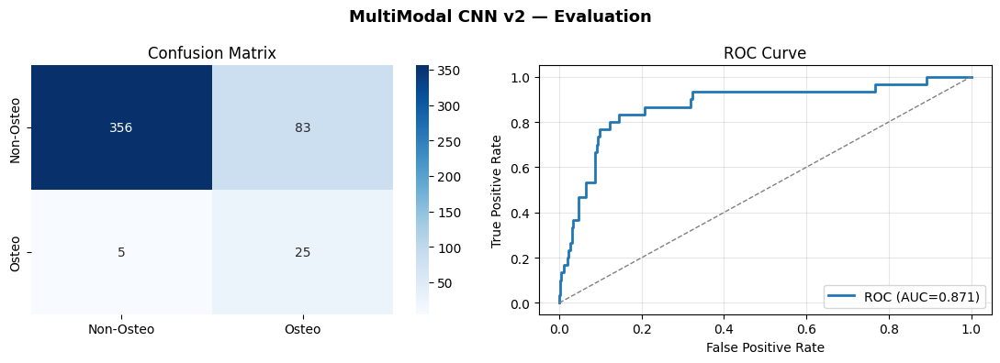

  Predicted probs — min:0.273  max:0.959  mean:0.579  median:0.588
  Threshold source : validation set (no test leakage)
  Optimal threshold: 0.6886
══════════════════════════════════════════
  MultiModal ResNet v2
──────────────────────────────────────────
  accuracy             0.7825
  balanced_acc         0.7130
  precision            0.1727
  recall               0.6333
  specificity          0.7927
  npv                  0.9694
  f1                   0.2714
  macro_f1             0.5718
  mcc                  0.2460
  auc                  0.8253
  pr_auc               0.2669
──────────────────────────────────────────
  TP=19    FP=91    FN=11    TN=348


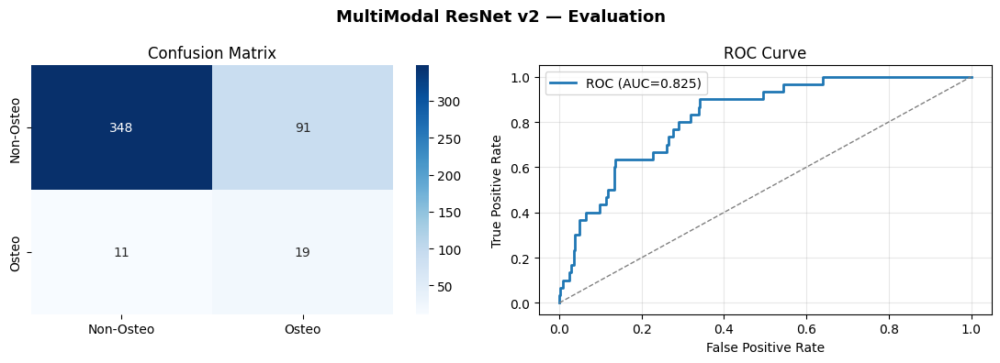

2026-05-27 11:52:00.175634: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2076', 232 bytes spill stores, 232 bytes spill loads

2026-05-27 11:52:00.342696: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2076', 5524 bytes spill stores, 5564 bytes spill loads

2026-05-27 11:52:00.591974: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2076', 5380 bytes spill stores, 5380 bytes spill loads



  Predicted probs — min:0.001  max:0.970  mean:0.343  median:0.314
  Threshold source : validation set (no test leakage)
  Optimal threshold: 0.4585
══════════════════════════════════════════
  MultiModal EfficientNet v2
──────────────────────────────────────────
  accuracy             0.7420
  balanced_acc         0.7690
  precision            0.1727
  recall               0.8000
  specificity          0.7380
  npv                  0.9818
  f1                   0.2840
  macro_f1             0.5633
  mcc                  0.2883
  auc                  0.8678
  pr_auc               0.5688
──────────────────────────────────────────
  TP=24    FP=115   FN=6     TN=324


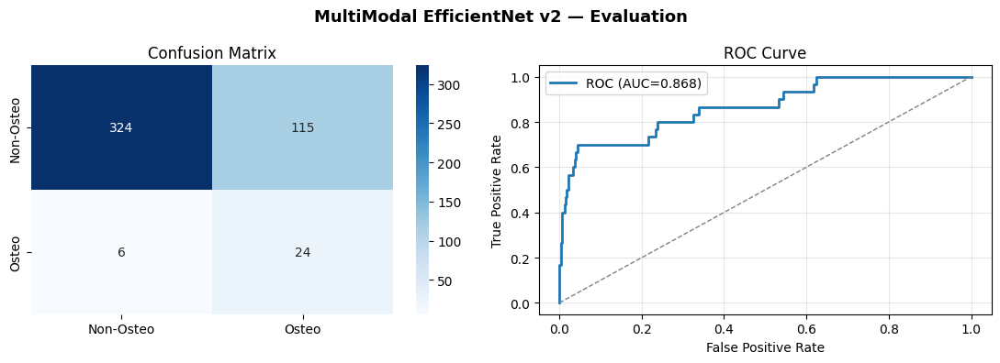


  FULL MODEL COMPARISON — ALL MODELS


,accuracy,balanced_acc,precision,recall,specificity,f1,macro_f1,mcc,auc,pr_auc,npv
model,,,,,,,,,,,
Custom CNN,0.8380,0.8047,0.2500,0.7667,0.8428,0.3770,0.6420,0.3756,0.8789,0.4884,0.9814
Custom ResNet,0.8678,0.7586,0.2714,0.6333,0.8838,0.3800,0.6530,0.3551,0.8689,0.5265,0.9724
EfficientNetB0,0.7655,0.8592,0.2101,0.9667,0.7517,0.3452,0.6012,0.3857,0.9678,0.7594,0.9970
MultiModal CNN v2,0.8124,0.8221,0.2315,0.8333,0.8109,0.3623,0.6262,0.3744,0.8714,0.3853,0.9861
MultiModal ResNet v2,0.7825,0.7130,0.1727,0.6333,0.7927,0.2714,0.5718,0.2460,0.8253,0.2669,0.9694
MultiModal EfficientNet v2,0.7420,0.7690,0.1727,0.8000,0.7380,0.2840,0.5633,0.2883,0.8678,0.5688,0.9818


Saved: model_comparison_all.csv


In [ ]:

# EVALUATE V2 MODELS

mm_v2_results = []

mm_res1_v2, mm_prob1_v2 = evaluate_multimodal_model(
    mm_model1_v2, X_test, X_tab_test, y_test_osteo,
    "MultiModal CNN v2", X_val, X_tab_val, y_val_osteo)
mm_v2_results.append(mm_res1_v2)

mm_res2_v2, mm_prob2_v2 = evaluate_multimodal_model(
    mm_model2_v2, X_test, X_tab_test, y_test_osteo,
    "MultiModal ResNet v2", X_val, X_tab_val, y_val_osteo)
mm_v2_results.append(mm_res2_v2)

mm_res3_v2, mm_prob3_v2 = evaluate_multimodal_model(
    mm_model3_v2, X_test, X_tab_test, y_test_osteo,
    "MultiModal EfficientNet v2", X_val, X_tab_val, y_val_osteo)
mm_v2_results.append(mm_res3_v2)

# Full comparison: original 3 + mm v1 3...
all_combined = (all_results if "all_results" in dir() else []) + \
               (mm_all_results if "mm_all_results" in dir() else []) + \
               mm_v2_results

combined_df2 = pd.DataFrame(all_combined).set_index("model")
col_order = ["accuracy","balanced_acc","precision","recall",
             "specificity","f1","macro_f1","mcc","auc","pr_auc","npv"]
col_order = [c for c in col_order if c in combined_df2.columns]
print("\n" + "="*70)
print("  FULL MODEL COMPARISON — ALL MODELS")
print("="*70)
display(combined_df2[col_order].style.format("{:.4f}")
        .highlight_max(color="lightgreen", axis=0)
        .highlight_min(color="# ffcccc", axis=0))
combined_df2[col_order].to_csv(os.path.join(OUTPUT_DIR, "model_comparison_all.csv"))
print(f"Saved: model_comparison_all.csv")


We evaluate the dual-input Keras models on the cropped ROI test set and calculate confidence intervals.


Loading ROI_MultiModalEfficientNet_v2_P2 from best saved checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_MultiModalEfficientNet_v2_P2.keras
Using ROI MultiModal EfficientNetB0 Phase 2 best checkpoint for evaluation.
  Predicted probs — min:0.033  max:0.991  mean:0.365  median:0.322
  Threshold source : validation set (no test leakage)
  Optimal threshold: 0.5086
══════════════════════════════════════════
  ROI-MultiModal CNN v2
──────────────────────────────────────────
  accuracy             0.7846
  balanced_acc         0.8384
  precision            0.2160
  recall               0.9000
  specificity          0.7768
  npv                  0.9913
  f1                   0.3484
  macro_f1             0.6097
  mcc                  0.3745
  auc                  0.9351
  pr_auc               0.5369
──────────────────────────────────────────
  TP=27    FP=98    FN=3     TN=341


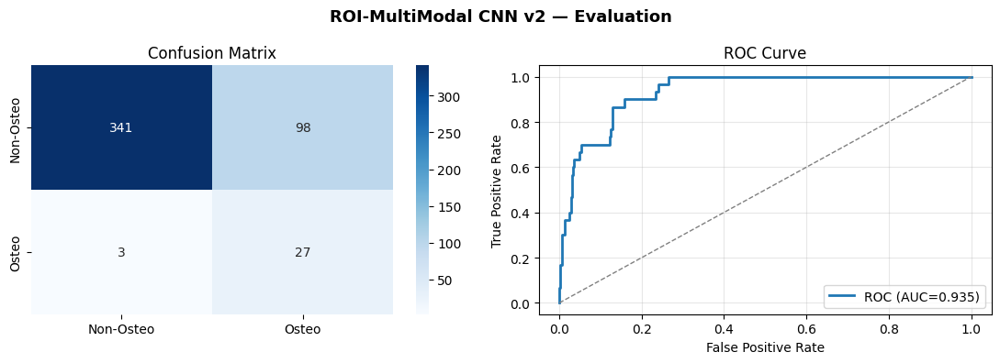

ROI-MultiModal CNN v2 validation-only threshold: 0.5086
  Predicted probs — min:0.000  max:0.912  mean:0.288  median:0.235
  Threshold source : validation set (no test leakage)
  Optimal threshold: 0.5276
══════════════════════════════════════════
  ROI-MultiModal ResNet v2
──────────────────────────────────────────
  accuracy             0.8294
  balanced_acc         0.8778
  precision            0.2642
  recall               0.9333
  specificity          0.8223
  npv                  0.9945
  f1                   0.4118
  macro_f1             0.6560
  mcc                  0.4421
  auc                  0.9560
  pr_auc               0.6613
──────────────────────────────────────────
  TP=28    FP=78    FN=2     TN=361


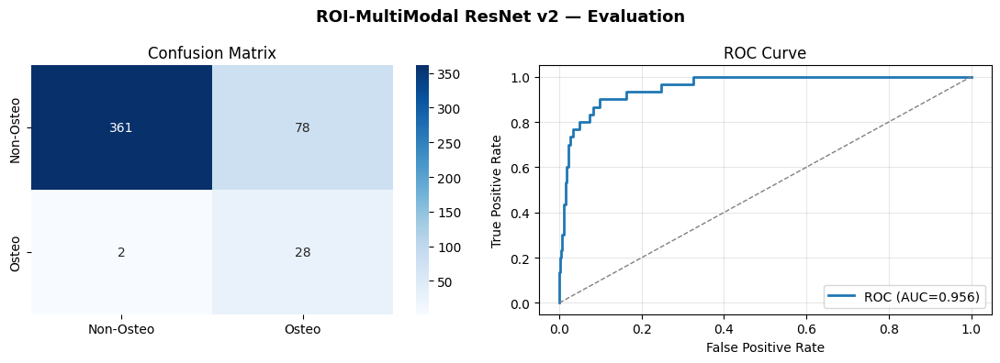

ROI-MultiModal ResNet v2 validation-only threshold: 0.5276


2026-05-28 04:04:27.387926: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2076', 232 bytes spill stores, 232 bytes spill loads

2026-05-28 04:04:27.645951: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2076', 5524 bytes spill stores, 5564 bytes spill loads

2026-05-28 04:04:27.823879: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2076', 5380 bytes spill stores, 5380 bytes spill loads



  Predicted probs — min:0.000  max:0.990  mean:0.264  median:0.039
  Threshold source : validation set (no test leakage)
  Optimal threshold: 0.6638
══════════════════════════════════════════
  ROI-MultiModal EfficientNet v2
──────────────────────────────────────────
  accuracy             0.8763
  balanced_acc         0.9339
  precision            0.3409
  recall               1.0000
  specificity          0.8679
  npv                  1.0000
  f1                   0.5085
  macro_f1             0.7189
  mcc                  0.5439
  auc                  0.9500
  pr_auc               0.6093
──────────────────────────────────────────
  TP=30    FP=58    FN=0     TN=381


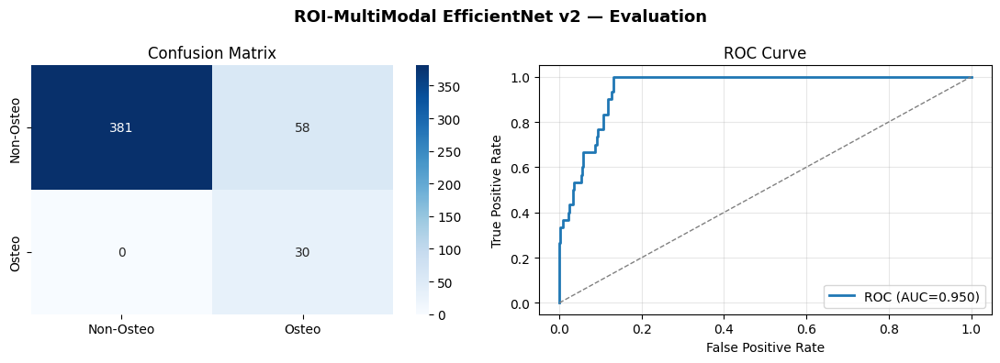

ROI-MultiModal EfficientNet v2 validation-only threshold: 0.6638

ROI MULTIMODAL MODEL COMPARISON


,accuracy,balanced_acc,precision,recall,specificity,f1,macro_f1,mcc,auc,pr_auc,npv,threshold
model,,,,,,,,,,,,
ROI-MultiModal CNN v2,0.7846,0.8384,0.2160,0.9000,0.7768,0.3484,0.6097,0.3745,0.9351,0.5369,0.9913,0.5086
ROI-MultiModal ResNet v2,0.8294,0.8778,0.2642,0.9333,0.8223,0.4118,0.6560,0.4421,0.9560,0.6613,0.9945,0.5276
ROI-MultiModal EfficientNet v2,0.8763,0.9339,0.3409,1.0000,0.8679,0.5085,0.7189,0.5439,0.9500,0.6093,1.0000,0.6638


Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/roi_multimodal_model_comparison.csv
Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/roi_multimodal_bootstrap_confidence_intervals.csv


,model,metric,ci_low,median,ci_high
0,ROI-MultiModal CNN v2,recall,0.791667,0.909091,1.000000
1,ROI-MultiModal CNN v2,precision,0.145296,0.216000,0.293279
2,ROI-MultiModal CNN v2,specificity,0.734694,0.778407,0.815739
3,ROI-MultiModal CNN v2,balanced_acc,0.779684,0.842166,0.893096
4,ROI-MultiModal CNN v2,mcc,0.286061,0.376398,0.457249
5,ROI-MultiModal CNN v2,auc,0.904676,0.937196,0.963390
6,ROI-MultiModal CNN v2,pr_auc,0.366524,0.554804,0.717814
7,ROI-MultiModal ResNet v2,recall,0.839968,0.941176,1.000000
8,ROI-MultiModal ResNet v2,precision,0.179474,0.265306,0.353462
9,ROI-MultiModal ResNet v2,specificity,0.786832,0.823529,0.858778


In [ ]:
#  Evaluate ROI multimodal models and bootstrap confidence intervals

if 'X_roi_test_mm_eval' not in globals():
    X_roi_val_mm_eval = X_roi_val.astype(np.float32, copy=False)
    X_roi_test_mm_eval = X_roi_test.astype(np.float32, copy=False)
if 'X_tab_test_mm' not in globals():
    X_tab_val_mm = X_tab_val.astype(np.float32, copy=False)
    X_tab_test_mm = X_tab_test.astype(np.float32, copy=False)

def _roi_mm_load_model(var_name, checkpoint_name, force_reload=False):
    if var_name in globals() and not force_reload:
        return globals()[var_name]
    ckpt = Path(best_checkpoint_path(checkpoint_name))
    if not ckpt.exists():
        raise FileNotFoundError(f"Missing checkpoint: {ckpt}. Run the corresponding Section 5B training cell first.")
    print(f"Loading {checkpoint_name} from best saved checkpoint: {ckpt}")
    load_kwargs = _best_model_load_kwargs() if '_best_model_load_kwargs' in globals() else {}
    model = run_tf_work(
        lambda: tf.keras.models.load_model(ckpt, **load_kwargs),
        description=f'load {checkpoint_name}',
        fallback_to_cpu=False,
    )
    globals()[var_name] = model
    return model

def roi_mm_validation_threshold(model, X_img_val, X_tab_val_data, y_val, model_name):
    y_prob_val = predict_model(
        model, [X_img_val, X_tab_val_data],
        batch_size=32, verbose=0,
        description=f'{model_name} validation threshold prediction'
    ).ravel()
    fpr_v, tpr_v, thr_v = roc_curve(y_val, y_prob_val)
    best_thr = float(np.clip(thr_v[np.argmax(tpr_v - fpr_v)], 0.05, 0.95))
    print(f"{model_name} validation-only threshold: {best_thr:.4f}")
    return best_thr

def bootstrap_metric_ci_mm(y_true, y_prob, threshold, n_boot=1000, seed=42):
    rng = np.random.default_rng(seed)
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob).astype(float)
    rows = []
    n = len(y_true)
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        yt = y_true[idx]
        yp = y_prob[idx]
        pred = (yp >= threshold).astype(int)
        cm = confusion_matrix(yt, pred, labels=[0, 1])
        tn, fp, fn, tp = cm.ravel()
        rows.append({
            'recall': recall_score(yt, pred, zero_division=0),
            'precision': precision_score(yt, pred, zero_division=0),
            'specificity': tn / max(tn + fp, 1),
            'balanced_acc': balanced_accuracy_score(yt, pred),
            'mcc': matthews_corrcoef(yt, pred),
            'auc': roc_auc_score(yt, yp) if len(np.unique(yt)) == 2 else np.nan,
            'pr_auc': average_precision_score(yt, yp) if len(np.unique(yt)) == 2 else np.nan,
        })
    boot = pd.DataFrame(rows)
    return boot.quantile([0.025, 0.5, 0.975]).T.rename(columns={0.025: 'ci_low', 0.5: 'median', 0.975: 'ci_high'})

roi_mm_model1_v2 = _roi_mm_load_model('roi_mm_model1_v2', 'ROI_MultiModalCNN_v2')
roi_mm_model2_v2 = _roi_mm_load_model('roi_mm_model2_v2', 'ROI_MultiModalResNet_v2')
roi_mm_model3_v2 = _roi_mm_load_model('roi_mm_model3_v2', 'ROI_MultiModalEfficientNet_v2_P2', force_reload=True)
print("Using ROI MultiModal EfficientNetB0 Phase 2 best checkpoint for evaluation.")

roi_mm_results = []

roi_mm_res1_v2, roi_mm_prob1_v2 = evaluate_multimodal_model(
    roi_mm_model1_v2, X_roi_test_mm_eval, X_tab_test_mm, y_test_osteo,
    "ROI-MultiModal CNN v2", X_roi_val_mm_eval, X_tab_val_mm, y_val_osteo)
roi_mm_res1_v2['threshold'] = roi_mm_validation_threshold(
    roi_mm_model1_v2, X_roi_val_mm_eval, X_tab_val_mm, y_val_osteo, "ROI-MultiModal CNN v2")
roi_mm_results.append(roi_mm_res1_v2)

roi_mm_res2_v2, roi_mm_prob2_v2 = evaluate_multimodal_model(
    roi_mm_model2_v2, X_roi_test_mm_eval, X_tab_test_mm, y_test_osteo,
    "ROI-MultiModal ResNet v2", X_roi_val_mm_eval, X_tab_val_mm, y_val_osteo)
roi_mm_res2_v2['threshold'] = roi_mm_validation_threshold(
    roi_mm_model2_v2, X_roi_val_mm_eval, X_tab_val_mm, y_val_osteo, "ROI-MultiModal ResNet v2")
roi_mm_results.append(roi_mm_res2_v2)

roi_mm_res3_v2, roi_mm_prob3_v2 = evaluate_multimodal_model(
    roi_mm_model3_v2, X_roi_test_mm_eval, X_tab_test_mm, y_test_osteo,
    "ROI-MultiModal EfficientNet v2", X_roi_val_mm_eval, X_tab_val_mm, y_val_osteo)
roi_mm_res3_v2['threshold'] = roi_mm_validation_threshold(
    roi_mm_model3_v2, X_roi_val_mm_eval, X_tab_val_mm, y_val_osteo, "ROI-MultiModal EfficientNet v2")
roi_mm_results.append(roi_mm_res3_v2)

roi_mm_results_df = pd.DataFrame(roi_mm_results).set_index('model')
metric_cols = ['accuracy','balanced_acc','precision','recall','specificity','f1','macro_f1','mcc','auc','pr_auc','npv','threshold']
metric_cols = [c for c in metric_cols if c in roi_mm_results_df.columns]

full_mm_df = pd.DataFrame(mm_v2_results).set_index('model') if 'mm_v2_results' in globals() and len(mm_v2_results) else pd.DataFrame()
if not full_mm_df.empty:
    full_metric_cols = [c for c in metric_cols if c in full_mm_df.columns]
    roi_mm_comparison_df = pd.concat([full_mm_df[full_metric_cols], roi_mm_results_df[metric_cols]], axis=0)
else:
    roi_mm_comparison_df = roi_mm_results_df[metric_cols]

print("\nROI MULTIMODAL MODEL COMPARISON")
display(roi_mm_comparison_df.style.format("{:.4f}").highlight_max(color='lightgreen', axis=0))
roi_mm_comparison_df.to_csv(os.path.join(OUTPUT_DIR, 'roi_multimodal_model_comparison.csv'))
print(f"Saved: {OUTPUT_DIR}/roi_multimodal_model_comparison.csv")

ci_frames = []
for result, prob in zip(roi_mm_results, [roi_mm_prob1_v2, roi_mm_prob2_v2, roi_mm_prob3_v2]):
    ci = bootstrap_metric_ci_mm(y_test_osteo, prob, result['threshold'], n_boot=1000, seed=42)
    ci.insert(0, 'model', result['model'])
    ci.insert(1, 'metric', ci.index)
    ci_frames.append(ci.reset_index(drop=True))

roi_mm_bootstrap_ci_df = pd.concat(ci_frames, ignore_index=True)
roi_mm_bootstrap_ci_df.to_csv(os.path.join(OUTPUT_DIR, 'roi_multimodal_bootstrap_confidence_intervals.csv'), index=False)
print(f"Saved: {OUTPUT_DIR}/roi_multimodal_bootstrap_confidence_intervals.csv")
display(roi_mm_bootstrap_ci_df)


We evaluate the embedding-level multimodal models and save the metric comparison tables and plots.


In [ ]:
# evaluate embedding classifiers
def _read_optional_csv(path):
    return pd.read_csv(path) if os.path.exists(path) else pd.DataFrame()

roi_embedding_mm_results_df = pd.DataFrame(roi_embedding_mm_results)
roi_embedding_mm_thresholds_df = pd.DataFrame(roi_embedding_mm_threshold_rows)

existing_roi_mm_df = pd.DataFrame()
if 'roi_mm_results' in globals() and isinstance(roi_mm_results, list) and len(roi_mm_results):
    existing_roi_mm_df = pd.DataFrame(roi_mm_results)
else:
    existing_roi_mm_df = _read_optional_csv(os.path.join(OUTPUT_DIR, 'roi_multimodal_model_comparison.csv'))

if not existing_roi_mm_df.empty and 'model' in existing_roi_mm_df.columns:
    comparison_cols = [
        'model', 'accuracy', 'balanced_acc', 'precision', 'recall',
        'specificity', 'f1', 'macro_f1', 'mcc', 'auc', 'pr_auc', 'npv', 'threshold'
    ]
    comparison_cols = [
        c for c in comparison_cols
        if c in existing_roi_mm_df.columns or c in roi_embedding_mm_results_df.columns
    ]
    roi_embedding_multimodal_comparison_df = pd.concat([
        existing_roi_mm_df[[c for c in comparison_cols if c in existing_roi_mm_df.columns]],
        roi_embedding_mm_results_df[[c for c in comparison_cols if c in roi_embedding_mm_results_df.columns]],
    ], ignore_index=True, sort=False)
else:
    roi_embedding_multimodal_comparison_df = roi_embedding_mm_results_df

comparison_path = os.path.join(OUTPUT_DIR, 'roi_embedding_multimodal_comparison.csv')
thresholds_path = os.path.join(OUTPUT_DIR, 'roi_embedding_multimodal_thresholds.csv')
roi_embedding_multimodal_comparison_df.to_csv(comparison_path, index=False)
roi_embedding_mm_thresholds_df.to_csv(thresholds_path, index=False)

print(f'Saved: {comparison_path}')
print(f'Saved: {thresholds_path}')

display_cols = [
    'model', 'accuracy', 'balanced_acc', 'precision', 'recall',
    'specificity', 'f1', 'mcc', 'auc', 'pr_auc', 'npv', 'threshold'
]
display_cols = [c for c in display_cols if c in roi_embedding_multimodal_comparison_df.columns]
display(roi_embedding_multimodal_comparison_df[display_cols].style.format("{:.4f}", subset=[c for c in display_cols if c != 'model']))

if roi_embedding_mm_plot_items:
    n = len(roi_embedding_mm_plot_items)
    fig, axes = plt.subplots(1, n, figsize=(5 * n, 4), squeeze=False)
    for ax, (name, prob, thr) in zip(axes.ravel(), roi_embedding_mm_plot_items):
        pred = (np.asarray(prob) >= thr).astype(int)
        cm = confusion_matrix(y_test_osteo, pred, labels=[0, 1])
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax)
        ax.set_title(name)
        ax.set_xlabel('Predicted')
        ax.set_ylabel('True')
    plt.tight_layout()
    cm_path = os.path.join(OUTPUT_DIR, 'roi_embedding_multimodal_confusion_matrices.png')
    plt.savefig(cm_path, dpi=150)
    plt.show()
    print(f'Saved: {cm_path}')

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for name, prob, _ in roi_embedding_mm_plot_items:
        prob = np.asarray(prob, dtype=float)
        fpr, tpr, _ = roc_curve(y_test_osteo, prob)
        prec, rec, _ = precision_recall_curve(y_test_osteo, prob)
        auc_val = roc_auc_score(y_test_osteo, prob) if len(np.unique(y_test_osteo)) == 2 else np.nan
        ap_val = average_precision_score(y_test_osteo, prob) if len(np.unique(y_test_osteo)) == 2 else np.nan
        axes[0].plot(fpr, tpr, lw=2, label=f'{name} AUC={auc_val:.3f}')
        axes[1].plot(rec, prec, lw=2, label=f'{name} AP={ap_val:.3f}')
    axes[0].plot([0, 1], [0, 1], '--', color='gray', lw=1)
    axes[0].set_title('ROC Curves')
    axes[0].set_xlabel('False Positive Rate')
    axes[0].set_ylabel('True Positive Rate')
    axes[1].set_title('Precision-Recall Curves')
    axes[1].set_xlabel('Recall')
    axes[1].set_ylabel('Precision')
    for ax in axes:
        ax.grid(alpha=0.25)
        ax.legend(fontsize=9)
    plt.tight_layout()
    curves_path = os.path.join(OUTPUT_DIR, 'roi_embedding_multimodal_roc_pr_curves.png')
    plt.savefig(curves_path, dpi=150)
    plt.show()
    print(f'Saved: {curves_path}')

print('SECTION 5C complete: dense ROI embedding-level multimodal models evaluated on untouched Dataset 1 ROI test split.')


## Subsection 2.3 - ROI vs Multimodal Fusion Comparison
Direct performance comparisons between image-only ROI models and multimodal fusion architectures.


We gather performance metrics from all image-only and multimodal ROI models to build a final consolidated table.


In [ ]:
# compile ROI result tables

ROI_TABLE_METRICS = [
    'accuracy', 'balanced_acc', 'precision', 'recall', 'specificity',
    'f1', 'macro_f1', 'mcc', 'auc', 'pr_auc', 'npv', 'threshold'
]

def _read_results_csv(filename):
    path = Path(OUTPUT_DIR) / filename
    if not path.exists():
        print(f'Warning: missing result file: {path}')
        return pd.DataFrame()
    df = pd.read_csv(path)
    if 'model' not in df.columns:
        first_col = df.columns[0]
        df = df.rename(columns={first_col: 'model'})
    df['source_file'] = filename
    return df

def _collect_result_rows(files):
    frames = [_read_results_csv(f) for f in files]
    frames = [df for df in frames if not df.empty and 'model' in df.columns]
    if not frames:
        return pd.DataFrame()
    return pd.concat(frames, ignore_index=True, sort=False)

def _curated_table(all_rows, model_specs, output_name):
    rows = []
    missing = []
    for display_name, source_model in model_specs:
        matches = all_rows[all_rows['model'].astype(str) == source_model]
        if matches.empty:
            missing.append((display_name, source_model))
            continue
        row = matches.tail(1).copy()
        row.insert(0, 'display_model', display_name)
        row.insert(1, 'source_model', source_model)
        rows.append(row)
    if not rows:
        raise RuntimeError(f'No rows found for {output_name}. Check that upstream evaluation cells have been run.')
    table = pd.concat(rows, ignore_index=True, sort=False)
    keep_cols = ['display_model', 'source_model'] + [c for c in ROI_TABLE_METRICS if c in table.columns] + ['source_file']
    table = table[keep_cols]
    out_path = Path(OUTPUT_DIR) / output_name
    table.to_csv(out_path, index=False)
    print(f'Saved: {out_path}')
    if missing:
        print('Missing rows skipped:')
        for display_name, source_model in missing:
            print(f'  - {display_name}: expected source row {source_model}')
    return table

roi_image_only_sources = _collect_result_rows([
    'roi_model_comparison.csv',
    'roi_scratch_v3_model_comparison.csv',
    'roi_pretrained_resnet_densenet_comparison.csv',
    'contrib_convnext_roi_model_comparison.csv',
])

best_roi_image_only_specs = [
    ('Custom CNN', 'ROI-CustomCNN'),
    ('Custom ResNet v3', 'ROI-CustomResNet-v3'),
    ('EfficientNetB0', 'ROI-EfficientNetB0'),
    ('ResNet50 + CBAM', 'ROI-ResNet50-CBAM'),
    ('DenseNet121', 'ROI-DenseNet121'),
    ('ConvNeXt-Tiny', 'CONTRIB-ConvNeXtTiny-ROI'),
]

best_roi_image_only_table = _curated_table(
    roi_image_only_sources,
    best_roi_image_only_specs,
    'best_roi_image_only_models_table.csv',
)

roi_multimodal_sources = _collect_result_rows([
    'roi_multimodal_model_comparison.csv',
    'roi_embedding_multimodal_comparison.csv',
    'contrib_convnext_roi_model_comparison.csv',
])

best_roi_multimodal_specs = [
    ('ROI MultiModal CNN v2', 'ROI-MultiModal CNN v2'),
    ('ROI MultiModal ResNet v2', 'ROI-MultiModal ResNet v2'),
    ('ROI MultiModal EfficientNetB0 v2', 'ROI-MultiModal EfficientNet v2'),
    ('ROI ConvNeXt-Tiny + Metadata', 'CONTRIB-MM-ConvNeXtTiny-ROI'),
    ('ROI ConvNeXt-Tiny + Metadata + SMOTE', 'CONTRIB-MM-ConvNeXtTiny-ROI-SMOTE'),
    ('ROI EfficientNet Embedding + Metadata LogReg', 'ROIEmbeddingMM-EfficientNet-LogReg'),
    ('ROI EfficientNet Embedding + Metadata MLP', 'ROIEmbeddingMM-EfficientNet-MLP'),
]

best_roi_multimodal_table = _curated_table(
    roi_multimodal_sources,
    best_roi_multimodal_specs,
    'best_roi_multimodal_models_table.csv',
)

_display_cols_img = ['display_model'] + [c for c in ROI_TABLE_METRICS if c in best_roi_image_only_table.columns]
_display_cols_mm = ['display_model'] + [c for c in ROI_TABLE_METRICS if c in best_roi_multimodal_table.columns]

print('\nBEST ROI IMAGE-ONLY MODELS')
display(best_roi_image_only_table[_display_cols_img].style.format('{:.4f}', subset=[c for c in _display_cols_img if c != 'display_model']).highlight_max(color='lightgreen', axis=0))

print('\nBEST ROI MULTIMODAL MODELS')
display(best_roi_multimodal_table[_display_cols_mm].style.format('{:.4f}', subset=[c for c in _display_cols_mm if c != 'display_model']).highlight_max(color='lightgreen', axis=0))


We merge and format the metric tables for the ROI embedding models into a unified comparison structure.


In [ ]:
# compile ROI embedding results

DENSE_ROI_RANK_METRICS = ['pr_auc', 'mcc', 'balanced_acc']
DENSE_ROI_METRIC_COLS = [
    'accuracy', 'balanced_acc', 'precision', 'recall', 'specificity',
    'f1', 'macro_f1', 'mcc', 'auc', 'pr_auc', 'npv', 'threshold'
]

DENSE_ROI_IMAGE_DISPLAY = [
    'Custom CNN',
    'Custom ResNet v3',
    'EfficientNetB0',
    'ResNet50 + CBAM',
    'DenseNet121',
    'ConvNeXt-Tiny',
]
DENSE_ROI_MM_DISPLAY = [
    'ROI MultiModal EfficientNetB0 v2',
    'ROI ConvNeXt-Tiny + Metadata',
    'ROI ConvNeXt-Tiny + Metadata + SMOTE',
    'ROI EfficientNet Embedding + Metadata LogReg',
    'ROI EfficientNet Embedding + Metadata MLP',
]

def _dense_read_table(filename):
    path = Path(OUTPUT_DIR) / filename
    if not path.exists():
        print(f'Warning: missing {path}')
        return pd.DataFrame()
    df = pd.read_csv(path)
    if 'display_model' not in df.columns:
        if 'model' in df.columns:
            df = df.rename(columns={'model': 'display_model'})
        else:
            df = df.rename(columns={df.columns[0]: 'display_model'})
    return df

def _dense_filter_order(df, ordered_names, model_type):
    if df.empty:
        raise RuntimeError(f'No rows available for {model_type}. Run Section 5D first.')
    rows = []
    missing = []
    for name in ordered_names:
        m = df[df['display_model'].astype(str) == name]
        if m.empty:
            missing.append(name)
            continue
        row = m.tail(1).copy()
        row.insert(0, 'model_type', model_type)
        rows.append(row)
    if missing:
        print(f'Missing {model_type} rows skipped: {missing}')
    if not rows:
        raise RuntimeError(f'No requested {model_type} rows found.')
    return pd.concat(rows, ignore_index=True, sort=False)

def _dense_rank(df):
    sort_cols = [c for c in DENSE_ROI_RANK_METRICS if c in df.columns]
    return df.sort_values(sort_cols, ascending=[False] * len(sort_cols), na_position='last') if sort_cols else df

best_roi_image_only_table = _dense_read_table('best_roi_image_only_models_table.csv')
best_roi_multimodal_table = _dense_read_table('best_roi_multimodal_models_table.csv')

# Explicitly exclude the weaker ROI CNN/ResNet multimodal rows from the dense dashboard.
best_roi_multimodal_table = best_roi_multimodal_table[
    ~best_roi_multimodal_table['display_model'].astype(str).isin([
        'ROI MultiModal CNN v2', 'ROI MultiModal ResNet v2'
    ])
]

dense_roi_image_only_df = _dense_filter_order(
    best_roi_image_only_table,
    DENSE_ROI_IMAGE_DISPLAY,
    'ROI image-only',
)
dense_roi_multimodal_df = _dense_filter_order(
    best_roi_multimodal_table,
    DENSE_ROI_MM_DISPLAY,
    'ROI multimodal',
)

dense_roi_all_models_df = pd.concat([
    dense_roi_image_only_df,
    dense_roi_multimodal_df,
], ignore_index=True, sort=False)

# Table outputs requested in the plan.
dense_roi_all_models_df.to_csv(os.path.join(OUTPUT_DIR, 'dense_roi_eval_all_models_metrics.csv'), index=False)
dense_roi_image_only_df.to_csv(os.path.join(OUTPUT_DIR, 'dense_roi_eval_all_roi_comparison.csv'), index=False)
dense_roi_multimodal_df.to_csv(os.path.join(OUTPUT_DIR, 'dense_roi_eval_all_multimodal_comparison.csv'), index=False)

dense_roi_top2_df = _dense_rank(dense_roi_image_only_df).head(2).copy()
dense_roi_top2_df.to_csv(os.path.join(OUTPUT_DIR, 'dense_roi_eval_top2_roi_models.csv'), index=False)

pair_specs = [
    ('EfficientNet family', 'EfficientNetB0', 'ROI MultiModal EfficientNetB0 v2'),
    ('ConvNeXt family', 'ConvNeXt-Tiny', 'ROI ConvNeXt-Tiny + Metadata'),
]
pair_metrics = ['accuracy', 'pr_auc', 'auc', 'recall', 'precision', 'mcc', 'balanced_acc']
pair_rows = []
for pair_name, roi_name, mm_name in pair_specs:
    roi_row = dense_roi_image_only_df[dense_roi_image_only_df['display_model'] == roi_name]
    mm_row = dense_roi_multimodal_df[dense_roi_multimodal_df['display_model'] == mm_name]
    if roi_row.empty or mm_row.empty:
        print(f'Pair skipped: {roi_name} vs {mm_name}')
        continue
    roi_row = roi_row.iloc[0]
    mm_row = mm_row.iloc[0]

    roi_display = {'pair': pair_name, 'variant': 'ROI image-only', 'model': roi_name}
    mm_display = {'pair': pair_name, 'variant': 'ROI multimodal', 'model': mm_name}
    delta_display = {'pair': pair_name, 'variant': 'Delta multimodal - ROI', 'model': 'change'}
    for metric in pair_metrics:
        if metric in roi_row.index and metric in mm_row.index:
            roi_display[metric] = roi_row[metric]
            mm_display[metric] = mm_row[metric]
            delta_display[metric] = mm_row[metric] - roi_row[metric]
    pair_rows.extend([roi_display, mm_display, delta_display])

dense_roi_pairs_df = pd.DataFrame(pair_rows)
dense_roi_pairs_df.to_csv(os.path.join(OUTPUT_DIR, 'dense_roi_eval_roi_vs_multimodal_pairs.csv'), index=False)

best_roi = _dense_rank(dense_roi_image_only_df).head(1)
best_mm = _dense_rank(dense_roi_multimodal_df).head(1)
dense_roi_best_vs_best_df = pd.concat([best_roi, best_mm], ignore_index=True, sort=False)
dense_roi_best_vs_best_df.to_csv(os.path.join(OUTPUT_DIR, 'dense_roi_eval_best_multimodal_vs_best_roi.csv'), index=False)

print(f"Saved dense ROI metric tables under: {OUTPUT_DIR}")

_display_cols = ['model_type', 'display_model'] + [c for c in DENSE_ROI_METRIC_COLS if c in dense_roi_all_models_df.columns]

def _dense_numeric_subset(df, cols):
    return [c for c in cols if c in df.columns and pd.api.types.is_numeric_dtype(df[c])]

def _dense_style(df, cols, highlight=False):
    view = df[cols]
    numeric_cols = _dense_numeric_subset(view, cols)
    styler = view.style.format('{:.4f}', subset=numeric_cols)
    if highlight and numeric_cols:
        styler = styler.highlight_max(color='lightgreen', axis=0, subset=numeric_cols)
    return styler

print('\nTOP 2 ROI IMAGE-ONLY MODELS')
display(_dense_style(dense_roi_top2_df, _display_cols, highlight=True))

print('\nROI MODEL VS ITS MULTIMODAL VERSION')
_pair_display_cols = ['pair', 'variant', 'model'] + [c for c in pair_metrics if c in dense_roi_pairs_df.columns]
_pair_numeric_cols = _dense_numeric_subset(dense_roi_pairs_df, _pair_display_cols)
display(
    dense_roi_pairs_df[_pair_display_cols]
    .style
    .format('{:.4f}', subset=_pair_numeric_cols)
    .apply(lambda row: ['background-color: # f5f5f5' if row.get('variant') == 'Delta multimodal - ROI'...
)

print('\nALL SELECTED ROI MULTIMODAL MODELS')
display(_dense_style(dense_roi_multimodal_df, _display_cols, highlight=True))

print('\nALL ROI IMAGE-ONLY MODELS')
display(_dense_style(dense_roi_image_only_df, _display_cols, highlight=True))

print('\nBEST MULTIMODAL VS BEST ROI IMAGE-ONLY MODEL')
display(_dense_style(dense_roi_best_vs_best_df, _display_cols, highlight=True))


Saved dense ROI metric tables under: /media/hazem/6A47B344CD80864E/JANA/GP/outputs

TOP 2 ROI IMAGE-ONLY MODELS


,model_type,display_model,accuracy,balanced_acc,precision,recall,specificity,f1,macro_f1,mcc,auc,pr_auc,npv,threshold
5,ROI image-only,ConvNeXt-Tiny,0.9744,0.9553,0.7368,0.9333,0.9772,0.8235,0.9049,0.8165,0.9948,0.9345,0.9954,0.0500
2,ROI image-only,EfficientNetB0,0.9829,0.9443,0.8438,0.9000,0.9886,0.8710,0.9309,0.8624,0.9943,0.9264,0.9931,0.5977



ROI MODEL VS ITS MULTIMODAL VERSION


,pair,variant,model,accuracy,pr_auc,auc,recall,precision,mcc,balanced_acc
0,EfficientNet family,ROI image-only,EfficientNetB0,0.9829,0.9264,0.9943,0.9000,0.8438,0.8624,0.9443
1,EfficientNet family,ROI multimodal,ROI MultiModal EfficientNetB0 v2,0.8763,0.6093,0.9500,1.0000,0.3409,0.5439,0.9339
2,EfficientNet family,Delta multimodal - ROI,change,-0.1066,-0.3171,-0.0443,0.1000,-0.5028,-0.3184,-0.0104
3,ConvNeXt family,ROI image-only,ConvNeXt-Tiny,0.9744,0.9345,0.9948,0.9333,0.7368,0.8165,0.9553
4,ConvNeXt family,ROI multimodal,ROI ConvNeXt-Tiny + Metadata,0.9829,0.9532,0.9935,0.9333,0.8235,0.8678,0.9598
5,ConvNeXt family,Delta multimodal - ROI,change,0.0085,0.0187,-0.0013,0.0000,0.0867,0.0513,0.0046



ALL SELECTED ROI MULTIMODAL MODELS


,model_type,display_model,accuracy,balanced_acc,precision,recall,specificity,f1,macro_f1,mcc,auc,pr_auc,npv,threshold
0,ROI multimodal,ROI MultiModal EfficientNetB0 v2,0.8763,0.9339,0.3409,1.0000,0.8679,0.5085,0.7189,0.5439,0.9500,0.6093,1.0000,0.6638
1,ROI multimodal,ROI ConvNeXt-Tiny + Metadata,0.9829,0.9598,0.8235,0.9333,0.9863,0.8750,0.9329,0.8678,0.9935,0.9532,0.9954,0.0500
2,ROI multimodal,ROI ConvNeXt-Tiny + Metadata + SMOTE,0.9765,0.9564,0.7568,0.9333,0.9795,0.8358,0.9116,0.8286,0.9945,0.9280,0.9954,0.4855
3,ROI multimodal,ROI EfficientNet Embedding + Metadata LogReg,0.9424,0.9382,0.5283,0.9333,0.9431,0.6747,0.8216,0.6773,0.9847,0.8870,0.9952,0.0806
4,ROI multimodal,ROI EfficientNet Embedding + Metadata MLP,0.9829,0.9288,0.8667,0.8667,0.9909,0.8667,0.9288,0.8576,0.9927,0.8831,0.9909,0.0500



ALL ROI IMAGE-ONLY MODELS


,model_type,display_model,accuracy,balanced_acc,precision,recall,specificity,f1,macro_f1,mcc,auc,pr_auc,npv,threshold
0,ROI image-only,Custom CNN,0.9318,0.8238,0.4773,0.7000,0.9476,0.5676,0.7653,0.5435,0.9359,0.5605,0.9788,0.8569
1,ROI image-only,Custom ResNet v3,0.8785,0.8730,0.3291,0.8667,0.8793,0.4771,0.7042,0.4877,0.9456,0.5805,0.9897,0.4511
2,ROI image-only,EfficientNetB0,0.9829,0.9443,0.8438,0.9000,0.9886,0.8710,0.9309,0.8624,0.9943,0.9264,0.9931,0.5977
3,ROI image-only,ResNet50 + CBAM,0.9424,0.9382,0.5283,0.9333,0.9431,0.6747,0.8216,0.6773,0.9447,0.8695,0.9952,0.0792
4,ROI image-only,DenseNet121,0.9446,0.9393,0.5385,0.9333,0.9453,0.6829,0.8263,0.6848,0.9828,0.8288,0.9952,0.1912
5,ROI image-only,ConvNeXt-Tiny,0.9744,0.9553,0.7368,0.9333,0.9772,0.8235,0.9049,0.8165,0.9948,0.9345,0.9954,0.0500



BEST MULTIMODAL VS BEST ROI IMAGE-ONLY MODEL


,model_type,display_model,accuracy,balanced_acc,precision,recall,specificity,f1,macro_f1,mcc,auc,pr_auc,npv,threshold
0,ROI image-only,ConvNeXt-Tiny,0.9744,0.9553,0.7368,0.9333,0.9772,0.8235,0.9049,0.8165,0.9948,0.9345,0.9954,0.0500
1,ROI multimodal,ROI ConvNeXt-Tiny + Metadata,0.9829,0.9598,0.8235,0.9333,0.9863,0.8750,0.9329,0.8678,0.9935,0.9532,0.9954,0.0500


We generate prediction curves, ROC/PR plots, and performance dashboards for the ROI-cropped models.


Predictions ready: Custom CNN (ROI_CustomCNN)
ROI_CustomResNet_v3 unavailable for plotting (FileNotFoundError: Missing checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_ROI_CustomResNet_v3.keras). Falling back to ROI_CustomResNet.
Predictions ready: Custom ResNet v3 (ROI_CustomResNet)
Predictions ready: EfficientNetB0 (ROI_EfficientNetB0_P2)


2026-05-30 02:56:31.433176: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1802', 204 bytes spill stores, 204 bytes spill loads

2026-05-30 02:56:31.675588: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1802', 3960 bytes spill stores, 3940 bytes spill loads

2026-05-30 02:56:31.780587: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1802', 1000 bytes spill stores, 1000 bytes spill loads

2026-05-30 02:56:37.032487: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1819', 236 bytes spill stores, 236 bytes spill loads

2026-05-30 02:56:37.195961: 

Predictions ready: ResNet50 + CBAM (ROI_ResNet50_CBAM_P2)
Predictions ready: DenseNet121 (ROI_DenseNet121_P2)
Predictions ready: ConvNeXt-Tiny (CONTRIB_ConvNeXtTiny_ROI)
Predictions ready: ROI MultiModal EfficientNetB0 v2 (ROI_MultiModalEfficientNet_v2_P2)
Predictions ready: ROI ConvNeXt-Tiny + Metadata (CONTRIB_MM_ConvNeXtTiny_ROI)
Predictions ready: ROI ConvNeXt-Tiny + Metadata + SMOTE (CONTRIB_MM_ConvNeXtTiny_ROI_SMOTE)
Predictions ready: ROI EfficientNet Embedding + Metadata LogReg (best_ROIEmbeddingMM_EfficientNet_LogReg.joblib)
Predictions ready: ROI EfficientNet Embedding + Metadata MLP (best_ROIEmbeddingMM_EfficientNet_MLP.keras)
Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/dense_roi_eval_predictions.npz


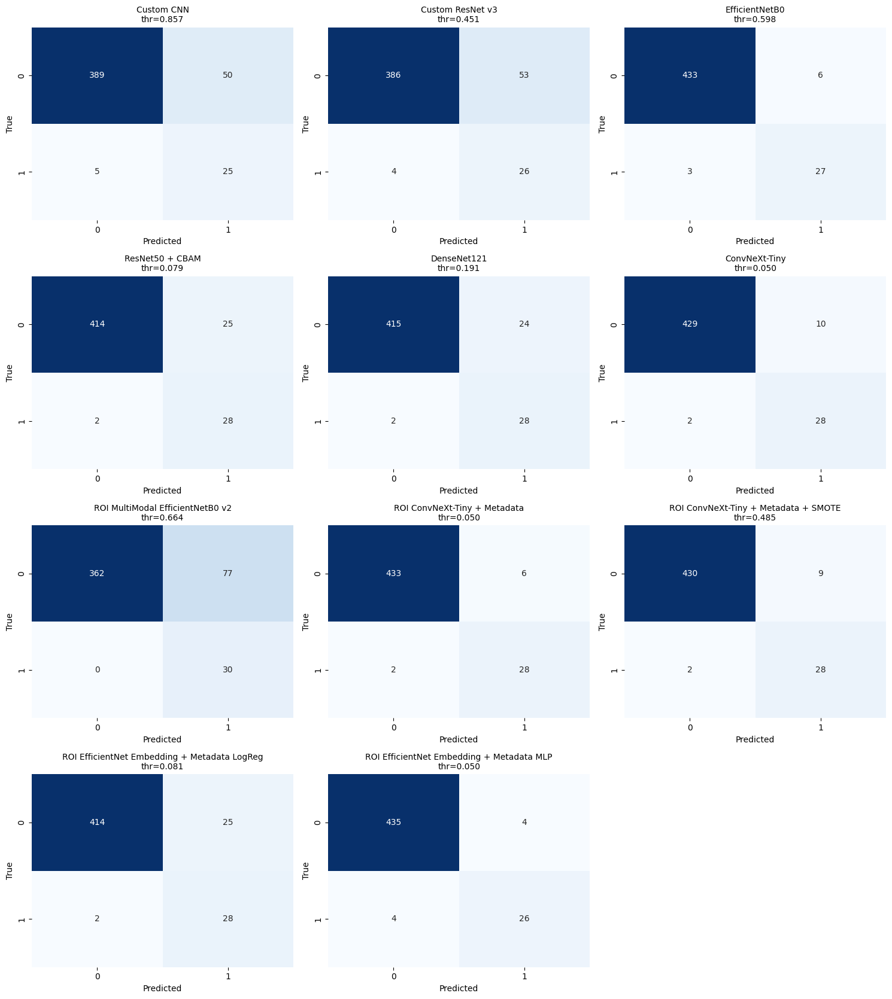

Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/dense_roi_eval_confusion_matrices.png


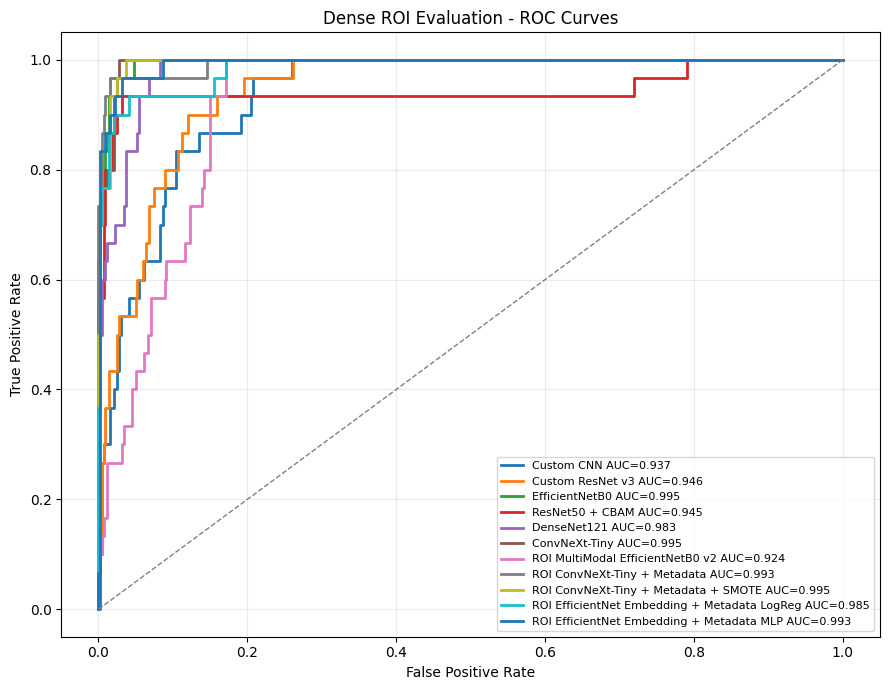

Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/dense_roi_eval_roc_curves.png


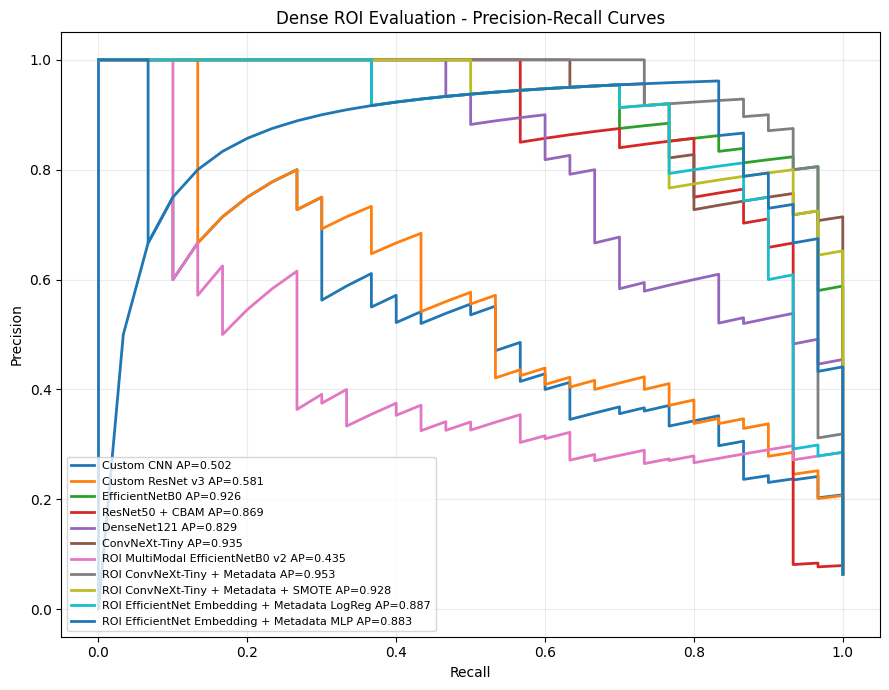

Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/dense_roi_eval_pr_curves.png


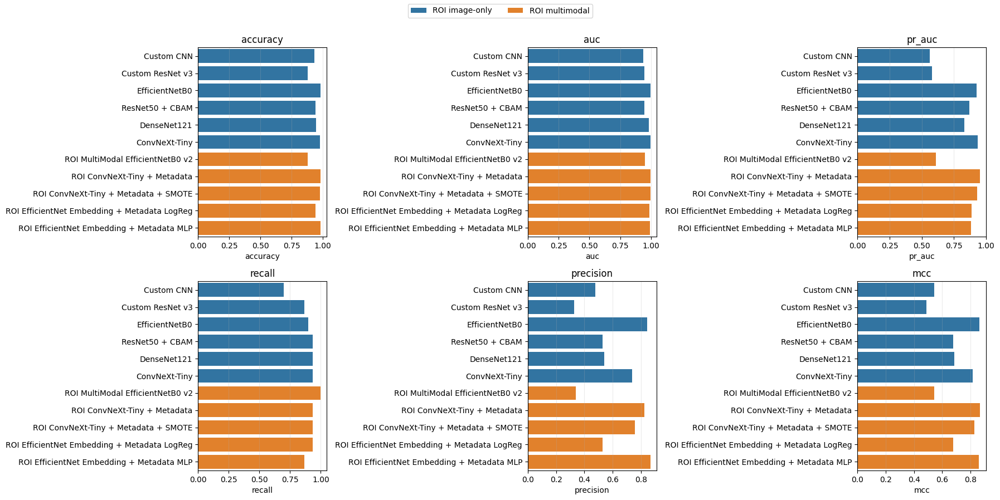

Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/dense_roi_eval_metric_bars.png


In [ ]:
# generate prediction curves and plots

DENSE_ROI_PREDICTION_REGISTRY = {
    'Custom CNN': {'kind': 'keras_image', 'checkpoint': 'ROI_CustomCNN'},
    # If the v3 checkpoint is absent, fall back...
    'Custom ResNet v3': {'kind': 'keras_image', 'checkpoint': 'ROI_CustomResNet_v3', 'fallback_checkpoint': 'ROI_CustomResNet'},
    'EfficientNetB0': {'kind': 'keras_image', 'checkpoint': 'ROI_EfficientNetB0_P2'},
    'ResNet50 + CBAM': {'kind': 'keras_cbam', 'checkpoint': 'ROI_ResNet50_CBAM_P2'},
    'DenseNet121': {'kind': 'keras_image', 'checkpoint': 'ROI_DenseNet121_P2'},
    'ConvNeXt-Tiny': {'kind': 'torch_convnext_image', 'checkpoint': 'CONTRIB_ConvNeXtTiny_ROI'},
    'ROI MultiModal EfficientNetB0 v2': {'kind': 'keras_multimodal', 'checkpoint': 'ROI_MultiModalEfficientNet_v2_P2'},
    'ROI ConvNeXt-Tiny + Metadata': {'kind': 'torch_convnext_mm', 'checkpoint': 'CONTRIB_MM_ConvNeXtTiny_ROI'},
    'ROI ConvNeXt-Tiny + Metadata + SMOTE': {'kind': 'torch_feature_mlp_convnext_mm', 'checkpoint': 'CONTRIB_MM_ConvNeXtTiny_ROI_SMOTE'},
    'ROI EfficientNet Embedding + Metadata LogReg': {'kind': 'roi_eff_embedding_logreg', 'artifact': 'best_ROIEmbeddingMM_EfficientNet_LogReg.joblib'},
    'ROI EfficientNet Embedding + Metadata MLP': {'kind': 'roi_eff_embedding_mlp', 'model': 'best_ROIEmbeddingMM_EfficientNet_MLP.keras', 'scaler': 'best_ROIEmbeddingMM_EfficientNet_MLP_scaler.joblib'},
}

# Some cleanup cells remove helper functions/classes from memory. These local
# fallbacks keep this dashboard runnable as long as the saved artifacts exist.
def _dense_torch_checkpoint_path(name):
    if 'contrib_checkpoint_path' in globals():
        return contrib_checkpoint_path(name)
    return os.path.join(OUTPUT_DIR, f'best_{name}.pt')

if 'load_torch_checkpoint_model' not in globals():
    def load_torch_checkpoint_model(model, checkpoint_name):
        ckpt = torch.load(_dense_torch_checkpoint_path(checkpoint_name), map_location=CONTRIB_DEVICE)
        model.load_state_dict(ckpt['model_state_dict'])
        return model.to(CONTRIB_DEVICE).eval()

if 'FeatureMLPBinary' not in globals():
    class FeatureMLPBinary(nn.Module):
        def __init__(self, input_dim, hidden_dim=128, dropout=0.35):
            super().__init__()
            self.net = nn.Sequential(
                nn.Linear(input_dim, hidden_dim),
                nn.BatchNorm1d(hidden_dim),
                nn.GELU(),
                nn.Dropout(dropout),
                nn.Linear(hidden_dim, 64),
                nn.GELU(),
                nn.Dropout(dropout),
                nn.Linear(64, 1),
            )

        def forward(self, x):
            return self.net(x).squeeze(1)

if 'extract_convnext_embeddings_from_loader' not in globals():
    @torch.no_grad()
    def extract_convnext_embeddings_from_loader(model, loader):
        model.eval()
        feats_all, labels_all = [], []
        for batch in loader:
            inputs, labels = batch
            labels = labels.to(CONTRIB_DEVICE, non_blocking=True).float()
            if isinstance(inputs, (tuple, list)):
                img_inputs = inputs[0].to(CONTRIB_DEVICE, non_blocking=True).float()
            else:
                img_inputs = inputs.to(CONTRIB_DEVICE, non_blocking=True).float()
            feats = model.extract_features(img_inputs)
            feats_all.append(feats.detach().cpu().numpy())
            labels_all.append(labels.detach().cpu().numpy())
        return np.concatenate(feats_all).astype(np.float32), np.concatenate(labels_all).astype(int)

def _dense_predict_torch_binary_model(model, loader):
    # Local inference path avoids depending on older globals...
    model.eval()
    probs, labels_out = [], []
    with torch.no_grad():
        for batch in loader:
            inputs, labels = batch
            labels = labels.to(CONTRIB_DEVICE, non_blocking=True).float()
            if isinstance(inputs, (tuple, list)):
                moved = tuple(x.to(CONTRIB_DEVICE, non_blocking=True).float() for x in inputs)
                logits = model(*moved)
            else:
                moved = inputs.to(CONTRIB_DEVICE, non_blocking=True).float()
                logits = model(moved)
            probs.append(torch.sigmoid(logits).detach().cpu().numpy())
            labels_out.append(labels.detach().cpu().numpy())
    return np.concatenate(labels_out).astype(int), np.concatenate(probs).astype(float)

def _dense_build_resnet50_cbam_transfer_local(input_shape=(224, 224, 3), weights='imagenet'):

    class _DenseResNet50Preprocess(layers.Layer):
        def call(self, inputs):
            return _resnet50_preprocess_input(inputs * 255.0)

    class _DenseChannelMean(layers.Layer):
        def call(self, inputs):
            return tf.reduce_mean(inputs, axis=-1, keepdims=True)

    class _DenseChannelMax(layers.Layer):
        def call(self, inputs):
            return tf.reduce_max(inputs, axis=-1, keepdims=True)

    def _channel_attention(x, ratio=8, name='final_cbam_channel'):
        channels = int(x.shape[-1])
        hidden = max(channels // ratio, 8)
        shared_dense_1 = layers.Dense(hidden, activation='relu', kernel_initializer='he_normal', name=f'{name}_shared_dense_1')
        shared_dense_2 = layers.Dense(channels, kernel_initializer='he_normal', name=f'{name}_shared_dense_2')
        avg_pool = layers.GlobalAveragePooling2D(name=f'{name}_avg_pool')(x)
        max_pool = layers.GlobalMaxPooling2D(name=f'{name}_max_pool')(x)
        avg_out = shared_dense_2(shared_dense_1(avg_pool))
        max_out = shared_dense_2(shared_dense_1(max_pool))
        attention = layers.Add(name=f'{name}_add')([avg_out, max_out])
        attention = layers.Activation('sigmoid', name=f'{name}_sigmoid')(attention)
        attention = layers.Reshape((1, 1, channels), name=f'{name}_reshape')(attention)
        return layers.Multiply(name=f'{name}_scale')([x, attention])

    def _spatial_attention(x, name='final_cbam_spatial'):
        avg_map = _DenseChannelMean(name=f'{name}_avg_map')(x)
        max_map = _DenseChannelMax(name=f'{name}_max_map')(x)
        concat = layers.Concatenate(axis=-1, name=f'{name}_concat')([avg_map, max_map])
        attention = layers.Conv2D(1, 7, padding='same', activation='sigmoid', kernel_initializer='he_normal', use_bias=False, name=f'{name}_conv7')(concat)
        return layers.Multiply(name=f'{name}_scale')([x, attention])

    inputs = layers.Input(shape=input_shape, name='img_input')
    x = _DenseResNet50Preprocess(name='resnet50_preprocess')(inputs)
    base = ResNet50(weights=weights, include_top=False, input_tensor=x)
    base.trainable = False
    x = _channel_attention(base.output, name='final_cbam_channel')
    x = _spatial_attention(x, name='final_cbam_spatial')
    x = layers.GlobalAveragePooling2D(name='gap_after_cbam')(x)
    x = layers.Dense(192, kernel_regularizer=regularizers.l2(1e-4), kernel_initializer='he_normal', name='cbam_dense')(x)
    x = layers.BatchNormalization(name='cbam_bn')(x)
    x = layers.Activation('relu', name='cbam_relu')(x)
    x = layers.Dropout(0.45, name='cbam_dropout')(x)
    outputs = layers.Dense(1, activation='sigmoid', name='output')(x)
    return models.Model(inputs, outputs, name='ROI_ResNet50_CBAM'), base

def _dense_load_resnet50_cbam_model(checkpoint_name):
    ckpt = Path(best_checkpoint_path(checkpoint_name))
    if not ckpt.exists():
        raise FileNotFoundError(f'Missing checkpoint: {ckpt}')
    # Avoid full-model deserialization because older CBAM checkpoints may contain Lambda layers.
    if 'build_resnet50_cbam_transfer' in globals():
        model, _ = build_resnet50_cbam_transfer(weights='imagenet')
    else:
        model, _ = _dense_build_resnet50_cbam_transfer_local(weights='imagenet')
    model.load_weights(ckpt)
    return model

def _dense_predict_resnet50_cbam(checkpoint_name):
    model = _dense_load_resnet50_cbam_model(checkpoint_name)
    prob = predict_model(
        model,
        X_roi_test.astype(np.float32, copy=False),
        batch_size=32,
        verbose=0,
        description=f'dense ROI eval {checkpoint_name}',
    ).ravel()
    del model
    tf.keras.backend.clear_session()
    gc.collect()
    return np.asarray(prob, dtype=np.float32), checkpoint_name

def _dense_load_keras_model(checkpoint_name):
    ckpt = Path(best_checkpoint_path(checkpoint_name))
    if not ckpt.exists():
        raise FileNotFoundError(f'Missing checkpoint: {ckpt}')
    def _load():
        try:
            return tf.keras.models.load_model(ckpt, compile=False)
        except ValueError as exc:
            if 'Lambda' in str(exc) or 'safe_mode' in str(exc):
                return tf.keras.models.load_model(ckpt, compile=False, safe_mode=False)
            raise
    return run_tf_work(_load, description=f'load {checkpoint_name}', fallback_to_cpu=False)

def _dense_predict_keras_image(checkpoint_name, fallback_checkpoint=None):
    used = checkpoint_name
    try:
        model = _dense_load_keras_model(checkpoint_name)
    except Exception as exc:
        if fallback_checkpoint is None:
            raise
        print(f'{checkpoint_name} unavailable for plotting ({type(exc).__name__}: {exc}). Falling back to {fallback_checkpoint}.')
        used = fallback_checkpoint
        model = _dense_load_keras_model(fallback_checkpoint)
    prob = predict_model(
        model,
        X_roi_test.astype(np.float32, copy=False),
        batch_size=32,
        verbose=0,
        description=f'dense ROI eval {used}',
    ).ravel()
    del model
    tf.keras.backend.clear_session()
    gc.collect()
    return np.asarray(prob, dtype=np.float32), used

def _dense_predict_keras_multimodal(checkpoint_name):
    model = _dense_load_keras_model(checkpoint_name)
    prob = predict_model(
        model,
        [X_roi_test.astype(np.float32, copy=False), X_tab_test.astype(np.float32, copy=False)],
        batch_size=32,
        verbose=0,
        description=f'dense ROI eval {checkpoint_name}',
    ).ravel()
    del model
    tf.keras.backend.clear_session()
    gc.collect()
    return np.asarray(prob, dtype=np.float32), checkpoint_name

def _dense_convnext_loader(X, tabular=None):
    y_dummy = np.zeros(len(X), dtype=np.float32)
    if tabular is None:
        dataset = ConvNeXtImageDataset(X, y_dummy, augment=False)
    else:
        dataset = ConvNeXtMultiModalDataset(X, tabular, y_dummy, augment=False)
    return DataLoader(
        dataset,
        batch_size=CONTRIB_BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=torch.cuda.is_available(),
    )

def _dense_predict_torch_convnext_image(checkpoint_name):
    model = TimmConvNeXtBinary(model_name=CONTRIB_MODEL_NAME, pretrained=False, dropout=0.45)
    model = load_torch_checkpoint_model(model, checkpoint_name)
    _, prob = _dense_predict_torch_binary_model(model, _dense_convnext_loader(X_roi_test))
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    gc.collect()
    return np.asarray(prob, dtype=np.float32), checkpoint_name

def _dense_predict_torch_convnext_mm(checkpoint_name):
    model = TimmConvNeXtMultiModalBinary(
        tabular_dim=X_tab_test.shape[1],
        model_name=CONTRIB_MODEL_NAME,
        pretrained=False,
        dropout=0.40,
    )
    model = load_torch_checkpoint_model(model, checkpoint_name)
    _, prob = _dense_predict_torch_binary_model(model, _dense_convnext_loader(X_roi_test, X_tab_test.astype(np.float32)))
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    gc.collect()
    return np.asarray(prob, dtype=np.float32), checkpoint_name

@torch.no_grad()
def _dense_extract_convnext_test_embeddings():
    if 'roi_test_embed' in globals():
        return np.asarray(roi_test_embed, dtype=np.float32)
    model = TimmConvNeXtBinary(model_name=CONTRIB_MODEL_NAME, pretrained=False, dropout=0.45)
    model = load_torch_checkpoint_model(model, 'CONTRIB_ConvNeXtTiny_ROI')
    feats, _ = extract_convnext_embeddings_from_loader(model, _dense_convnext_loader(X_roi_test))
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    gc.collect()
    return np.asarray(feats, dtype=np.float32)

def _dense_predict_torch_feature_mlp_convnext_mm(checkpoint_name):
    ckpt = torch.load(contrib_checkpoint_path(checkpoint_name), map_location=CONTRIB_DEVICE)
    model = FeatureMLPBinary(input_dim=int(ckpt['input_dim'])).to(CONTRIB_DEVICE)
    model.load_state_dict(ckpt['model_state_dict'])
    model.eval()
    test_embed = _dense_extract_convnext_test_embeddings()
    X_feat = np.concatenate([test_embed, X_tab_test.astype(np.float32)], axis=1).astype(np.float32)
    dataset = torch.utils.data.TensorDataset(
        torch.from_numpy(X_feat).float(),
        torch.zeros(len(X_feat)).float(),
    )
    loader = DataLoader(dataset, batch_size=256, shuffle=False)
    probs = []
    for xb, _ in loader:
        xb = xb.to(CONTRIB_DEVICE).float()
        probs.append(torch.sigmoid(model(xb)).detach().cpu().numpy())
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    gc.collect()
    return np.concatenate(probs).astype(np.float32), checkpoint_name

def _dense_get_roi_eff_tab_test_features():
    if 'X_roi_eff_tab_test' in globals():
        return np.asarray(X_roi_eff_tab_test, dtype=np.float32)
    if 'extract_roi_efficientnet_embeddings' not in globals():
        raise RuntimeError('Run Section 5C helpers first so EfficientNet ROI embeddings can be created.')
    _, _, test_embed = extract_roi_efficientnet_embeddings(force_recompute=False)
    return np.concatenate([test_embed, X_tab_test.astype(np.float32)], axis=1).astype(np.float32)

def _dense_predict_roi_eff_logreg(artifact_name):
    artifact = joblib.load(Path(OUTPUT_DIR) / artifact_name)
    X_dense = _dense_get_roi_eff_tab_test_features()
    X_scaled = artifact['scaler'].transform(X_dense).astype(np.float32)
    prob = artifact['model'].predict_proba(X_scaled)[:, 1]
    return np.asarray(prob, dtype=np.float32), artifact_name

def _dense_predict_roi_eff_mlp(model_name, scaler_name):
    scaler_artifact = joblib.load(Path(OUTPUT_DIR) / scaler_name)
    scaler = scaler_artifact['scaler'] if isinstance(scaler_artifact, dict) and 'scaler' in scaler_artifact else scaler_artifact
    X_dense = _dense_get_roi_eff_tab_test_features()
    X_scaled = scaler.transform(X_dense).astype(np.float32)
    with tf.device('/CPU:0'):
        model = tf.keras.models.load_model(Path(OUTPUT_DIR) / model_name, compile=False)
        prob = model.predict(X_scaled, batch_size=256, verbose=0).ravel()
    del model
    gc.collect()
    return np.asarray(prob, dtype=np.float32), model_name

def _dense_predict_model(display_name, spec):
    kind = spec['kind']
    if kind == 'keras_image':
        return _dense_predict_keras_image(spec['checkpoint'], spec.get('fallback_checkpoint'))
    if kind == 'keras_cbam':
        return _dense_predict_resnet50_cbam(spec['checkpoint'])
    if kind == 'keras_multimodal':
        return _dense_predict_keras_multimodal(spec['checkpoint'])
    if kind == 'torch_convnext_image':
        return _dense_predict_torch_convnext_image(spec['checkpoint'])
    if kind == 'torch_convnext_mm':
        return _dense_predict_torch_convnext_mm(spec['checkpoint'])
    if kind == 'torch_feature_mlp_convnext_mm':
        return _dense_predict_torch_feature_mlp_convnext_mm(spec['checkpoint'])
    if kind == 'roi_eff_embedding_logreg':
        return _dense_predict_roi_eff_logreg(spec['artifact'])
    if kind == 'roi_eff_embedding_mlp':
        return _dense_predict_roi_eff_mlp(spec['model'], spec['scaler'])
    raise ValueError(f'Unknown dense ROI eval model kind: {kind}')

prediction_probs = {}
prediction_sources = {}
skipped_predictions = []
for display_name in dense_roi_all_models_df['display_model'].astype(str).tolist():
    spec = DENSE_ROI_PREDICTION_REGISTRY.get(display_name)
    if spec is None:
        skipped_predictions.append({'display_model': display_name, 'reason': 'not in prediction registry'})
        continue
    try:
        prob, source = _dense_predict_model(display_name, spec)
        if len(prob) != len(y_test_osteo):
            raise ValueError(f'Prediction length {len(prob)} != test labels {len(y_test_osteo)}')
        prediction_probs[display_name] = np.asarray(prob, dtype=np.float32)
        prediction_sources[display_name] = source
        print(f'Predictions ready: {display_name} ({source})')
    except Exception as exc:
        skipped_predictions.append({'display_model': display_name, 'reason': f'{type(exc).__name__}: {exc}'})
        print(f'Skipped probability plots for {display_name}: {type(exc).__name__}: {exc}')

if prediction_probs:
    safe_npz = {name.replace(' ', '_').replace('+', 'plus').replace('-', '_'): prob for name, prob in prediction_probs.items()}
    np.savez_compressed(os.path.join(OUTPUT_DIR, 'dense_roi_eval_predictions.npz'), **safe_npz)
    print(f"Saved: {OUTPUT_DIR}/dense_roi_eval_predictions.npz")
else:
    print('No model probabilities were regenerated; plot outputs will be skipped.')

skipped_predictions_df = pd.DataFrame(skipped_predictions)
if not skipped_predictions_df.empty:
    skipped_predictions_df.to_csv(os.path.join(OUTPUT_DIR, 'dense_roi_eval_prediction_skips.csv'), index=False)
    display(skipped_predictions_df)

plot_items = []
for _, row in dense_roi_all_models_df.iterrows():
    name = str(row['display_model'])
    if name in prediction_probs and 'threshold' in row.index and pd.notna(row['threshold']):
        plot_items.append((name, prediction_probs[name], float(row['threshold'])))

if plot_items:
    n = len(plot_items)
    ncols = 3
    nrows = int(math.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.2 * nrows), squeeze=False)
    for ax in axes.ravel():
        ax.axis('off')
    for ax, (name, prob, thr) in zip(axes.ravel(), plot_items):
        ax.axis('on')
        pred = (np.asarray(prob) >= thr).astype(int)
        cm = confusion_matrix(y_test_osteo, pred, labels=[0, 1])
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax)
        ax.set_title(f'{name}\nthr={thr:.3f}', fontsize=10)
        ax.set_xlabel('Predicted')
        ax.set_ylabel('True')
    plt.tight_layout()
    cm_path = os.path.join(OUTPUT_DIR, 'dense_roi_eval_confusion_matrices.png')
    plt.savefig(cm_path, dpi=150)
    plt.show()
    print(f'Saved: {cm_path}')

    fig, ax = plt.subplots(figsize=(9, 7))
    for name, prob, _ in plot_items:
        fpr, tpr, _ = roc_curve(y_test_osteo, prob)
        auc_val = roc_auc_score(y_test_osteo, prob) if len(np.unique(y_test_osteo)) == 2 else np.nan
        ax.plot(fpr, tpr, lw=2, label=f'{name} AUC={auc_val:.3f}')
    ax.plot([0, 1], [0, 1], '--', color='gray', lw=1)
    ax.set_title('Dense ROI Evaluation - ROC Curves')
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
    plt.tight_layout()
    roc_path = os.path.join(OUTPUT_DIR, 'dense_roi_eval_roc_curves.png')
    plt.savefig(roc_path, dpi=150)
    plt.show()
    print(f'Saved: {roc_path}')

    fig, ax = plt.subplots(figsize=(9, 7))
    for name, prob, _ in plot_items:
        prec, rec, _ = precision_recall_curve(y_test_osteo, prob)
        ap_val = average_precision_score(y_test_osteo, prob) if len(np.unique(y_test_osteo)) == 2 else np.nan
        ax.plot(rec, prec, lw=2, label=f'{name} AP={ap_val:.3f}')
    ax.set_title('Dense ROI Evaluation - Precision-Recall Curves')
    ax.set_xlabel('Recall')
    ax.set_ylabel('Precision')
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
    plt.tight_layout()
    pr_path = os.path.join(OUTPUT_DIR, 'dense_roi_eval_pr_curves.png')
    plt.savefig(pr_path, dpi=150)
    plt.show()
    print(f'Saved: {pr_path}')

bar_metrics = [m for m in ['accuracy', 'auc', 'pr_auc', 'recall', 'precision', 'mcc'] if m in dense_roi_all_models_df.columns]
if bar_metrics:
    bar_df = dense_roi_all_models_df[['display_model', 'model_type'] + bar_metrics].copy()
    fig, axes = plt.subplots(2, 3, figsize=(18, 9), squeeze=False)
    for ax, metric in zip(axes.ravel(), bar_metrics):
        sns.barplot(data=bar_df, y='display_model', x=metric, hue='model_type', dodge=False, ax=ax)
        ax.set_title(metric)
        ax.set_xlabel(metric)
        ax.set_ylabel('')
        ax.grid(axis='x', alpha=0.25)
        ax.legend_.remove() if ax.get_legend() else None
    for ax in axes.ravel()[len(bar_metrics):]:
        ax.axis('off')
    handles, labels = axes.ravel()[0].get_legend_handles_labels()
    if handles:
        fig.legend(handles, labels, loc='upper center', ncol=2)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    bars_path = os.path.join(OUTPUT_DIR, 'dense_roi_eval_metric_bars.png')
    plt.savefig(bars_path, dpi=150)
    plt.show()
    print(f'Saved: {bars_path}')


We evaluate ConvNeXt image-only, multimodal, and SMOTE embedding classifiers, comparing them against each other.


Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/contrib_convnext_roi_model_comparison.csv
Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/contrib_convnext_roi_ablation_summary.csv
Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/contrib_convnext_roi_thresholds.csv


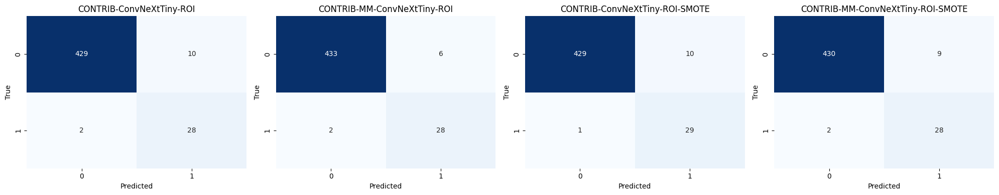

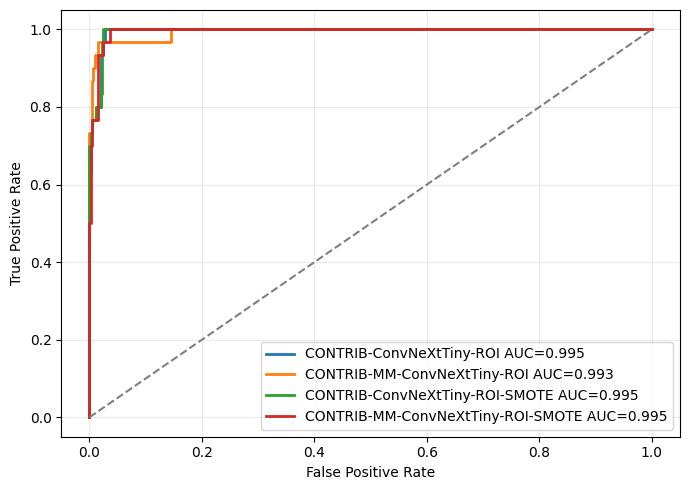

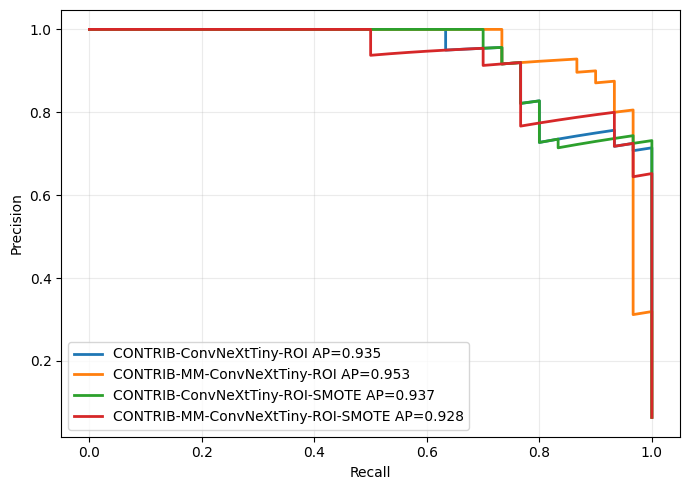

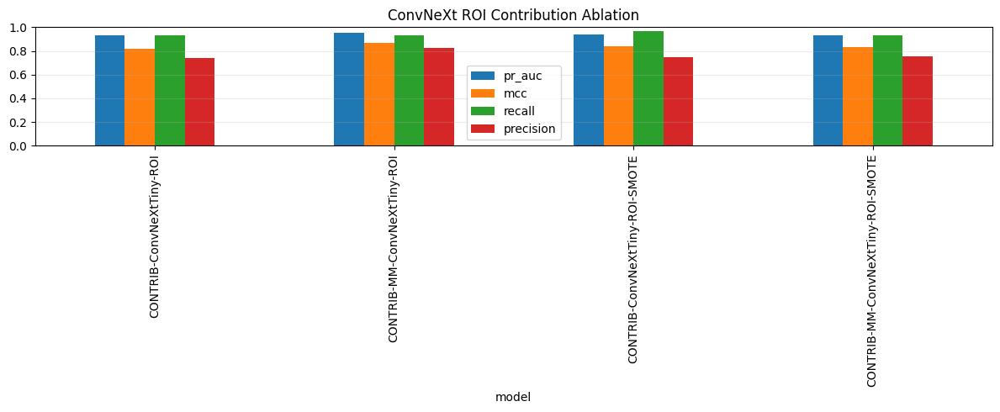

Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/contrib_convnext_roi_ablation_chart.png


,accuracy,balanced_acc,precision,recall,specificity,f1,macro_f1,mcc,auc,pr_auc,npv,threshold
model,,,,,,,,,,,,
ROI-CustomCNN,0.9318,0.8238,0.4773,0.7000,0.9476,0.5676,0.7653,0.5435,0.9359,0.5605,0.9788,0.8569
ROI-CustomResNet,0.8529,0.8748,0.2903,0.9000,0.8497,0.4390,0.6772,0.4601,0.9403,0.5552,0.9920,0.6707
ROI-EfficientNetB0,0.9829,0.9443,0.8438,0.9000,0.9886,0.8710,0.9309,0.8624,0.9943,0.9264,0.9931,0.5977
ROI-CustomCNN-v2,0.7953,0.8285,0.2203,0.8667,0.7904,0.3514,0.6149,0.3705,0.9306,0.5271,0.9886,0.5743
ROI-CustomResNet-v2,0.7910,0.8263,0.2167,0.8667,0.7859,0.3467,0.6112,0.3659,0.9182,0.4928,0.9885,0.6162
ROI-ResNet50V2,0.9254,0.8980,0.4561,0.8667,0.9294,0.5977,0.7783,0.5961,0.9702,0.8122,0.9903,0.0500
ROI-DenseNet121,0.9446,0.9393,0.5385,0.9333,0.9453,0.6829,0.8263,0.6848,0.9828,0.8288,0.9952,0.1912
CONTRIB-ConvNeXtTiny-ROI,0.9744,0.9553,0.7368,0.9333,0.9772,0.8235,0.9049,0.8165,0.9948,0.9345,0.9954,0.0500
CONTRIB-MM-ConvNeXtTiny-ROI,0.9829,0.9598,0.8235,0.9333,0.9863,0.8750,0.9329,0.8678,0.9935,0.9532,0.9954,0.0500


20620

In [ ]:
# evaluate ConvNeXt models
def load_torch_checkpoint_model(model, checkpoint_name):
    ckpt = torch.load(contrib_checkpoint_path(checkpoint_name), map_location=CONTRIB_DEVICE)
    model.load_state_dict(ckpt['model_state_dict'])
    return model.to(CONTRIB_DEVICE).eval()

def load_feature_mlp_checkpoint(checkpoint_name):
    ckpt = torch.load(contrib_checkpoint_path(checkpoint_name), map_location=CONTRIB_DEVICE)
    model = FeatureMLPBinary(input_dim=int(ckpt['input_dim'])).to(CONTRIB_DEVICE)
    model.load_state_dict(ckpt['model_state_dict'])
    return model.eval()

def _read_optional_comparison(path):
    return pd.read_csv(path) if os.path.exists(path) else pd.DataFrame()

def save_contrib_confusion_matrices(results_with_probs, y_true, output_path):
    n = len(results_with_probs)
    if n == 0:
        return
    fig, axes = plt.subplots(1, n, figsize=(5 * n, 4), squeeze=False)
    for ax, (name, prob, thr) in zip(axes.ravel(), results_with_probs):
        pred = (prob >= thr).astype(int)
        cm = confusion_matrix(y_true, pred, labels=[0, 1])
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax)
        ax.set_title(name)
        ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    plt.tight_layout()
    plt.savefig(output_path, dpi=150)
    plt.show()

def save_contrib_roc_pr_curves(results_with_probs, y_true, roc_path, pr_path):
    if not results_with_probs:
        return
    fig_roc, ax_roc = plt.subplots(figsize=(7, 5))
    fig_pr, ax_pr = plt.subplots(figsize=(7, 5))
    for name, prob, _ in results_with_probs:
        fpr, tpr, _ = roc_curve(y_true, prob)
        prec, rec, _ = precision_recall_curve(y_true, prob)
        ax_roc.plot(fpr, tpr, lw=2, label=f'{name} AUC={roc_auc_score(y_true, prob):.3f}')
        ax_pr.plot(rec, prec, lw=2, label=f'{name} AP={average_precision_score(y_true, prob):.3f}')
    ax_roc.plot([0, 1], [0, 1], '--', color='gray')
    ax_roc.set_xlabel('False Positive Rate'); ax_roc.set_ylabel('True Positive Rate'); ax_roc.legend(); ax_roc.grid(alpha=0.25)
    ax_pr.set_xlabel('Recall'); ax_pr.set_ylabel('Precision'); ax_pr.legend(); ax_pr.grid(alpha=0.25)
    fig_roc.tight_layout(); fig_pr.tight_layout()
    fig_roc.savefig(roc_path, dpi=150); fig_pr.savefig(pr_path, dpi=150)
    plt.show()

contrib_results = []
contrib_threshold_rows = []
contrib_probs_for_plots = []

# End-to-end ROI image-only model
eval_img_model = load_torch_checkpoint_model(
    TimmConvNeXtBinary(model_name=CONTRIB_MODEL_NAME, pretrained=False, dropout=0.45),
    'CONTRIB_ConvNeXtTiny_ROI')
y_val_true, y_val_prob = predict_torch_binary_model(eval_img_model, val_loader_roi)
thr = find_best_threshold_on_val(y_val_true, y_val_prob)
y_test_true, y_test_prob = predict_torch_binary_model(eval_img_model, test_loader_roi)
res = evaluate_torch_binary_predictions(y_test_true, y_test_prob, 'CONTRIB-ConvNeXtTiny-ROI', threshold=thr)
contrib_results.append(res); contrib_threshold_rows.append({'model': res['model'], 'threshold': thr}); contrib_probs_for_plots.append((res['model'], y_test_prob, thr))
del eval_img_model

# End-to-end ROI multimodal model
if CONTRIB_HAS_METADATA and os.path.exists(contrib_checkpoint_path('CONTRIB_MM_ConvNeXtTiny_ROI')):
    eval_mm_model = load_torch_checkpoint_model(
        TimmConvNeXtMultiModalBinary(tabular_dim=TABULAR_DIM_CONTRIB, model_name=CONTRIB_MODEL_NAME, pretrained=False, dropout=0.40),
        'CONTRIB_MM_ConvNeXtTiny_ROI')
    y_val_true_mm, y_val_prob_mm = predict_torch_binary_model(eval_mm_model, val_loader_roi_mm)
    thr_mm = find_best_threshold_on_val(y_val_true_mm, y_val_prob_mm)
    y_test_true_mm, y_test_prob_mm = predict_torch_binary_model(eval_mm_model, test_loader_roi_mm)
    res_mm = evaluate_torch_binary_predictions(y_test_true_mm, y_test_prob_mm, 'CONTRIB-MM-ConvNeXtTiny-ROI', threshold=thr_mm)
    contrib_results.append(res_mm); contrib_threshold_rows.append({'model': res_mm['model'], 'threshold': thr_mm}); contrib_probs_for_plots.append((res_mm['model'], y_test_prob_mm, thr_mm))
    del eval_mm_model

# SMOTE image embedding classifier
if 'roi_val_embed' in globals() and os.path.exists(contrib_checkpoint_path('CONTRIB_ConvNeXtTiny_ROI_SMOTE')):
    smote_img_eval = load_feature_mlp_checkpoint('CONTRIB_ConvNeXtTiny_ROI_SMOTE')
    smote_val_prob = predict_feature_mlp(smote_img_eval, roi_val_embed)
    thr_smote = find_best_threshold_on_val(y_embed_val, smote_val_prob)
    smote_test_prob = predict_feature_mlp(smote_img_eval, roi_test_embed)
    res_smote = evaluate_torch_binary_predictions(y_embed_test, smote_test_prob, 'CONTRIB-ConvNeXtTiny-ROI-SMOTE', threshold=thr_smote)
    contrib_results.append(res_smote); contrib_threshold_rows.append({'model': res_smote['model'], 'threshold': thr_smote}); contrib_probs_for_plots.append((res_smote['model'], smote_test_prob, thr_smote))

# SMOTE image embedding + metadata classifier
if CONTRIB_HAS_METADATA and 'roi_val_embed_mm' in globals() and os.path.exists(contrib_checkpoint_path('CONTRIB_MM_ConvNeXtTiny_ROI_SMOTE')):
    smote_mm_eval = load_feature_mlp_checkpoint('CONTRIB_MM_ConvNeXtTiny_ROI_SMOTE')
    smote_mm_val_prob = predict_feature_mlp(smote_mm_eval, roi_val_embed_mm)
    thr_smote_mm = find_best_threshold_on_val(y_embed_val, smote_mm_val_prob)
    smote_mm_test_prob = predict_feature_mlp(smote_mm_eval, roi_test_embed_mm)
    res_smote_mm = evaluate_torch_binary_predictions(y_embed_test, smote_mm_test_prob, 'CONTRIB-MM-ConvNeXtTiny-ROI-SMOTE', threshold=thr_smote_mm)
    contrib_results.append(res_smote_mm); contrib_threshold_rows.append({'model': res_smote_mm['model'], 'threshold': thr_smote_mm}); contrib_probs_for_plots.append((res_smote_mm['model'], smote_mm_test_prob, thr_smote_mm))

contrib_results_df = pd.DataFrame(contrib_results)
existing_frames = [
    _read_optional_comparison(os.path.join(OUTPUT_DIR, 'roi_model_comparison.csv')),
    _read_optional_comparison(os.path.join(OUTPUT_DIR, 'roi_pretrained_resnet_densenet_comparison.csv')),
]
comparison_df = pd.concat([df for df in existing_frames + [contrib_results_df] if not df.empty], ignore_index=True)
if 'model' in comparison_df.columns:
    comparison_df = comparison_df.drop_duplicates('model', keep='last')
metric_cols = ['model','accuracy','balanced_acc','precision','recall','specificity','f1','macro_f1','mcc','auc','pr_auc','npv','threshold']
metric_cols = [c for c in metric_cols if c in comparison_df.columns]
comparison_df = comparison_df[metric_cols]

comparison_out = os.path.join(OUTPUT_DIR, 'contrib_convnext_roi_model_comparison.csv')
comparison_df.to_csv(comparison_out, index=False)
print(f'Saved: {comparison_out}')

ablation_df = contrib_results_df.copy()
ablation_out = os.path.join(OUTPUT_DIR, 'contrib_convnext_roi_ablation_summary.csv')
ablation_df.to_csv(ablation_out, index=False)
print(f'Saved: {ablation_out}')

thresholds_df = pd.DataFrame(contrib_threshold_rows)
thresholds_out = os.path.join(OUTPUT_DIR, 'contrib_convnext_roi_thresholds.csv')
thresholds_df.to_csv(thresholds_out, index=False)
print(f'Saved: {thresholds_out}')

save_contrib_confusion_matrices(contrib_probs_for_plots, y_test_osteo, os.path.join(OUTPUT_DIR, 'contrib_convnext_roi_confusion_matrices.png'))
save_contrib_roc_pr_curves(contrib_probs_for_plots, y_test_osteo, os.path.join(OUTPUT_DIR, 'contrib_convnext_roi_roc_curves.png'), os.path.join(OUTPUT_DIR, 'contrib_convnext_roi_pr_curves.png'))

if not ablation_df.empty:
    plot_cols = [c for c in ['pr_auc', 'mcc', 'recall', 'precision'] if c in ablation_df.columns]
    ax = ablation_df.set_index('model')[plot_cols].plot(kind='bar', figsize=(12, 5))
    ax.set_title('ConvNeXt ROI Contribution Ablation')
    ax.set_ylim(0, 1)
    ax.grid(axis='y', alpha=0.25)
    plt.tight_layout()
    chart_out = os.path.join(OUTPUT_DIR, 'contrib_convnext_roi_ablation_chart.png')
    plt.savefig(chart_out, dpi=150)
    plt.show()
    print(f'Saved: {chart_out}')

display(comparison_df.set_index('model').style.format('{:.4f}').highlight_max(color='lightgreen', axis=0))
torch.cuda.empty_cache() if torch.cuda.is_available() else None
gc.collect()



# SECTION 3 - Multiclass Classification
Multiclass models, evaluation, and multimodal fusion comparisons.


## Subsection 3.1 - ROI Models (Image-Only Multiclass)
Training and evaluation of image-only multiclass models on cropped ROI splits.


We configure multiclass label structures and leakage guards for no_tumor, benign, and malignant classes.


In [ ]:
# CELL 5F-1: Multiclass labels, output folder, and leakage guard



required_5f = [
    'df_valid', 'train_idx', 'val_idx', 'test_idx',
    'X_roi_train', 'X_roi_val', 'X_roi_test',
    'OUTPUT_DIR', 'IMG_SIZE',
]
missing_5f = [name for name in required_5f if name not in globals()]
if missing_5f:
    raise RuntimeError(
        'SECTION 5F requires Dataset 1 preprocessing and CELL 5A-1 ROI arrays first. '
        f'Missing: {missing_5f}'
    )

MULTICLASS_OUTPUT_DIR = Path(OUTPUT_DIR) / 'multiclass_outputs'
MULTICLASS_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MC_OUTPUT_DIR = MULTICLASS_OUTPUT_DIR  # local alias used only inside Section 5F

MC_RANDOM_SEED = 42
MC_BATCH_SIZE = int(globals().get('BATCH_SIZE', 16))
MC_EPOCHS_SCRATCH = int(globals().get('EPOCHS_SCRATCH', 50))
MC_EPOCHS_TRANSFER_P1 = 18
MC_EPOCHS_TRANSFER_P2 = int(globals().get('EPOCHS_FINETUNE', 20))
MC_EPOCHS_CONVNEXT = 30
MC_PATIENCE = 8
MC_TRANSFER_UNFREEZE_LAST = 20

MC_CLASS_NAMES = [
    'no_tumor_or_unlabeled',
    'giant cell tumor',
    'multiple osteochondromas',
    'osteochondroma',
    'osteofibroma',
    'osteosarcoma',
    'other bt',
    'other mt',
    'simple bone cyst',
    'synovial osteochondroma',
]
MC_CLASS_TO_ID = {name: i for i, name in enumerate(MC_CLASS_NAMES)}
MC_NUM_CLASSES = len(MC_CLASS_NAMES)

def normalize_multiclass_tumor_label(value):
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return 'no_tumor_or_unlabeled'
    text = str(value).strip().lower().replace('_', ' ')
    text = ' '.join(text.split())
    missing_like = {'', 'nan', 'none', 'unknown', 'unk', 'unlabeled', 'not specified'}
    return 'no_tumor_or_unlabeled' if text in missing_like else text

mc_labels_text = df_valid['tumor_type'].apply(normalize_multiclass_tumor_label)
unknown_mc_labels = sorted(set(mc_labels_text) - set(MC_CLASS_NAMES))
if unknown_mc_labels:
    raise ValueError(f'Unexpected multiclass labels in Dataset 1: {unknown_mc_labels}')

mc_y_all = mc_labels_text.map(MC_CLASS_TO_ID).astype(np.int32).values
mc_y_train = mc_y_all[train_idx]
mc_y_val = mc_y_all[val_idx]
mc_y_test = mc_y_all[test_idx]

if len(mc_y_train) != len(X_roi_train) or len(mc_y_val) != len(X_roi_val) or len(mc_y_test) != len(X_roi_test):
    raise ValueError('Multiclass labels do not align with ROI train/val/test arrays.')

mc_class_weights_arr = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(MC_NUM_CLASSES),
    y=mc_y_train,
).astype(np.float32)
mc_class_weight_dict = {int(i): float(w) for i, w in enumerate(mc_class_weights_arr)}

multiclass_class_mapping_df = pd.DataFrame({
    'class_id': np.arange(MC_NUM_CLASSES, dtype=int),
    'class_name': MC_CLASS_NAMES,
    'class_weight': mc_class_weights_arr,
})
multiclass_class_mapping_df.to_csv(MULTICLASS_OUTPUT_DIR / 'multiclass_class_mapping.csv', index=False)

summary_rows = []
for split_name, y_split in [('train', mc_y_train), ('val', mc_y_val), ('test', mc_y_test)]:
    counts = np.bincount(y_split, minlength=MC_NUM_CLASSES)
    for class_id, count in enumerate(counts):
        summary_rows.append({
            'split': split_name,
            'class_id': int(class_id),
            'class_name': MC_CLASS_NAMES[class_id],
            'count': int(count),
            'percent': float(100.0 * count / max(len(y_split), 1)),
        })
multiclass_dataset_split_summary_df = pd.DataFrame(summary_rows)
multiclass_dataset_split_summary_df.to_csv(MULTICLASS_OUTPUT_DIR / 'multiclass_dataset_split_summary.csv', index=False)

MC_KERAS_MODELS = [
    'MC_ROI_CustomCNN',
    'MC_ROI_CustomResNet',
    'MC_ROI_EfficientNetB0',
    'MC_ROI_DenseNet121',
    'MC_ROI_ResNet50_CBAM',
]
MC_TORCH_MODELS = ['MC_ROI_ConvNeXtTiny']
MC_ALL_MODEL_NAMES = MC_KERAS_MODELS + MC_TORCH_MODELS
MC_EXPECTED_ARTIFACT_PATHS = [
    str(MULTICLASS_OUTPUT_DIR / 'best_MC_ROI_CustomCNN.keras'),
    str(MULTICLASS_OUTPUT_DIR / 'best_MC_ROI_CustomResNet.keras'),
    str(MULTICLASS_OUTPUT_DIR / 'best_MC_ROI_EfficientNetB0.keras'),
    str(MULTICLASS_OUTPUT_DIR / 'best_MC_ROI_DenseNet121.keras'),
    str(MULTICLASS_OUTPUT_DIR / 'best_MC_ROI_ResNet50_CBAM.keras'),
    str(MULTICLASS_OUTPUT_DIR / 'best_MC_ROI_ConvNeXtTiny.pt'),
    str(MULTICLASS_OUTPUT_DIR / 'multiclass_class_mapping.csv'),
    str(MULTICLASS_OUTPUT_DIR / 'multiclass_dataset_split_summary.csv'),
    str(MULTICLASS_OUTPUT_DIR / 'multiclass_roi_model_comparison.csv'),
    str(MULTICLASS_OUTPUT_DIR / 'multiclass_roi_classification_report.csv'),
    str(MULTICLASS_OUTPUT_DIR / 'multiclass_roi_confusion_matrices.png'),
    str(MULTICLASS_OUTPUT_DIR / 'multiclass_roi_roc_curves.png'),
    str(MULTICLASS_OUTPUT_DIR / 'multiclass_roi_predictions.npz'),
]

print('=' * 78)
print('SECTION 5F: ROI MULTICLASS CLASSIFICATION')
print('=' * 78)
print(f'Multiclass output folder: {MULTICLASS_OUTPUT_DIR}')
print(f'Classes                 : {MC_NUM_CLASSES}')
print(f'ROI train/val/test      : {X_roi_train.shape} | {X_roi_val.shape} | {X_roi_test.shape}')
print('Included models          : ' + ', '.join(MC_ALL_MODEL_NAMES))
print('D3 usage                 : none. Dataset 1 ROI arrays only.')
print('=' * 78)
display(multiclass_dataset_split_summary_df.pivot(index='class_name', columns='split', values='count').fillna(0).astype(int))


SECTION 5F: ROI MULTICLASS CLASSIFICATION
Multiclass output folder: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs
Classes                 : 10
ROI train/val/test      : (2659, 224, 224, 3) | (618, 224, 224, 3) | (469, 224, 224, 3)
Included models          : MC_ROI_CustomCNN, MC_ROI_CustomResNet, MC_ROI_EfficientNetB0, MC_ROI_DenseNet121, MC_ROI_ResNet50_CBAM, MC_ROI_ConvNeXtTiny
D3 usage                 : none. Dataset 1 ROI arrays only.


split,test,train,val
class_name,,,
giant cell tumor,9,67,17
multiple osteochondromas,26,190,47
no_tumor_or_unlabeled,282,1315,282
osteochondroma,76,542,136
osteofibroma,4,32,8
osteosarcoma,30,214,53
other bt,12,82,21
other mt,4,33,8
simple bone cyst,21,148,37


We implement multiclass network builders and custom callbacks for training models.


In [ ]:
# Keras multiclass model builders and training utilities

class MulticlassMacroF1Callback(tf.keras.callbacks.Callback):
    def __init__(self, X_val_data, y_val_data, checkpoint_path, batch_size=32):
        super().__init__()
        self.X_val_data = X_val_data.astype(np.float32, copy=False)
        self.y_val_data = np.asarray(y_val_data).astype(int)
        self.checkpoint_path = str(checkpoint_path)
        self.batch_size = int(batch_size)
        self.best_macro_f1 = -np.inf

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        probs = self.model.predict(self.X_val_data, batch_size=self.batch_size, verbose=0)
        preds = np.argmax(probs, axis=1)
        macro_f1 = f1_score(self.y_val_data, preds, average='macro', zero_division=0)
        logs['val_macro_f1'] = macro_f1
        print(f' - val_macro_f1: {macro_f1:.4f}')
        if macro_f1 > self.best_macro_f1:
            self.best_macro_f1 = macro_f1
            self.model.save(self.checkpoint_path)
            print(f'   Saved best multiclass checkpoint: {self.checkpoint_path}')

def mc_checkpoint_path(model_name):
    return MULTICLASS_OUTPUT_DIR / f'best_{model_name}.keras'

def mc_torch_checkpoint_path(model_name):
    return MULTICLASS_OUTPUT_DIR / f'best_{model_name}.pt'

def compile_mc_keras_model(model, lr=5e-5):
    optimizer_cls = getattr(tf.keras.optimizers, 'AdamW', None)
    optimizer = optimizer_cls(learning_rate=lr, weight_decay=1e-5, clipnorm=1.0) if optimizer_cls else tf.keras.optimizers.Adam(learning_rate=lr, clipnorm=1.0)
    model.compile(
        optimizer=optimizer,
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=[
            tf.keras.metrics.SparseCategoricalAccuracy(name='accuracy'),
            tf.keras.metrics.SparseTopKCategoricalAccuracy(k=2, name='top2_accuracy'),
            tf.keras.metrics.SparseTopKCategoricalAccuracy(k=3, name='top3_accuracy'),
        ],
    )
    return model

def mc_augmented_keras_generator(X, y, batch_size=MC_BATCH_SIZE, seed=42):
    rng = np.random.default_rng(seed)
    X = np.asarray(X)
    y = np.asarray(y).astype(np.int32)
    while True:
        idx = rng.integers(0, len(y), size=batch_size)
        batch = X[idx].astype(np.float32, copy=False)
        if 'aug_gen' in globals():
            batch = np.asarray([
                np.clip(aug_gen.random_transform(img), 0.0, 1.0)
                for img in batch
            ], dtype=np.float32)
        labels = y[idx]
        sample_weight = np.asarray([mc_class_weight_dict[int(label)] for label in labels], dtype=np.float32)
        yield batch, labels, sample_weight

def _mc_head(x, num_classes=MC_NUM_CLASSES, units=192, dropout=0.45):
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(units, kernel_initializer='he_normal', kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Dropout(dropout)(x)
    return layers.Dense(num_classes, activation='softmax', name='mc_output')(x)

def build_mc_custom_cnn(input_shape=(224, 224, 3), num_classes=MC_NUM_CLASSES):
    inputs = layers.Input(shape=input_shape, name='mc_roi_image')
    x = inputs
    for filters, drop in [(32, 0.08), (64, 0.12), (128, 0.18), (160, 0.22)]:
        x = layers.Conv2D(filters, 3, padding='same', kernel_initializer='he_normal', kernel_regularizer=regularizers.l2(1e-4))(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
        x = layers.Conv2D(filters, 3, padding='same', kernel_initializer='he_normal', kernel_regularizer=regularizers.l2(1e-4))(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
        if 'squeeze_excite' in globals():
            x = squeeze_excite(x, ratio=8)
        x = layers.MaxPooling2D()(x)
        x = layers.SpatialDropout2D(drop)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(160, kernel_initializer='he_normal', kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Dropout(0.45)(x)
    outputs = layers.Dense(num_classes, activation='softmax', name='mc_output')(x)
    return models.Model(inputs, outputs, name='MC_ROI_CustomCNN')

def mc_residual_block(x, filters, stride=1, dropout_rate=0.0):
    shortcut = x
    x = layers.Conv2D(filters, 3, strides=stride, padding='same', kernel_initializer='he_normal', kernel_regularizer=regularizers.l2(1e-4), use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(filters, 3, padding='same', kernel_initializer='he_normal', kernel_regularizer=regularizers.l2(1e-4), use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    if 'squeeze_excite' in globals():
        x = squeeze_excite(x, ratio=8)
    if stride != 1 or int(shortcut.shape[-1]) != filters:
        shortcut = layers.Conv2D(filters, 1, strides=stride, padding='same', use_bias=False)(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)
    x = layers.Add()([x, shortcut])
    x = layers.Activation('relu')(x)
    if dropout_rate > 0:
        x = layers.SpatialDropout2D(dropout_rate)(x)
    return x

def build_mc_custom_resnet(input_shape=(224, 224, 3), num_classes=MC_NUM_CLASSES):
    inputs = layers.Input(shape=input_shape, name='mc_roi_image')
    x = layers.Conv2D(64, 3, strides=1, padding='same', kernel_initializer='he_normal', kernel_regularizer=regularizers.l2(1e-4), use_bias=False)(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = mc_residual_block(x, 64, dropout_rate=0.10)
    x = mc_residual_block(x, 64, dropout_rate=0.10)
    x = mc_residual_block(x, 128, stride=2, dropout_rate=0.15)
    x = mc_residual_block(x, 128, dropout_rate=0.15)
    x = mc_residual_block(x, 192, stride=2, dropout_rate=0.20)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(160, kernel_initializer='he_normal', kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Dropout(0.45)(x)
    outputs = layers.Dense(num_classes, activation='softmax', name='mc_output')(x)
    return models.Model(inputs, outputs, name='MC_ROI_CustomResNet')

def build_mc_efficientnet(input_shape=(224, 224, 3), num_classes=MC_NUM_CLASSES):
    base = EfficientNetB0(weights='imagenet', include_top=False, input_shape=input_shape)
    base.trainable = False
    inputs = layers.Input(shape=input_shape, name='mc_roi_image')
    x = layers.Rescaling(255.0, name='rescale_for_efficientnet')(inputs)
    x = base(x)
    outputs = _mc_head(x, num_classes=num_classes, units=256, dropout=0.45)
    return models.Model(inputs, outputs, name='MC_ROI_EfficientNetB0'), base

def _mc_densenet_norm():
    mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
    std = np.array([0.229, 0.224, 0.225], dtype=np.float32)
    return layers.Normalization(axis=-1, mean=mean, variance=np.square(std), name='mc_densenet_imagenet_norm')

def build_mc_densenet121(input_shape=(224, 224, 3), num_classes=MC_NUM_CLASSES):
    base = DenseNet121(weights='imagenet', include_top=False, input_shape=input_shape)
    base.trainable = False
    inputs = layers.Input(shape=input_shape, name='mc_roi_image')
    x = _mc_densenet_norm()(inputs)
    x = base(x)
    outputs = _mc_head(x, num_classes=num_classes, units=224, dropout=0.45)
    return models.Model(inputs, outputs, name='MC_ROI_DenseNet121'), base

class MCChannelMean(layers.Layer):
    def call(self, inputs):
        return tf.reduce_mean(inputs, axis=-1, keepdims=True)

class MCChannelMax(layers.Layer):
    def call(self, inputs):
        return tf.reduce_max(inputs, axis=-1, keepdims=True)

class MCResNet50Preprocess(layers.Layer):
    def call(self, inputs):
        x = inputs[..., ::-1]  # RGB -> BGR, matching tf.keras ResNet50 preprocessing.
        mean = tf.constant([103.939, 116.779, 123.68], dtype=inputs.dtype)
        return x - mean

    def get_config(self):
        return super().get_config()

def mc_cbam_block(x, ratio=8, name='mc_cbam'):
    channels = int(x.shape[-1])
    hidden = max(channels // ratio, 8)
    shared_1 = layers.Dense(hidden, activation='relu', kernel_initializer='he_normal', name=f'{name}_shared_1')
    shared_2 = layers.Dense(channels, kernel_initializer='he_normal', name=f'{name}_shared_2')
    avg_pool = layers.GlobalAveragePooling2D(name=f'{name}_avg_pool')(x)
    max_pool = layers.GlobalMaxPooling2D(name=f'{name}_max_pool')(x)
    channel = layers.Add(name=f'{name}_channel_add')([shared_2(shared_1(avg_pool)), shared_2(shared_1(max_pool))])
    channel = layers.Activation('sigmoid', name=f'{name}_channel_sigmoid')(channel)
    channel = layers.Reshape((1, 1, channels), name=f'{name}_channel_reshape')(channel)
    x = layers.Multiply(name=f'{name}_channel_scale')([x, channel])
    avg_map = MCChannelMean(name=f'{name}_spatial_avg')(x)
    max_map = MCChannelMax(name=f'{name}_spatial_max')(x)
    spatial = layers.Concatenate(axis=-1, name=f'{name}_spatial_concat')([avg_map, max_map])
    spatial = layers.Conv2D(1, 7, padding='same', activation='sigmoid', kernel_initializer='he_normal', use_bias=False, name=f'{name}_spatial_conv')(spatial)
    return layers.Multiply(name=f'{name}_spatial_scale')([x, spatial])

def build_mc_resnet50_cbam(input_shape=(224, 224, 3), num_classes=MC_NUM_CLASSES):
    base = ResNet50(weights='imagenet', include_top=False, input_shape=input_shape)
    base.trainable = False
    inputs = layers.Input(shape=input_shape, name='mc_roi_image')
    x = layers.Rescaling(255.0, name='mc_rescale_255')(inputs)
    x = MCResNet50Preprocess(name='mc_resnet50_preprocess')(x)
    x = base(x)
    x = mc_cbam_block(x, name='mc_resnet50_cbam')
    outputs = _mc_head(x, num_classes=num_classes, units=224, dropout=0.45)
    return models.Model(inputs, outputs, name='MC_ROI_ResNet50_CBAM'), base

def train_mc_keras_model(model_name, builder, lr_head=5e-5, lr_finetune=1e-5, phase1_epochs=MC_EPOCHS_TRANSFER_P1, phase2_epochs=MC_EPOCHS_TRANSFER_P2, seed=700):
    ckpt = mc_checkpoint_path(model_name)
    print('\n' + '=' * 72)
    print(f'Training {model_name}')
    print('=' * 72)
    built = builder(input_shape=(*IMG_SIZE, 3), num_classes=MC_NUM_CLASSES)
    if isinstance(built, tuple):
        model, base = built
    else:
        model, base = built, None
    model = compile_mc_keras_model(model, lr=lr_head)
    steps = max(int(np.ceil(len(mc_y_train) / MC_BATCH_SIZE)), 1)
    callbacks = [
        MulticlassMacroF1Callback(X_roi_val, mc_y_val, ckpt, batch_size=32),
        tf.keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', patience=MC_PATIENCE, restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', mode='min', factor=0.5, patience=4, min_lr=1e-7, verbose=1),
    ]
    hist_p1 = model.fit(
        mc_augmented_keras_generator(X_roi_train, mc_y_train, batch_size=MC_BATCH_SIZE, seed=seed),
        steps_per_epoch=steps,
        epochs=phase1_epochs,
        validation_data=(X_roi_val.astype(np.float32, copy=False), mc_y_val),
        callbacks=callbacks,
        verbose=1,
    )
    hist_p2 = None
    if base is not None and phase2_epochs > 0:
        base.trainable = True
        for layer in base.layers[:-MC_TRANSFER_UNFREEZE_LAST]:
            layer.trainable = False
        model = compile_mc_keras_model(model, lr=lr_finetune)
        hist_p2 = model.fit(
            mc_augmented_keras_generator(X_roi_train, mc_y_train, batch_size=MC_BATCH_SIZE, seed=seed + 1),
            steps_per_epoch=steps,
            epochs=phase2_epochs,
            validation_data=(X_roi_val.astype(np.float32, copy=False), mc_y_val),
            callbacks=callbacks,
            verbose=1,
        )
    if not ckpt.exists():
        model.save(ckpt)
    print(f'Best checkpoint for {model_name}: {ckpt}')
    return model, hist_p1, hist_p2


We train our multiclass custom CNN, ResNet, and EfficientNetB0 models on the cropped ROI dataset.


In [ ]:
#  Train Keras ROI multiclass models
MC_KERAS_TRAINING_REGISTRY = [
    ('MC_ROI_CustomCNN', build_mc_custom_cnn, 8e-5, 8e-5, MC_EPOCHS_SCRATCH, 0, 701),
    ('MC_ROI_CustomResNet', build_mc_custom_resnet, 7e-5, 7e-5, MC_EPOCHS_SCRATCH, 0, 711),
    ('MC_ROI_EfficientNetB0', build_mc_efficientnet, 5e-5, 1e-5, MC_EPOCHS_TRANSFER_P1, MC_EPOCHS_TRANSFER_P2, 721),
    ('MC_ROI_DenseNet121', build_mc_densenet121, 5e-5, 1e-5, MC_EPOCHS_TRANSFER_P1, MC_EPOCHS_TRANSFER_P2, 731),
    ('MC_ROI_ResNet50_CBAM', build_mc_resnet50_cbam, 5e-5, 1e-5, MC_EPOCHS_TRANSFER_P1, MC_EPOCHS_TRANSFER_P2, 741),
]

mc_keras_histories = {}
for _mc_name, _mc_builder, _lr_head, _lr_ft, _epochs_p1, _epochs_p2, _seed in MC_KERAS_TRAINING_REGISTRY:
    _model, _hist1, _hist2 = train_mc_keras_model(
        _mc_name,
        _mc_builder,
        lr_head=_lr_head,
        lr_finetune=_lr_ft,
        phase1_epochs=_epochs_p1,
        phase2_epochs=_epochs_p2,
        seed=_seed,
    )
    mc_keras_histories[_mc_name] = {'phase1': _hist1.history if _hist1 is not None else {}, 'phase2': _hist2.history if _hist2 is not None else {}}
    del _model, _hist1, _hist2
    tf.keras.backend.clear_session()
    gc.collect()

print('Keras multiclass ROI model training complete. Checkpoints saved in:', MULTICLASS_OUTPUT_DIR)



Training MC_ROI_CustomCNN
Epoch 1/50


2026-05-30 18:35:26.563494: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_4753', 996 bytes spill stores, 996 bytes spill loads

2026-05-30 18:35:26.699377: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_4753', 60 bytes spill stores, 60 bytes spill loads

2026-05-30 18:35:27.095329: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_4753', 376 bytes spill stores, 376 bytes spill loads

2026-05-30 18:35:27.884260: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_5467', 4 bytes spill stores, 4 bytes spill loads

2026-05-30 18:35:28.452124: I external

84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 145ms/step - accuracy: 0.1350 - loss: 3.0056 - top2_accuracy: 0.2375 - top3_accuracy: 0.3384

2026-05-30 18:36:02.894436: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_576', 744 bytes spill stores, 744 bytes spill loads



 - val_macro_f1: 0.0361
   Saved best multiclass checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/best_MC_ROI_CustomCNN.keras
84/84 ━━━━━━━━━━━━━━━━━━━━ 49s 268ms/step - accuracy: 0.1503 - loss: 2.9861 - top2_accuracy: 0.2731 - top3_accuracy: 0.3832 - val_accuracy: 0.2201 - val_loss: 2.5785 - val_top2_accuracy: 0.2799 - val_top3_accuracy: 0.3398 - val_macro_f1: 0.0361 - learning_rate: 8.0000e-05
Epoch 2/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step - accuracy: 0.2282 - loss: 2.9615 - top2_accuracy: 0.3714 - top3_accuracy: 0.4896 - val_macro_f1: 0.0361
84/84 ━━━━━━━━━━━━━━━━━━━━ 13s 158ms/step - accuracy: 0.2414 - loss: 2.8614 - top2_accuracy: 0.3869 - top3_accuracy: 0.5074 - val_accuracy: 0.2201 - val_loss: 2.7749 - val_top2_accuracy: 0.2799 - val_top3_accuracy: 0.3139 - val_macro_f1: 0.0361 - learning_rate: 8.0000e-05
Epoch 3/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step - accuracy: 0.2974 - loss: 2.8990 - top2_accuracy: 0.4479 - top3_accuracy: 0.5642 - val_mac

2026-05-30 18:40:42.628903: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_8223', 16 bytes spill stores, 16 bytes spill loads

2026-05-30 18:40:42.819879: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_8223', 84 bytes spill stores, 84 bytes spill loads

2026-05-30 18:40:43.626229: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_7509', 360 bytes spill stores, 360 bytes spill loads

2026-05-30 18:40:43.733641: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_7509', 964 bytes spill stores, 964 bytes spill loads

2026-05-30 18:40:43.915468: I extern

84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 684ms/step - accuracy: 0.1490 - loss: 3.0834 - top2_accuracy: 0.2840 - top3_accuracy: 0.3981

2026-05-30 18:42:35.388148: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_703', 708 bytes spill stores, 708 bytes spill loads



 - val_macro_f1: 0.0542
   Saved best multiclass checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/best_MC_ROI_CustomResNet.keras
84/84 ━━━━━━━━━━━━━━━━━━━━ 133s 916ms/step - accuracy: 0.1860 - loss: 3.1335 - top2_accuracy: 0.3237 - top3_accuracy: 0.4368 - val_accuracy: 0.2006 - val_loss: 2.6171 - val_top2_accuracy: 0.2524 - val_top3_accuracy: 0.3074 - val_macro_f1: 0.0542 - learning_rate: 7.0000e-05
Epoch 2/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 688ms/step - accuracy: 0.2328 - loss: 2.8737 - top2_accuracy: 0.3880 - top3_accuracy: 0.5061 - val_macro_f1: 0.0369
84/84 ━━━━━━━━━━━━━━━━━━━━ 65s 776ms/step - accuracy: 0.2467 - loss: 2.9127 - top2_accuracy: 0.3988 - top3_accuracy: 0.5171 - val_accuracy: 0.2217 - val_loss: 2.6730 - val_top2_accuracy: 0.2735 - val_top3_accuracy: 0.3382 - val_macro_f1: 0.0369 - learning_rate: 7.0000e-05
Epoch 3/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 684ms/step - accuracy: 0.2651 - loss: 2.6472 - top2_accuracy: 0.4091 - top3_accuracy: 0.5218 - val

2026-05-30 18:58:13.920719: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_10638_0', 464 bytes spill stores, 1372 bytes spill loads

2026-05-30 18:58:14.002227: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_11431', 32 bytes spill stores, 32 bytes spill loads

2026-05-30 18:58:14.039218: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_10638', 5616 bytes spill stores, 5612 bytes spill loads

2026-05-30 18:58:14.111011: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_10638', 204 bytes spill stores, 204 bytes spill loads

2026-05-30 18:58:14.18218

84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step - accuracy: 0.1096 - loss: 2.9061 - top2_accuracy: 0.2232 - top3_accuracy: 0.3479

2026-05-30 18:58:38.757607: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2089_0', 176 bytes spill stores, 524 bytes spill loads

2026-05-30 18:58:38.816128: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2089', 12 bytes spill stores, 12 bytes spill loads

2026-05-30 18:58:39.146757: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2089', 104 bytes spill stores, 104 bytes spill loads

2026-05-30 18:58:39.472273: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2089', 5144 bytes spill stores, 5204 bytes spill loads

2026-05-30 18:58:39.579662: I 

 - val_macro_f1: 0.1118
   Saved best multiclass checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/best_MC_ROI_EfficientNetB0.keras
84/84 ━━━━━━━━━━━━━━━━━━━━ 42s 337ms/step - accuracy: 0.1283 - loss: 3.0093 - top2_accuracy: 0.2626 - top3_accuracy: 0.3899 - val_accuracy: 0.1828 - val_loss: 2.1309 - val_top2_accuracy: 0.3803 - val_top3_accuracy: 0.5502 - val_macro_f1: 0.1118 - learning_rate: 5.0000e-05
Epoch 2/18
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step - accuracy: 0.2249 - loss: 2.2732 - top2_accuracy: 0.3806 - top3_accuracy: 0.5283 - val_macro_f1: 0.2364
   Saved best multiclass checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/best_MC_ROI_EfficientNetB0.keras
84/84 ━━━━━━━━━━━━━━━━━━━━ 13s 158ms/step - accuracy: 0.2701 - loss: 2.3351 - top2_accuracy: 0.4371 - top3_accuracy: 0.5751 - val_accuracy: 0.4644 - val_loss: 1.7184 - val_top2_accuracy: 0.6311 - val_top3_accuracy: 0.7443 - val_macro_f1: 0.2364 - learning_rate: 5.0000e-05
Epo

2026-05-30 19:02:21.146867: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_12560', 12 bytes spill stores, 16 bytes spill loads



84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step - accuracy: 0.6230 - loss: 1.5411 - top2_accuracy: 0.7708 - top3_accuracy: 0.8445 - val_macro_f1: 0.4715
   Saved best multiclass checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/best_MC_ROI_EfficientNetB0.keras
84/84 ━━━━━━━━━━━━━━━━━━━━ 35s 282ms/step - accuracy: 0.6287 - loss: 1.5880 - top2_accuracy: 0.7682 - top3_accuracy: 0.8423 - val_accuracy: 0.7265 - val_loss: 0.9637 - val_top2_accuracy: 0.8317 - val_top3_accuracy: 0.8835 - val_macro_f1: 0.4715 - learning_rate: 1.0000e-05
Epoch 2/40
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step - accuracy: 0.6464 - loss: 1.5463 - top2_accuracy: 0.7940 - top3_accuracy: 0.8669 - val_macro_f1: 0.4556
84/84 ━━━━━━━━━━━━━━━━━━━━ 12s 148ms/step - accuracy: 0.6466 - loss: 1.5579 - top2_accuracy: 0.7887 - top3_accuracy: 0.8657 - val_accuracy: 0.7023 - val_loss: 0.9995 - val_top2_accuracy: 0.8301 - val_top3_accuracy: 0.8786 - val_macro_f1: 0.4556 - learning_rate: 1.0000e-05
Epoch 3/40
84/84

2026-05-30 19:04:21.584330: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_9034_0', 308 bytes spill stores, 720 bytes spill loads

2026-05-30 19:04:21.817735: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_9034', 160 bytes spill stores, 448 bytes spill loads

2026-05-30 19:04:21.889373: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_18256', 4 bytes spill stores, 4 bytes spill loads

2026-05-30 19:04:22.147847: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_9034', 3908 bytes spill stores, 3896 bytes spill loads

2026-05-30 19:04:22.321576: I e

84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step - accuracy: 0.0803 - loss: 3.2409 - top2_accuracy: 0.1740 - top3_accuracy: 0.2748

2026-05-30 19:04:52.456364: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_3339_0', 224 bytes spill stores, 376 bytes spill loads

2026-05-30 19:04:52.472311: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_3339', 104 bytes spill stores, 104 bytes spill loads

2026-05-30 19:04:52.750844: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_3339', 3992 bytes spill stores, 3976 bytes spill loads

2026-05-30 19:04:52.811414: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_3339', 1004 bytes spill stores, 1004 bytes spill loads



 - val_macro_f1: 0.0883
   Saved best multiclass checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/best_MC_ROI_DenseNet121.keras
84/84 ━━━━━━━━━━━━━━━━━━━━ 57s 471ms/step - accuracy: 0.1075 - loss: 2.9604 - top2_accuracy: 0.2121 - top3_accuracy: 0.3185 - val_accuracy: 0.1197 - val_loss: 2.4587 - val_top2_accuracy: 0.2654 - val_top3_accuracy: 0.3948 - val_macro_f1: 0.0883 - learning_rate: 5.0000e-05
Epoch 2/18
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step - accuracy: 0.1725 - loss: 2.4393 - top2_accuracy: 0.3024 - top3_accuracy: 0.4378 - val_macro_f1: 0.1780
   Saved best multiclass checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/best_MC_ROI_DenseNet121.keras
84/84 ━━━━━━━━━━━━━━━━━━━━ 14s 171ms/step - accuracy: 0.1953 - loss: 2.5118 - top2_accuracy: 0.3333 - top3_accuracy: 0.4628 - val_accuracy: 0.2994 - val_loss: 2.0604 - val_top2_accuracy: 0.4612 - val_top3_accuracy: 0.5955 - val_macro_f1: 0.1780 - learning_rate: 5.0000e-05
Epoch 3/1

2026-05-30 19:08:53.095734: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_14301', 500 bytes spill stores, 500 bytes spill loads



84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - accuracy: 0.6467 - loss: 1.4975 - top2_accuracy: 0.7924 - top3_accuracy: 0.8695 - val_macro_f1: 0.4767
84/84 ━━━━━━━━━━━━━━━━━━━━ 46s 392ms/step - accuracy: 0.6473 - loss: 1.5815 - top2_accuracy: 0.7812 - top3_accuracy: 0.8594 - val_accuracy: 0.7314 - val_loss: 1.0058 - val_top2_accuracy: 0.8204 - val_top3_accuracy: 0.8673 - val_macro_f1: 0.4767 - learning_rate: 1.0000e-05
Epoch 2/40
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step - accuracy: 0.6540 - loss: 1.4720 - top2_accuracy: 0.7970 - top3_accuracy: 0.8656 - val_macro_f1: 0.4724
84/84 ━━━━━━━━━━━━━━━━━━━━ 13s 159ms/step - accuracy: 0.6514 - loss: 1.5560 - top2_accuracy: 0.7879 - top3_accuracy: 0.8620 - val_accuracy: 0.7314 - val_loss: 0.9976 - val_top2_accuracy: 0.8220 - val_top3_accuracy: 0.8657 - val_macro_f1: 0.4724 - learning_rate: 1.0000e-05
Epoch 3/40
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step - accuracy: 0.6754 - loss: 1.4629 - top2_accuracy: 0.8193 - top3_accuracy: 0.8760 - val_macro_f1: 0

2026-05-30 19:17:32.259327: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_6346', 500 bytes spill stores, 500 bytes spill loads

2026-05-30 19:17:32.382609: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_5634', 3960 bytes spill stores, 3940 bytes spill loads

2026-05-30 19:17:32.504243: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_5634', 204 bytes spill stores, 204 bytes spill loads

2026-05-30 19:17:32.878617: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_5634', 1000 bytes spill stores, 1000 bytes spill loads

2026-05-30 19:17:32.970101: 

 2/84 ━━━━━━━━━━━━━━━━━━━━ 4s 55ms/step - accuracy: 0.1562 - loss: 3.8575 - top2_accuracy: 0.2578 - top3_accuracy: 0.3203  

2026-05-30 19:17:37.445911: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'input_reduce_fusion_6', 184 bytes spill stores, 180 bytes spill loads



84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - accuracy: 0.2304 - loss: 2.9833 - top2_accuracy: 0.3742 - top3_accuracy: 0.4775

2026-05-30 19:17:53.332472: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1851', 104 bytes spill stores, 104 bytes spill loads

2026-05-30 19:17:53.569266: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1851', 1020 bytes spill stores, 1020 bytes spill loads

2026-05-30 19:17:53.586696: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1851', 4044 bytes spill stores, 4024 bytes spill loads



 - val_macro_f1: 0.2087
   Saved best multiclass checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/best_MC_ROI_ResNet50_CBAM.keras
84/84 ━━━━━━━━━━━━━━━━━━━━ 34s 286ms/step - accuracy: 0.2794 - loss: 2.8197 - top2_accuracy: 0.4330 - top3_accuracy: 0.5428 - val_accuracy: 0.4773 - val_loss: 1.7994 - val_top2_accuracy: 0.6359 - val_top3_accuracy: 0.7023 - val_macro_f1: 0.2087 - learning_rate: 5.0000e-05
Epoch 2/18
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - accuracy: 0.4160 - loss: 2.2642 - top2_accuracy: 0.5781 - top3_accuracy: 0.6883 - val_macro_f1: 0.2504
   Saved best multiclass checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/best_MC_ROI_ResNet50_CBAM.keras
84/84 ━━━━━━━━━━━━━━━━━━━━ 15s 176ms/step - accuracy: 0.4401 - loss: 2.2128 - top2_accuracy: 0.5956 - top3_accuracy: 0.7057 - val_accuracy: 0.5405 - val_loss: 1.5081 - val_top2_accuracy: 0.6958 - val_top3_accuracy: 0.7540 - val_macro_f1: 0.2504 - learning_rate: 5.0000e-05
Epoch

2026-05-30 19:21:45.275679: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'input_compare_reduce_fusion_1', 24 bytes spill stores, 20 bytes spill loads



84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step - accuracy: 0.7333 - loss: 1.2593 - top2_accuracy: 0.8394 - top3_accuracy: 0.8972 - val_macro_f1: 0.4817
84/84 ━━━━━━━━━━━━━━━━━━━━ 31s 259ms/step - accuracy: 0.7318 - loss: 1.3857 - top2_accuracy: 0.8367 - top3_accuracy: 0.8932 - val_accuracy: 0.7427 - val_loss: 0.8296 - val_top2_accuracy: 0.8544 - val_top3_accuracy: 0.9094 - val_macro_f1: 0.4817 - learning_rate: 1.0000e-05
Epoch 2/40
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step - accuracy: 0.7374 - loss: 1.3001 - top2_accuracy: 0.8536 - top3_accuracy: 0.9040 - val_macro_f1: 0.5067
84/84 ━━━━━━━━━━━━━━━━━━━━ 14s 170ms/step - accuracy: 0.7355 - loss: 1.2555 - top2_accuracy: 0.8516 - top3_accuracy: 0.9036 - val_accuracy: 0.7460 - val_loss: 0.8300 - val_top2_accuracy: 0.8511 - val_top3_accuracy: 0.9110 - val_macro_f1: 0.5067 - learning_rate: 1.0000e-05
Epoch 3/40
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - accuracy: 0.7574 - loss: 0.9714 - top2_accuracy: 0.8680 - top3_accuracy: 0.9113 - val_macro_f1: 0

We train the PyTorch ConvNeXt-Tiny multiclass model on the cropped ROI images.


In [ ]:
# Train ROI ConvNeXt-Tiny multiclass model

MC_CONVNEXT_MODEL_NAME = globals().get('CONTRIB_MODEL_NAME', 'convnext_tiny')
MC_DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
MC_NUM_WORKERS = 0
MC_TORCH_BACKBONE_LR = 2e-5
MC_TORCH_HEAD_LR = 1e-4
MC_TORCH_WEIGHT_DECAY = 1e-4
MC_CONVNEXT_CKPT = mc_torch_checkpoint_path('MC_ROI_ConvNeXtTiny')

MC_CONVNEXT_MEAN = torch.tensor([0.485, 0.456, 0.406], dtype=torch.float32).view(3, 1, 1)
MC_CONVNEXT_STD = torch.tensor([0.229, 0.224, 0.225], dtype=torch.float32).view(3, 1, 1)

torch.manual_seed(MC_RANDOM_SEED)
np.random.seed(MC_RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(MC_RANDOM_SEED)

class MulticlassROIDataset(Dataset):
    def __init__(self, X, y, augment=False, seed=42):
        self.X = np.asarray(X)
        self.y = np.asarray(y).astype(np.int64)
        self.augment = bool(augment)
        self.rng = np.random.default_rng(seed)

    def __len__(self):
        return len(self.y)

    def _augment(self, img):
        if self.rng.random() < 0.5:
            img = TVF.hflip(img)
        angle = float(self.rng.uniform(-10.0, 10.0))
        img = TVF.rotate(img, angle=angle, interpolation=InterpolationMode.BILINEAR, fill=0.0)
        if self.rng.random() < 0.35:
            img = TVF.adjust_brightness(img, float(self.rng.uniform(0.90, 1.10)))
        if self.rng.random() < 0.35:
            img = TVF.adjust_contrast(img, float(self.rng.uniform(0.90, 1.10)))
        return torch.clamp(img, 0.0, 1.0)

    def __getitem__(self, idx):
        img = torch.from_numpy(self.X[idx].astype(np.float32)).permute(2, 0, 1)
        if self.augment:
            img = self._augment(img)
        img = (img - MC_CONVNEXT_MEAN) / MC_CONVNEXT_STD
        return img, torch.tensor(self.y[idx], dtype=torch.long)

class TimmConvNeXtMulticlass(nn.Module):
    def __init__(self, num_classes=MC_NUM_CLASSES, model_name=MC_CONVNEXT_MODEL_NAME, pretrained=True, dropout=0.45):
        super().__init__()
        self.backbone = timm.create_model(model_name, pretrained=pretrained, num_classes=0, global_pool='avg')
        feat_dim = int(getattr(self.backbone, 'num_features'))
        self.head = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(feat_dim, 512),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(512, num_classes),
        )

    def forward(self, x):
        feats = self.backbone(x)
        if feats.ndim > 2:
            feats = feats.mean(dim=tuple(range(2, feats.ndim)))
        return self.head(feats)

def make_mc_weighted_sampler(y):
    y = np.asarray(y).astype(int)
    counts = np.bincount(y, minlength=MC_NUM_CLASSES).astype(np.float32)
    counts[counts == 0] = 1.0
    weights = 1.0 / counts[y]
    return WeightedRandomSampler(weights=torch.DoubleTensor(weights), num_samples=len(y), replacement=True)

def make_mc_convnext_loaders():
    train_ds = MulticlassROIDataset(X_roi_train, mc_y_train, augment=True, seed=MC_RANDOM_SEED)
    val_ds = MulticlassROIDataset(X_roi_val, mc_y_val, augment=False)
    test_ds = MulticlassROIDataset(X_roi_test, mc_y_test, augment=False)
    train_loader = DataLoader(train_ds, batch_size=MC_BATCH_SIZE, sampler=make_mc_weighted_sampler(mc_y_train), num_workers=MC_NUM_WORKERS, pin_memory=torch.cuda.is_available())
    val_loader = DataLoader(val_ds, batch_size=MC_BATCH_SIZE, shuffle=False, num_workers=MC_NUM_WORKERS, pin_memory=torch.cuda.is_available())
    test_loader = DataLoader(test_ds, batch_size=MC_BATCH_SIZE, shuffle=False, num_workers=MC_NUM_WORKERS, pin_memory=torch.cuda.is_available())
    return train_loader, val_loader, test_loader

def make_mc_torch_optimizer(model):
    backbone_params, head_params = [], []
    for name, param in model.named_parameters():
        if not param.requires_grad:
            continue
        if name.startswith('backbone.'):
            backbone_params.append(param)
        else:
            head_params.append(param)
    groups = []
    if backbone_params:
        groups.append({'params': backbone_params, 'lr': MC_TORCH_BACKBONE_LR})
    if head_params:
        groups.append({'params': head_params, 'lr': MC_TORCH_HEAD_LR})
    return torch.optim.AdamW(groups, weight_decay=MC_TORCH_WEIGHT_DECAY)

@torch.no_grad()
def predict_mc_torch(model, loader):
    model.eval()
    probs, labels = [], []
    for xb, yb in loader:
        xb = xb.to(MC_DEVICE, non_blocking=True).float()
        logits = model(xb)
        probs.append(torch.softmax(logits, dim=1).detach().cpu().numpy())
        labels.append(yb.numpy())
    return np.concatenate(probs), np.concatenate(labels)

def train_mc_convnext_model():
    train_loader, val_loader, test_loader = make_mc_convnext_loaders()
    model = TimmConvNeXtMulticlass(num_classes=MC_NUM_CLASSES, pretrained=True).to(MC_DEVICE)
    optimizer = make_mc_torch_optimizer(model)
    weights = torch.tensor(mc_class_weights_arr, dtype=torch.float32, device=MC_DEVICE)
    criterion = nn.CrossEntropyLoss(weight=weights)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=3)
    best_macro_f1 = -np.inf
    best_epoch = -1
    patience_left = MC_PATIENCE
    history = []

    for epoch in range(1, MC_EPOCHS_CONVNEXT + 1):
        model.train()
        losses = []
        for xb, yb in train_loader:
            xb = xb.to(MC_DEVICE, non_blocking=True).float()
            yb = yb.to(MC_DEVICE, non_blocking=True).long()
            optimizer.zero_grad(set_to_none=True)
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            losses.append(float(loss.detach().cpu()))

        val_prob, val_true = predict_mc_torch(model, val_loader)
        val_pred = np.argmax(val_prob, axis=1)
        val_macro_f1 = f1_score(val_true, val_pred, average='macro', zero_division=0)
        val_acc = accuracy_score(val_true, val_pred)
        scheduler.step(val_macro_f1)
        row = {'epoch': epoch, 'loss': float(np.mean(losses)), 'val_macro_f1': val_macro_f1, 'val_accuracy': val_acc}
        history.append(row)
        print(f"Epoch {epoch:02d}: loss={row['loss']:.4f} val_macro_f1={val_macro_f1:.4f} val_acc={val_acc:.4f}")

        if val_macro_f1 > best_macro_f1:
            best_macro_f1 = val_macro_f1
            best_epoch = epoch
            patience_left = MC_PATIENCE
            torch.save({
                'model_state_dict': model.state_dict(),
                'model_name': MC_CONVNEXT_MODEL_NAME,
                'num_classes': MC_NUM_CLASSES,
                'class_names': MC_CLASS_NAMES,
                'best_epoch': best_epoch,
                'best_val_macro_f1': float(best_macro_f1),
            }, MC_CONVNEXT_CKPT)
            print(f'  Saved best multiclass ConvNeXt checkpoint: {MC_CONVNEXT_CKPT}')
        else:
            patience_left -= 1
            if patience_left <= 0:
                print(f'Early stopping at epoch {epoch}; best epoch={best_epoch}, best val_macro_f1={best_macro_f1:.4f}')
                break

    return model, pd.DataFrame(history), train_loader, val_loader, test_loader

mc_convnext_model, hist_mc_convnext, mc_train_loader, mc_val_loader, mc_test_loader = train_mc_convnext_model()
print(f'Best multiclass ConvNeXt checkpoint: {MC_CONVNEXT_CKPT}')
del mc_convnext_model
if torch.cuda.is_available():
    torch.cuda.empty_cache()
gc.collect()


Epoch 01: loss=1.3468 val_macro_f1=0.1144 val_acc=0.0874
  Saved best multiclass ConvNeXt checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/best_MC_ROI_ConvNeXtTiny.pt
Epoch 02: loss=0.5554 val_macro_f1=0.3603 val_acc=0.3252
  Saved best multiclass ConvNeXt checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/best_MC_ROI_ConvNeXtTiny.pt
Epoch 03: loss=0.2838 val_macro_f1=0.4304 val_acc=0.5777
  Saved best multiclass ConvNeXt checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/best_MC_ROI_ConvNeXtTiny.pt
Epoch 04: loss=0.1235 val_macro_f1=0.5836 val_acc=0.6926
  Saved best multiclass ConvNeXt checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/best_MC_ROI_ConvNeXtTiny.pt
Epoch 05: loss=0.0830 val_macro_f1=0.6459 val_acc=0.8042
  Saved best multiclass ConvNeXt checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/best_MC_ROI_ConvNeXtTiny.pt
Epoch 06: loss=0.0692 val

60

### Evaluation of Multiclass ROI Models
Detailed evaluations of image-only multiclass classifiers.


We compare binary ConvNeXt and multiclass ConvNeXt performance for osteosarcoma detection.


Selected multiclass ConvNeXt for comparison: MC_ROI_ConvNeXtTiny from /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/best_MC_ROI_ConvNeXtTiny.pt


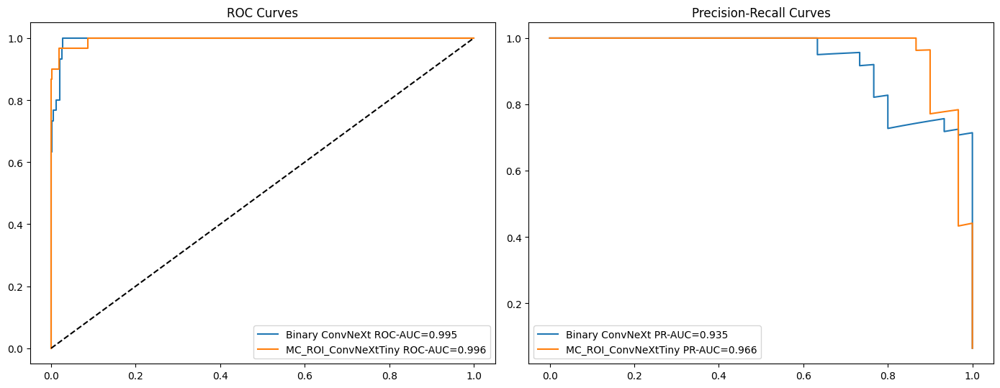

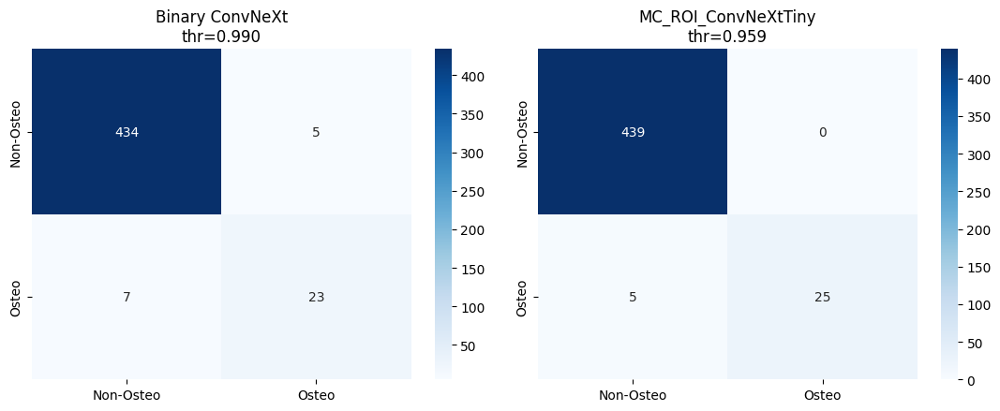

Saved ConvNeXt binary-vs-multiclass osteosarcoma comparison outputs in: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs


,model,threshold,accuracy,balanced_accuracy,precision,recall,specificity,f1,mcc,roc_auc,pr_auc
1,MC_ROI_ConvNeXtTiny as Osteosarcoma-vs-Rest,0.9588,0.9893,0.9167,1.0000,0.8333,1.0000,0.9091,0.9077,0.9958,0.9656
0,CONTRIB-ConvNeXtTiny-ROI Binary,0.9900,0.9744,0.8776,0.8214,0.7667,0.9886,0.7931,0.7800,0.9948,0.9345


19011

In [ ]:
# compare binary vs multiclass
required_5fc=['X_roi_val','X_roi_test','y_val_osteo','y_test_osteo','MULTICLASS_OUTPUT_DIR','MC_CLASS_NAMES','MC_NUM_CLASSES','MulticlassROIDataset','TimmConvNeXtMulticlass','predict_mc_torch']
missing_5fc=[name for name in required_5fc if name not in globals()]
if missing_5fc: raise RuntimeError(f'SECTION 5F-C missing required objects. Run SECTION 5F setup first: {missing_5fc}')
OSTEO_CLASS_ID_5FC=MC_CLASS_NAMES.index('osteosarcoma'); DEVICE_5FC=torch.device('cuda' if torch.cuda.is_available() else 'cpu'); BATCH_SIZE_5FC=int(globals().get('CONTRIB_BATCH_SIZE',globals().get('MC_BATCH_SIZE',16))); CONVNEXT_MODEL_NAME_5FC=globals().get('CONTRIB_MODEL_NAME',globals().get('MC_CONVNEXT_MODEL_NAME','convnext_tiny')); CONVNEXT_MEAN_5FC=torch.tensor([0.485,0.456,0.406],dtype=torch.float32).view(3,1,1); CONVNEXT_STD_5FC=torch.tensor([0.229,0.224,0.225],dtype=torch.float32).view(3,1,1)
class ConvNeXtBinaryCompareDataset(Dataset):
    def __init__(self,X): self.X=np.asarray(X)
    def __len__(self): return len(self.X)
    def __getitem__(self,idx):
        img=torch.from_numpy(self.X[idx].astype(np.float32)).permute(2,0,1); return (img-CONVNEXT_MEAN_5FC)/CONVNEXT_STD_5FC
class TimmConvNeXtBinaryCompare(nn.Module):
    def __init__(self,model_name=CONVNEXT_MODEL_NAME_5FC,dropout=0.45):
    def forward(self,x):
        feats=self.backbone(x); feats=feats.mean(dim=tuple(range(2,feats.ndim))) if feats.ndim>2 else feats; return self.head(feats).squeeze(1)
@torch.no_grad()
def predict_binary_convnext_5fc(model,X):
    model.eval(); loader=DataLoader(ConvNeXtBinaryCompareDataset(X),batch_size=BATCH_SIZE_5FC,shuffle=False,num_workers=0,pin_memory=torch.cuda.is_available()); probs=[]
    for xb in loader:
        xb=xb.to(DEVICE_5FC).float(); probs.append(torch.sigmoid(model(xb)).detach().cpu().numpy())
    return np.concatenate(probs).astype(np.float32) if probs else np.empty((0,),dtype=np.float32)
def contrib_checkpoint_path_5fc(name):
    return contrib_checkpoint_path(name) if 'contrib_checkpoint_path' in globals() else os.path.join(OUTPUT_DIR,f'best_{name}.pt')
def load_binary_convnext_5fc():
    ckpt_path=contrib_checkpoint_path_5fc('CONTRIB_ConvNeXtTiny_ROI')
    if not os.path.exists(ckpt_path): raise FileNotFoundError(f'Missing binary ConvNeXt checkpoint: {ckpt_path}. Run SECTION 5A-C first.')
    ckpt=torch.load(ckpt_path,map_location=DEVICE_5FC); model=TimmConvNeXtBinaryCompare(model_name=ckpt.get('model_name',CONVNEXT_MODEL_NAME_5FC),dropout=0.45).to(DEVICE_5FC); model.load_state_dict(ckpt['model_state_dict']); return model.eval()
def _mc_ckpt_candidates_5fc():
    rows=[]
    for model_name, ckpt_path in [('MC_ROI_ConvNeXtTiny', MULTICLASS_OUTPUT_DIR/'best_MC_ROI_ConvNeXtTiny.pt'), ('MC_ROI_ConvNeXtTiny_V2', MULTICLASS_OUTPUT_DIR/'best_MC_ROI_ConvNeXtTiny_V2.pt'), ('MC_ROI_ConvNeXtTiny_V3', MULTICLASS_OUTPUT_DIR/'best_MC_ROI_ConvNeXtTiny_V3.pt')]:
        if ckpt_path.exists(): rows.append({'model':model_name,'ckpt':ckpt_path,'macro_f1':-np.inf,'balanced_accuracy':-np.inf})
    score_frames=[]
    for fn in ['multiclass_roi_model_comparison.csv','multiclass_convnext_v2_comparison.csv','multiclass_convnext_v3_comparison.csv']:
        p=MULTICLASS_OUTPUT_DIR/fn
        if p.exists(): score_frames.append(pd.read_csv(p))
    scores=pd.concat(score_frames,ignore_index=True) if score_frames else pd.DataFrame()
    for row in rows:
        if not scores.empty and row['model'] in set(scores['model']):
            s=scores[scores['model'].eq(row['model'])].iloc[0]; row['macro_f1']=float(s.get('macro_f1',-np.inf)); row['balanced_accuracy']=float(s.get('balanced_accuracy',-np.inf))
    if not rows: raise FileNotFoundError('No multiclass ConvNeXt checkpoints found. Run SECTION 5F/V2/V3 training first.')
    return sorted(rows,key=lambda x:(x['macro_f1'],x['balanced_accuracy']),reverse=True)
@torch.no_grad()
def predict_multiclass_osteo_5fc(ckpt_path,X):
    ckpt=torch.load(ckpt_path,map_location=DEVICE_5FC); model=TimmConvNeXtMulticlass(num_classes=MC_NUM_CLASSES,model_name=ckpt.get('model_name',globals().get('MC_CONVNEXT_MODEL_NAME','convnext_tiny')),pretrained=False).to(DEVICE_5FC); model.load_state_dict(ckpt['model_state_dict']); model.eval(); ds=MulticlassROIDataset(X,np.zeros(len(X),dtype=np.int64),augment=False); loader=DataLoader(ds,batch_size=BATCH_SIZE_5FC,shuffle=False,num_workers=0,pin_memory=torch.cuda.is_available()); probs=[]
    for xb,_ in loader:
        xb=xb.to(DEVICE_5FC).float(); probs.append(torch.softmax(model(xb),dim=1).detach().cpu().numpy())
    del model
    return np.concatenate(probs).astype(np.float32)[:,OSTEO_CLASS_ID_5FC]
def best_threshold_from_val_5fc(y_true,y_prob):
    precision,recall,thresholds=precision_recall_curve(y_true,y_prob)
    if len(thresholds)==0: return 0.5
    f1=2*precision[:-1]*recall[:-1]/np.maximum(precision[:-1]+recall[:-1],1e-8); return float(np.clip(thresholds[int(np.nanargmax(f1))],0.01,0.99))
def binary_metrics_5fc(model_name,y_true,y_prob,threshold):
    pred=(y_prob>=threshold).astype(int); tn,fp,fn,tp=confusion_matrix(y_true,pred,labels=[0,1]).ravel()
    return {'model':model_name,'threshold':float(threshold),'accuracy':accuracy_score(y_true,pred),'balanced_accuracy':balanced_accuracy_score(y_true,pred),'precision':precision_score(y_true,pred,zero_division=0),'recall':recall_score(y_true,pred,zero_division=0),'specificity':tn/max(tn+fp,1),'f1':f1_score(y_true,pred,zero_division=0),'mcc':matthews_corrcoef(y_true,pred),'roc_auc':roc_auc_score(y_true,y_prob),'pr_auc':average_precision_score(y_true,y_prob)}
binary_model_5fc=load_binary_convnext_5fc(); bin_val_prob_5fc=predict_binary_convnext_5fc(binary_model_5fc,X_roi_val); bin_test_prob_5fc=predict_binary_convnext_5fc(binary_model_5fc,X_roi_test); bin_thr_5fc=best_threshold_from_val_5fc(y_val_osteo,bin_val_prob_5fc)
best_mc_5fc=_mc_ckpt_candidates_5fc()[0]; print(f"Selected multiclass ConvNeXt for comparison: {best_mc_5fc['model']} from {best_mc_5fc['ckpt']}"); mc_val_prob_5fc=predict_multiclass_osteo_5fc(best_mc_5fc['ckpt'],X_roi_val); mc_test_prob_5fc=predict_multiclass_osteo_5fc(best_mc_5fc['ckpt'],X_roi_test); mc_thr_5fc=best_threshold_from_val_5fc(y_val_osteo,mc_val_prob_5fc)
convnext_binary_vs_multiclass_osteo_comparison_df=pd.DataFrame([binary_metrics_5fc('CONTRIB-ConvNeXtTiny-ROI Binary',y_test_osteo,bin_test_prob_5fc,bin_thr_5fc),binary_metrics_5fc(f"{best_mc_5fc['model']} as Osteosarcoma-vs-Rest",y_test_osteo,mc_test_prob_5fc,mc_thr_5fc)]).sort_values(['pr_auc','mcc','balanced_accuracy'],ascending=False)
convnext_binary_vs_multiclass_osteo_comparison_df.to_csv(MULTICLASS_OUTPUT_DIR/'convnext_binary_vs_multiclass_osteo_comparison.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(14,5.5))
for label,prob in [('Binary ConvNeXt',bin_test_prob_5fc),(best_mc_5fc['model'],mc_test_prob_5fc)]:
    fpr,tpr,_=roc_curve(y_test_osteo,prob); axes[0].plot(fpr,tpr,label=f'{label} ROC-AUC={roc_auc_score(y_test_osteo,prob):.3f}'); prec,rec,_=precision_recall_curve(y_test_osteo,prob); axes[1].plot(rec,prec,label=f'{label} PR-AUC={average_precision_score(y_test_osteo,prob):.3f}')
axes[0].plot([0,1],[0,1],'k--'); axes[0].set_title('ROC Curves'); axes[0].legend(); axes[1].set_title('Precision-Recall Curves'); axes[1].legend(); plt.tight_layout(); plt.savefig(MULTICLASS_OUTPUT_DIR/'convnext_binary_vs_multiclass_osteo_curves.png',dpi=180,bbox_inches='tight'); plt.show()
fig,axes=plt.subplots(1,2,figsize=(11,4.5))
for ax,label,prob,thr in [(axes[0],'Binary ConvNeXt',bin_test_prob_5fc,bin_thr_5fc),(axes[1],best_mc_5fc['model'],mc_test_prob_5fc,mc_thr_5fc)]:
    cm=confusion_matrix(y_test_osteo,(prob>=thr).astype(int),labels=[0,1]); sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=['Non-Osteo','Osteo'],yticklabels=['Non-Osteo','Osteo'],ax=ax); ax.set_title(f'{label}\nthr={thr:.3f}')
plt.tight_layout(); plt.savefig(MULTICLASS_OUTPUT_DIR/'convnext_binary_vs_multiclass_osteo_confusion_matrices.png',dpi=180,bbox_inches='tight'); plt.show()
np.savez_compressed(MULTICLASS_OUTPUT_DIR/'convnext_binary_vs_multiclass_osteo_predictions.npz',y_val_osteo=np.asarray(y_val_osteo),y_test_osteo=np.asarray(y_test_osteo),binary_val_prob=bin_val_prob_5fc,binary_test_prob=bin_test_prob_5fc,binary_threshold=np.asarray([bin_thr_5fc],dtype=np.float32),multiclass_model=np.asarray([best_mc_5fc['model']],dtype=object),multiclass_val_osteo_prob=mc_val_prob_5fc,multiclass_test_osteo_prob=mc_test_prob_5fc,multiclass_threshold=np.asarray([mc_thr_5fc],dtype=np.float32))
print('Saved ConvNeXt binary-vs-multiclass osteosarcoma comparison outputs in:',MULTICLASS_OUTPUT_DIR); display(convnext_binary_vs_multiclass_osteo_comparison_df.style.format({c:'{:.4f}' for c in convnext_binary_vs_multiclass_osteo_comparison_df.select_dtypes(include='number').columns}))
del binary_model_5fc
if torch.cuda.is_available(): torch.cuda.empty_cache()
gc.collect()


We evaluate all multiclass image-only models, plotting confusion matrices and saving class reports.


Evaluating MC_ROI_CustomCNN...


2026-05-30 19:44:37.114759: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_465', 380 bytes spill stores, 380 bytes spill loads

2026-05-30 19:44:37.173343: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_465', 1000 bytes spill stores, 1000 bytes spill loads

2026-05-30 19:44:37.260985: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_465', 52 bytes spill stores, 52 bytes spill loads

2026-05-30 19:44:37.791891: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_411', 4 bytes spill stores, 4 bytes spill loads



Evaluating MC_ROI_CustomResNet...


2026-05-30 19:44:49.029747: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_552', 364 bytes spill stores, 364 bytes spill loads

2026-05-30 19:44:49.081913: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_552', 968 bytes spill stores, 968 bytes spill loads



Evaluating MC_ROI_EfficientNetB0...


2026-05-30 19:45:09.607380: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2048', 232 bytes spill stores, 232 bytes spill loads

2026-05-30 19:45:09.631213: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2048_0', 404 bytes spill stores, 1284 bytes spill loads

2026-05-30 19:45:10.083551: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2048', 5524 bytes spill stores, 5564 bytes spill loads

2026-05-30 19:45:10.152126: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2048', 5380 bytes spill stores, 5380 bytes spill loads



Evaluating MC_ROI_DenseNet121...


2026-05-30 19:45:26.290297: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_3298', 236 bytes spill stores, 236 bytes spill loads

2026-05-30 19:45:26.360488: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_3298_0', 324 bytes spill stores, 792 bytes spill loads

2026-05-30 19:45:26.648691: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_3298', 3952 bytes spill stores, 3944 bytes spill loads

2026-05-30 19:45:26.733086: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_3298', 996 bytes spill stores, 996 bytes spill loads



Evaluating MC_ROI_ResNet50_CBAM...


2026-05-30 19:45:47.853210: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1810', 236 bytes spill stores, 236 bytes spill loads

2026-05-30 19:45:48.120392: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1810', 1012 bytes spill stores, 1012 bytes spill loads

2026-05-30 19:45:48.134507: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1810', 4388 bytes spill stores, 4232 bytes spill loads



Evaluating MC_ROI_ConvNeXtTiny...
Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/multiclass_roi_model_comparison.csv
Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/multiclass_roi_classification_report.csv


,model,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,roc_auc_ovr_macro,top2_accuracy,top3_accuracy
5,MC_ROI_ConvNeXtTiny,0.9275,0.7189,0.8018,0.7189,0.7343,0.9244,0.9497,0.9638,0.9723
4,MC_ROI_ResNet50_CBAM,0.8806,0.6834,0.6536,0.6834,0.6428,0.8834,0.9559,0.9339,0.9595
3,MC_ROI_DenseNet121,0.8188,0.6396,0.5010,0.6396,0.5346,0.8300,0.9519,0.8763,0.9168
2,MC_ROI_EfficientNetB0,0.7633,0.5636,0.4736,0.5636,0.4850,0.7819,0.9387,0.8635,0.9083
0,MC_ROI_CustomCNN,0.6951,0.2729,0.2763,0.2729,0.2391,0.7051,0.8680,0.7612,0.8188
1,MC_ROI_CustomResNet,0.5608,0.2405,0.2103,0.2405,0.2095,0.5888,0.8102,0.6525,0.7015


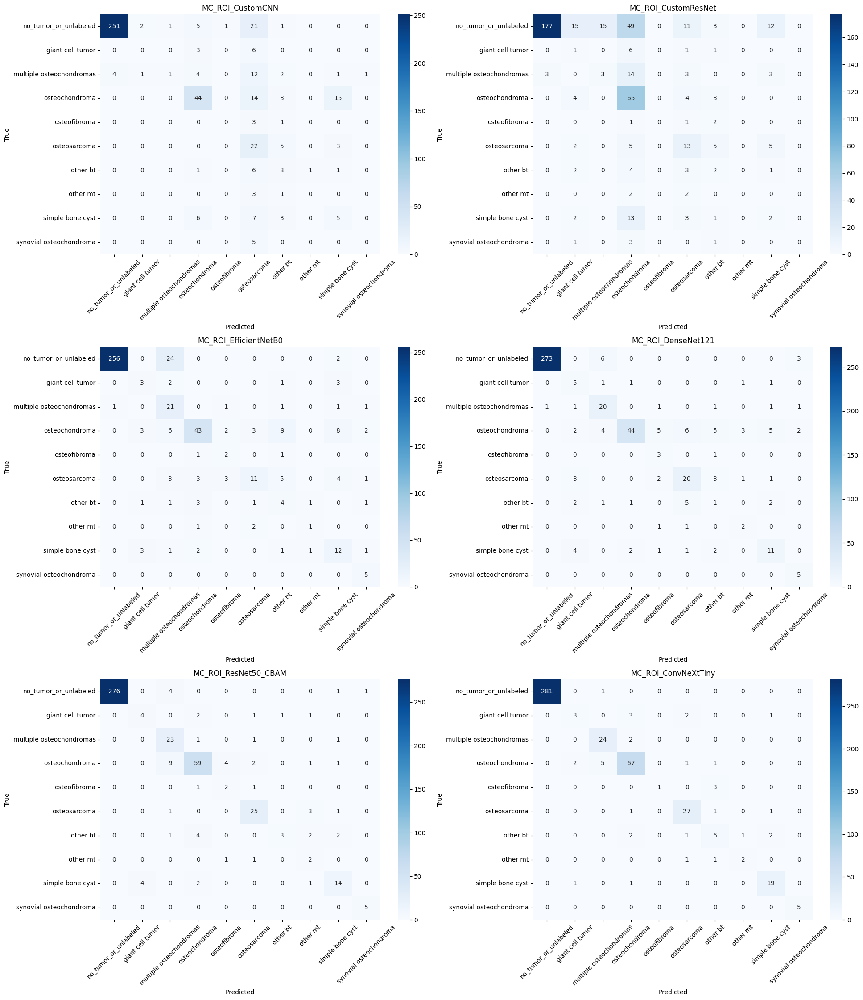

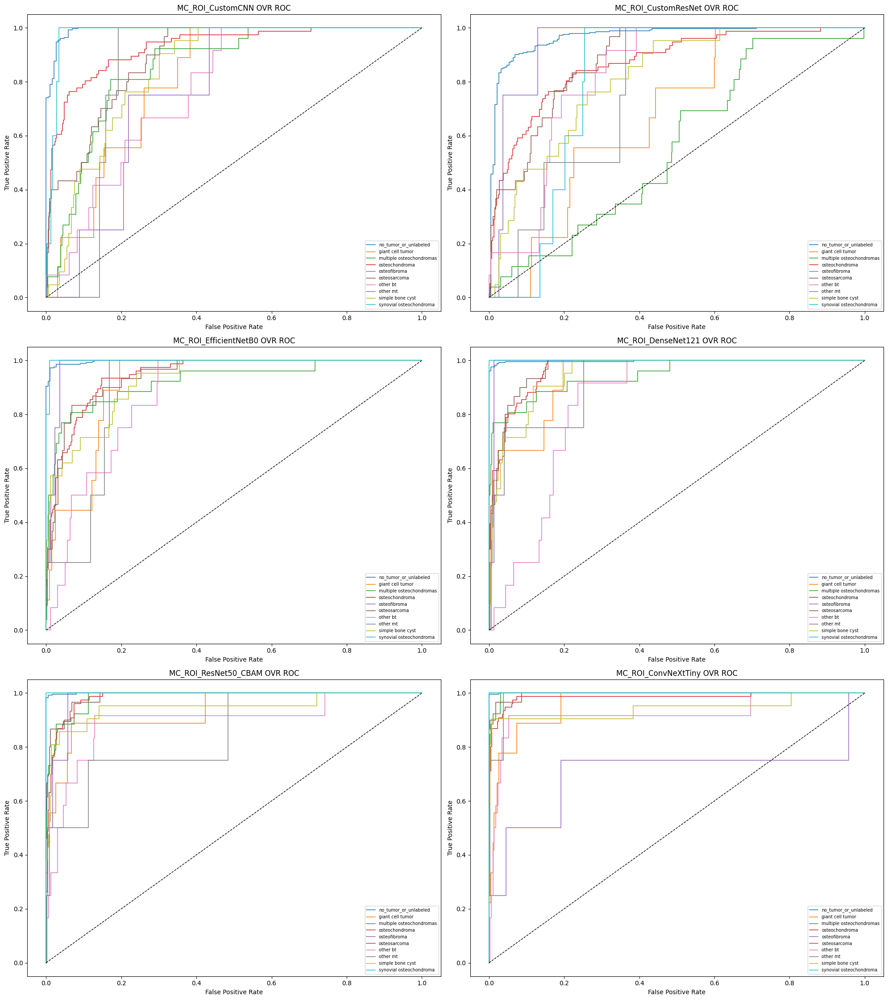

Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/multiclass_roi_confusion_matrices.png
Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/multiclass_roi_roc_curves.png
Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/multiclass_roi_predictions.npz


KeyboardInterrupt: 

In [ ]:
# evaluate multiclass models
MC_EVAL_MODEL_NAMES = MC_ALL_MODEL_NAMES

def _safe_multiclass_auc(y_true, prob):
    try:
        return float(roc_auc_score(y_true, prob, multi_class='ovr', average='macro', labels=list(range(MC_NUM_CLASSES))))
    except Exception:
        return np.nan

def _safe_top_k(y_true, prob, k):
    try:
        return float(top_k_accuracy_score(y_true, prob, k=k, labels=list(range(MC_NUM_CLASSES))))
    except Exception:
        return np.nan

def compute_multiclass_result(model_name, y_true, prob):
    pred = np.argmax(prob, axis=1)
    return {
        'model': model_name,
        'accuracy': accuracy_score(y_true, pred),
        'balanced_accuracy': balanced_accuracy_score(y_true, pred),
        'macro_precision': precision_score(y_true, pred, average='macro', zero_division=0),
        'macro_recall': recall_score(y_true, pred, average='macro', zero_division=0),
        'macro_f1': f1_score(y_true, pred, average='macro', zero_division=0),
        'weighted_f1': f1_score(y_true, pred, average='weighted', zero_division=0),
        'roc_auc_ovr_macro': _safe_multiclass_auc(y_true, prob),
        'top2_accuracy': _safe_top_k(y_true, prob, 2),
        'top3_accuracy': _safe_top_k(y_true, prob, 3),
    }

def _load_mc_keras_checkpoint(model_name):
    ckpt = mc_checkpoint_path(model_name)
    if not ckpt.exists():
        raise FileNotFoundError(f'Missing checkpoint: {ckpt}. Run the matching Section 5F training cell first.')
    if model_name == 'MC_ROI_ResNet50_CBAM':
        # Rebuild serializable CBAM architecture first; full load also works for fresh checkpoints.
        try:
            model, _ = build_mc_resnet50_cbam(input_shape=(*IMG_SIZE, 3), num_classes=MC_NUM_CLASSES)
            model.load_weights(ckpt)
            return model
        except Exception:
            return tf.keras.models.load_model(ckpt, compile=False, custom_objects={'MCChannelMean': MCChannelMean, 'MCChannelMax': MCChannelMax, 'MCResNet50Preprocess': MCResNet50Preprocess})
    return tf.keras.models.load_model(ckpt, compile=False, custom_objects={'MCChannelMean': MCChannelMean, 'MCChannelMax': MCChannelMax, 'MCResNet50Preprocess': MCResNet50Preprocess})

def _load_mc_convnext_checkpoint():
    ckpt_path = MC_CONVNEXT_CKPT
    if not ckpt_path.exists():
        raise FileNotFoundError(f'Missing checkpoint: {ckpt_path}. Run CELL 5F-4 first.')
    ckpt = torch.load(ckpt_path, map_location=MC_DEVICE)
    model = TimmConvNeXtMulticlass(num_classes=MC_NUM_CLASSES, model_name=ckpt.get('model_name', MC_CONVNEXT_MODEL_NAME), pretrained=False).to(MC_DEVICE)
    model.load_state_dict(ckpt['model_state_dict'])
    model.eval()
    return model

mc_prob_by_model = {}
mc_pred_by_model = {}
mc_results = []
mc_report_frames = []

for model_name in MC_KERAS_MODELS:
    print(f'Evaluating {model_name}...')
    model = _load_mc_keras_checkpoint(model_name)
    prob = model.predict(X_roi_test.astype(np.float32, copy=False), batch_size=32, verbose=0)
    mc_prob_by_model[model_name] = prob
    mc_pred_by_model[model_name] = np.argmax(prob, axis=1)
    mc_results.append(compute_multiclass_result(model_name, mc_y_test, prob))
    report = pd.DataFrame(classification_report(mc_y_test, mc_pred_by_model[model_name], target_names=MC_CLASS_NAMES, output_dict=True, zero_division=0)).T
    report.insert(0, 'model', model_name)
    mc_report_frames.append(report.reset_index(names='class_name'))
    del model
    tf.keras.backend.clear_session()
    gc.collect()

print('Evaluating MC_ROI_ConvNeXtTiny...')
_, _, mc_test_loader_eval = make_mc_convnext_loaders()
conv_model = _load_mc_convnext_checkpoint()
prob_conv, _ = predict_mc_torch(conv_model, mc_test_loader_eval)
mc_prob_by_model['MC_ROI_ConvNeXtTiny'] = prob_conv
mc_pred_by_model['MC_ROI_ConvNeXtTiny'] = np.argmax(prob_conv, axis=1)
mc_results.append(compute_multiclass_result('MC_ROI_ConvNeXtTiny', mc_y_test, prob_conv))
report = pd.DataFrame(classification_report(mc_y_test, mc_pred_by_model['MC_ROI_ConvNeXtTiny'], target_names=MC_CLASS_NAMES, output_dict=True, zero_division=0)).T
report.insert(0, 'model', 'MC_ROI_ConvNeXtTiny')
mc_report_frames.append(report.reset_index(names='class_name'))
del conv_model
if torch.cuda.is_available():
    torch.cuda.empty_cache()
gc.collect()

multiclass_roi_model_comparison_df = pd.DataFrame(mc_results).sort_values(['macro_f1', 'balanced_accuracy'], ascending=False)
multiclass_roi_classification_report_df = pd.concat(mc_report_frames, ignore_index=True)
multiclass_roi_model_comparison_df.to_csv(MULTICLASS_OUTPUT_DIR / 'multiclass_roi_model_comparison.csv', index=False)
multiclass_roi_classification_report_df.to_csv(MULTICLASS_OUTPUT_DIR / 'multiclass_roi_classification_report.csv', index=False)
mc_per_class_display_df = multiclass_roi_classification_report_df[
    multiclass_roi_classification_report_df['class_name'].isin(MC_CLASS_NAMES)
].copy().sort_values(['model', 'class_name']).reset_index(drop=True)
print('Per-class multiclass metrics:')
display(mc_per_class_display_df[['model', 'class_name', 'precision', 'recall', 'f1-score', 'support']].style.format({
    'precision': '{:.4f}', 'recall': '{:.4f}', 'f1-score': '{:.4f}', 'support': '{:.0f}'
}))

print('Saved:', MULTICLASS_OUTPUT_DIR / 'multiclass_roi_model_comparison.csv')
print('Saved:', MULTICLASS_OUTPUT_DIR / 'multiclass_roi_classification_report.csv')
display(multiclass_roi_model_comparison_df.style.format({c: '{:.4f}' for c in multiclass_roi_model_comparison_df.select_dtypes(include='number').columns}))

n_models = len(MC_EVAL_MODEL_NAMES)
n_cols = 2
n_rows = int(np.ceil(n_models / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(10 * n_cols, 7.5 * n_rows))
axes = np.asarray(axes).reshape(-1)
for ax, model_name in zip(axes, MC_EVAL_MODEL_NAMES):
    cm = confusion_matrix(mc_y_test, mc_pred_by_model[model_name], labels=list(range(MC_NUM_CLASSES)))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=MC_CLASS_NAMES, yticklabels=MC_CLASS_NAMES, ax=ax)
    ax.set_title(model_name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.tick_params(axis='x', rotation=45)
    ax.tick_params(axis='y', rotation=0)
for ax in axes[n_models:]:
    ax.axis('off')
plt.tight_layout()
plt.savefig(MULTICLASS_OUTPUT_DIR / 'multiclass_roi_confusion_matrices.png', dpi=180, bbox_inches='tight')
plt.show()

y_test_bin = label_binarize(mc_y_test, classes=list(range(MC_NUM_CLASSES)))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(10 * n_cols, 7.5 * n_rows))
axes = np.asarray(axes).reshape(-1)
for ax, model_name in zip(axes, MC_EVAL_MODEL_NAMES):
    prob = mc_prob_by_model[model_name]
    for class_id, class_name in enumerate(MC_CLASS_NAMES):
        if y_test_bin[:, class_id].sum() == 0:
            continue
        fpr, tpr, _ = roc_curve(y_test_bin[:, class_id], prob[:, class_id])
        ax.plot(fpr, tpr, linewidth=1.1, label=class_name)
    ax.plot([0, 1], [0, 1], 'k--', linewidth=1)
    ax.set_title(f'{model_name} OVR ROC')
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.legend(fontsize=7, loc='lower right')
for ax in axes[n_models:]:
    ax.axis('off')
plt.tight_layout()
plt.savefig(MULTICLASS_OUTPUT_DIR / 'multiclass_roi_roc_curves.png', dpi=180, bbox_inches='tight')
plt.show()

np.savez_compressed(
    MULTICLASS_OUTPUT_DIR / 'multiclass_roi_predictions.npz',
    y_test=mc_y_test,
    class_names=np.asarray(MC_CLASS_NAMES, dtype=object),
    model_names=np.asarray(MC_EVAL_MODEL_NAMES, dtype=object),
    **{f'{name}_prob': prob for name, prob in mc_prob_by_model.items()},
)
print('Saved:', MULTICLASS_OUTPUT_DIR / 'multiclass_roi_confusion_matrices.png')
print('Saved:', MULTICLASS_OUTPUT_DIR / 'multiclass_roi_roc_curves.png')
print('Saved:', MULTICLASS_OUTPUT_DIR / 'multiclass_roi_predictions.npz')


## Subsection 3.2 - Multiclass Multimodal Fusion
Multi-input models combining multiclass image features and clinical tabular metadata.


We set up builders and generators for dual-input multiclass multimodal models.


In [ ]:
#  Multiclass multimodal setup, builders, and shared utilities



required_5fm = [
    'X_roi_train', 'X_roi_val', 'X_roi_test',
    'X_tab_train', 'X_tab_val', 'X_tab_test',
    'mc_y_train', 'mc_y_val', 'mc_y_test',
    'MC_CLASS_NAMES', 'MC_NUM_CLASSES', 'mc_class_weights_arr', 'mc_class_weight_dict',
    'MULTICLASS_OUTPUT_DIR', 'IMG_SIZE', 'MC_BATCH_SIZE', 'MC_RANDOM_SEED',
]
missing_5fm = [name for name in required_5fm if name not in globals()]
if missing_5fm:
    raise RuntimeError('SECTION 5F-M requires SECTION 5F setup and tabular preprocessing first. Missing: ' + str(missing_5fm))

if not (len(X_roi_train) == len(X_tab_train) == len(mc_y_train)):
    raise ValueError('Train split alignment failed: ROI images, tabular features, and multiclass labels have different lengths.')
if not (len(X_roi_val) == len(X_tab_val) == len(mc_y_val)):
    raise ValueError('Validation split alignment failed.')
if not (len(X_roi_test) == len(X_tab_test) == len(mc_y_test)):
    raise ValueError('Test split alignment failed.')

MC_MM_TABULAR_DIM = int(X_tab_train.shape[1])
MC_MM_EPOCHS_SCRATCH = int(globals().get('MC_MM_EPOCHS_SCRATCH', globals().get('MC_EPOCHS_SCRATCH', 50)))
MC_MM_EPOCHS_TRANSFER_P1 = int(globals().get('MC_MM_EPOCHS_TRANSFER_P1', 16))
MC_MM_EPOCHS_TRANSFER_P2 = int(globals().get('MC_MM_EPOCHS_TRANSFER_P2', globals().get('MC_EPOCHS_FINETUNE', 18)))
MC_MM_EPOCHS_CONVNEXT = int(globals().get('MC_MM_EPOCHS_CONVNEXT', 30))
MC_MM_PATIENCE = int(globals().get('MC_MM_PATIENCE', globals().get('MC_PATIENCE', 8)))
MC_MM_UNFREEZE_LAST = int(globals().get('MC_MM_UNFREEZE_LAST', 20))

MC_MM_KERAS_MODELS = [
    'MC_MM_ROI_CustomCNN',
    'MC_MM_ROI_CustomResNet',
    'MC_MM_ROI_EfficientNetB0',
    'MC_MM_ROI_DenseNet121',
    'MC_MM_ROI_ResNet50_CBAM',
]
MC_MM_TORCH_MODELS = ['MC_MM_ROI_ConvNeXtTiny']
MC_MM_ALL_MODEL_NAMES = MC_MM_KERAS_MODELS + MC_MM_TORCH_MODELS

print('=' * 78)
print('SECTION 5F-M: ROI MULTICLASS MULTIMODAL CLASSIFICATION')
print('=' * 78)
print(f'Multiclass output folder : {MULTICLASS_OUTPUT_DIR}')
print(f'ROI train/val/test       : {X_roi_train.shape} | {X_roi_val.shape} | {X_roi_test.shape}')
print(f'Tabular train/val/test   : {X_tab_train.shape} | {X_tab_val.shape} | {X_tab_test.shape}')
print('Included models           : ' + ', '.join(MC_MM_ALL_MODEL_NAMES))
print('Excluded                  : MC_MM_ROI_ResNet50V2')
print('=' * 78)


class MultimodalMacroF1Callback(tf.keras.callbacks.Callback):
    def __init__(self, X_img_val, X_tab_val_data, y_val_data, checkpoint_path, batch_size=32, initial_best=-np.inf):
        super().__init__()
        self.val_inputs = [X_img_val.astype(np.float32, copy=False), X_tab_val_data.astype(np.float32, copy=False)]
        self.y_val_data = np.asarray(y_val_data).astype(int)
        self.checkpoint_path = str(checkpoint_path)
        self.batch_size = int(batch_size)
        self.best_macro_f1 = float(initial_best)

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        probs = self.model.predict(self.val_inputs, batch_size=self.batch_size, verbose=0)
        preds = np.argmax(probs, axis=1)
        macro_f1 = f1_score(self.y_val_data, preds, average='macro', zero_division=0)
        logs['val_macro_f1'] = macro_f1
        print(f' - val_macro_f1: {macro_f1:.4f}')
        if macro_f1 > self.best_macro_f1:
            self.best_macro_f1 = macro_f1
            self.model.save(self.checkpoint_path)
            print(f'   Saved best multimodal multiclass checkpoint: {self.checkpoint_path}')

def mc_mm_checkpoint_path(model_name):
    return MULTICLASS_OUTPUT_DIR / f'best_{model_name}.keras'

def mc_mm_torch_checkpoint_path(model_name):
    return MULTICLASS_OUTPUT_DIR / f'best_{model_name}.pt'

def compile_mc_mm_keras_model(model, lr=5e-5):
    optimizer_cls = getattr(tf.keras.optimizers, 'AdamW', None)
    optimizer = optimizer_cls(learning_rate=lr, weight_decay=1e-5, clipnorm=1.0) if optimizer_cls else tf.keras.optimizers.Adam(learning_rate=lr, clipnorm=1.0)
    model.compile(
        optimizer=optimizer,
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=[
            tf.keras.metrics.SparseCategoricalAccuracy(name='accuracy'),
            tf.keras.metrics.SparseTopKCategoricalAccuracy(k=2, name='top2_accuracy'),
            tf.keras.metrics.SparseTopKCategoricalAccuracy(k=3, name='top3_accuracy'),
        ],
    )
    return model

def mc_mm_augmented_generator(X_img, X_tab, y, batch_size=MC_BATCH_SIZE, seed=42):
    rng = np.random.default_rng(seed)
    X_img = np.asarray(X_img)
    X_tab = np.asarray(X_tab).astype(np.float32)
    y = np.asarray(y).astype(np.int32)
    while True:
        idx = rng.integers(0, len(y), size=batch_size)
        batch_img = X_img[idx].astype(np.float32, copy=False)
        if 'aug_gen' in globals():
            batch_img = np.asarray([
                np.clip(aug_gen.random_transform(img), 0.0, 1.0)
                for img in batch_img
            ], dtype=np.float32)
        batch_tab = X_tab[idx].astype(np.float32, copy=False)
        labels = y[idx]
        sample_weight = np.asarray([mc_class_weight_dict[int(label)] for label in labels], dtype=np.float32)
        yield (batch_img, batch_tab), labels, sample_weight

def _mc_mm_tab_branch(tab_input, name='tabular_branch'):
    t = layers.Dense(48, kernel_initializer='he_normal', kernel_regularizer=regularizers.l2(1e-4), name=f'{name}_dense1')(tab_input)
    t = layers.BatchNormalization(name=f'{name}_bn1')(t)
    t = layers.Activation('relu', name=f'{name}_relu1')(t)
    t = layers.Dropout(0.25, name=f'{name}_drop1')(t)
    t = layers.Dense(24, kernel_initializer='he_normal', kernel_regularizer=regularizers.l2(1e-4), name=f'{name}_dense2')(t)
    t = layers.BatchNormalization(name=f'{name}_bn2')(t)
    t = layers.Activation('relu', name=f'{name}_relu2')(t)
    return t

def _mc_mm_fusion_head(img_feat, tab_feat, num_classes=MC_NUM_CLASSES, units=224, dropout=0.45, name='fusion'):
    x = layers.Concatenate(name=f'{name}_concat')([img_feat, tab_feat])
    x = layers.Dense(units, kernel_initializer='he_normal', kernel_regularizer=regularizers.l2(1e-4), name=f'{name}_dense1')(x)
    x = layers.BatchNormalization(name=f'{name}_bn1')(x)
    x = layers.Activation('relu', name=f'{name}_relu1')(x)
    x = layers.Dropout(dropout, name=f'{name}_drop1')(x)
    x = layers.Dense(max(units // 2, 64), kernel_initializer='he_normal', kernel_regularizer=regularizers.l2(1e-4), name=f'{name}_dense2')(x)
    x = layers.BatchNormalization(name=f'{name}_bn2')(x)
    x = layers.Activation('relu', name=f'{name}_relu2')(x)
    x = layers.Dropout(dropout * 0.75, name=f'{name}_drop2')(x)
    return layers.Dense(num_classes, activation='softmax', name='mc_mm_output')(x)

def build_mc_mm_custom_cnn(input_shape=(224, 224, 3), tabular_dim=MC_MM_TABULAR_DIM, num_classes=MC_NUM_CLASSES):
    img_input = layers.Input(shape=input_shape, name='mc_mm_roi_image')
    tab_input = layers.Input(shape=(tabular_dim,), name='mc_mm_tabular')
    x = img_input
    for filters, drop in [(32, 0.08), (64, 0.12), (128, 0.18), (160, 0.22)]:
        x = layers.Conv2D(filters, 3, padding='same', kernel_initializer='he_normal', kernel_regularizer=regularizers.l2(1e-4))(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
        x = layers.Conv2D(filters, 3, padding='same', kernel_initializer='he_normal', kernel_regularizer=regularizers.l2(1e-4))(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
        if 'squeeze_excite' in globals():
            x = squeeze_excite(x, ratio=8)
        x = layers.MaxPooling2D()(x)
        x = layers.SpatialDropout2D(drop)(x)
    img_feat = layers.GlobalAveragePooling2D(name='mc_mm_cnn_gap')(x)
    tab_feat = _mc_mm_tab_branch(tab_input)
    output = _mc_mm_fusion_head(img_feat, tab_feat, num_classes=num_classes, units=192, dropout=0.45, name='mc_mm_custom_cnn_fusion')
    return models.Model([img_input, tab_input], output, name='MC_MM_ROI_CustomCNN')

def _mc_mm_residual_block(x, filters, stride=1, dropout_rate=0.0):
    shortcut = x
    x = layers.Conv2D(filters, 3, strides=stride, padding='same', kernel_initializer='he_normal', kernel_regularizer=regularizers.l2(1e-4), use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(filters, 3, padding='same', kernel_initializer='he_normal', kernel_regularizer=regularizers.l2(1e-4), use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    if 'squeeze_excite' in globals():
        x = squeeze_excite(x, ratio=8)
    if stride != 1 or int(shortcut.shape[-1]) != filters:
        shortcut = layers.Conv2D(filters, 1, strides=stride, padding='same', use_bias=False)(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)
    x = layers.Add()([x, shortcut])
    x = layers.Activation('relu')(x)
    if dropout_rate > 0:
        x = layers.SpatialDropout2D(dropout_rate)(x)
    return x

def build_mc_mm_custom_resnet(input_shape=(224, 224, 3), tabular_dim=MC_MM_TABULAR_DIM, num_classes=MC_NUM_CLASSES):
    img_input = layers.Input(shape=input_shape, name='mc_mm_roi_image')
    tab_input = layers.Input(shape=(tabular_dim,), name='mc_mm_tabular')
    x = layers.Conv2D(64, 3, strides=1, padding='same', kernel_initializer='he_normal', kernel_regularizer=regularizers.l2(1e-4), use_bias=False)(img_input)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = _mc_mm_residual_block(x, 64, dropout_rate=0.10)
    x = _mc_mm_residual_block(x, 64, dropout_rate=0.10)
    x = _mc_mm_residual_block(x, 128, stride=2, dropout_rate=0.15)
    x = _mc_mm_residual_block(x, 128, dropout_rate=0.15)
    x = _mc_mm_residual_block(x, 192, stride=2, dropout_rate=0.20)
    img_feat = layers.GlobalAveragePooling2D(name='mc_mm_resnet_gap')(x)
    tab_feat = _mc_mm_tab_branch(tab_input)
    output = _mc_mm_fusion_head(img_feat, tab_feat, num_classes=num_classes, units=192, dropout=0.45, name='mc_mm_custom_resnet_fusion')
    return models.Model([img_input, tab_input], output, name='MC_MM_ROI_CustomResNet')

def _mc_mm_densenet_norm():
    mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
    std = np.array([0.229, 0.224, 0.225], dtype=np.float32)
    return layers.Normalization(axis=-1, mean=mean, variance=np.square(std), name='mc_mm_densenet_imagenet_norm')

def build_mc_mm_efficientnet(input_shape=(224, 224, 3), tabular_dim=MC_MM_TABULAR_DIM, num_classes=MC_NUM_CLASSES):
    base = EfficientNetB0(weights='imagenet', include_top=False, input_shape=input_shape)
    base.trainable = False
    img_input = layers.Input(shape=input_shape, name='mc_mm_roi_image')
    tab_input = layers.Input(shape=(tabular_dim,), name='mc_mm_tabular')
    x = layers.Rescaling(255.0, name='mc_mm_rescale_for_efficientnet')(img_input)
    x = base(x)
    img_feat = layers.GlobalAveragePooling2D(name='mc_mm_eff_gap')(x)
    tab_feat = _mc_mm_tab_branch(tab_input)
    output = _mc_mm_fusion_head(img_feat, tab_feat, num_classes=num_classes, units=256, dropout=0.45, name='mc_mm_eff_fusion')
    return models.Model([img_input, tab_input], output, name='MC_MM_ROI_EfficientNetB0'), base

def build_mc_mm_densenet121(input_shape=(224, 224, 3), tabular_dim=MC_MM_TABULAR_DIM, num_classes=MC_NUM_CLASSES):
    base = DenseNet121(weights='imagenet', include_top=False, input_shape=input_shape)
    base.trainable = False
    img_input = layers.Input(shape=input_shape, name='mc_mm_roi_image')
    tab_input = layers.Input(shape=(tabular_dim,), name='mc_mm_tabular')
    x = _mc_mm_densenet_norm()(img_input)
    x = base(x)
    img_feat = layers.GlobalAveragePooling2D(name='mc_mm_dense_gap')(x)
    tab_feat = _mc_mm_tab_branch(tab_input)
    output = _mc_mm_fusion_head(img_feat, tab_feat, num_classes=num_classes, units=224, dropout=0.45, name='mc_mm_dense_fusion')
    return models.Model([img_input, tab_input], output, name='MC_MM_ROI_DenseNet121'), base

def build_mc_mm_resnet50_cbam(input_shape=(224, 224, 3), tabular_dim=MC_MM_TABULAR_DIM, num_classes=MC_NUM_CLASSES):
    if 'MCResNet50Preprocess' not in globals() or 'mc_cbam_block' not in globals():
        raise RuntimeError('Run CELL 5F-2 first so MCResNet50Preprocess and mc_cbam_block are available.')
    base = ResNet50(weights='imagenet', include_top=False, input_shape=input_shape)
    base.trainable = False
    img_input = layers.Input(shape=input_shape, name='mc_mm_roi_image')
    tab_input = layers.Input(shape=(tabular_dim,), name='mc_mm_tabular')
    x = layers.Rescaling(255.0, name='mc_mm_rescale_for_resnet50')(img_input)
    x = MCResNet50Preprocess(name='mc_mm_resnet50_preprocess')(x)
    x = base(x)
    x = mc_cbam_block(x, ratio=8, name='mc_mm_resnet50_cbam')
    img_feat = layers.GlobalAveragePooling2D(name='mc_mm_cbam_gap')(x)
    tab_feat = _mc_mm_tab_branch(tab_input)
    output = _mc_mm_fusion_head(img_feat, tab_feat, num_classes=num_classes, units=256, dropout=0.45, name='mc_mm_cbam_fusion')
    return models.Model([img_input, tab_input], output, name='MC_MM_ROI_ResNet50_CBAM'), base

def _train_mc_mm_keras_model(model_name, build_fn, lr_p1, lr_p2=None, epochs_p1=20, epochs_p2=0, seed=42):
    tf.keras.backend.clear_session()
    built = build_fn(input_shape=(*IMG_SIZE, 3), tabular_dim=MC_MM_TABULAR_DIM, num_classes=MC_NUM_CLASSES)
    if isinstance(built, tuple):
        model, base = built
    else:
        model, base = built, None
    ckpt = mc_mm_checkpoint_path(model_name)
    gen = mc_mm_augmented_generator(X_roi_train, X_tab_train, mc_y_train, batch_size=MC_BATCH_SIZE, seed=seed)
    steps = int(np.ceil(len(mc_y_train) / MC_BATCH_SIZE))
    best_score = -np.inf

    print(f'\nTraining {model_name}')
    model = compile_mc_mm_keras_model(model, lr=lr_p1)
    cb = MultimodalMacroF1Callback(X_roi_val, X_tab_val, mc_y_val, ckpt, batch_size=32, initial_best=best_score)
    history_p1 = model.fit(
        gen,
        steps_per_epoch=steps,
        epochs=epochs_p1,
        validation_data=((X_roi_val.astype(np.float32), X_tab_val.astype(np.float32)), mc_y_val),
        callbacks=[
            cb,
            tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=MC_MM_PATIENCE, restore_best_weights=False),
            tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-7),
        ],
        verbose=1,
    )
    best_score = cb.best_macro_f1

    history_p2 = None
    if base is not None and epochs_p2 and epochs_p2 > 0:
        base.trainable = True
        for layer in base.layers[:-MC_MM_UNFREEZE_LAST]:
            layer.trainable = False
        model = compile_mc_mm_keras_model(model, lr=lr_p2 or lr_p1 * 0.2)
        cb = MultimodalMacroF1Callback(X_roi_val, X_tab_val, mc_y_val, ckpt, batch_size=32, initial_best=best_score)
        history_p2 = model.fit(
            gen,
            steps_per_epoch=steps,
            epochs=epochs_p2,
            validation_data=((X_roi_val.astype(np.float32), X_tab_val.astype(np.float32)), mc_y_val),
            callbacks=[
                cb,
                tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=MC_MM_PATIENCE, restore_best_weights=False),
                tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-7),
            ],
            verbose=1,
        )
        best_score = cb.best_macro_f1

    print(f'Best checkpoint for {model_name}: {ckpt}')
    print(f'Best validation macro-F1 observed: {best_score:.4f}')
    return model, history_p1, history_p2


SECTION 5F-M: ROI MULTICLASS MULTIMODAL CLASSIFICATION
Multiclass output folder : /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs
ROI train/val/test       : (2659, 224, 224, 3) | (618, 224, 224, 3) | (469, 224, 224, 3)
Tabular train/val/test   : (2659, 8) | (618, 8) | (469, 8)
Included models           : MC_MM_ROI_CustomCNN, MC_MM_ROI_CustomResNet, MC_MM_ROI_EfficientNetB0, MC_MM_ROI_DenseNet121, MC_MM_ROI_ResNet50_CBAM, MC_MM_ROI_ConvNeXtTiny
Excluded                  : MC_MM_ROI_ResNet50V2


We train the dual-input Keras multiclass models on ROI images combined with patient metadata.


In [ ]:
# CELL 5F-M-2: Train Keras ROI + metadata multiclass models
mc_mm_keras_training_plan = [
    ('MC_MM_ROI_CustomCNN', build_mc_mm_custom_cnn, 8e-5, None, MC_MM_EPOCHS_SCRATCH, 0, 801),
    ('MC_MM_ROI_CustomResNet', build_mc_mm_custom_resnet, 7e-5, None, MC_MM_EPOCHS_SCRATCH, 0, 811),
    ('MC_MM_ROI_EfficientNetB0', build_mc_mm_efficientnet, 5e-5, 1e-5, MC_MM_EPOCHS_TRANSFER_P1, MC_MM_EPOCHS_TRANSFER_P2, 821),
    ('MC_MM_ROI_DenseNet121', build_mc_mm_densenet121, 5e-5, 1e-5, MC_MM_EPOCHS_TRANSFER_P1, MC_MM_EPOCHS_TRANSFER_P2, 831),
    ('MC_MM_ROI_ResNet50_CBAM', build_mc_mm_resnet50_cbam, 5e-5, 1e-5, MC_MM_EPOCHS_TRANSFER_P1, MC_MM_EPOCHS_TRANSFER_P2, 841),
]

mc_mm_keras_histories = {}
for model_name, build_fn, lr_p1, lr_p2, epochs_p1, epochs_p2, seed in mc_mm_keras_training_plan:
    model, hist_p1, hist_p2 = _train_mc_mm_keras_model(
        model_name, build_fn, lr_p1, lr_p2=lr_p2,
        epochs_p1=epochs_p1, epochs_p2=epochs_p2, seed=seed,
    )
    mc_mm_keras_histories[model_name] = {
        'phase1': pd.DataFrame(hist_p1.history),
        'phase2': pd.DataFrame(hist_p2.history) if hist_p2 is not None else None,
    }
    del model, hist_p1, hist_p2
    tf.keras.backend.clear_session()
    gc.collect()

print('Keras multiclass multimodal training complete.')



Training MC_MM_ROI_CustomCNN
Epoch 1/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step - accuracy: 0.0676 - loss: 3.1981 - top2_accuracy: 0.1539 - top3_accuracy: 0.2553

2026-05-30 21:28:24.674560: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_681', 244 bytes spill stores, 244 bytes spill loads

2026-05-30 21:28:24.818315: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_681', 360 bytes spill stores, 360 bytes spill loads

2026-05-30 21:28:25.042774: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_681', 964 bytes spill stores, 964 bytes spill loads

2026-05-30 21:28:27.541402: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_681', 708 bytes spill stores, 708 bytes spill loads



 - val_macro_f1: 0.0607
   Saved best multimodal multiclass checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/best_MC_MM_ROI_CustomCNN.keras
84/84 ━━━━━━━━━━━━━━━━━━━━ 31s 240ms/step - accuracy: 0.0766 - loss: 3.0982 - top2_accuracy: 0.1678 - top3_accuracy: 0.2760 - val_accuracy: 0.1343 - val_loss: 2.5732 - val_top2_accuracy: 0.1699 - val_top3_accuracy: 0.2411 - val_macro_f1: 0.0607 - learning_rate: 8.0000e-05
Epoch 2/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - accuracy: 0.1136 - loss: 2.8663 - top2_accuracy: 0.2290 - top3_accuracy: 0.3497 - val_macro_f1: 0.0782
   Saved best multimodal multiclass checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/best_MC_MM_ROI_CustomCNN.keras
84/84 ━━━━━━━━━━━━━━━━━━━━ 13s 157ms/step - accuracy: 0.1202 - loss: 2.9076 - top2_accuracy: 0.2403 - top3_accuracy: 0.3612 - val_accuracy: 0.1149 - val_loss: 2.6074 - val_top2_accuracy: 0.2201 - val_top3_accuracy: 0.2702 - val_macro_f1: 0.0782 - learning_ra

2026-05-30 22:34:13.612117: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_3434', 60 bytes spill stores, 60 bytes spill loads

2026-05-30 22:34:13.623833: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_3434', 228 bytes spill stores, 228 bytes spill loads

2026-05-30 22:34:13.640504: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_3434', 388 bytes spill stores, 388 bytes spill loads

2026-05-30 22:34:13.724388: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_3434', 928 bytes spill stores, 928 bytes spill loads

2026-05-30 22:34:19.119342: I exte

 - val_macro_f1: 0.1115
   Saved best multimodal multiclass checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/best_MC_MM_ROI_DenseNet121.keras
84/84 ━━━━━━━━━━━━━━━━━━━━ 45s 416ms/step - accuracy: 0.1544 - loss: 2.7748 - top2_accuracy: 0.2958 - top3_accuracy: 0.4315 - val_accuracy: 0.2233 - val_loss: 2.1948 - val_top2_accuracy: 0.4320 - val_top3_accuracy: 0.5809 - val_macro_f1: 0.1115 - learning_rate: 5.0000e-05
Epoch 2/16
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step - accuracy: 0.1889 - loss: 2.4842 - top2_accuracy: 0.3829 - top3_accuracy: 0.4995 - val_macro_f1: 0.1549
   Saved best multimodal multiclass checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/best_MC_MM_ROI_DenseNet121.keras
84/84 ━━━━━━━━━━━━━━━━━━━━ 14s 163ms/step - accuracy: 0.2065 - loss: 2.4654 - top2_accuracy: 0.3884 - top3_accuracy: 0.5048 - val_accuracy: 0.3010 - val_loss: 2.0326 - val_top2_accuracy: 0.5356 - val_top3_accuracy: 0.6521 - val_macro_f1: 0.1549 - learnin

2026-05-30 22:42:13.293992: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'input_reduce_fusion_9', 184 bytes spill stores, 180 bytes spill loads



84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step - accuracy: 0.1236 - loss: 2.8292 - top2_accuracy: 0.2402 - top3_accuracy: 0.3731 - val_macro_f1: 0.1104
   Saved best multimodal multiclass checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/best_MC_MM_ROI_ResNet50_CBAM.keras
84/84 ━━━━━━━━━━━━━━━━━━━━ 29s 267ms/step - accuracy: 0.1425 - loss: 2.8459 - top2_accuracy: 0.2723 - top3_accuracy: 0.4089 - val_accuracy: 0.1699 - val_loss: 2.2493 - val_top2_accuracy: 0.3544 - val_top3_accuracy: 0.5178 - val_macro_f1: 0.1104 - learning_rate: 5.0000e-05
Epoch 2/16
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step - accuracy: 0.1898 - loss: 2.5955 - top2_accuracy: 0.3487 - top3_accuracy: 0.4824 - val_macro_f1: 0.2050
   Saved best multimodal multiclass checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/best_MC_MM_ROI_ResNet50_CBAM.keras
84/84 ━━━━━━━━━━━━━━━━━━━━ 14s 172ms/step - accuracy: 0.2102 - loss: 2.5262 - top2_accuracy: 0.3743 - top3_accuracy: 0.5019 - va

2026-05-30 22:45:53.859489: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'input_compare_reduce_fusion_1', 24 bytes spill stores, 20 bytes spill loads



84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step - accuracy: 0.6168 - loss: 1.7296 - top2_accuracy: 0.7802 - top3_accuracy: 0.8498 - val_macro_f1: 0.4600
   Saved best multimodal multiclass checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/best_MC_MM_ROI_ResNet50_CBAM.keras
84/84 ━━━━━━━━━━━━━━━━━━━━ 33s 275ms/step - accuracy: 0.6269 - loss: 1.6882 - top2_accuracy: 0.7727 - top3_accuracy: 0.8441 - val_accuracy: 0.7330 - val_loss: 1.0317 - val_top2_accuracy: 0.8188 - val_top3_accuracy: 0.8803 - val_macro_f1: 0.4600 - learning_rate: 1.0000e-05
Epoch 2/18
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step - accuracy: 0.6457 - loss: 1.6414 - top2_accuracy: 0.7847 - top3_accuracy: 0.8614 - val_macro_f1: 0.4504
84/84 ━━━━━━━━━━━━━━━━━━━━ 14s 166ms/step - accuracy: 0.6488 - loss: 1.6252 - top2_accuracy: 0.7839 - top3_accuracy: 0.8624 - val_accuracy: 0.7282 - val_loss: 1.0207 - val_top2_accuracy: 0.8317 - val_top3_accuracy: 0.8883 - val_macro_f1: 0.4504 - learning_rate: 1.0000e-05
Epo

We train the dual-input PyTorch ConvNeXt multiclass model combining images and tabular features.


In [ ]:
# Train PyTorch ROI ConvNeXt + metadata multiclass model

MC_MM_DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
MC_MM_CONVNEXT_MODEL_NAME = globals().get('MC_CONVNEXT_MODEL_NAME', globals().get('CONTRIB_MODEL_NAME', 'convnext_tiny'))
MC_MM_CONVNEXT_CKPT = mc_mm_torch_checkpoint_path('MC_MM_ROI_ConvNeXtTiny')
MC_MM_NUM_WORKERS = 0
MC_MM_BACKBONE_LR = float(globals().get('MC_MM_BACKBONE_LR', 1e-5))
MC_MM_HEAD_LR = float(globals().get('MC_MM_HEAD_LR', 5e-5))
MC_MM_WEIGHT_DECAY = float(globals().get('MC_MM_WEIGHT_DECAY', 1e-4))

MC_MM_MEAN = torch.tensor([0.485, 0.456, 0.406], dtype=torch.float32).view(3, 1, 1)
MC_MM_STD = torch.tensor([0.229, 0.224, 0.225], dtype=torch.float32).view(3, 1, 1)

torch.manual_seed(MC_RANDOM_SEED)
np.random.seed(MC_RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(MC_RANDOM_SEED)

class MulticlassROIMetadataDataset(Dataset):
    def __init__(self, X, X_tab, y, augment=False, seed=42):
        self.X = np.asarray(X)
        self.X_tab = np.asarray(X_tab).astype(np.float32)
        self.y = np.asarray(y).astype(np.int64)
        self.augment = bool(augment)
        self.rng = np.random.default_rng(seed)

    def __len__(self):
        return len(self.y)

    def _augment(self, img):
        if self.rng.random() < 0.5:
            img = TVF.hflip(img)
        angle = float(self.rng.uniform(-8.0, 8.0))
        img = TVF.rotate(img, angle=angle, interpolation=InterpolationMode.BILINEAR, fill=0.0)
        if self.rng.random() < 0.30:
            img = TVF.adjust_brightness(img, float(self.rng.uniform(0.92, 1.08)))
        if self.rng.random() < 0.30:
            img = TVF.adjust_contrast(img, float(self.rng.uniform(0.92, 1.08)))
        return torch.clamp(img, 0.0, 1.0)

    def __getitem__(self, idx):
        img = torch.from_numpy(self.X[idx].astype(np.float32)).permute(2, 0, 1)
        if self.augment:
            img = self._augment(img)
        img = (img - MC_MM_MEAN) / MC_MM_STD
        tab = torch.from_numpy(self.X_tab[idx].astype(np.float32))
        return img, tab, torch.tensor(self.y[idx], dtype=torch.long)

class TimmConvNeXtMulticlassMultimodal(nn.Module):
    def __init__(self, tabular_dim=MC_MM_TABULAR_DIM, num_classes=MC_NUM_CLASSES, model_name=MC_MM_CONVNEXT_MODEL_NAME, pretrained=True, dropout=0.40):
        super().__init__()
        self.backbone = timm.create_model(model_name, pretrained=pretrained, num_classes=0, global_pool='avg')
        feat_dim = int(getattr(self.backbone, 'num_features'))
        self.tabular_branch = nn.Sequential(
            nn.Linear(tabular_dim, 48),
            nn.BatchNorm1d(48),
            nn.GELU(),
            nn.Dropout(0.25),
            nn.Linear(48, 24),
            nn.GELU(),
        )
        self.head = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(feat_dim + 24, 256),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(256, num_classes),
        )

    def forward(self, image, tabular):
        img_feat = self.backbone(image)
        if img_feat.ndim > 2:
            img_feat = img_feat.mean(dim=tuple(range(2, img_feat.ndim)))
        tab_feat = self.tabular_branch(tabular)
        return self.head(torch.cat([img_feat, tab_feat], dim=1))

def make_mc_mm_weighted_sampler(y):
    y = np.asarray(y).astype(int)
    counts = np.bincount(y, minlength=MC_NUM_CLASSES).astype(np.float32)
    counts[counts == 0] = 1.0
    weights = 1.0 / counts[y]
    return WeightedRandomSampler(weights=torch.DoubleTensor(weights), num_samples=len(y), replacement=True)

def make_mc_mm_convnext_loaders():
    train_ds = MulticlassROIMetadataDataset(X_roi_train, X_tab_train, mc_y_train, augment=True, seed=MC_RANDOM_SEED)
    val_ds = MulticlassROIMetadataDataset(X_roi_val, X_tab_val, mc_y_val, augment=False)
    test_ds = MulticlassROIMetadataDataset(X_roi_test, X_tab_test, mc_y_test, augment=False)
    train_loader = DataLoader(train_ds, batch_size=MC_BATCH_SIZE, sampler=make_mc_mm_weighted_sampler(mc_y_train), num_workers=MC_MM_NUM_WORKERS, pin_memory=torch.cuda.is_available())
    val_loader = DataLoader(val_ds, batch_size=MC_BATCH_SIZE, shuffle=False, num_workers=MC_MM_NUM_WORKERS, pin_memory=torch.cuda.is_available())
    test_loader = DataLoader(test_ds, batch_size=MC_BATCH_SIZE, shuffle=False, num_workers=MC_MM_NUM_WORKERS, pin_memory=torch.cuda.is_available())
    return train_loader, val_loader, test_loader

def make_mc_mm_torch_optimizer(model):
    backbone_params, head_params = [], []
    for name, param in model.named_parameters():
        if not param.requires_grad:
            continue
        if name.startswith('backbone.'):
            backbone_params.append(param)
        else:
            head_params.append(param)
    groups = []
    if backbone_params:
        groups.append({'params': backbone_params, 'lr': MC_MM_BACKBONE_LR})
    if head_params:
        groups.append({'params': head_params, 'lr': MC_MM_HEAD_LR})
    return torch.optim.AdamW(groups, weight_decay=MC_MM_WEIGHT_DECAY)

@torch.no_grad()
def predict_mc_mm_torch(model, loader):
    model.eval()
    probs, labels = [], []
    for xb, tb, yb in loader:
        xb = xb.to(MC_MM_DEVICE, non_blocking=True).float()
        tb = tb.to(MC_MM_DEVICE, non_blocking=True).float()
        logits = model(xb, tb)
        probs.append(torch.softmax(logits, dim=1).detach().cpu().numpy())
        labels.append(yb.numpy())
    return np.concatenate(probs), np.concatenate(labels)

def train_mc_mm_convnext_model():
    train_loader, val_loader, test_loader = make_mc_mm_convnext_loaders()
    model = TimmConvNeXtMulticlassMultimodal(tabular_dim=MC_MM_TABULAR_DIM, num_classes=MC_NUM_CLASSES, pretrained=True).to(MC_MM_DEVICE)
    optimizer = make_mc_mm_torch_optimizer(model)
    weights = torch.tensor(mc_class_weights_arr, dtype=torch.float32, device=MC_MM_DEVICE)
    criterion = nn.CrossEntropyLoss(weight=weights)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=3)
    best_macro_f1 = -np.inf
    best_epoch = -1
    patience_left = MC_MM_PATIENCE
    history = []

    for epoch in range(1, MC_MM_EPOCHS_CONVNEXT + 1):
        model.train()
        losses = []
        for xb, tb, yb in train_loader:
            xb = xb.to(MC_MM_DEVICE, non_blocking=True).float()
            tb = tb.to(MC_MM_DEVICE, non_blocking=True).float()
            yb = yb.to(MC_MM_DEVICE, non_blocking=True).long()
            optimizer.zero_grad(set_to_none=True)
            logits = model(xb, tb)
            loss = criterion(logits, yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            losses.append(float(loss.detach().cpu()))

        val_prob, val_true = predict_mc_mm_torch(model, val_loader)
        val_pred = np.argmax(val_prob, axis=1)
        val_macro_f1 = f1_score(val_true, val_pred, average='macro', zero_division=0)
        val_acc = accuracy_score(val_true, val_pred)
        scheduler.step(val_macro_f1)
        row = {'epoch': epoch, 'loss': float(np.mean(losses)), 'val_macro_f1': val_macro_f1, 'val_accuracy': val_acc}
        history.append(row)
        print(f"Epoch {epoch:02d}: loss={row['loss']:.4f} val_macro_f1={val_macro_f1:.4f} val_acc={val_acc:.4f}")

        if val_macro_f1 > best_macro_f1:
            best_macro_f1 = val_macro_f1
            best_epoch = epoch
            patience_left = MC_MM_PATIENCE
            torch.save({
                'model_state_dict': model.state_dict(),
                'model_name': MC_MM_CONVNEXT_MODEL_NAME,
                'tabular_dim': MC_MM_TABULAR_DIM,
                'num_classes': MC_NUM_CLASSES,
                'class_names': MC_CLASS_NAMES,
                'best_epoch': best_epoch,
                'best_val_macro_f1': float(best_macro_f1),
            }, MC_MM_CONVNEXT_CKPT)
            print(f'  Saved best multimodal multiclass ConvNeXt checkpoint: {MC_MM_CONVNEXT_CKPT}')
        else:
            patience_left -= 1
            if patience_left <= 0:
                print(f'Early stopping at epoch {epoch}; best epoch={best_epoch}, best val_macro_f1={best_macro_f1:.4f}')
                break

    return model, pd.DataFrame(history), train_loader, val_loader, test_loader

mc_mm_convnext_model, hist_mc_mm_convnext, mc_mm_train_loader, mc_mm_val_loader, mc_mm_test_loader = train_mc_mm_convnext_model()
hist_mc_mm_convnext.to_csv(MULTICLASS_OUTPUT_DIR / 'multiclass_multimodal_convnext_training_history.csv', index=False)
print(f'Best multimodal multiclass ConvNeXt checkpoint: {MC_MM_CONVNEXT_CKPT}')
del mc_mm_convnext_model
if torch.cuda.is_available():
    torch.cuda.empty_cache()
gc.collect()


Epoch 01: loss=1.5911 val_macro_f1=0.0567 val_acc=0.0502
  Saved best multimodal multiclass ConvNeXt checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/best_MC_MM_ROI_ConvNeXtTiny.pt
Epoch 02: loss=0.9169 val_macro_f1=0.1635 val_acc=0.1149
  Saved best multimodal multiclass ConvNeXt checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/best_MC_MM_ROI_ConvNeXtTiny.pt
Epoch 03: loss=0.4862 val_macro_f1=0.2738 val_acc=0.1828
  Saved best multimodal multiclass ConvNeXt checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/best_MC_MM_ROI_ConvNeXtTiny.pt
Epoch 04: loss=0.2814 val_macro_f1=0.3805 val_acc=0.3641
  Saved best multimodal multiclass ConvNeXt checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/best_MC_MM_ROI_ConvNeXtTiny.pt
Epoch 05: loss=0.1927 val_macro_f1=0.4662 val_acc=0.5890
  Saved best multimodal multiclass ConvNeXt checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multi

0

We evaluate the multiclass multimodal models and compare them against their image-only counterparts.


Evaluating MC_MM_ROI_CustomCNN...


2026-05-30 23:03:20.478386: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_540', 244 bytes spill stores, 244 bytes spill loads

2026-05-30 23:03:20.562284: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_540', 364 bytes spill stores, 364 bytes spill loads

2026-05-30 23:03:20.746882: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_540', 968 bytes spill stores, 968 bytes spill loads



Evaluating MC_MM_ROI_CustomResNet...
Evaluating MC_MM_ROI_EfficientNetB0...
Evaluating MC_MM_ROI_DenseNet121...


2026-05-30 23:03:53.432915: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_3373', 52 bytes spill stores, 52 bytes spill loads

2026-05-30 23:03:53.509806: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_3373', 236 bytes spill stores, 236 bytes spill loads

2026-05-30 23:03:53.534974: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_3373', 384 bytes spill stores, 384 bytes spill loads

2026-05-30 23:03:53.564437: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_3373', 932 bytes spill stores, 932 bytes spill loads



Evaluating MC_MM_ROI_ResNet50_CBAM...
Evaluating MC_MM_ROI_ConvNeXtTiny...
Per-class multimodal multiclass metrics:


,model,class_name,precision,recall,f1-score,support
0,MC_MM_ROI_ConvNeXtTiny,giant cell tumor,0.6000,0.3333,0.4286,9
1,MC_MM_ROI_ConvNeXtTiny,multiple osteochondromas,0.7586,0.8462,0.8000,26
2,MC_MM_ROI_ConvNeXtTiny,no_tumor_or_unlabeled,1.0000,0.9823,0.9911,282
3,MC_MM_ROI_ConvNeXtTiny,osteochondroma,0.8553,0.8553,0.8553,76
4,MC_MM_ROI_ConvNeXtTiny,osteofibroma,0.5000,0.5000,0.5000,4
5,MC_MM_ROI_ConvNeXtTiny,osteosarcoma,0.7429,0.8667,0.8000,30
6,MC_MM_ROI_ConvNeXtTiny,other bt,0.6250,0.4167,0.5000,12
7,MC_MM_ROI_ConvNeXtTiny,other mt,0.6000,0.7500,0.6667,4
8,MC_MM_ROI_ConvNeXtTiny,simple bone cyst,0.7500,0.8571,0.8000,21
9,MC_MM_ROI_ConvNeXtTiny,synovial osteochondroma,0.8333,1.0000,0.9091,5


Multimodal multiclass model comparison:


,model,model_type,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,roc_auc_ovr_macro,top2_accuracy,top3_accuracy
5,MC_MM_ROI_ConvNeXtTiny,ROI + metadata,0.9083,0.7407,0.7265,0.7407,0.7251,0.9065,0.9528,0.9574,0.9765
4,MC_MM_ROI_ResNet50_CBAM,ROI + metadata,0.8188,0.5958,0.4887,0.5958,0.5123,0.8297,0.9289,0.8657,0.9083
2,MC_MM_ROI_EfficientNetB0,ROI + metadata,0.7591,0.5204,0.4353,0.5204,0.4272,0.7827,0.9276,0.8571,0.9083
0,MC_MM_ROI_CustomCNN,ROI + metadata,0.7676,0.3791,0.4050,0.3791,0.3805,0.7892,0.8988,0.8230,0.8849
1,MC_MM_ROI_CustomResNet,ROI + metadata,0.7441,0.4131,0.3699,0.4131,0.3701,0.7660,0.8934,0.7889,0.8486
3,MC_MM_ROI_DenseNet121,ROI + metadata,0.7271,0.4136,0.3516,0.4136,0.3432,0.7532,0.9125,0.8188,0.8849


Image-only vs multimodal multiclass comparison:


,model,model_type,accuracy,balanced_accuracy,macro_f1,weighted_f1,roc_auc_ovr_macro,top2_accuracy,top3_accuracy
0,MC_ROI_ConvNeXtTiny,ROI image-only,0.9275,0.7189,0.7343,0.9244,0.9497,0.9638,0.9723
6,MC_MM_ROI_ConvNeXtTiny,ROI + metadata,0.9083,0.7407,0.7251,0.9065,0.9528,0.9574,0.9765
1,MC_ROI_ResNet50_CBAM,ROI image-only,0.8806,0.6834,0.6428,0.8834,0.9559,0.9339,0.9595
2,MC_ROI_DenseNet121,ROI image-only,0.8188,0.6396,0.5346,0.8300,0.9519,0.8763,0.9168
7,MC_MM_ROI_ResNet50_CBAM,ROI + metadata,0.8188,0.5958,0.5123,0.8297,0.9289,0.8657,0.9083
3,MC_ROI_EfficientNetB0,ROI image-only,0.7633,0.5636,0.4850,0.7819,0.9387,0.8635,0.9083
8,MC_MM_ROI_EfficientNetB0,ROI + metadata,0.7591,0.5204,0.4272,0.7827,0.9276,0.8571,0.9083
9,MC_MM_ROI_CustomCNN,ROI + metadata,0.7676,0.3791,0.3805,0.7892,0.8988,0.8230,0.8849
10,MC_MM_ROI_CustomResNet,ROI + metadata,0.7441,0.4131,0.3701,0.7660,0.8934,0.7889,0.8486
11,MC_MM_ROI_DenseNet121,ROI + metadata,0.7271,0.4136,0.3432,0.7532,0.9125,0.8188,0.8849


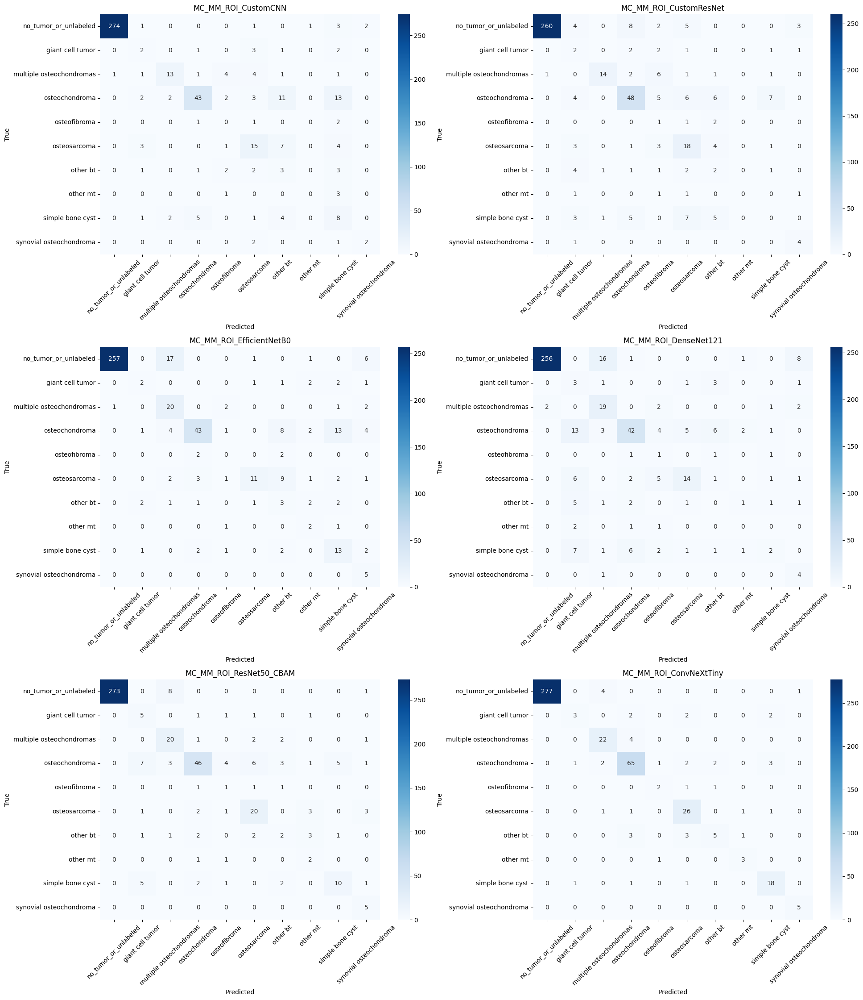

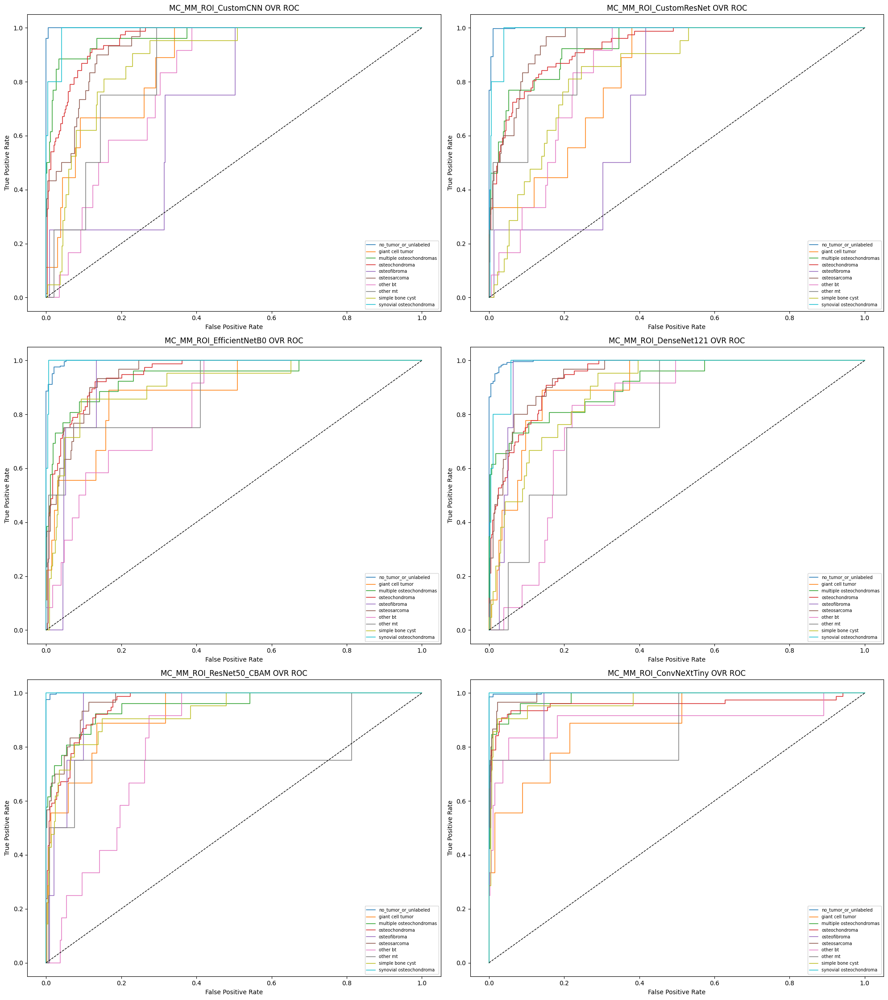

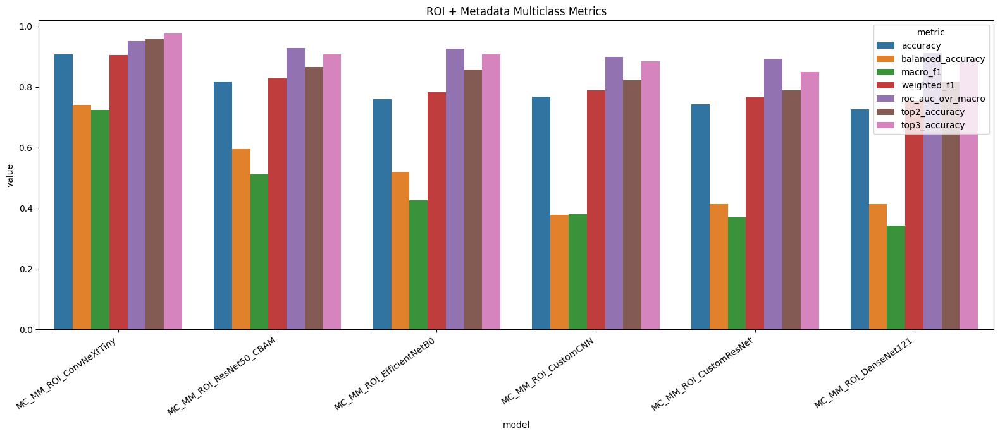

Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/multiclass_multimodal_model_comparison.csv
Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/multiclass_multimodal_classification_report.csv
Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/multiclass_multimodal_vs_imageonly_comparison.csv
Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/multiclass_multimodal_confusion_matrices.png
Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/multiclass_multimodal_roc_curves.png
Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/multiclass_multimodal_metric_bars.png
Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/multiclass_multimodal_predictions.npz


In [ ]:
# evaluate multiclass multimodal models
MC_MM_EVAL_MODEL_NAMES = MC_MM_ALL_MODEL_NAMES

custom_objects_5fm = globals().get('custom_objects_5fm', {})
custom_objects_5fm.update({
    'MCChannelMean': globals().get('MCChannelMean'),
    'MCChannelMax': globals().get('MCChannelMax'),
    'MCResNet50Preprocess': globals().get('MCResNet50Preprocess'),
})
custom_objects_5fm = {k: v for k, v in custom_objects_5fm.items() if v is not None}

def _safe_multiclass_auc_mm(y_true, prob):
    try:
        return float(roc_auc_score(y_true, prob, multi_class='ovr', average='macro', labels=list(range(MC_NUM_CLASSES))))
    except Exception:
        return np.nan

def _safe_top_k_mm(y_true, prob, k):
    try:
        return float(top_k_accuracy_score(y_true, prob, k=k, labels=list(range(MC_NUM_CLASSES))))
    except Exception:
        return np.nan

def compute_multiclass_mm_result(model_name, y_true, prob):
    pred = np.argmax(prob, axis=1)
    return {
        'model': model_name,
        'model_type': 'ROI + metadata',
        'accuracy': accuracy_score(y_true, pred),
        'balanced_accuracy': balanced_accuracy_score(y_true, pred),
        'macro_precision': precision_score(y_true, pred, average='macro', zero_division=0),
        'macro_recall': recall_score(y_true, pred, average='macro', zero_division=0),
        'macro_f1': f1_score(y_true, pred, average='macro', zero_division=0),
        'weighted_f1': f1_score(y_true, pred, average='weighted', zero_division=0),
        'roc_auc_ovr_macro': _safe_multiclass_auc_mm(y_true, prob),
        'top2_accuracy': _safe_top_k_mm(y_true, prob, 2),
        'top3_accuracy': _safe_top_k_mm(y_true, prob, 3),
    }

def _load_mc_mm_keras_checkpoint(model_name):
    ckpt = mc_mm_checkpoint_path(model_name)
    if not ckpt.exists():
        raise FileNotFoundError(f'Missing checkpoint: {ckpt}. Run CELL 5F-M-2 first.')
    return tf.keras.models.load_model(ckpt, compile=False, custom_objects=custom_objects_5fm)

def _load_mc_mm_convnext_checkpoint():
    ckpt_path = MC_MM_CONVNEXT_CKPT
    if not ckpt_path.exists():
        raise FileNotFoundError(f'Missing checkpoint: {ckpt_path}. Run CELL 5F-M-3 first.')
    ckpt = torch.load(ckpt_path, map_location=MC_MM_DEVICE)
    model = TimmConvNeXtMulticlassMultimodal(
        tabular_dim=int(ckpt.get('tabular_dim', MC_MM_TABULAR_DIM)),
        num_classes=int(ckpt.get('num_classes', MC_NUM_CLASSES)),
        model_name=ckpt.get('model_name', MC_MM_CONVNEXT_MODEL_NAME),
        pretrained=False,
    ).to(MC_MM_DEVICE)
    model.load_state_dict(ckpt['model_state_dict'])
    model.eval()
    return model

mc_mm_prob_by_model = {}
mc_mm_pred_by_model = {}
mc_mm_results = []
mc_mm_report_frames = []

for model_name in MC_MM_KERAS_MODELS:
    print(f'Evaluating {model_name}...')
    try:
        model = _load_mc_mm_keras_checkpoint(model_name)
    except FileNotFoundError as exc:
        print(f'  Skipping {model_name}: {exc}')
        continue
    prob = model.predict([X_roi_test.astype(np.float32, copy=False), X_tab_test.astype(np.float32, copy=False)], batch_size=32, verbose=0)
    mc_mm_prob_by_model[model_name] = prob
    mc_mm_pred_by_model[model_name] = np.argmax(prob, axis=1)
    mc_mm_results.append(compute_multiclass_mm_result(model_name, mc_y_test, prob))
    report = pd.DataFrame(classification_report(mc_y_test, mc_mm_pred_by_model[model_name], target_names=MC_CLASS_NAMES, output_dict=True, zero_division=0)).T
    report.insert(0, 'model', model_name)
    mc_mm_report_frames.append(report.reset_index(names='class_name'))
    del model
    tf.keras.backend.clear_session()
    gc.collect()

print('Evaluating MC_MM_ROI_ConvNeXtTiny...')
try:
    _, _, mc_mm_test_loader_eval = make_mc_mm_convnext_loaders()
    conv_mm_model = _load_mc_mm_convnext_checkpoint()
    prob_conv_mm, _ = predict_mc_mm_torch(conv_mm_model, mc_mm_test_loader_eval)
    mc_mm_prob_by_model['MC_MM_ROI_ConvNeXtTiny'] = prob_conv_mm
    mc_mm_pred_by_model['MC_MM_ROI_ConvNeXtTiny'] = np.argmax(prob_conv_mm, axis=1)
    mc_mm_results.append(compute_multiclass_mm_result('MC_MM_ROI_ConvNeXtTiny', mc_y_test, prob_conv_mm))
    report = pd.DataFrame(classification_report(mc_y_test, mc_mm_pred_by_model['MC_MM_ROI_ConvNeXtTiny'], target_names=MC_CLASS_NAMES, output_dict=True, zero_division=0)).T
    report.insert(0, 'model', 'MC_MM_ROI_ConvNeXtTiny')
    mc_mm_report_frames.append(report.reset_index(names='class_name'))
    del conv_mm_model
except FileNotFoundError as exc:
    print(f'  Skipping MC_MM_ROI_ConvNeXtTiny: {exc}')
if torch.cuda.is_available():
    torch.cuda.empty_cache()
gc.collect()

if not mc_mm_results:
    raise RuntimeError('No multiclass multimodal checkpoints were found. Run CELL 5F-M-2 and/or CELL 5F-M-3 first.')

MC_MM_EVAL_AVAILABLE_NAMES = list(mc_mm_prob_by_model.keys())
multiclass_multimodal_model_comparison_df = pd.DataFrame(mc_mm_results).sort_values(['macro_f1', 'balanced_accuracy'], ascending=False)
multiclass_multimodal_classification_report_df = pd.concat(mc_mm_report_frames, ignore_index=True)
multiclass_multimodal_model_comparison_df.to_csv(MULTICLASS_OUTPUT_DIR / 'multiclass_multimodal_model_comparison.csv', index=False)
multiclass_multimodal_classification_report_df.to_csv(MULTICLASS_OUTPUT_DIR / 'multiclass_multimodal_classification_report.csv', index=False)

mc_mm_per_class_display_df = multiclass_multimodal_classification_report_df[
    multiclass_multimodal_classification_report_df['class_name'].isin(MC_CLASS_NAMES)
].copy().sort_values(['model', 'class_name']).reset_index(drop=True)
print('Per-class multimodal multiclass metrics:')
display(mc_mm_per_class_display_df[['model', 'class_name', 'precision', 'recall', 'f1-score', 'support']].style.format({
    'precision': '{:.4f}', 'recall': '{:.4f}', 'f1-score': '{:.4f}', 'support': '{:.0f}'
}))

print('Multimodal multiclass model comparison:')
display(multiclass_multimodal_model_comparison_df.style.format({c: '{:.4f}' for c in multiclass_multimodal_model_comparison_df.select_dtypes(include='number').columns}))

image_only_comparison_path = MULTICLASS_OUTPUT_DIR / 'multiclass_roi_model_comparison.csv'
if image_only_comparison_path.exists():
    image_only_df = pd.read_csv(image_only_comparison_path).copy()
    image_only_df['model_type'] = 'ROI image-only'
    multimodal_vs_imageonly_df = pd.concat([image_only_df, multiclass_multimodal_model_comparison_df], ignore_index=True, sort=False)
    multimodal_vs_imageonly_df = multimodal_vs_imageonly_df.sort_values(['macro_f1', 'balanced_accuracy'], ascending=False)
    multimodal_vs_imageonly_df.to_csv(MULTICLASS_OUTPUT_DIR / 'multiclass_multimodal_vs_imageonly_comparison.csv', index=False)
    print('Image-only vs multimodal multiclass comparison:')
    display(multimodal_vs_imageonly_df[['model', 'model_type', 'accuracy', 'balanced_accuracy', 'macro_f1', 'weighted_f1', 'roc_auc_ovr_macro', 'top2_accuracy', 'top3_accuracy']].style.format({
        'accuracy': '{:.4f}', 'balanced_accuracy': '{:.4f}', 'macro_f1': '{:.4f}', 'weighted_f1': '{:.4f}',
        'roc_auc_ovr_macro': '{:.4f}', 'top2_accuracy': '{:.4f}', 'top3_accuracy': '{:.4f}'
    }))
else:
    multimodal_vs_imageonly_df = multiclass_multimodal_model_comparison_df.copy()
    print('Image-only comparison CSV not found; saved multimodal-only comparison.')

n_models = len(MC_MM_EVAL_AVAILABLE_NAMES)
n_cols = 2
n_rows = int(np.ceil(n_models / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(10 * n_cols, 7.5 * n_rows))
axes = np.asarray(axes).reshape(-1)
for ax, model_name in zip(axes, MC_MM_EVAL_AVAILABLE_NAMES):
    cm = confusion_matrix(mc_y_test, mc_mm_pred_by_model[model_name], labels=list(range(MC_NUM_CLASSES)))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=MC_CLASS_NAMES, yticklabels=MC_CLASS_NAMES, ax=ax)
    ax.set_title(model_name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.tick_params(axis='x', rotation=45)
    ax.tick_params(axis='y', rotation=0)
for ax in axes[n_models:]:
    ax.axis('off')
plt.tight_layout()
plt.savefig(MULTICLASS_OUTPUT_DIR / 'multiclass_multimodal_confusion_matrices.png', dpi=180, bbox_inches='tight')
plt.show()

y_test_bin = label_binarize(mc_y_test, classes=list(range(MC_NUM_CLASSES)))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(10 * n_cols, 7.5 * n_rows))
axes = np.asarray(axes).reshape(-1)
for ax, model_name in zip(axes, MC_MM_EVAL_AVAILABLE_NAMES):
    prob = mc_mm_prob_by_model[model_name]
    for class_id, class_name in enumerate(MC_CLASS_NAMES):
        if y_test_bin[:, class_id].sum() == 0:
            continue
        fpr, tpr, _ = roc_curve(y_test_bin[:, class_id], prob[:, class_id])
        ax.plot(fpr, tpr, linewidth=1.1, label=class_name)
    ax.plot([0, 1], [0, 1], 'k--', linewidth=1)
    ax.set_title(f'{model_name} OVR ROC')
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.legend(fontsize=7, loc='lower right')
for ax in axes[n_models:]:
    ax.axis('off')
plt.tight_layout()
plt.savefig(MULTICLASS_OUTPUT_DIR / 'multiclass_multimodal_roc_curves.png', dpi=180, bbox_inches='tight')
plt.show()

metrics_to_plot = ['accuracy', 'balanced_accuracy', 'macro_f1', 'weighted_f1', 'roc_auc_ovr_macro', 'top2_accuracy', 'top3_accuracy']
plot_df = multiclass_multimodal_model_comparison_df.melt(id_vars='model', value_vars=metrics_to_plot, var_name='metric', value_name='value')
plt.figure(figsize=(16, 7))
sns.barplot(data=plot_df, x='model', y='value', hue='metric')
plt.xticks(rotation=35, ha='right')
plt.ylim(0, 1.02)
plt.title('ROI + Metadata Multiclass Metrics')
plt.tight_layout()
plt.savefig(MULTICLASS_OUTPUT_DIR / 'multiclass_multimodal_metric_bars.png', dpi=180, bbox_inches='tight')
plt.show()

np.savez_compressed(
    MULTICLASS_OUTPUT_DIR / 'multiclass_multimodal_predictions.npz',
    y_test=mc_y_test,
    class_names=np.asarray(MC_CLASS_NAMES, dtype=object),
    model_names=np.asarray(MC_MM_EVAL_AVAILABLE_NAMES, dtype=object),
    **{f'{name}_prob': prob for name, prob in mc_mm_prob_by_model.items()},
)

print('Saved:', MULTICLASS_OUTPUT_DIR / 'multiclass_multimodal_model_comparison.csv')
print('Saved:', MULTICLASS_OUTPUT_DIR / 'multiclass_multimodal_classification_report.csv')
print('Saved:', MULTICLASS_OUTPUT_DIR / 'multiclass_multimodal_vs_imageonly_comparison.csv')
print('Saved:', MULTICLASS_OUTPUT_DIR / 'multiclass_multimodal_confusion_matrices.png')
print('Saved:', MULTICLASS_OUTPUT_DIR / 'multiclass_multimodal_roc_curves.png')
print('Saved:', MULTICLASS_OUTPUT_DIR / 'multiclass_multimodal_metric_bars.png')
print('Saved:', MULTICLASS_OUTPUT_DIR / 'multiclass_multimodal_predictions.npz')


## Subsection 3.3 - Multiclass ROI vs Multimodal Comparison
Direct performance comparisons between multiclass image-only models and multimodal fusion architectures.


We compile all multiclass ROI and multimodal model evaluation metrics into a comparison table.


In [ ]:
# compile multiclass results

MC_DENSE_OUTPUT_DIR = Path(globals().get('MULTICLASS_OUTPUT_DIR', Path(OUTPUT_DIR) / 'multiclass_outputs'))
MC_DENSE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MC_DENSE_RANK_COLS = ['macro_f1', 'balanced_accuracy']
MC_DENSE_METRIC_COLS = [
    'accuracy', 'balanced_accuracy', 'macro_precision', 'macro_recall',
    'macro_f1', 'weighted_f1', 'roc_auc_ovr_macro', 'top2_accuracy', 'top3_accuracy'
]

def _mc_dense_read_csv(filename, model_type, optional=True):
    path = MC_DENSE_OUTPUT_DIR / filename
    if not path.exists():
        if optional:
            print(f'Warning: missing {path}; skipping.')
            return pd.DataFrame()
        raise FileNotFoundError(path)
    df = pd.read_csv(path)
    if 'model' not in df.columns:
        return pd.DataFrame()
    df = df.copy()
    df['model_type'] = model_type
    df['source_file'] = filename
    return df

image_main = _mc_dense_read_csv('multiclass_roi_model_comparison.csv', 'ROI image-only')
conv_v2 = _mc_dense_read_csv('multiclass_convnext_v2_comparison.csv', 'ROI image-only ConvNeXt variant')
conv_v3 = _mc_dense_read_csv('multiclass_convnext_v3_comparison.csv', 'ROI image-only ConvNeXt variant')
multimodal = _mc_dense_read_csv('multiclass_multimodal_model_comparison.csv', 'ROI + metadata')

mc_dense_all_models_df = pd.concat([image_main, conv_v2, conv_v3, multimodal], ignore_index=True, sort=False)
if mc_dense_all_models_df.empty:
    raise RuntimeError('No multiclass comparison CSVs found. Run Section 5F/5F-M evaluations first.')

# Keep one row per model, preferring the latest/most specific source order above.
mc_dense_all_models_df['_source_order'] = np.arange(len(mc_dense_all_models_df))
mc_dense_all_models_df = (
    mc_dense_all_models_df
    .sort_values('_source_order')
    .drop_duplicates(subset=['model'], keep='last')
    .drop(columns=['_source_order'])
)
mc_dense_all_models_df = mc_dense_all_models_df.sort_values(MC_DENSE_RANK_COLS, ascending=False, na_position='last').reset_index(drop=True)

mc_dense_image_only_df = mc_dense_all_models_df[mc_dense_all_models_df['model_type'].str.contains('image-only', case=False, na=False)].copy()
mc_dense_multimodal_df = mc_dense_all_models_df[mc_dense_all_models_df['model_type'].eq('ROI + metadata')].copy()
mc_dense_top_models_df = mc_dense_all_models_df.head(5).copy()

mc_dense_all_models_df.to_csv(MC_DENSE_OUTPUT_DIR / 'multiclass_dense_eval_all_models_metrics.csv', index=False)
mc_dense_image_only_df.to_csv(MC_DENSE_OUTPUT_DIR / 'multiclass_dense_eval_all_imageonly_comparison.csv', index=False)
mc_dense_multimodal_df.to_csv(MC_DENSE_OUTPUT_DIR / 'multiclass_dense_eval_all_multimodal_comparison.csv', index=False)
mc_dense_top_models_df.to_csv(MC_DENSE_OUTPUT_DIR / 'multiclass_dense_eval_top_models.csv', index=False)

best_image = mc_dense_image_only_df.head(1)
best_mm = mc_dense_multimodal_df.head(1)
mc_dense_best_mm_vs_image_df = pd.concat([best_image, best_mm], ignore_index=True, sort=False)
mc_dense_best_mm_vs_image_df.to_csv(MC_DENSE_OUTPUT_DIR / 'multiclass_dense_eval_best_multimodal_vs_best_imageonly.csv', index=False)

pair_specs = [
    ('Custom CNN', 'MC_ROI_CustomCNN', 'MC_MM_ROI_CustomCNN'),
    ('Custom ResNet', 'MC_ROI_CustomResNet', 'MC_MM_ROI_CustomResNet'),
    ('EfficientNetB0', 'MC_ROI_EfficientNetB0', 'MC_MM_ROI_EfficientNetB0'),
    ('DenseNet121', 'MC_ROI_DenseNet121', 'MC_MM_ROI_DenseNet121'),
    ('ResNet50-CBAM', 'MC_ROI_ResNet50_CBAM', 'MC_MM_ROI_ResNet50_CBAM'),
    ('ConvNeXt-Tiny', 'MC_ROI_ConvNeXtTiny', 'MC_MM_ROI_ConvNeXtTiny'),
]
pair_rows=[]
for family, image_name, mm_name in pair_specs:
    img = mc_dense_all_models_df[mc_dense_all_models_df['model'].eq(image_name)]
    mm = mc_dense_all_models_df[mc_dense_all_models_df['model'].eq(mm_name)]
    if img.empty or mm.empty:
        continue
    img_row = img.iloc[0]
    mm_row = mm.iloc[0]
    pair_rows.append({'family': family, 'variant': 'ROI image-only', **img_row.to_dict()})
    pair_rows.append({'family': family, 'variant': 'ROI + metadata', **mm_row.to_dict()})
    delta = {'family': family, 'variant': 'Delta metadata - image-only', 'model': 'change', 'model_type': 'delta'}
    for metric in MC_DENSE_METRIC_COLS:
        if metric in img_row.index and metric in mm_row.index:
            delta[metric] = mm_row[metric] - img_row[metric]
    pair_rows.append(delta)
mc_dense_pairs_df = pd.DataFrame(pair_rows)
mc_dense_pairs_df.to_csv(MC_DENSE_OUTPUT_DIR / 'multiclass_dense_eval_imageonly_vs_multimodal_pairs.csv', index=False)

_display_cols = ['model', 'model_type'] + [c for c in MC_DENSE_METRIC_COLS if c in mc_dense_all_models_df.columns]
_numeric_cols = [c for c in _display_cols if c in mc_dense_all_models_df.columns and pd.api.types.is_numeric_dtype(mc_dense_all_models_df[c])]

def _mc_dense_display(df, title, highlight=True):
    print('\n' + title)
    view = df[[c for c in _display_cols if c in df.columns]].copy()
    styler = view.style.format('{:.4f}', subset=[c for c in _numeric_cols if c in view.columns])
    if highlight:
        styler = styler.highlight_max(color='lightgreen', axis=0, subset=[c for c in _numeric_cols if c in view.columns])
    display(styler)

_mc_dense_display(mc_dense_top_models_df, 'TOP MULTICLASS ROI MODELS')
_mc_dense_display(mc_dense_image_only_df, 'ALL MULTICLASS ROI IMAGE-ONLY MODELS')
_mc_dense_display(mc_dense_multimodal_df, 'ALL MULTICLASS ROI + METADATA MODELS')
_mc_dense_display(mc_dense_best_mm_vs_image_df, 'BEST MULTIMODAL VS BEST IMAGE-ONLY MULTICLASS MODEL')

if not mc_dense_pairs_df.empty:
    print('\nIMAGE-ONLY VS MULTIMODAL PAIRS')
    pair_cols = ['family', 'variant', 'model'] + [c for c in MC_DENSE_METRIC_COLS if c in mc_dense_pairs_df.columns]
    pair_num = [c for c in pair_cols if c in mc_dense_pairs_df.columns and pd.api.types.is_numeric_dtype(mc_dense_pairs_df[c])]
    display(mc_dense_pairs_df[pair_cols].style.format('{:.4f}', subset=pair_num))

print('Saved dense multiclass metric tables under:', MC_DENSE_OUTPUT_DIR)



TOP MULTICLASS ROI MODELS


,model,model_type,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,roc_auc_ovr_macro,top2_accuracy,top3_accuracy
0,MC_ROI_ConvNeXtTiny,ROI image-only ConvNeXt variant,0.9275,0.7189,0.8018,0.7189,0.7343,0.9244,0.9497,0.9638,0.9723
1,MC_MM_ROI_ConvNeXtTiny,ROI + metadata,0.9083,0.7407,0.7265,0.7407,0.7251,0.9065,0.9528,0.9574,0.9765
2,MC_ROI_ConvNeXtTiny_V3,ROI image-only ConvNeXt variant,0.9168,0.6676,0.8095,0.6676,0.7013,0.9113,0.9648,0.9488,0.9595
3,MC_ROI_ConvNeXtTiny_V2,ROI image-only ConvNeXt variant,0.8870,0.6555,0.6598,0.6555,0.6498,0.8903,0.9643,0.9488,0.9787
4,MC_ROI_ResNet50_CBAM,ROI image-only,0.8806,0.6834,0.6536,0.6834,0.6428,0.8834,0.9559,0.9339,0.9595



ALL MULTICLASS ROI IMAGE-ONLY MODELS


,model,model_type,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,roc_auc_ovr_macro,top2_accuracy,top3_accuracy
0,MC_ROI_ConvNeXtTiny,ROI image-only ConvNeXt variant,0.9275,0.7189,0.8018,0.7189,0.7343,0.9244,0.9497,0.9638,0.9723
2,MC_ROI_ConvNeXtTiny_V3,ROI image-only ConvNeXt variant,0.9168,0.6676,0.8095,0.6676,0.7013,0.9113,0.9648,0.9488,0.9595
3,MC_ROI_ConvNeXtTiny_V2,ROI image-only ConvNeXt variant,0.8870,0.6555,0.6598,0.6555,0.6498,0.8903,0.9643,0.9488,0.9787
4,MC_ROI_ResNet50_CBAM,ROI image-only,0.8806,0.6834,0.6536,0.6834,0.6428,0.8834,0.9559,0.9339,0.9595
5,MC_ROI_DenseNet121,ROI image-only,0.8188,0.6396,0.5010,0.6396,0.5346,0.8300,0.9519,0.8763,0.9168
7,MC_ROI_EfficientNetB0,ROI image-only,0.7633,0.5636,0.4736,0.5636,0.4850,0.7819,0.9387,0.8635,0.9083
12,MC_ROI_CustomCNN,ROI image-only,0.6951,0.2729,0.2763,0.2729,0.2391,0.7051,0.8680,0.7612,0.8188
13,MC_ROI_CustomResNet,ROI image-only,0.5608,0.2405,0.2103,0.2405,0.2095,0.5888,0.8102,0.6525,0.7015



ALL MULTICLASS ROI + METADATA MODELS


,model,model_type,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,roc_auc_ovr_macro,top2_accuracy,top3_accuracy
1,MC_MM_ROI_ConvNeXtTiny,ROI + metadata,0.9083,0.7407,0.7265,0.7407,0.7251,0.9065,0.9528,0.9574,0.9765
6,MC_MM_ROI_ResNet50_CBAM,ROI + metadata,0.8188,0.5958,0.4887,0.5958,0.5123,0.8297,0.9289,0.8657,0.9083
8,MC_MM_ROI_EfficientNetB0,ROI + metadata,0.7591,0.5204,0.4353,0.5204,0.4272,0.7827,0.9276,0.8571,0.9083
9,MC_MM_ROI_CustomCNN,ROI + metadata,0.7676,0.3791,0.4050,0.3791,0.3805,0.7892,0.8988,0.8230,0.8849
10,MC_MM_ROI_CustomResNet,ROI + metadata,0.7441,0.4131,0.3699,0.4131,0.3701,0.7660,0.8934,0.7889,0.8486
11,MC_MM_ROI_DenseNet121,ROI + metadata,0.7271,0.4136,0.3516,0.4136,0.3432,0.7532,0.9125,0.8188,0.8849



BEST MULTIMODAL VS BEST IMAGE-ONLY MULTICLASS MODEL


,model,model_type,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,roc_auc_ovr_macro,top2_accuracy,top3_accuracy
0,MC_ROI_ConvNeXtTiny,ROI image-only ConvNeXt variant,0.9275,0.7189,0.8018,0.7189,0.7343,0.9244,0.9497,0.9638,0.9723
1,MC_MM_ROI_ConvNeXtTiny,ROI + metadata,0.9083,0.7407,0.7265,0.7407,0.7251,0.9065,0.9528,0.9574,0.9765



IMAGE-ONLY VS MULTIMODAL PAIRS


,family,variant,model,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,roc_auc_ovr_macro,top2_accuracy,top3_accuracy
0,Custom CNN,ROI image-only,MC_ROI_CustomCNN,0.6951,0.2729,0.2763,0.2729,0.2391,0.7051,0.8680,0.7612,0.8188
1,Custom CNN,ROI + metadata,MC_MM_ROI_CustomCNN,0.7676,0.3791,0.4050,0.3791,0.3805,0.7892,0.8988,0.8230,0.8849
2,Custom CNN,Delta metadata - image-only,change,0.0725,0.1062,0.1287,0.1062,0.1413,0.0840,0.0308,0.0618,0.0661
3,Custom ResNet,ROI image-only,MC_ROI_CustomResNet,0.5608,0.2405,0.2103,0.2405,0.2095,0.5888,0.8102,0.6525,0.7015
4,Custom ResNet,ROI + metadata,MC_MM_ROI_CustomResNet,0.7441,0.4131,0.3699,0.4131,0.3701,0.7660,0.8934,0.7889,0.8486
5,Custom ResNet,Delta metadata - image-only,change,0.1834,0.1726,0.1596,0.1726,0.1606,0.1772,0.0832,0.1365,0.1471
6,EfficientNetB0,ROI image-only,MC_ROI_EfficientNetB0,0.7633,0.5636,0.4736,0.5636,0.4850,0.7819,0.9387,0.8635,0.9083
7,EfficientNetB0,ROI + metadata,MC_MM_ROI_EfficientNetB0,0.7591,0.5204,0.4353,0.5204,0.4272,0.7827,0.9276,0.8571,0.9083
8,EfficientNetB0,Delta metadata - image-only,change,-0.0043,-0.0432,-0.0383,-0.0432,-0.0578,0.0007,-0.0111,-0.0064,0.0000
9,DenseNet121,ROI image-only,MC_ROI_DenseNet121,0.8188,0.6396,0.5010,0.6396,0.5346,0.8300,0.9519,0.8763,0.9168


Saved dense multiclass metric tables under: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs


We plot multiclass prediction distributions, ROC curves, and confusion matrices for comparison.


Dense multiclass per-class metrics:


,model,class_name,precision,recall,f1-score,support
0,MC_MM_ROI_ConvNeXtTiny,giant cell tumor,0.6000,0.3333,0.4286,9
1,MC_MM_ROI_ConvNeXtTiny,multiple osteochondromas,0.7586,0.8462,0.8000,26
2,MC_MM_ROI_ConvNeXtTiny,no_tumor_or_unlabeled,1.0000,0.9823,0.9911,282
3,MC_MM_ROI_ConvNeXtTiny,osteochondroma,0.8553,0.8553,0.8553,76
4,MC_MM_ROI_ConvNeXtTiny,osteofibroma,0.5000,0.5000,0.5000,4
5,MC_MM_ROI_ConvNeXtTiny,osteosarcoma,0.7429,0.8667,0.8000,30
6,MC_MM_ROI_ConvNeXtTiny,other bt,0.6250,0.4167,0.5000,12
7,MC_MM_ROI_ConvNeXtTiny,other mt,0.6000,0.7500,0.6667,4
8,MC_MM_ROI_ConvNeXtTiny,simple bone cyst,0.7500,0.8571,0.8000,21
9,MC_MM_ROI_ConvNeXtTiny,synovial osteochondroma,0.8333,1.0000,0.9091,5


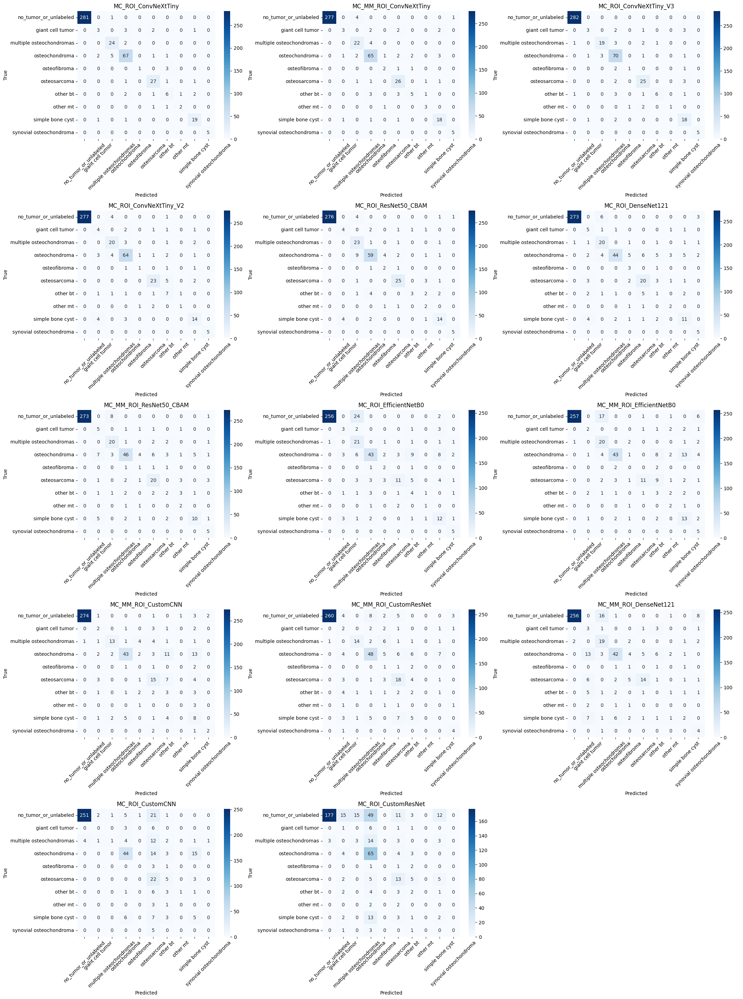

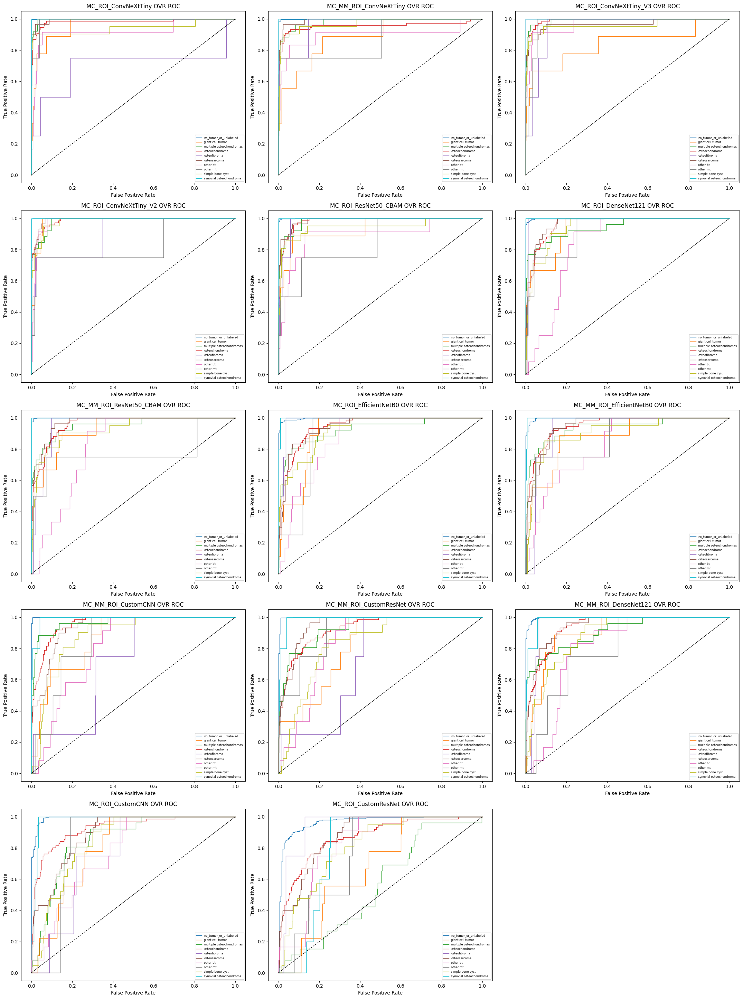

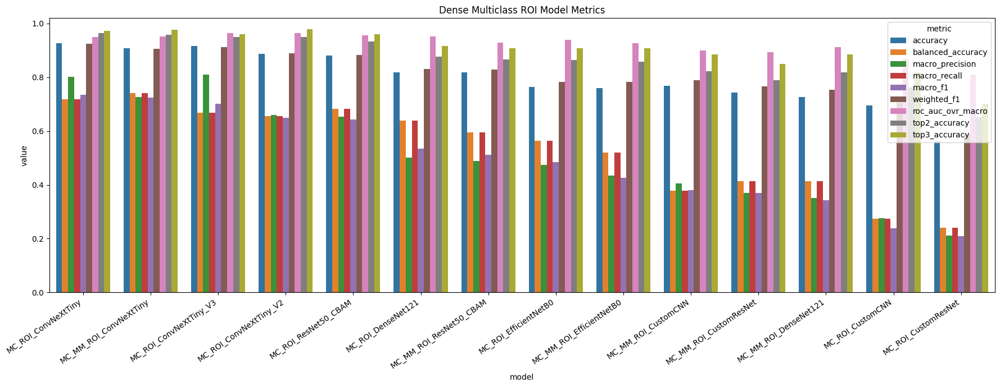

Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/multiclass_dense_eval_classification_report.csv
Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/multiclass_dense_eval_per_class_metrics.csv
Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/multiclass_dense_eval_confusion_matrices.png
Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/multiclass_dense_eval_roc_curves.png
Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/multiclass_dense_eval_metric_bars.png
Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/multiclass_dense_eval_predictions.npz


In [ ]:
# generate multiclass evaluation plots

if 'MC_DENSE_OUTPUT_DIR' not in globals():
    MC_DENSE_OUTPUT_DIR = Path(globals().get('MULTICLASS_OUTPUT_DIR', Path(OUTPUT_DIR) / 'multiclass_outputs'))

mc_dense_prob_by_model = {}
mc_dense_class_names = None
mc_dense_y_test = None

def _mc_dense_load_npz(path):
    if not path.exists():
        print(f'Warning: missing predictions file: {path}')
        return None
    return np.load(path, allow_pickle=True)

main_npz = _mc_dense_load_npz(MC_DENSE_OUTPUT_DIR / 'multiclass_roi_predictions.npz')
if main_npz is not None:
    mc_dense_y_test = main_npz['y_test'].astype(int)
    mc_dense_class_names = [str(x) for x in main_npz['class_names']]
    for name in main_npz['model_names']:
        name = str(name)
        key = f'{name}_prob'
        if key in main_npz.files:
            mc_dense_prob_by_model[name] = main_npz[key].astype(np.float32)

v2_npz = _mc_dense_load_npz(MC_DENSE_OUTPUT_DIR / 'multiclass_convnext_v2_predictions.npz')
if v2_npz is not None:
    mc_dense_y_test = v2_npz['y_test'].astype(int)
    mc_dense_class_names = [str(x) for x in v2_npz['class_names']]
    if 'v2_prob' in v2_npz.files:
        mc_dense_prob_by_model['MC_ROI_ConvNeXtTiny_V2'] = v2_npz['v2_prob'].astype(np.float32)

v3_npz = _mc_dense_load_npz(MC_DENSE_OUTPUT_DIR / 'multiclass_convnext_v3_predictions.npz')
if v3_npz is not None:
    mc_dense_y_test = v3_npz['y_test'].astype(int)
    mc_dense_class_names = [str(x) for x in v3_npz['class_names']]
    if 'v3_prob' in v3_npz.files:
        mc_dense_prob_by_model['MC_ROI_ConvNeXtTiny_V3'] = v3_npz['v3_prob'].astype(np.float32)

mm_npz = _mc_dense_load_npz(MC_DENSE_OUTPUT_DIR / 'multiclass_multimodal_predictions.npz')
if mm_npz is not None:
    mc_dense_y_test = mm_npz['y_test'].astype(int)
    mc_dense_class_names = [str(x) for x in mm_npz['class_names']]
    for name in mm_npz['model_names']:
        name = str(name)
        key = f'{name}_prob'
        if key in mm_npz.files:
            mc_dense_prob_by_model[name] = mm_npz[key].astype(np.float32)

if not mc_dense_prob_by_model:
    raise RuntimeError('No multiclass prediction probabilities found. Run Section 5F/5F-M evaluation cells first.')
if mc_dense_y_test is None or mc_dense_class_names is None:
    raise RuntimeError('Missing multiclass y_test/class_names in prediction files.')

# Plot in metric-ranking order where possible.
plot_model_names = [m for m in mc_dense_all_models_df['model'].tolist() if m in mc_dense_prob_by_model] if 'mc_dense_all_models_df' in globals() else list(mc_dense_prob_by_model)
mc_dense_pred_by_model = {name: np.argmax(mc_dense_prob_by_model[name], axis=1) for name in plot_model_names}

report_frames=[]
for model_name in plot_model_names:
    report = pd.DataFrame(classification_report(mc_dense_y_test, mc_dense_pred_by_model[model_name], target_names=mc_dense_class_names, output_dict=True, zero_division=0)).T
    report.insert(0, 'model', model_name)
    report_frames.append(report.reset_index(names='class_name'))
mc_dense_classification_report_df = pd.concat(report_frames, ignore_index=True)
mc_dense_per_class_report_df = mc_dense_classification_report_df[
    mc_dense_classification_report_df['class_name'].isin(mc_dense_class_names)
].copy().sort_values(['model', 'class_name']).reset_index(drop=True)
mc_dense_classification_report_df.to_csv(MC_DENSE_OUTPUT_DIR / 'multiclass_dense_eval_classification_report.csv', index=False)
mc_dense_per_class_report_df.to_csv(MC_DENSE_OUTPUT_DIR / 'multiclass_dense_eval_per_class_metrics.csv', index=False)

print('Dense multiclass per-class metrics:')
display(mc_dense_per_class_report_df[['model', 'class_name', 'precision', 'recall', 'f1-score', 'support']].style.format({
    'precision': '{:.4f}', 'recall': '{:.4f}', 'f1-score': '{:.4f}', 'support': '{:.0f}'
}))

n_models = len(plot_model_names)
n_cols = 3
n_rows = int(np.ceil(n_models / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(7.2 * n_cols, 5.8 * n_rows))
axes = np.asarray(axes).reshape(-1)
for ax, model_name in zip(axes, plot_model_names):
    cm = confusion_matrix(mc_dense_y_test, mc_dense_pred_by_model[model_name], labels=list(range(len(mc_dense_class_names))))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=mc_dense_class_names, yticklabels=mc_dense_class_names, ax=ax)
    ax.set_title(model_name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.tick_params(axis='x', rotation=45)
for ax in axes[n_models:]:
    ax.axis('off')
plt.tight_layout()
plt.savefig(MC_DENSE_OUTPUT_DIR / 'multiclass_dense_eval_confusion_matrices.png', dpi=180, bbox_inches='tight')
plt.show()

y_bin = label_binarize(mc_dense_y_test, classes=list(range(len(mc_dense_class_names))))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(7.2 * n_cols, 5.8 * n_rows))
axes = np.asarray(axes).reshape(-1)
for ax, model_name in zip(axes, plot_model_names):
    prob = mc_dense_prob_by_model[model_name]
    for class_id, class_name in enumerate(mc_dense_class_names):
        if y_bin[:, class_id].sum() == 0:
            continue
        fpr, tpr, _ = roc_curve(y_bin[:, class_id], prob[:, class_id])
        ax.plot(fpr, tpr, linewidth=1.0, label=class_name)
    ax.plot([0, 1], [0, 1], 'k--', linewidth=1)
    ax.set_title(f'{model_name} OVR ROC')
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.legend(fontsize=6, loc='lower right')
for ax in axes[n_models:]:
    ax.axis('off')
plt.tight_layout()
plt.savefig(MC_DENSE_OUTPUT_DIR / 'multiclass_dense_eval_roc_curves.png', dpi=180, bbox_inches='tight')
plt.show()

metric_cols = [c for c in MC_DENSE_METRIC_COLS if 'mc_dense_all_models_df' in globals() and c in mc_dense_all_models_df.columns]
if metric_cols:
    plot_df = mc_dense_all_models_df[mc_dense_all_models_df['model'].isin(plot_model_names)].melt(id_vars='model', value_vars=metric_cols, var_name='metric', value_name='value')
    plt.figure(figsize=(18, 7))
    sns.barplot(data=plot_df, x='model', y='value', hue='metric')
    plt.xticks(rotation=35, ha='right')
    plt.ylim(0, 1.02)
    plt.title('Dense Multiclass ROI Model Metrics')
    plt.tight_layout()
    plt.savefig(MC_DENSE_OUTPUT_DIR / 'multiclass_dense_eval_metric_bars.png', dpi=180, bbox_inches='tight')
    plt.show()

np.savez_compressed(
    MC_DENSE_OUTPUT_DIR / 'multiclass_dense_eval_predictions.npz',
    y_test=mc_dense_y_test,
    class_names=np.asarray(mc_dense_class_names, dtype=object),
    model_names=np.asarray(plot_model_names, dtype=object),
    **{f'{name}_prob': mc_dense_prob_by_model[name] for name in plot_model_names},
)

print('Saved:', MC_DENSE_OUTPUT_DIR / 'multiclass_dense_eval_classification_report.csv')
print('Saved:', MC_DENSE_OUTPUT_DIR / 'multiclass_dense_eval_per_class_metrics.csv')
print('Saved:', MC_DENSE_OUTPUT_DIR / 'multiclass_dense_eval_confusion_matrices.png')
print('Saved:', MC_DENSE_OUTPUT_DIR / 'multiclass_dense_eval_roc_curves.png')
print('Saved:', MC_DENSE_OUTPUT_DIR / 'multiclass_dense_eval_metric_bars.png')
print('Saved:', MC_DENSE_OUTPUT_DIR / 'multiclass_dense_eval_predictions.npz')


# SECTION 4 - Experiment Dataset 2 Evaluation & Pseudo-Labeling
Evaluating models on Dataset 2 and generating pseudo-labels.


We load Dataset 2 true labels and align the image paths to prepare for evaluation.


In [ ]:
# Load Dataset 2 true labels and build aligned image arrays


required_6y_base = ['OUTPUT_DIR', 'IMG_SIZE']
missing_6y_base = [name for name in required_6y_base if name not in globals()]
if missing_6y_base:
    raise RuntimeError(f'SECTION 6Y requires the notebook preprocessing setup first. Missing: {missing_6y_base}')

PROJECT_ROOT_6Y = Path.cwd().resolve()
if PROJECT_ROOT_6Y.name == 'vlm_pipeline':
    PROJECT_ROOT_6Y = PROJECT_ROOT_6Y.parent
DATASET2_DIR_6Y = PROJECT_ROOT_6Y / 'GP Dataset 2'
MULTICLASS_OUTPUT_DIR = Path(globals().get('MULTICLASS_OUTPUT_DIR', Path(OUTPUT_DIR) / 'multiclass_outputs'))
SECTION6Y_OUTPUT_DIR = MULTICLASS_OUTPUT_DIR / 'section6_dataset2_pseudolabel_benchmark'
SECTION6Y_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

D2_SPLIT_MAP_6Y = {'train': 'train', 'valid': 'valid', 'test': 'test'}
D2_LABEL_COLS_6Y = {'cancer': 1, 'normal': 0}
D2_IMAGE_EXTS_6Y = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'}

if not DATASET2_DIR_6Y.exists():
    raise FileNotFoundError(f'Dataset 2 folder not found: {DATASET2_DIR_6Y}')

def _d2_clean_columns_6y(df):
    out = df.copy()
    out.columns = [str(c).strip() for c in out.columns]
    return out

def _d2_load_split_manifest_6y(split_name):
    csv_path = DATASET2_DIR_6Y / split_name / '_classes.csv'
    if not csv_path.exists():
        raise FileNotFoundError(f'Missing Dataset 2 class CSV: {csv_path}')
    df = _d2_clean_columns_6y(pd.read_csv(csv_path))
    required_cols = {'filename', 'cancer', 'normal'}
    missing_cols = sorted(required_cols - set(df.columns))
    if missing_cols:
        raise ValueError(f'{csv_path} missing expected columns: {missing_cols}')
    label_sum = df[['cancer', 'normal']].sum(axis=1)
    bad_rows = df[label_sum != 1]
    if len(bad_rows):
        raise ValueError(f'{csv_path} has {len(bad_rows)} rows without exactly one active cancer/normal label.')
    rows = []
    missing_files = []
    for _, row in df.iterrows():
        filename = str(row['filename']).strip()
        img_path = DATASET2_DIR_6Y / split_name / filename
        if not img_path.exists():
            missing_files.append(filename)
            continue
        label = int(row['cancer'])
        rows.append({
            'split': split_name,
            'filename': filename,
            'rel_path': str(Path(split_name) / filename),
            'path': img_path,
            'y_true_cancer': label,
        })
    if missing_files:
        raise FileNotFoundError(f'{split_name}: {len(missing_files)} files listed in _classes.csv were not found. First examples: {missing_files[:5]}')
    return rows

def _d2_fallback_preprocess_6y(img_path, size=IMG_SIZE):
    img = PILImage.open(img_path).convert('RGB').resize(size)
    return (np.asarray(img, dtype=np.float32) / 255.0).astype(np.float32)

def preprocess_d2_6y_image(img_path):
    if 'full_preprocessing_pipeline' in globals():
        img = full_preprocessing_pipeline(str(img_path))
        if img is not None:
            return img.astype(np.float32)
    return _d2_fallback_preprocess_6y(img_path)

def _d2_pack_split_6y(rows, split_name):
    split_rows = [r for r in rows if r['split'] == split_name]
    imgs, labels, paths, filenames = [], [], [], []
    for row in tqdm(split_rows, desc=f'Preprocess Dataset 2 {split_name}'):
        img = preprocess_d2_6y_image(row['path'])
        imgs.append(img.astype(np.float32))
        labels.append(int(row['y_true_cancer']))
        paths.append(row['rel_path'])
        filenames.append(row['filename'])
    X = np.asarray(imgs, dtype=np.float32) if imgs else np.empty((0, IMG_SIZE[0], IMG_SIZE[1], 3), dtype=np.float32)
    y = np.asarray(labels, dtype=np.int32)
    return X, y, paths, filenames

D2_TRUE_ROWS_6Y = []
for split_name in D2_SPLIT_MAP_6Y:
    D2_TRUE_ROWS_6Y.extend(_d2_load_split_manifest_6y(split_name))

dataset2_true_label_manifest_df = pd.DataFrame([
    {k: v for k, v in row.items() if k != 'path'} for row in D2_TRUE_ROWS_6Y
])
dataset2_true_label_manifest_df.to_csv(SECTION6Y_OUTPUT_DIR / 'dataset2_true_label_manifest.csv', index=False)

X2_6y_train, y2_6y_train_true, X2_6y_train_paths, X2_6y_train_filenames = _d2_pack_split_6y(D2_TRUE_ROWS_6Y, 'train')
X2_6y_valid, y2_6y_valid_true, X2_6y_valid_paths, X2_6y_valid_filenames = _d2_pack_split_6y(D2_TRUE_ROWS_6Y, 'valid')
X2_6y_test,  y2_6y_test_true,  X2_6y_test_paths,  X2_6y_test_filenames  = _d2_pack_split_6y(D2_TRUE_ROWS_6Y, 'test')

TABULAR_DIM_6Y = int(globals().get('MC_MM_TABULAR_DIM', globals().get('TABULAR_DIM', 8)))
X2_6y_tab_train_zero = np.zeros((len(X2_6y_train), TABULAR_DIM_6Y), dtype=np.float32)
X2_6y_tab_valid_zero = np.zeros((len(X2_6y_valid), TABULAR_DIM_6Y), dtype=np.float32)
X2_6y_tab_test_zero = np.zeros((len(X2_6y_test), TABULAR_DIM_6Y), dtype=np.float32)

print('\n' + '=' * 78)
print('SECTION 6Y: DATASET 2 TRUE-LABEL BENCHMARK ARRAYS')
print('=' * 78)
for split_name, X_arr, y_arr in [
    ('train', X2_6y_train, y2_6y_train_true),
    ('valid', X2_6y_valid, y2_6y_valid_true),
    ('test', X2_6y_test, y2_6y_test_true),
]:
    counts = dict(zip(*np.unique(y_arr, return_counts=True))) if len(y_arr) else {}
    print(f'{split_name:<5}: X={X_arr.shape}, labels={counts}')
print(f'Saved: {SECTION6Y_OUTPUT_DIR / "dataset2_true_label_manifest.csv"}')
print('=' * 78)
display(dataset2_true_label_manifest_df.groupby(['split', 'y_true_cancer']).size().reset_index(name='count'))


Preprocess Dataset 2 test: 100%|██████████| 872/872 [00:02<00:00, 326.89it/s]


SECTION 6Y: DATASET 2 TRUE-LABEL BENCHMARK ARRAYS
train: X=(7057, 224, 224, 3), labels={np.int32(0): np.int64(3976), np.int32(1): np.int64(3081)}
valid: X=(882, 224, 224, 3), labels={np.int32(0): np.int64(484), np.int32(1): np.int64(398)}
test : X=(872, 224, 224, 3), labels={np.int32(0): np.int64(488), np.int32(1): np.int64(384)}
Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/section6_dataset2_pseudolabel_benchmark/dataset2_true_label_manifest.csv


,split,y_true_cancer,count
0,test,0,488
1,test,1,384
2,train,0,3976
3,train,1,3081
4,valid,0,484
5,valid,1,398


We run the image-only multiclass checkpoints on Dataset 2 as pseudo-labelers.


In [ ]:
# evaluate Dataset 2 image-only pseudo-labeler


required_6y_img = [
    'X2_6y_train', 'X2_6y_valid', 'X2_6y_test',
    'y2_6y_valid_true', 'y2_6y_test_true',
    'MULTICLASS_OUTPUT_DIR', 'SECTION6Y_OUTPUT_DIR',
]
missing_6y_img = [name for name in required_6y_img if name not in globals()]
if missing_6y_img:
    raise RuntimeError(f'Run CELL 6Y-1 first. Missing: {missing_6y_img}')

MC_CLASS_NAMES_6Y = list(globals().get('MC_CLASS_NAMES', ['no_tumor_or_unlabeled']))
MC_NUM_CLASSES_6Y = int(globals().get('MC_NUM_CLASSES', len(MC_CLASS_NAMES_6Y)))
NORMAL_CLASS_ID_6Y = MC_CLASS_NAMES_6Y.index('no_tumor_or_unlabeled') if 'no_tumor_or_unlabeled' in MC_CLASS_NAMES_6Y else 0
MC_CONVNEXT_MODEL_NAME_6Y = globals().get('MC_CONVNEXT_MODEL_NAME', globals().get('CONTRIB_MODEL_NAME', 'convnext_tiny'))
MC_DEVICE_6Y = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
MC_BATCH_SIZE_6Y = int(globals().get('MC_BATCH_SIZE', globals().get('BATCH_SIZE', 16)))
MC_MEAN_6Y = torch.tensor([0.485, 0.456, 0.406], dtype=torch.float32).view(3, 1, 1)
MC_STD_6Y = torch.tensor([0.229, 0.224, 0.225], dtype=torch.float32).view(3, 1, 1)

section6y_prediction_cache = globals().get('section6y_prediction_cache', {})
section6y_eval_rows = globals().get('section6y_eval_rows', [])
section6y_skipped_models = globals().get('section6y_skipped_models', [])

custom_objects_6y = {
    'MCChannelMean': globals().get('MCChannelMean'),
    'MCChannelMax': globals().get('MCChannelMax'),
    'MCResNet50Preprocess': globals().get('MCResNet50Preprocess'),
}
custom_objects_6y = {k: v for k, v in custom_objects_6y.items() if v is not None}

def _candidate_path_6y(filename):
    return MULTICLASS_OUTPUT_DIR / filename

def _cancer_prob_from_multiclass_6y(prob):
    prob = np.asarray(prob, dtype=np.float32)
    if prob.ndim != 2 or prob.shape[1] <= NORMAL_CLASS_ID_6Y:
        raise ValueError(f'Expected multiclass probabilities with normal class column {NORMAL_CLASS_ID_6Y}; got shape {prob.shape}')
    return np.clip(1.0 - prob[:, NORMAL_CLASS_ID_6Y], 0.0, 1.0).astype(np.float32)

def _threshold_f1_6y(y_true, y_prob):
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob).astype(float)
    precision, recall, thresholds = precision_recall_curve(y_true, y_prob)
    if len(thresholds) == 0:
        return 0.5
    f1 = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-8)
    return float(np.clip(thresholds[int(np.nanargmax(f1))], 0.01, 0.99))

def _metric_row_6y(model_name, model_type, metadata_mode, y_true, y_prob, threshold, split='test'):
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob).astype(float)
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        'model': model_name,
        'model_type': model_type,
        'metadata_mode': metadata_mode,
        'eval_split': split,
        'threshold_source': 'Dataset2_valid_F1',
        'threshold': float(threshold),
        'accuracy': accuracy_score(y_true, y_pred),
        'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall': recall_score(y_true, y_pred, zero_division=0),
        'specificity': tn / max(tn + fp, 1),
        'f1': f1_score(y_true, y_pred, zero_division=0),
        'mcc': matthews_corrcoef(y_true, y_pred),
        'roc_auc': roc_auc_score(y_true, y_prob) if len(np.unique(y_true)) == 2 else np.nan,
        'pr_auc': average_precision_score(y_true, y_prob) if len(np.unique(y_true)) == 2 else np.nan,
        'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp),
    }

def _record_model_predictions_6y(model_name, model_type, metadata_mode, train_prob, valid_prob, test_prob):
    threshold = _threshold_f1_6y(y2_6y_valid_true, valid_prob)
    section6y_prediction_cache[model_name] = {
        'model_type': model_type,
        'metadata_mode': metadata_mode,
        'threshold': threshold,
        'train_prob': np.asarray(train_prob, dtype=np.float32),
        'valid_prob': np.asarray(valid_prob, dtype=np.float32),
        'test_prob': np.asarray(test_prob, dtype=np.float32),
    }
    section6y_eval_rows.append(_metric_row_6y(model_name, model_type, metadata_mode, y2_6y_test_true, test_prob, threshold, split='test'))
    print(f'{model_name}: threshold={threshold:.4f}, test PR-AUC={section6y_eval_rows[-1]["pr_auc"]:.4f}, MCC={section6y_eval_rows[-1]["mcc"]:.4f}')

def _load_keras_image_model_6y(model_name, ckpt_path):
    if not ckpt_path.exists():
        raise FileNotFoundError(str(ckpt_path))
    if '_load_mc_keras_checkpoint' in globals():
        return _load_mc_keras_checkpoint(model_name)
    return tf.keras.models.load_model(ckpt_path, compile=False, custom_objects=custom_objects_6y)

class _D2ImageDataset6Y(Dataset):
    def __init__(self, X):
        self.X = np.asarray(X)
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        img = torch.from_numpy(self.X[idx].astype(np.float32)).permute(2, 0, 1)
        img = (img - MC_MEAN_6Y) / MC_STD_6Y
        return img

class _TimmConvNeXtMulticlass6Y(nn.Module):
    def __init__(self, num_classes=MC_NUM_CLASSES_6Y, model_name=MC_CONVNEXT_MODEL_NAME_6Y, pretrained=False, dropout=0.45):
        super().__init__()
        self.backbone = timm.create_model(model_name, pretrained=pretrained, num_classes=0, global_pool='avg')
        feat_dim = int(getattr(self.backbone, 'num_features'))
        self.head = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(feat_dim, 512),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(512, num_classes),
        )
    def forward(self, x):
        feats = self.backbone(x)
        if feats.ndim > 2:
            feats = feats.mean(dim=tuple(range(2, feats.ndim)))
        return self.head(feats)

@torch.no_grad()
def _predict_torch_image_multiclass_6y(model, X):
    loader = DataLoader(_D2ImageDataset6Y(X), batch_size=MC_BATCH_SIZE_6Y, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available())
    model.eval()
    probs = []
    for xb in loader:
        xb = xb.to(MC_DEVICE_6Y).float()
        logits = model(xb)
        probs.append(torch.softmax(logits, dim=1).detach().cpu().numpy())
    return np.concatenate(probs).astype(np.float32) if probs else np.empty((0, MC_NUM_CLASSES_6Y), dtype=np.float32)

def _load_torch_image_model_6y(ckpt_path):
    if not ckpt_path.exists():
        raise FileNotFoundError(str(ckpt_path))
    ckpt = torch.load(ckpt_path, map_location=MC_DEVICE_6Y)
    model = _TimmConvNeXtMulticlass6Y(
        num_classes=int(ckpt.get('num_classes', MC_NUM_CLASSES_6Y)),
        model_name=ckpt.get('model_name', MC_CONVNEXT_MODEL_NAME_6Y),
        pretrained=False,
    ).to(MC_DEVICE_6Y)
    model.load_state_dict(ckpt['model_state_dict'])
    return model.eval()

image_keras_candidates_6y = [
    ('MC_ROI_CustomCNN', _candidate_path_6y('best_MC_ROI_CustomCNN.keras')),
    ('MC_ROI_CustomResNet', _candidate_path_6y('best_MC_ROI_CustomResNet.keras')),
    ('MC_ROI_EfficientNetB0', _candidate_path_6y('best_MC_ROI_EfficientNetB0.keras')),
    ('MC_ROI_DenseNet121', _candidate_path_6y('best_MC_ROI_DenseNet121.keras')),
    ('MC_ROI_ResNet50_CBAM', _candidate_path_6y('best_MC_ROI_ResNet50_CBAM.keras')),
]
image_torch_candidates_6y = [
    ('MC_ROI_ConvNeXtTiny', _candidate_path_6y('best_MC_ROI_ConvNeXtTiny.pt')),
    ('MC_ROI_ConvNeXtTiny_V2', _candidate_path_6y('best_MC_ROI_ConvNeXtTiny_V2.pt')),
    ('MC_ROI_ConvNeXtTiny_V3', _candidate_path_6y('best_MC_ROI_ConvNeXtTiny_V3.pt')),
]

for model_name, ckpt_path in image_keras_candidates_6y:
    try:
        print(f'Evaluating image-only Keras model: {model_name}')
        model = _load_keras_image_model_6y(model_name, ckpt_path)
        train_prob = _cancer_prob_from_multiclass_6y(model.predict(X2_6y_train, batch_size=32, verbose=0))
        valid_prob = _cancer_prob_from_multiclass_6y(model.predict(X2_6y_valid, batch_size=32, verbose=0))
        test_prob = _cancer_prob_from_multiclass_6y(model.predict(X2_6y_test, batch_size=32, verbose=0))
        _record_model_predictions_6y(model_name, 'ROI image-only multiclass', 'none', train_prob, valid_prob, test_prob)
        del model
        tf.keras.backend.clear_session()
        gc.collect()
    except Exception as exc:
        section6y_skipped_models.append({'model': model_name, 'reason': repr(exc)})
        print(f'  Skipping {model_name}: {exc}')

for model_name, ckpt_path in image_torch_candidates_6y:
    try:
        print(f'Evaluating image-only Torch model: {model_name}')
        model = _load_torch_image_model_6y(ckpt_path)
        train_prob = _cancer_prob_from_multiclass_6y(_predict_torch_image_multiclass_6y(model, X2_6y_train))
        valid_prob = _cancer_prob_from_multiclass_6y(_predict_torch_image_multiclass_6y(model, X2_6y_valid))
        test_prob = _cancer_prob_from_multiclass_6y(_predict_torch_image_multiclass_6y(model, X2_6y_test))
        _record_model_predictions_6y(model_name, 'ROI image-only multiclass', 'none', train_prob, valid_prob, test_prob)
        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
        gc.collect()
    except Exception as exc:
        section6y_skipped_models.append({'model': model_name, 'reason': repr(exc)})
        print(f'  Skipping {model_name}: {exc}')

print(f'Image-only candidates evaluated: {len(section6y_prediction_cache)}')


Evaluating image-only Keras model: MC_ROI_CustomCNN


2026-05-30 23:59:39.516916: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_399', 996 bytes spill stores, 996 bytes spill loads

2026-05-30 23:59:39.669177: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_399', 60 bytes spill stores, 60 bytes spill loads

2026-05-30 23:59:39.803627: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_399', 376 bytes spill stores, 376 bytes spill loads

2026-05-30 23:59:53.210032: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_411', 4 bytes spill stores, 4 bytes spill loads

2026-05-30 23:59:53.367653: I external/loc

MC_ROI_CustomCNN: threshold=0.0100, test PR-AUC=0.2991, MCC=-0.5653
Evaluating image-only Keras model: MC_ROI_CustomResNet


2026-05-31 00:00:13.455291: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_467', 360 bytes spill stores, 360 bytes spill loads

2026-05-31 00:00:13.876672: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_467', 964 bytes spill stores, 964 bytes spill loads

2026-05-31 00:00:19.840664: E external/local_xla/xla/stream_executor/gpu/gpu_cudamallocasync_allocator.cc:359] gpu_async_0 cuMemAllocAsync failed to allocate 3263315968 bytes: RESOURCE_EXHAUSTED: : CUDA_ERROR_OUT_OF_MEMORY: out of memory
 Reported by CUDA: Free memory/Total memory: 1789919232/8184725504
2026-05-31 00:00:19.840679: E external/local_xla/xla/stream_executor/gpu/gpu_cudamallocasync_allocator.cc:364] Stats: Limit:                      5804195840
InUse:                      5613754304
MaxInUse:        

MC_ROI_CustomResNet: threshold=0.0100, test PR-AUC=0.3307, MCC=-0.0272
Evaluating image-only Keras model: MC_ROI_EfficientNetB0


2026-05-31 00:01:59.539103: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2050_0', 464 bytes spill stores, 1372 bytes spill loads

2026-05-31 00:01:59.628489: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2050', 204 bytes spill stores, 204 bytes spill loads

2026-05-31 00:01:59.696011: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2050', 5616 bytes spill stores, 5612 bytes spill loads

2026-05-31 00:01:59.959205: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2050', 5372 bytes spill stores, 5352 bytes spill loads

2026-05-31 00:02:12.57602

MC_ROI_EfficientNetB0: threshold=0.3782, test PR-AUC=0.4732, MCC=0.1161
Evaluating image-only Keras model: MC_ROI_DenseNet121


2026-05-31 00:02:33.602732: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_3298', 160 bytes spill stores, 448 bytes spill loads

2026-05-31 00:02:33.633428: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_3298_0', 308 bytes spill stores, 720 bytes spill loads

2026-05-31 00:02:33.729110: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_3298', 3908 bytes spill stores, 3896 bytes spill loads

2026-05-31 00:02:33.880698: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_3298', 1000 bytes spill stores, 1004 bytes spill loads

2026-05-31 00:02:56.607112

MC_ROI_DenseNet121: threshold=0.0100, test PR-AUC=0.4904, MCC=-0.0382
Evaluating image-only Keras model: MC_ROI_ResNet50_CBAM
  Skipping MC_ROI_ResNet50_CBAM: <class 'keras.src.models.functional.Functional'> could not be deserialized properly. Please ensure that components that are Python object instances (layers, models, etc.) returned by `get_config()` are explicitly deserialized in the model's `from_config()` method.

config={'module': 'keras.src.models.functional', 'class_name': 'Functional', 'config': {}, 'registered_name': 'Functional', 'build_config': {'input_shape': None}, 'compile_config': None}.

Exception encountered: Could not locate class 'MCResNet50Preprocess'. Make sure custom classes and functions are decorated with `@keras.saving.register_keras_serializable()`. If they are already decorated, make sure they are all imported so that the decorator is run before trying to load them. Full object config: {'module': None, 'class_name': 'MCResNet50Preprocess', 'config': {'name

We run the multimodal multiclass checkpoints on Dataset 2 using zero metadata placeholders.


In [ ]:
# evaluate Dataset 2 multimodal pseudo-labeler
required_6y_mm = [
    'X2_6y_tab_train_zero', 'X2_6y_tab_valid_zero', 'X2_6y_tab_test_zero',
    'section6y_prediction_cache', 'section6y_eval_rows',
]
missing_6y_mm = [name for name in required_6y_mm if name not in globals()]
if missing_6y_mm:
    raise RuntimeError(f'Run CELL 6Y-1 and CELL 6Y-2 first. Missing: {missing_6y_mm}')

MC_MM_CONVNEXT_MODEL_NAME_6Y = globals().get('MC_MM_CONVNEXT_MODEL_NAME', MC_CONVNEXT_MODEL_NAME_6Y)
MC_MM_TABULAR_DIM_6Y = int(globals().get('MC_MM_TABULAR_DIM', X2_6y_tab_train_zero.shape[1]))

class _D2ImageTabDataset6Y(Dataset):
    def __init__(self, X, X_tab):
        self.X = np.asarray(X)
        self.X_tab = np.asarray(X_tab).astype(np.float32)
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        img = torch.from_numpy(self.X[idx].astype(np.float32)).permute(2, 0, 1)
        img = (img - MC_MEAN_6Y) / MC_STD_6Y
        tab = torch.from_numpy(self.X_tab[idx].astype(np.float32))
        return img, tab

class _TimmConvNeXtMulticlassMultimodal6Y(nn.Module):
    def __init__(self, tabular_dim=MC_MM_TABULAR_DIM_6Y, num_classes=MC_NUM_CLASSES_6Y, model_name=MC_MM_CONVNEXT_MODEL_NAME_6Y, pretrained=False, dropout=0.40):
        super().__init__()
        self.backbone = timm.create_model(model_name, pretrained=pretrained, num_classes=0, global_pool='avg')
        feat_dim = int(getattr(self.backbone, 'num_features'))
        self.tabular_branch = nn.Sequential(
            nn.Linear(tabular_dim, 48), nn.BatchNorm1d(48), nn.GELU(), nn.Dropout(0.25),
            nn.Linear(48, 24), nn.GELU(),
        )
        self.head = nn.Sequential(
            nn.Dropout(dropout), nn.Linear(feat_dim + 24, 256), nn.GELU(), nn.Dropout(dropout), nn.Linear(256, num_classes),
        )
    def forward(self, image, tabular):
        img_feat = self.backbone(image)
        if img_feat.ndim > 2:
            img_feat = img_feat.mean(dim=tuple(range(2, img_feat.ndim)))
        tab_feat = self.tabular_branch(tabular)
        return self.head(torch.cat([img_feat, tab_feat], dim=1))

@torch.no_grad()
def _predict_torch_mm_multiclass_6y(model, X, X_tab):
    loader = DataLoader(_D2ImageTabDataset6Y(X, X_tab), batch_size=MC_BATCH_SIZE_6Y, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available())
    model.eval()
    probs = []
    for xb, tb in loader:
        xb = xb.to(MC_DEVICE_6Y).float()
        tb = tb.to(MC_DEVICE_6Y).float()
        logits = model(xb, tb)
        probs.append(torch.softmax(logits, dim=1).detach().cpu().numpy())
    return np.concatenate(probs).astype(np.float32) if probs else np.empty((0, MC_NUM_CLASSES_6Y), dtype=np.float32)

def _load_torch_mm_model_6y(ckpt_path):
    if not ckpt_path.exists():
        raise FileNotFoundError(str(ckpt_path))
    ckpt = torch.load(ckpt_path, map_location=MC_DEVICE_6Y)
    model = _TimmConvNeXtMulticlassMultimodal6Y(
        tabular_dim=int(ckpt.get('tabular_dim', MC_MM_TABULAR_DIM_6Y)),
        num_classes=int(ckpt.get('num_classes', MC_NUM_CLASSES_6Y)),
        model_name=ckpt.get('model_name', MC_MM_CONVNEXT_MODEL_NAME_6Y),
        pretrained=False,
    ).to(MC_DEVICE_6Y)
    model.load_state_dict(ckpt['model_state_dict'])
    return model.eval()

mm_keras_candidates_6y = [
    ('MC_MM_ROI_CustomCNN', _candidate_path_6y('best_MC_MM_ROI_CustomCNN.keras')),
    ('MC_MM_ROI_CustomResNet', _candidate_path_6y('best_MC_MM_ROI_CustomResNet.keras')),
    ('MC_MM_ROI_EfficientNetB0', _candidate_path_6y('best_MC_MM_ROI_EfficientNetB0.keras')),
    ('MC_MM_ROI_DenseNet121', _candidate_path_6y('best_MC_MM_ROI_DenseNet121.keras')),
    ('MC_MM_ROI_ResNet50_CBAM', _candidate_path_6y('best_MC_MM_ROI_ResNet50_CBAM.keras')),
]
mm_torch_candidates_6y = [
    ('MC_MM_ROI_ConvNeXtTiny', _candidate_path_6y('best_MC_MM_ROI_ConvNeXtTiny.pt')),
]

for model_name, ckpt_path in mm_keras_candidates_6y:
    try:
        print(f'Evaluating multimodal Keras model with zero metadata: {model_name}')
        model = tf.keras.models.load_model(ckpt_path, compile=False, custom_objects=custom_objects_6y)
        train_prob = _cancer_prob_from_multiclass_6y(model.predict([X2_6y_train, X2_6y_tab_train_zero], batch_size=32, verbose=0))
        valid_prob = _cancer_prob_from_multiclass_6y(model.predict([X2_6y_valid, X2_6y_tab_valid_zero], batch_size=32, verbose=0))
        test_prob = _cancer_prob_from_multiclass_6y(model.predict([X2_6y_test, X2_6y_tab_test_zero], batch_size=32, verbose=0))
        _record_model_predictions_6y(model_name, 'ROI multimodal multiclass', 'zero_placeholder', train_prob, valid_prob, test_prob)
        del model
        tf.keras.backend.clear_session()
        gc.collect()
    except Exception as exc:
        section6y_skipped_models.append({'model': model_name, 'reason': repr(exc)})
        print(f'  Skipping {model_name}: {exc}')

for model_name, ckpt_path in mm_torch_candidates_6y:
    try:
        print(f'Evaluating multimodal Torch model with zero metadata: {model_name}')
        model = _load_torch_mm_model_6y(ckpt_path)
        train_prob = _cancer_prob_from_multiclass_6y(_predict_torch_mm_multiclass_6y(model, X2_6y_train, X2_6y_tab_train_zero))
        valid_prob = _cancer_prob_from_multiclass_6y(_predict_torch_mm_multiclass_6y(model, X2_6y_valid, X2_6y_tab_valid_zero))
        test_prob = _cancer_prob_from_multiclass_6y(_predict_torch_mm_multiclass_6y(model, X2_6y_test, X2_6y_tab_test_zero))
        _record_model_predictions_6y(model_name, 'ROI multimodal multiclass', 'zero_placeholder', train_prob, valid_prob, test_prob)
        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
        gc.collect()
    except Exception as exc:
        section6y_skipped_models.append({'model': model_name, 'reason': repr(exc)})
        print(f'  Skipping {model_name}: {exc}')

print(f'Total Section 6Y candidates evaluated: {len(section6y_prediction_cache)}')
if section6y_skipped_models:
    section6y_skipped_models_df = pd.DataFrame(section6y_skipped_models)
    section6y_skipped_models_df.to_csv(SECTION6Y_OUTPUT_DIR / 'dataset2_pseudolabel_skipped_models.csv', index=False)
    display(section6y_skipped_models_df)


Evaluating multimodal Keras model with zero metadata: MC_MM_ROI_CustomCNN


2026-05-31 00:03:55.227686: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_474', 360 bytes spill stores, 360 bytes spill loads

2026-05-31 00:03:55.293102: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_474', 964 bytes spill stores, 964 bytes spill loads

2026-05-31 00:03:55.336498: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_474', 244 bytes spill stores, 244 bytes spill loads

2026-05-31 00:04:04.164115: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_540', 364 bytes spill stores, 364 bytes spill loads

2026-05-31 00:04:04.249107: I extern

MC_MM_ROI_CustomCNN: threshold=0.0100, test PR-AUC=0.3003, MCC=-0.1682
Evaluating multimodal Keras model with zero metadata: MC_MM_ROI_CustomResNet
MC_MM_ROI_CustomResNet: threshold=0.0133, test PR-AUC=0.3126, MCC=0.0000
Evaluating multimodal Keras model with zero metadata: MC_MM_ROI_EfficientNetB0
MC_MM_ROI_EfficientNetB0: threshold=0.0901, test PR-AUC=0.4567, MCC=0.0368
Evaluating multimodal Keras model with zero metadata: MC_MM_ROI_DenseNet121


2026-05-31 00:05:37.773998: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_3373', 60 bytes spill stores, 60 bytes spill loads

2026-05-31 00:05:37.786850: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_3373', 228 bytes spill stores, 228 bytes spill loads

2026-05-31 00:05:37.844367: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_3373', 388 bytes spill stores, 388 bytes spill loads

2026-05-31 00:05:37.891315: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_3373', 928 bytes spill stores, 928 bytes spill loads

2026-05-31 00:05:53.901976: I exte

MC_MM_ROI_DenseNet121: threshold=0.6704, test PR-AUC=0.4993, MCC=0.0648
Evaluating multimodal Keras model with zero metadata: MC_MM_ROI_ResNet50_CBAM
  Skipping MC_MM_ROI_ResNet50_CBAM: <class 'keras.src.models.functional.Functional'> could not be deserialized properly. Please ensure that components that are Python object instances (layers, models, etc.) returned by `get_config()` are explicitly deserialized in the model's `from_config()` method.

config={'module': 'keras.src.models.functional', 'class_name': 'Functional', 'config': {}, 'registered_name': 'Functional', 'build_config': {'input_shape': None}, 'compile_config': None}.

Exception encountered: Could not locate class 'MCResNet50Preprocess'. Make sure custom classes and functions are decorated with `@keras.saving.register_keras_serializable()`. If they are already decorated, make sure they are all imported so that the decorator is run before trying to load them. Full object config: {'module': None, 'class_name': 'MCResNet50Pr

,model,reason
0,MC_ROI_ResNet50_CBAM,"TypeError(""<class 'keras.src.models.functional..."
1,MC_ROI_ConvNeXtTiny_V2,FileNotFoundError('/media/hazem/6A47B344CD8086...
2,MC_ROI_ConvNeXtTiny_V3,FileNotFoundError('/media/hazem/6A47B344CD8086...
3,MC_MM_ROI_ResNet50_CBAM,"TypeError(""<class 'keras.src.models.functional..."


We compare pseudo-labeler models on Dataset 2 to choose the winning teacher model.


Dataset 2 pseudo-label benchmark ranking:


,model,model_type,metadata_mode,eval_split,threshold_source,threshold,accuracy,balanced_accuracy,precision,recall,specificity,f1,mcc,roc_auc,pr_auc,tn,fp,fn,tp
0,MC_ROI_ConvNeXtTiny,ROI image-only multiclass,none,test,Dataset2_valid_F1,0.0100,0.5126,0.5512,0.4712,0.8750,0.2275,0.6126,0.1317,0.6278,0.6019,111.0000,377.0000,48.0000,336.0000
1,MC_MM_ROI_ConvNeXtTiny,ROI multimodal multiclass,zero_placeholder,test,Dataset2_valid_F1,0.0117,0.4518,0.5080,0.4444,0.9792,0.0369,0.6114,0.0469,0.5505,0.5047,18.0000,470.0000,8.0000,376.0000
2,MC_MM_ROI_DenseNet121,ROI multimodal multiclass,zero_placeholder,test,Dataset2_valid_F1,0.6704,0.4897,0.5260,0.4564,0.8307,0.2213,0.5891,0.0648,0.5692,0.4993,108.0000,380.0000,65.0000,319.0000
3,MC_ROI_DenseNet121,ROI image-only multiclass,none,test,Dataset2_valid_F1,0.0100,0.4392,0.4987,0.4397,0.9974,0.0000,0.6104,-0.0382,0.5553,0.4904,0.0000,488.0000,1.0000,383.0000
4,MC_ROI_EfficientNetB0,ROI image-only multiclass,none,test,Dataset2_valid_F1,0.3782,0.5069,0.5453,0.4677,0.8672,0.2234,0.6077,0.1161,0.5718,0.4732,109.0000,379.0000,51.0000,333.0000
5,MC_MM_ROI_EfficientNetB0,ROI multimodal multiclass,zero_placeholder,test,Dataset2_valid_F1,0.0901,0.4438,0.5028,0.4418,0.9974,0.0082,0.6123,0.0368,0.4987,0.4567,4.0000,484.0000,1.0000,383.0000
6,MC_ROI_CustomResNet,ROI image-only multiclass,none,test,Dataset2_valid_F1,0.0100,0.4438,0.4920,0.4360,0.8958,0.0881,0.5865,-0.0272,0.3274,0.3307,43.0000,445.0000,40.0000,344.0000
7,MC_MM_ROI_CustomResNet,ROI multimodal multiclass,zero_placeholder,test,Dataset2_valid_F1,0.0133,0.4404,0.5000,0.4404,1.0000,0.0000,0.6115,0.0000,0.2614,0.3126,0.0000,488.0000,0.0000,384.0000
8,MC_MM_ROI_CustomCNN,ROI multimodal multiclass,zero_placeholder,test,Dataset2_valid_F1,0.0100,0.4186,0.4753,0.4279,0.9505,0.0000,0.5901,-0.1682,0.2095,0.3003,0.0000,488.0000,19.0000,365.0000
9,MC_ROI_CustomCNN,ROI image-only multiclass,none,test,Dataset2_valid_F1,0.0100,0.2190,0.2393,0.2570,0.4089,0.0697,0.3156,-0.5653,0.2010,0.2991,34.0000,454.0000,227.0000,157.0000



Winning pseudo-labeler: MC_ROI_ConvNeXtTiny


,model,model_type,metadata_mode,eval_split,threshold_source,threshold,accuracy,balanced_accuracy,precision,recall,specificity,f1,mcc,roc_auc,pr_auc,tn,fp,fn,tp
0,MC_ROI_ConvNeXtTiny,ROI image-only multiclass,none,test,Dataset2_valid_F1,0.01,0.512615,0.55123,0.471248,0.875,0.227459,0.61258,0.131729,0.627754,0.601925,111,377,48,336


Winning pseudo-labeler details:
  model        : MC_ROI_ConvNeXtTiny
  threshold    : 0.0100
  metadata_mode: none
Winner label agreement counts by split:


,split,actual_label,predicted_label,count
0,train,normal,normal,882
1,train,normal,cancer,3094
2,train,cancer,normal,390
3,train,cancer,cancer,2691
4,valid,normal,normal,120
5,valid,normal,cancer,364
6,valid,cancer,normal,45
7,valid,cancer,cancer,353
8,test,normal,normal,111
9,test,normal,cancer,377


Winner final Dataset 2 test confusion table:


predicted_label,normal,cancer
actual_label,,
normal,111,377
cancer,48,336


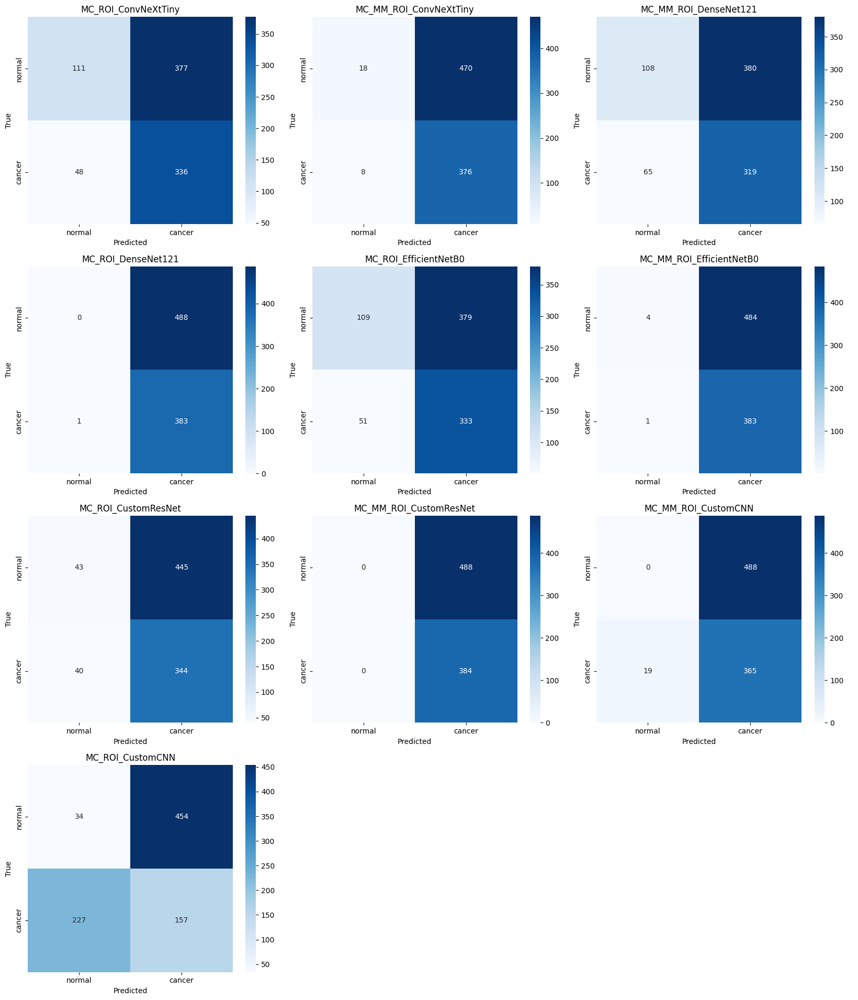

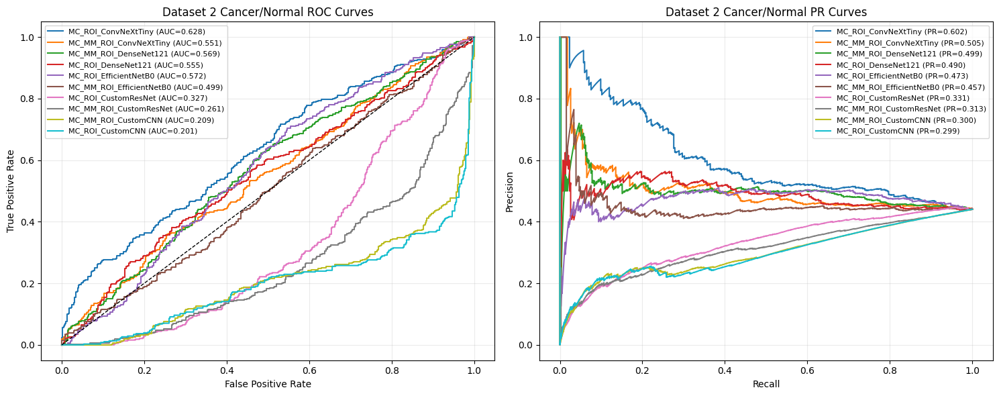

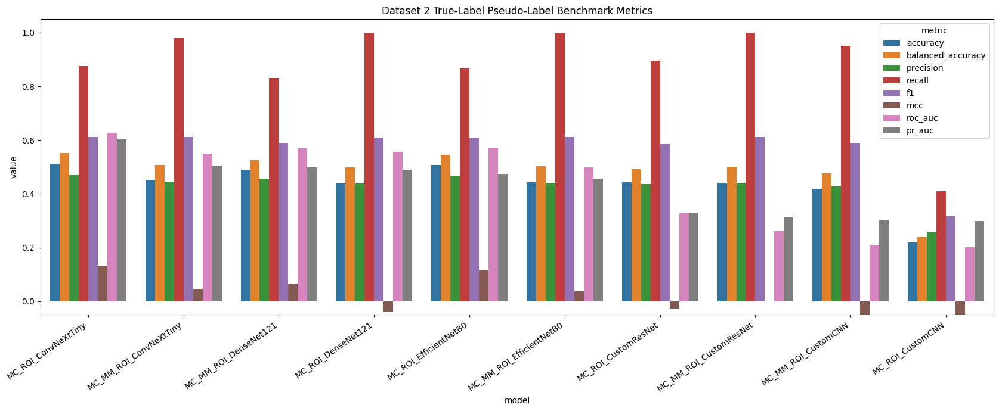

Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/section6_dataset2_pseudolabel_benchmark/dataset2_pseudolabel_model_comparison.csv
Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/section6_dataset2_pseudolabel_benchmark/dataset2_pseudolabel_winner_summary.csv
Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/section6_dataset2_pseudolabel_benchmark/dataset2_pseudolabel_predictions.npz
Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/section6_dataset2_pseudolabel_benchmark/dataset2_pseudolabel_outputs.csv
Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/section6_dataset2_pseudolabel_benchmark/dataset2_winner_label_agreement_counts.csv
Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/section6_dataset2_pseudolabel_benchmark/dataset2_winner_test_confusion_table.csv
Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/section6_dataset2_ps

In [ ]:
# compare Dataset 2 pseudo-labelers

if not section6y_eval_rows:
    raise RuntimeError('No Section 6Y model predictions are available. Run CELL 6Y-2 and/or CELL 6Y-3 first.')

section6y_model_comparison_df = pd.DataFrame(section6y_eval_rows).drop_duplicates(subset=['model'], keep='last')
section6y_model_comparison_df = section6y_model_comparison_df.sort_values(['pr_auc', 'mcc', 'balanced_accuracy'], ascending=False).reset_index(drop=True)
section6y_model_comparison_df.to_csv(SECTION6Y_OUTPUT_DIR / 'dataset2_pseudolabel_model_comparison.csv', index=False)

winner_6y = section6y_model_comparison_df.iloc[0].to_dict()
section6y_winner_name = winner_6y['model']
section6y_winner_cache = section6y_prediction_cache[section6y_winner_name]
section6y_winner_summary_df = pd.DataFrame([winner_6y])
section6y_winner_summary_df.to_csv(SECTION6Y_OUTPUT_DIR / 'dataset2_pseudolabel_winner_summary.csv', index=False)

print('Dataset 2 pseudo-label benchmark ranking:')
display(section6y_model_comparison_df.style.format({
    c: '{:.4f}' for c in section6y_model_comparison_df.select_dtypes(include='number').columns
}))
print('\nWinning pseudo-labeler:', section6y_winner_name)
display(section6y_winner_summary_df)

pseudo_rows = []
for split_name, paths, filenames, y_true, probs in [
    ('train', X2_6y_train_paths, X2_6y_train_filenames, y2_6y_train_true, section6y_winner_cache['train_prob']),
    ('valid', X2_6y_valid_paths, X2_6y_valid_filenames, y2_6y_valid_true, section6y_winner_cache['valid_prob']),
    ('test',  X2_6y_test_paths,  X2_6y_test_filenames,  y2_6y_test_true,  section6y_winner_cache['test_prob']),
]:
    labels = (np.asarray(probs) >= section6y_winner_cache['threshold']).astype(int)
    for rel_path, filename, true_label, prob, pseudo_label in zip(paths, filenames, y_true, probs, labels):
        pseudo_rows.append({
            'split': split_name,
            'filename': filename,
            'rel_path': rel_path,
            'y_true_cancer': int(true_label),
            'pseudo_prob_cancer': float(prob),
            'pseudo_label_cancer': int(pseudo_label),
            'threshold': float(section6y_winner_cache['threshold']),
            'model': section6y_winner_name,
            'model_type': section6y_winner_cache['model_type'],
            'metadata_mode': section6y_winner_cache['metadata_mode'],
        })
section6y_pseudolabel_outputs_df = pd.DataFrame(pseudo_rows)
section6y_pseudolabel_outputs_df.to_csv(SECTION6Y_OUTPUT_DIR / 'dataset2_pseudolabel_outputs.csv', index=False)

LABEL_NAME_6Y = {0: 'normal', 1: 'cancer'}
section6y_pseudolabel_outputs_df['actual_label'] = section6y_pseudolabel_outputs_df['y_true_cancer'].map(LABEL_NAME_6Y)
section6y_pseudolabel_outputs_df['predicted_label'] = section6y_pseudolabel_outputs_df['pseudo_label_cancer'].map(LABEL_NAME_6Y)

section6y_winner_label_agreement_counts_df = (
    section6y_pseudolabel_outputs_df
    .groupby(['split', 'actual_label', 'predicted_label'], observed=False)
    .size()
    .reset_index(name='count')
)
# Fill missing combinations so the display always shows...
_split_order_6y = ['train', 'valid', 'test']
_label_order_6y = ['normal', 'cancer']
_full_index_6y = pd.MultiIndex.from_product(
    [_split_order_6y, _label_order_6y, _label_order_6y],
    names=['split', 'actual_label', 'predicted_label'],
)
section6y_winner_label_agreement_counts_df = (
    section6y_winner_label_agreement_counts_df
    .set_index(['split', 'actual_label', 'predicted_label'])
    .reindex(_full_index_6y, fill_value=0)
    .reset_index()
)
section6y_winner_label_agreement_counts_df.to_csv(
    SECTION6Y_OUTPUT_DIR / 'dataset2_winner_label_agreement_counts.csv',
    index=False,
)

section6y_winner_test_confusion_table_df = pd.crosstab(
    section6y_pseudolabel_outputs_df.loc[section6y_pseudolabel_outputs_df['split'] == 'test', 'actual_label'],
    section6y_pseudolabel_outputs_df.loc[section6y_pseudolabel_outputs_df['split'] == 'test', 'predicted_label'],
).reindex(index=_label_order_6y, columns=_label_order_6y, fill_value=0)
section6y_winner_test_confusion_table_df.index.name = 'actual_label'
section6y_winner_test_confusion_table_df.columns.name = 'predicted_label'
section6y_winner_test_confusion_table_df.to_csv(
    SECTION6Y_OUTPUT_DIR / 'dataset2_winner_test_confusion_table.csv'
)

print('Winning pseudo-labeler details:')
print(f'  model        : {section6y_winner_name}')
print(f'  threshold    : {section6y_winner_cache["threshold"]:.4f}')
print(f'  metadata_mode: {section6y_winner_cache["metadata_mode"]}')
print('Winner label agreement counts by split:')
display(section6y_winner_label_agreement_counts_df)
print('Winner final Dataset 2 test confusion table:')
display(section6y_winner_test_confusion_table_df)

np.savez_compressed(
    SECTION6Y_OUTPUT_DIR / 'dataset2_pseudolabel_predictions.npz',
    y_train_true=y2_6y_train_true,
    y_valid_true=y2_6y_valid_true,
    y_test_true=y2_6y_test_true,
    model_names=np.asarray(list(section6y_prediction_cache.keys()), dtype=object),
    winner=np.asarray([section6y_winner_name], dtype=object),
    **{f'{name}_train_prob': cache['train_prob'] for name, cache in section6y_prediction_cache.items()},
    **{f'{name}_valid_prob': cache['valid_prob'] for name, cache in section6y_prediction_cache.items()},
    **{f'{name}_test_prob': cache['test_prob'] for name, cache in section6y_prediction_cache.items()},
    **{f'{name}_threshold': np.asarray([cache['threshold']], dtype=np.float32) for name, cache in section6y_prediction_cache.items()},
)

n_models = len(section6y_model_comparison_df)
n_cols = 3
n_rows = int(np.ceil(n_models / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5.5 * n_cols, 4.8 * n_rows))
axes = np.asarray(axes).reshape(-1)
for ax, row in zip(axes, section6y_model_comparison_df.itertuples(index=False)):
    cache = section6y_prediction_cache[row.model]
    pred = (cache['test_prob'] >= cache['threshold']).astype(int)
    cm = confusion_matrix(y2_6y_test_true, pred, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['normal', 'cancer'], yticklabels=['normal', 'cancer'], ax=ax)
    ax.set_title(row.model)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
for ax in axes[n_models:]:
    ax.axis('off')
plt.tight_layout()
plt.savefig(SECTION6Y_OUTPUT_DIR / 'dataset2_pseudolabel_confusion_matrices.png', dpi=180, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for row in section6y_model_comparison_df.itertuples(index=False):
    prob = section6y_prediction_cache[row.model]['test_prob']
    if len(np.unique(y2_6y_test_true)) == 2:
        fpr, tpr, _ = roc_curve(y2_6y_test_true, prob)
        precision, recall, _ = precision_recall_curve(y2_6y_test_true, prob)
        axes[0].plot(fpr, tpr, linewidth=1.5, label=f'{row.model} (AUC={row.roc_auc:.3f})')
        axes[1].plot(recall, precision, linewidth=1.5, label=f'{row.model} (PR={row.pr_auc:.3f})')
axes[0].plot([0, 1], [0, 1], 'k--', linewidth=1)
axes[0].set_title('Dataset 2 Cancer/Normal ROC Curves')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[1].set_title('Dataset 2 Cancer/Normal PR Curves')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(SECTION6Y_OUTPUT_DIR / 'dataset2_pseudolabel_roc_pr_curves.png', dpi=180, bbox_inches='tight')
plt.show()

bar_metrics = ['accuracy', 'balanced_accuracy', 'precision', 'recall', 'f1', 'mcc', 'roc_auc', 'pr_auc']
bar_df = section6y_model_comparison_df.melt(id_vars='model', value_vars=bar_metrics, var_name='metric', value_name='value')
plt.figure(figsize=(17, 7))
sns.barplot(data=bar_df, x='model', y='value', hue='metric')
plt.xticks(rotation=35, ha='right')
plt.ylim(-0.05, 1.05)
plt.title('Dataset 2 True-Label Pseudo-Label Benchmark Metrics')
plt.tight_layout()
plt.savefig(SECTION6Y_OUTPUT_DIR / 'dataset2_pseudolabel_metric_bars.png', dpi=180, bbox_inches='tight')
plt.show()

print('Saved:', SECTION6Y_OUTPUT_DIR / 'dataset2_pseudolabel_model_comparison.csv')
print('Saved:', SECTION6Y_OUTPUT_DIR / 'dataset2_pseudolabel_winner_summary.csv')
print('Saved:', SECTION6Y_OUTPUT_DIR / 'dataset2_pseudolabel_predictions.npz')
print('Saved:', SECTION6Y_OUTPUT_DIR / 'dataset2_pseudolabel_outputs.csv')
print('Saved:', SECTION6Y_OUTPUT_DIR / 'dataset2_winner_label_agreement_counts.csv')
print('Saved:', SECTION6Y_OUTPUT_DIR / 'dataset2_winner_test_confusion_table.csv')
print('Saved:', SECTION6Y_OUTPUT_DIR / 'dataset2_pseudolabel_confusion_matrices.png')
print('Saved:', SECTION6Y_OUTPUT_DIR / 'dataset2_pseudolabel_roc_pr_curves.png')
print('Saved:', SECTION6Y_OUTPUT_DIR / 'dataset2_pseudolabel_metric_bars.png')


We compare the multiclass Dataset 2 pseudo-labels against binary pseudo-label sources.


Skipping Legacy ROI EfficientNet labels: missing columns ['label', 'prob']
Dataset 2 label-source metrics:


,source,split,n,predicted_normal,predicted_cancer,actual_normal,actual_cancer,accuracy,balanced_accuracy,precision,recall,specificity,f1,mcc,roc_auc,pr_auc,tn,fp,fn,tp
2,Best multiclass: MC_ROI_ConvNeXtTiny,test,872.0000,159.0000,713.0000,488.0000,384.0000,0.5126,0.5512,0.4712,0.8750,0.2275,0.6126,0.1317,0.6278,0.6019,111.0000,377.0000,48.0000,336.0000
4,Binary ROI EfficientNet teacher,test,872.0000,862.0000,10.0000,488.0000,384.0000,0.5665,0.5084,0.8000,0.0208,0.9959,0.0406,0.0780,0.6201,0.5786,486.0000,2.0000,376.0000,8.0000
6,Binary ROI ConvNeXt teacher,test,872.0000,846.0000,26.0000,488.0000,384.0000,0.5665,0.5106,0.6154,0.0417,0.9795,0.0780,0.0618,0.5901,0.5108,478.0000,10.0000,368.0000,16.0000
3,Binary ROI EfficientNet teacher,train,7057.0000,6937.0000,120.0000,3976.0000,3081.0000,0.5747,0.5137,0.8333,0.0325,0.9950,0.0625,0.1052,0.6348,0.5831,3956.0000,20.0000,2981.0000,100.0000
0,Best multiclass: MC_ROI_ConvNeXtTiny,train,7057.0000,1272.0000,5785.0000,3976.0000,3081.0000,0.5063,0.5476,0.4652,0.8734,0.2218,0.6070,0.1229,0.6119,0.5793,882.0000,3094.0000,390.0000,2691.0000
5,Binary ROI ConvNeXt teacher,train,7057.0000,6833.0000,224.0000,3976.0000,3081.0000,0.5677,0.5084,0.5670,0.0412,0.9756,0.0769,0.0476,0.5761,0.4947,3879.0000,97.0000,2954.0000,127.0000
1,Best multiclass: MC_ROI_ConvNeXtTiny,valid,882.0000,165.0000,717.0000,484.0000,398.0000,0.5363,0.5674,0.4923,0.8869,0.2479,0.6332,0.1721,0.6393,0.6115,120.0000,364.0000,45.0000,353.0000



Best multiclass labels vs binary label agreement:


,binary_source,split,n_matched,multiclass_positive_rate,binary_positive_rate,label_agreement,cohen_kappa,mean_abs_prob_gap
0,Binary ROI EfficientNet teacher,train,7057.0000,0.8198,0.0170,0.1970,0.0072,0.4897
1,Binary ROI EfficientNet teacher,test,872.0000,0.8177,0.0115,0.1938,0.0052,0.4683
2,Binary ROI ConvNeXt teacher,train,7057.0000,0.8198,0.0317,0.2120,0.0143,0.5050
3,Binary ROI ConvNeXt teacher,test,872.0000,0.8177,0.0298,0.2122,0.0136,0.4856



Test split label confusion summary:


,source,actual_normal_pred_normal,actual_normal_pred_cancer,actual_cancer_pred_normal,actual_cancer_pred_cancer
0,Best multiclass: MC_ROI_ConvNeXtTiny,111,377,48,336
1,Binary ROI EfficientNet teacher,486,2,376,8
2,Binary ROI ConvNeXt teacher,478,10,368,16


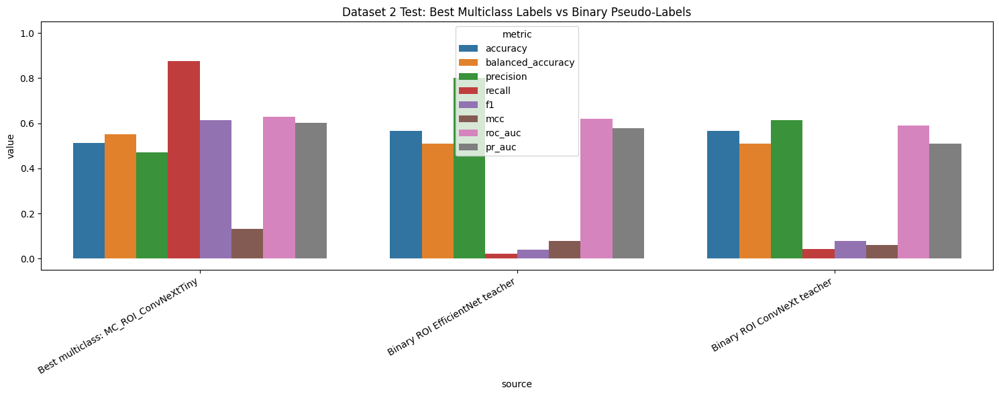

Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/section6_dataset2_pseudolabel_benchmark/dataset2_multiclass_vs_binary_label_metrics.csv
Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/section6_dataset2_pseudolabel_benchmark/dataset2_multiclass_vs_binary_label_agreement.csv
Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/section6_dataset2_pseudolabel_benchmark/dataset2_multiclass_vs_binary_label_predictions.csv
Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/section6_dataset2_pseudolabel_benchmark/dataset2_multiclass_vs_binary_test_confusion_summary.csv
Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/multiclass_outputs/section6_dataset2_pseudolabel_benchmark/dataset2_multiclass_vs_binary_label_metric_bars.png


In [ ]:
# compare pseudo-label sources

SECTION6Y_OUTPUT_DIR = Path(globals().get('SECTION6Y_OUTPUT_DIR', Path(OUTPUT_DIR) / 'multiclass_outputs' / 'section6_dataset2_pseudolabel_benchmark'))
MULTICLASS_WINNER_LABELS_PATH = SECTION6Y_OUTPUT_DIR / 'dataset2_pseudolabel_outputs.csv'
BINARY_LABEL_CANDIDATES_6YB = [
    ('Binary ROI EfficientNet teacher', Path(OUTPUT_DIR) / 'dataset2_x_effnet_pseudo_labels.csv'),
    ('Binary ROI ConvNeXt teacher', Path(OUTPUT_DIR) / 'dataset2_x_convnext_pseudo_labels.csv'),
    ('Legacy ROI EfficientNet labels', Path(OUTPUT_DIR) / 'dataset2_roi_effnet_pseudo_labels.csv'),
]

if not MULTICLASS_WINNER_LABELS_PATH.exists():
    raise FileNotFoundError(f'Missing multiclass winner labels: {MULTICLASS_WINNER_LABELS_PATH}. Run SECTION 6Y first.')

multi_df = pd.read_csv(MULTICLASS_WINNER_LABELS_PATH).copy()
required_multi_cols = {'split', 'rel_path', 'y_true_cancer', 'pseudo_prob_cancer', 'pseudo_label_cancer', 'model'}
missing_multi = sorted(required_multi_cols - set(multi_df.columns))
if missing_multi:
    raise ValueError(f'Multiclass winner label file missing columns: {missing_multi}')

label_source_rows = []
agreement_rows = []
merged_frames = []

def _binary_metric_row_6yb(source_name, split_name, y_true, y_prob, y_pred):
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob).astype(float)
    y_pred = np.asarray(y_pred).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        'source': source_name,
        'split': split_name,
        'n': int(len(y_true)),
        'predicted_normal': int((y_pred == 0).sum()),
        'predicted_cancer': int((y_pred == 1).sum()),
        'actual_normal': int((y_true == 0).sum()),
        'actual_cancer': int((y_true == 1).sum()),
        'accuracy': accuracy_score(y_true, y_pred),
        'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall': recall_score(y_true, y_pred, zero_division=0),
        'specificity': tn / max(tn + fp, 1),
        'f1': f1_score(y_true, y_pred, zero_division=0),
        'mcc': matthews_corrcoef(y_true, y_pred),
        'roc_auc': roc_auc_score(y_true, y_prob) if len(np.unique(y_true)) == 2 else np.nan,
        'pr_auc': average_precision_score(y_true, y_prob) if len(np.unique(y_true)) == 2 else np.nan,
        'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp),
    }

# First record the multiclass winner itself.
for split_name, split_df in multi_df.groupby('split', sort=False):
    label_source_rows.append(_binary_metric_row_6yb(
        f"Best multiclass: {split_df['model'].iloc[0]}",
        split_name,
        split_df['y_true_cancer'],
        split_df['pseudo_prob_cancer'],
        split_df['pseudo_label_cancer'],
    ))

for source_name, path in BINARY_LABEL_CANDIDATES_6YB:
    if not path.exists():
        print(f'Skipping missing binary label source: {path}')
        continue
    bin_df = pd.read_csv(path).copy()
    required_bin_cols = {'split', 'rel_path', 'prob', 'label'}
    missing_bin = sorted(required_bin_cols - set(bin_df.columns))
    if missing_bin:
        print(f'Skipping {source_name}: missing columns {missing_bin}')
        continue
    merged = multi_df.merge(
        bin_df[['split', 'rel_path', 'prob', 'label']].rename(columns={'prob': 'binary_prob', 'label': 'binary_label'}),
        on=['split', 'rel_path'],
        how='inner',
    )
    if merged.empty:
        print(f'Skipping {source_name}: no matching rel_path rows with multiclass winner labels.')
        continue
    merged['binary_source'] = source_name
    merged_frames.append(merged)
    for split_name, split_df in merged.groupby('split', sort=False):
        label_source_rows.append(_binary_metric_row_6yb(
            source_name,
            split_name,
            split_df['y_true_cancer'],
            split_df['binary_prob'],
            split_df['binary_label'],
        ))
        agreement_rows.append({
            'binary_source': source_name,
            'split': split_name,
            'n_matched': int(len(split_df)),
            'multiclass_positive_rate': float(split_df['pseudo_label_cancer'].mean()),
            'binary_positive_rate': float(split_df['binary_label'].mean()),
            'label_agreement': float((split_df['pseudo_label_cancer'] == split_df['binary_label']).mean()),
            'cohen_kappa': float(cohen_kappa_score(split_df['pseudo_label_cancer'], split_df['binary_label'])) if split_df['pseudo_label_cancer'].nunique() > 1 and split_df['binary_label'].nunique() > 1 else np.nan,
            'mean_abs_prob_gap': float(np.mean(np.abs(split_df['pseudo_prob_cancer'] - split_df['binary_prob']))),
        })

section6yb_label_source_metrics_df = pd.DataFrame(label_source_rows).sort_values(['split', 'pr_auc', 'mcc', 'balanced_accuracy'], ascending=[True, False, False, False])
section6yb_label_agreement_df = pd.DataFrame(agreement_rows)
section6yb_label_source_metrics_df.to_csv(SECTION6Y_OUTPUT_DIR / 'dataset2_multiclass_vs_binary_label_metrics.csv', index=False)
section6yb_label_agreement_df.to_csv(SECTION6Y_OUTPUT_DIR / 'dataset2_multiclass_vs_binary_label_agreement.csv', index=False)

if merged_frames:
    section6yb_merged_predictions_df = pd.concat(merged_frames, ignore_index=True)
    section6yb_merged_predictions_df.to_csv(SECTION6Y_OUTPUT_DIR / 'dataset2_multiclass_vs_binary_label_predictions.csv', index=False)
else:
    section6yb_merged_predictions_df = pd.DataFrame()

print('Dataset 2 label-source metrics:')
display(section6yb_label_source_metrics_df.style.format({c: '{:.4f}' for c in section6yb_label_source_metrics_df.select_dtypes(include='number').columns}))
print('\nBest multiclass labels vs binary label agreement:')
display(section6yb_label_agreement_df.style.format({c: '{:.4f}' for c in section6yb_label_agreement_df.select_dtypes(include='number').columns}))

# Test-split confusion tables for quick reading.
conf_rows=[]
for source_name, source_df in section6yb_label_source_metrics_df[section6yb_label_source_metrics_df['split'].eq('test')].groupby('source', sort=False):
    row = source_df.iloc[0]
    conf_rows.append({
        'source': source_name,
        'actual_normal_pred_normal': int(row['tn']),
        'actual_normal_pred_cancer': int(row['fp']),
        'actual_cancer_pred_normal': int(row['fn']),
        'actual_cancer_pred_cancer': int(row['tp']),
    })
section6yb_test_confusion_summary_df = pd.DataFrame(conf_rows)
section6yb_test_confusion_summary_df.to_csv(SECTION6Y_OUTPUT_DIR / 'dataset2_multiclass_vs_binary_test_confusion_summary.csv', index=False)
print('\nTest split label confusion summary:')
display(section6yb_test_confusion_summary_df)

plot_df = section6yb_label_source_metrics_df[section6yb_label_source_metrics_df['split'].eq('test')].copy()
if not plot_df.empty:
    metric_cols = ['accuracy', 'balanced_accuracy', 'precision', 'recall', 'f1', 'mcc', 'roc_auc', 'pr_auc']
    melted = plot_df.melt(id_vars='source', value_vars=metric_cols, var_name='metric', value_name='value')
    plt.figure(figsize=(15, 6))
    sns.barplot(data=melted, x='source', y='value', hue='metric')
    plt.xticks(rotation=30, ha='right')
    plt.ylim(-0.05, 1.05)
    plt.title('Dataset 2 Test: Best Multiclass Labels vs Binary Pseudo-Labels')
    plt.tight_layout()
    plt.savefig(SECTION6Y_OUTPUT_DIR / 'dataset2_multiclass_vs_binary_label_metric_bars.png', dpi=180, bbox_inches='tight')
    plt.show()

print('Saved:', SECTION6Y_OUTPUT_DIR / 'dataset2_multiclass_vs_binary_label_metrics.csv')
print('Saved:', SECTION6Y_OUTPUT_DIR / 'dataset2_multiclass_vs_binary_label_agreement.csv')
print('Saved:', SECTION6Y_OUTPUT_DIR / 'dataset2_multiclass_vs_binary_label_predictions.csv')
print('Saved:', SECTION6Y_OUTPUT_DIR / 'dataset2_multiclass_vs_binary_test_confusion_summary.csv')
print('Saved:', SECTION6Y_OUTPUT_DIR / 'dataset2_multiclass_vs_binary_label_metric_bars.png')


We prepare Dataset 2 arrays to generate fresh pseudo-labels.


In [ ]:
# prepare Dataset 2 arrays

PROJECT_ROOT_X = Path.cwd().resolve()
if PROJECT_ROOT_X.name == 'vlm_pipeline':
    PROJECT_ROOT_X = PROJECT_ROOT_X.parent
DATASET2_DIR_X = PROJECT_ROOT_X / 'GP Dataset 2'
OUTPUT_DIR_X = Path(globals().get('OUTPUT_DIR', PROJECT_ROOT_X / 'outputs'))
OUTPUT_DIR_X.mkdir(parents=True, exist_ok=True)

IMG_SIZE = globals().get('IMG_SIZE', (224, 224))
D2_IMAGE_EXTS_X = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'}
D2_SPLIT_DIRS_X = {'train': 'train', 'valid': 'val', 'val': 'val', 'test': 'test'}

if not DATASET2_DIR_X.exists():
    raise FileNotFoundError(f'Dataset 2 folder not found: {DATASET2_DIR_X}')

def _fallback_preprocess_d2_x(img_path, size=IMG_SIZE):
    try:
        img = PILImage.open(img_path).convert('RGB').resize(size)
        return (np.asarray(img, dtype=np.float32) / 255.0).astype(np.float32)
    except Exception:
        return None

def preprocess_d2_x_image(img_path):
    if 'full_preprocessing_pipeline' in globals():
        img = full_preprocessing_pipeline(str(img_path))
        if img is not None:
            return img.astype(np.float32)
    return _fallback_preprocess_d2_x(img_path)

def _discover_d2_x_paths():
    rows = []
    for folder_name, split_name in D2_SPLIT_DIRS_X.items():
        folder = DATASET2_DIR_X / folder_name
        if not folder.exists():
            continue
        for p in sorted(folder.rglob('*')):
            if p.is_file() and p.suffix.lower() in D2_IMAGE_EXTS_X:
                rows.append({'split': split_name, 'path': p, 'rel_path': str(p.relative_to(DATASET2_DIR_X))})
    if not rows:
        raise RuntimeError(f'No Dataset 2 images found under: {DATASET2_DIR_X}')
    return rows

def _pack_d2_x_split(rows, split_name):
    imgs, paths = [], []
    skipped = []
    split_rows = [r for r in rows if r['split'] == split_name]
    for row in tqdm(split_rows, desc=f'Preprocess D2 {split_name}'):
        img = preprocess_d2_x_image(row['path'])
        if img is None:
            skipped.append(row['rel_path'])
            continue
        imgs.append(img.astype(np.float32))
        paths.append(row['rel_path'])
    X = np.asarray(imgs, dtype=np.float32) if imgs else np.empty((0, IMG_SIZE[0], IMG_SIZE[1], 3), dtype=np.float32)
    return X, paths, skipped

D2_X_DISCOVERED_ROWS = _discover_d2_x_paths()
X2_x_train, X2_x_train_paths, d2_x_skip_train = _pack_d2_x_split(D2_X_DISCOVERED_ROWS, 'train')
X2_x_val,   X2_x_val_paths,   d2_x_skip_val   = _pack_d2_x_split(D2_X_DISCOVERED_ROWS, 'val')
X2_x_test,  X2_x_test_paths,  d2_x_skip_test  = _pack_d2_x_split(D2_X_DISCOVERED_ROWS, 'test')

# Zero tabular placeholders are kept only for compatibility with helper patterns.
TABULAR_DIM_X = int(globals().get('TABULAR_DIM', X_tab_train.shape[1] if 'X_tab_train' in globals() else 8))
X2_x_tab_train = np.zeros((len(X2_x_train), TABULAR_DIM_X), dtype=np.float32)
X2_x_tab_val = np.zeros((len(X2_x_val), TABULAR_DIM_X), dtype=np.float32)
X2_x_tab_test = np.zeros((len(X2_x_test), TABULAR_DIM_X), dtype=np.float32)

manifest_rows = []
for split_name, paths in [('train', X2_x_train_paths), ('val', X2_x_val_paths), ('test', X2_x_test_paths)]:
    manifest_rows.extend({'split': split_name, 'rel_path': p} for p in paths)
dataset2_x_manifest_df = pd.DataFrame(manifest_rows)
dataset2_x_manifest_df.to_csv(OUTPUT_DIR_X / 'dataset2_x_image_manifest.csv', index=False)

print('\n' + '=' * 64)
print('VLM-FREE DATASET 2 IMAGE ARRAYS')
print('=' * 64)
for split_name, X_arr, paths, skipped in [
    ('train', X2_x_train, X2_x_train_paths, d2_x_skip_train),
    ('val', X2_x_val, X2_x_val_paths, d2_x_skip_val),
    ('test', X2_x_test, X2_x_test_paths, d2_x_skip_test),
]:
    print(f'{split_name:<5}: X={X_arr.shape}, paths={len(paths)}, skipped={len(skipped)}')
print(f'Saved: {OUTPUT_DIR_X / "dataset2_x_image_manifest.csv"}')
print('=' * 64)


Preprocess D2 test: 100%|██████████| 872/872 [00:02<00:00, 297.95it/s]



VLM-FREE DATASET 2 IMAGE ARRAYS
train: X=(7057, 224, 224, 3), paths=7057, skipped=0
val  : X=(882, 224, 224, 3), paths=882, skipped=0
test : X=(872, 224, 224, 3), paths=872, skipped=0
Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/dataset2_x_image_manifest.csv


We generate fresh pseudo-labels for Dataset 2 using EfficientNet and ConvNeXt checkpoints.


In [ ]:
# generate pseudo-labels


required_6x = [
    'X_roi_val', 'y_val_osteo',
    'X2_x_train', 'X2_x_val', 'X2_x_test',
    'X2_x_train_paths', 'X2_x_val_paths', 'X2_x_test_paths',
    'best_checkpoint_path', 'predict_model',
]
missing_6x = [name for name in required_6x if name not in globals()]
if missing_6x:
    raise NameError(f'Section 6X missing required objects: {missing_6x}')

CONTRIB_DEVICE_X = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
CONTRIB_MODEL_NAME_X = globals().get('CONTRIB_MODEL_NAME', 'convnext_tiny')
CONTRIB_BATCH_SIZE_X = int(globals().get('CONTRIB_BATCH_SIZE', 16))
CONVNEXT_MEAN_X = torch.tensor([0.485, 0.456, 0.406], dtype=torch.float32).view(3, 1, 1)
CONVNEXT_STD_X = torch.tensor([0.229, 0.224, 0.225], dtype=torch.float32).view(3, 1, 1)

class _XConvNeXtImageDataset(torch.utils.data.Dataset):
    def __init__(self, X, y=None):
        self.X = np.asarray(X)
        self.y = np.zeros(len(self.X), dtype=np.float32) if y is None else np.asarray(y).astype(np.float32)
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        img = torch.from_numpy(self.X[idx].astype(np.float32)).permute(2, 0, 1)
        img = (img - CONVNEXT_MEAN_X) / CONVNEXT_STD_X
        return img, torch.tensor(self.y[idx], dtype=torch.float32)

class _XTimmConvNeXtBinary(nn.Module):
    def __init__(self, model_name=CONTRIB_MODEL_NAME_X, pretrained=False, dropout=0.45):
        super().__init__()
        self.backbone = timm.create_model(model_name, pretrained=pretrained, num_classes=0, global_pool='avg')
        feat_dim = int(getattr(self.backbone, 'num_features'))
        self.head = nn.Sequential(
            nn.Dropout(dropout), nn.Linear(feat_dim, 256), nn.GELU(), nn.Dropout(dropout), nn.Linear(256, 1)
        )
    def extract_features(self, x):
        feats = self.backbone(x)
        if feats.ndim > 2:
            feats = feats.mean(dim=tuple(range(2, feats.ndim)))
        return feats
    def forward(self, x):
        return self.head(self.extract_features(x)).squeeze(1)

def _x_contrib_checkpoint_path(name):
    if 'contrib_checkpoint_path' in globals():
        return contrib_checkpoint_path(name)
    return os.path.join(OUTPUT_DIR_X, f'best_{name}.pt')

def _x_load_eff_teacher():
    ckpt = Path(best_checkpoint_path('ROI_EfficientNetB0_P2'))
    if not ckpt.exists():
        raise FileNotFoundError(f'Missing EfficientNet teacher checkpoint: {ckpt}')
    load_kwargs = _best_model_load_kwargs() if '_best_model_load_kwargs' in globals() else {}
    load_kwargs = dict(load_kwargs)
    load_kwargs['compile'] = False
    return run_tf_work(
        lambda: tf.keras.models.load_model(ckpt, **load_kwargs),
        description='load fresh 6X EfficientNet teacher',
        fallback_to_cpu=False,
    )

def _x_load_convnext_teacher():
    ckpt_path = _x_contrib_checkpoint_path('CONTRIB_ConvNeXtTiny_ROI')
    if not os.path.exists(ckpt_path):
        raise FileNotFoundError(f'Missing ConvNeXt teacher checkpoint: {ckpt_path}')
    model_cls = globals().get('TimmConvNeXtBinary', _XTimmConvNeXtBinary)
    model = model_cls(model_name=CONTRIB_MODEL_NAME_X, pretrained=False, dropout=0.45).to(CONTRIB_DEVICE_X)
    ckpt = torch.load(ckpt_path, map_location=CONTRIB_DEVICE_X)
    model.load_state_dict(ckpt['model_state_dict'])
    return model.eval()

def _x_predict_eff(model, X, description, batch_size=8):
    probs = []
    for start in tqdm(range(0, len(X), batch_size), desc=description):
        batch = X[start:start + batch_size].astype(np.float32, copy=False)
        prob = predict_model(model, batch, batch_size=len(batch), verbose=0, description=f'{description} {start}:{start+len(batch)}').ravel()
        probs.append(prob.astype(np.float32))
    return np.concatenate(probs) if probs else np.empty((0,), dtype=np.float32)

@torch.no_grad()
def _x_predict_convnext(model, X, description):
    loader = DataLoader(_XConvNeXtImageDataset(X), batch_size=CONTRIB_BATCH_SIZE_X, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available())
    probs = []
    for xb, _ in tqdm(loader, desc=description):
        xb = xb.to(CONTRIB_DEVICE_X).float()
        probs.append(torch.sigmoid(model(xb)).detach().cpu().numpy())
    return np.concatenate(probs).astype(np.float32) if probs else np.empty((0,), dtype=np.float32)

def _x_threshold_from_val(y_true, y_prob):
    fpr, tpr, thr = roc_curve(y_true, y_prob)
    return float(np.clip(thr[np.argmax(tpr - fpr)], 0.05, 0.95))

print('Loading fresh 6X teachers...')
x_eff_teacher = _x_load_eff_teacher()
x_convnext_teacher = _x_load_convnext_teacher()

x_eff_val_prob = _x_predict_eff(x_eff_teacher, X_roi_val, '6X EfficientNet D1 ROI-val threshold')
x_eff_threshold = _x_threshold_from_val(y_val_osteo, x_eff_val_prob)
print(f'Fresh EfficientNet teacher threshold from D1 ROI validation: {x_eff_threshold:.4f}')

x_conv_val_prob = _x_predict_convnext(x_convnext_teacher, X_roi_val, '6X ConvNeXt D1 ROI-val threshold')
x_convnext_threshold = _x_threshold_from_val(y_val_osteo, x_conv_val_prob)
print(f'Fresh ConvNeXt teacher threshold from D1 ROI validation: {x_convnext_threshold:.4f}')

x_eff_train_prob = _x_predict_eff(x_eff_teacher, X2_x_train, '6X EfficientNet D2 train')
x_eff_val_d2_prob = _x_predict_eff(x_eff_teacher, X2_x_val, '6X EfficientNet D2 val')
x_eff_test_prob = _x_predict_eff(x_eff_teacher, X2_x_test, '6X EfficientNet D2 test')

y2_x_eff_train = (x_eff_train_prob >= x_eff_threshold).astype(np.int32)
y2_x_eff_val = (x_eff_val_d2_prob >= x_eff_threshold).astype(np.int32)
y2_x_eff_test = (x_eff_test_prob >= x_eff_threshold).astype(np.int32)

x_conv_train_prob = _x_predict_convnext(x_convnext_teacher, X2_x_train, '6X ConvNeXt D2 train')
x_conv_val_d2_prob = _x_predict_convnext(x_convnext_teacher, X2_x_val, '6X ConvNeXt D2 val')
x_conv_test_prob = _x_predict_convnext(x_convnext_teacher, X2_x_test, '6X ConvNeXt D2 test')

y2_x_convnext_train = (x_conv_train_prob >= x_convnext_threshold).astype(np.int32)
y2_x_convnext_val = (x_conv_val_d2_prob >= x_convnext_threshold).astype(np.int32)
y2_x_convnext_test = (x_conv_test_prob >= x_convnext_threshold).astype(np.int32)

def _x_save_label_file(prefix, probs_by_split, labels_by_split, paths_by_split, threshold):
    rows = []
    data_json = {}
    for split_name in ['train', 'val', 'test']:
        probs = probs_by_split[split_name]
        labels = labels_by_split[split_name]
        paths = paths_by_split[split_name]
        for rel_path, prob, label in zip(paths, probs, labels):
            row = {'split': split_name, 'rel_path': rel_path, 'prob': float(prob), 'label': int(label), 'threshold': float(threshold)}
            rows.append(row)
            data_json[rel_path] = row
    df_out = pd.DataFrame(rows)
    csv_path = OUTPUT_DIR_X / f'{prefix}.csv'
    json_path = OUTPUT_DIR_X / f'{prefix}.json'
    df_out.to_csv(csv_path, index=False)
    with open(json_path, 'w', encoding='utf-8') as f:
        json.dump(data_json, f, indent=2)
    print(f'Saved: {csv_path}')
    print(f'Saved: {json_path}')
    return df_out

dataset2_x_effnet_labels_df = _x_save_label_file(
    'dataset2_x_effnet_pseudo_labels',
    {'train': x_eff_train_prob, 'val': x_eff_val_d2_prob, 'test': x_eff_test_prob},
    {'train': y2_x_eff_train, 'val': y2_x_eff_val, 'test': y2_x_eff_test},
    {'train': X2_x_train_paths, 'val': X2_x_val_paths, 'test': X2_x_test_paths},
    x_eff_threshold,
)
dataset2_x_convnext_labels_df = _x_save_label_file(
    'dataset2_x_convnext_pseudo_labels',
    {'train': x_conv_train_prob, 'val': x_conv_val_d2_prob, 'test': x_conv_test_prob},
    {'train': y2_x_convnext_train, 'val': y2_x_convnext_val, 'test': y2_x_convnext_test},
    {'train': X2_x_train_paths, 'val': X2_x_val_paths, 'test': X2_x_test_paths},
    x_convnext_threshold,
)

agreement_rows = []
for split_name, y_eff, y_conv, p_eff, p_conv in [
    ('train', y2_x_eff_train, y2_x_convnext_train, x_eff_train_prob, x_conv_train_prob),
    ('val', y2_x_eff_val, y2_x_convnext_val, x_eff_val_d2_prob, x_conv_val_d2_prob),
    ('test', y2_x_eff_test, y2_x_convnext_test, x_eff_test_prob, x_conv_test_prob),
]:
    agreement_rows.append({
        'split': split_name,
        'n': int(len(y_eff)),
        'eff_positive_rate': float(np.mean(y_eff)) if len(y_eff) else np.nan,
        'convnext_positive_rate': float(np.mean(y_conv)) if len(y_conv) else np.nan,
        'agreement': float(np.mean(y_eff == y_conv)) if len(y_eff) else np.nan,
        'cohen_kappa': float(cohen_kappa_score(y_eff, y_conv)) if len(np.unique(y_eff)) > 1 and len(np.unique(y_conv)) > 1 else np.nan,
        'mean_abs_prob_gap': float(np.mean(np.abs(p_eff - p_conv))) if len(p_eff) else np.nan,
    })
dataset2_x_label_agreement_df = pd.DataFrame(agreement_rows)
dataset2_x_label_agreement_df.to_csv(OUTPUT_DIR_X / 'dataset2_x_effnet_vs_convnext_label_agreement.csv', index=False)
print(f"Saved: {OUTPUT_DIR_X / 'dataset2_x_effnet_vs_convnext_label_agreement.csv'}")
display(dataset2_x_label_agreement_df)

del x_eff_teacher, x_convnext_teacher
tf.keras.backend.clear_session()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
gc.collect()


Loading fresh 6X teachers...


6X EfficientNet D1 ROI-val threshold:   0%|          | 0/78 [00:00<?, ?it/s]2026-05-30 03:41:01.375619: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2048', 12 bytes spill stores, 12 bytes spill loads

2026-05-30 03:41:01.540584: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2048_0', 176 bytes spill stores, 524 bytes spill loads

2026-05-30 03:41:01.566143: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2048', 104 bytes spill stores, 104 bytes spill loads

2026-05-30 03:41:01.870506: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2048', 502

Fresh EfficientNet teacher threshold from D1 ROI validation: 0.5981


6X ConvNeXt D1 ROI-val threshold: 100%|██████████| 39/39 [00:01<00:00, 21.84it/s]


Fresh ConvNeXt teacher threshold from D1 ROI validation: 0.0500


6X ConvNeXt D2 test: 100%|██████████| 55/55 [00:02<00:00, 22.60it/s]


Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/dataset2_x_effnet_pseudo_labels.csv
Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/dataset2_x_effnet_pseudo_labels.json
Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/dataset2_x_convnext_pseudo_labels.csv
Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/dataset2_x_convnext_pseudo_labels.json
Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/dataset2_x_effnet_vs_convnext_label_agreement.csv


,split,n,eff_positive_rate,convnext_positive_rate,agreement,cohen_kappa,mean_abs_prob_gap
0,train,7057,0.017004,0.031742,0.963724,0.238961,0.051466
1,val,882,0.032880,0.044218,0.959184,0.449839,0.059543
2,test,872,0.011468,0.029817,0.967890,0.209122,0.051621


0

# SECTION 5 - Final Model (Dataset 3X) Training & Evaluation
Training models using pseudo-labeled Dataset 2 features combined with Dataset 1 (Dataset 3X).


We train a ConvNeXt model on the fresh pseudo-labels generated by the EfficientNet teacher.


D2_X_EffLabel_ConvNeXtTiny epoch 01/30 loss=5.9441 val_pr_auc=0.3545 val_auc=0.9252
  Saved best checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_D2_X_EffLabel_ConvNeXtTiny.pt
D2_X_EffLabel_ConvNeXtTiny epoch 02/30 loss=4.9363 val_pr_auc=0.5370 val_auc=0.9637
  Saved best checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_D2_X_EffLabel_ConvNeXtTiny.pt
D2_X_EffLabel_ConvNeXtTiny epoch 03/30 loss=3.6665 val_pr_auc=0.6252 val_auc=0.9664
  Saved best checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_D2_X_EffLabel_ConvNeXtTiny.pt
D2_X_EffLabel_ConvNeXtTiny epoch 04/30 loss=2.8244 val_pr_auc=0.6546 val_auc=0.9721
  Saved best checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_D2_X_EffLabel_ConvNeXtTiny.pt
D2_X_EffLabel_ConvNeXtTiny epoch 05/30 loss=1.8305 val_pr_auc=0.6604 val_auc=0.9602
  Saved best checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_D2_X_EffLabel_ConvNeXtTiny.pt
D2_X_EffLabel_ConvNeXtTiny epoch 06/30 loss=1.6824

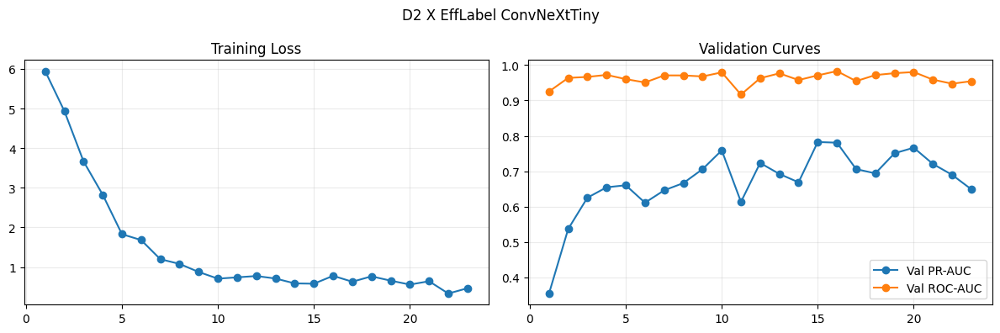

D2_X_EffLabel_ConvNeXtTiny training complete.


In [ ]:
# train ConvNeXt on pseudo-labels
required_6ax_conv = ['X2_x_train', 'X2_x_val', 'X2_x_test', 'y2_x_eff_train', 'y2_x_eff_val', 'y2_x_eff_test']
missing_6ax_conv = [name for name in required_6ax_conv if name not in globals()]
if missing_6ax_conv:
    raise NameError(f'Run SECTION 6X first. Missing: {missing_6ax_conv}')
if len(np.unique(y2_x_eff_train)) < 2:
    raise RuntimeError('Fresh EfficientNet Dataset 2 train labels need both classes for ConvNeXt training.')

D2_X_CONVNEXT_EPOCHS = int(globals().get('CONTRIB_EPOCHS', 30))
D2_X_CONVNEXT_PATIENCE = int(globals().get('CONTRIB_PATIENCE', 8))
D2_X_CONVNEXT_BATCH = int(globals().get('CONTRIB_BATCH_SIZE', 16))

def _x_make_convnext_loaders(X_train_arr, y_train_arr, X_val_arr, y_val_arr, X_test_arr, y_test_arr):
    train_ds = ConvNeXtImageDataset(X_train_arr, y_train_arr, augment=True, seed=842) if 'ConvNeXtImageDataset' in globals() else _XConvNeXtImageDataset(X_train_arr, y_train_arr)
    val_ds = ConvNeXtImageDataset(X_val_arr, y_val_arr, augment=False) if 'ConvNeXtImageDataset' in globals() else _XConvNeXtImageDataset(X_val_arr, y_val_arr)
    test_ds = ConvNeXtImageDataset(X_test_arr, y_test_arr, augment=False) if 'ConvNeXtImageDataset' in globals() else _XConvNeXtImageDataset(X_test_arr, y_test_arr)
    return (
        DataLoader(train_ds, batch_size=D2_X_CONVNEXT_BATCH, shuffle=True, num_workers=0, pin_memory=torch.cuda.is_available()),
        DataLoader(val_ds, batch_size=D2_X_CONVNEXT_BATCH, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available()),
        DataLoader(test_ds, batch_size=D2_X_CONVNEXT_BATCH, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available()),
    )

def _x_pos_weight(y):
    y = np.asarray(y).astype(int)
    n_pos = max(int((y == 1).sum()), 1)
    n_neg = max(int((y == 0).sum()), 1)
    return torch.tensor([n_neg / n_pos], dtype=torch.float32, device=CONTRIB_DEVICE_X)

def _x_train_convnext_binary(model, train_loader, val_loader, checkpoint_name, y_train_for_weight, epochs=D2_X_CONVNEXT_EPOCHS, patience=D2_X_CONVNEXT_PATIENCE):
    model = model.to(CONTRIB_DEVICE_X)
    backbone_params, head_params = [], []
    for name, param in model.named_parameters():
        if not param.requires_grad:
            continue
        (backbone_params if name.startswith('backbone.') else head_params).append(param)
    groups = []
    if backbone_params:
        groups.append({'params': backbone_params, 'lr': float(globals().get('CONTRIB_BACKBONE_LR', 2e-5))})
    if head_params:
        groups.append({'params': head_params, 'lr': float(globals().get('CONTRIB_HEAD_LR', 1e-4))})
    optimizer = torch.optim.AdamW(groups, weight_decay=float(globals().get('CONTRIB_WEIGHT_DECAY', 1e-4)))
    criterion = nn.BCEWithLogitsLoss(pos_weight=_x_pos_weight(y_train_for_weight))
    ckpt_path = _x_contrib_checkpoint_path(checkpoint_name)
    best_pr_auc, best_epoch = -np.inf, 0
    history = []
    for epoch in range(1, epochs + 1):
        model.train()
        losses = []
        for xb, yb in train_loader:
            xb = xb.to(CONTRIB_DEVICE_X).float()
            yb = yb.to(CONTRIB_DEVICE_X).float()
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            losses.append(float(loss.detach().cpu()))
        y_val_true, y_val_prob = _x_predict_loader_convnext(model, val_loader)
        val_pr_auc = average_precision_score(y_val_true, y_val_prob) if len(np.unique(y_val_true)) == 2 else np.nan
        val_auc = roc_auc_score(y_val_true, y_val_prob) if len(np.unique(y_val_true)) == 2 else np.nan
        row = {'epoch': epoch, 'loss': float(np.mean(losses)), 'val_pr_auc': float(val_pr_auc), 'val_auc': float(val_auc)}
        history.append(row)
        print(f'{checkpoint_name} epoch {epoch:02d}/{epochs} loss={row["loss"]:.4f} val_pr_auc={row["val_pr_auc"]:.4f} val_auc={row["val_auc"]:.4f}')
        if np.isfinite(val_pr_auc) and val_pr_auc > best_pr_auc:
            best_pr_auc, best_epoch = float(val_pr_auc), epoch
            torch.save({'model_state_dict': model.state_dict(), 'checkpoint_name': checkpoint_name, 'epoch': epoch, 'val_pr_auc': best_pr_auc}, ckpt_path)
            print(f'  Saved best checkpoint: {ckpt_path}')
        if epoch - best_epoch >= patience:
            print(f'Early stopping {checkpoint_name}; best epoch={best_epoch}.')
            break
    best = torch.load(ckpt_path, map_location=CONTRIB_DEVICE_X)
    model.load_state_dict(best['model_state_dict'])
    return model, pd.DataFrame(history)

@torch.no_grad()
def _x_predict_loader_convnext(model, loader):
    model.eval()
    probs, labels = [], []
    for xb, yb in loader:
        xb = xb.to(CONTRIB_DEVICE_X).float()
        probs.append(torch.sigmoid(model(xb)).detach().cpu().numpy())
        labels.append(yb.detach().cpu().numpy())
    return np.concatenate(labels).astype(int), np.concatenate(probs).astype(float)

d2_x_efflabel_train_loader, d2_x_efflabel_val_loader, d2_x_efflabel_test_loader = _x_make_convnext_loaders(
    X2_x_train, y2_x_eff_train, X2_x_val, y2_x_eff_val, X2_x_test, y2_x_eff_test,
)
convnext_cls = globals().get('TimmConvNeXtBinary', _XTimmConvNeXtBinary)
d2_x_efflabel_convnext_model = convnext_cls(model_name=CONTRIB_MODEL_NAME_X, pretrained=True, dropout=0.45)
d2_x_efflabel_convnext_model, hist_d2_x_efflabel_convnext = _x_train_convnext_binary(
    d2_x_efflabel_convnext_model,
    d2_x_efflabel_train_loader,
    d2_x_efflabel_val_loader,
    'D2_X_EffLabel_ConvNeXtTiny',
    y2_x_eff_train,
)
if 'plot_torch_history' in globals():
    plot_torch_history(hist_d2_x_efflabel_convnext, 'D2 X EffLabel ConvNeXtTiny')
print('D2_X_EffLabel_ConvNeXtTiny training complete.')


We train an EfficientNetB0 model on the fresh pseudo-labels generated by the ConvNeXt teacher.


D2 ConvNeXt labels train: neg=6833, pos=224
D2_X EfficientNet steps per epoch: raw=427, capped=220
  Balanced generator: class 1=224 (minority), class 0=6833
  Each batch: 16 minority + 16 majority = 32
Epoch 1/40


2026-05-30 04:22:15.391941: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_11329', 32 bytes spill stores, 32 bytes spill loads

2026-05-30 04:22:15.520390: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_10352', 204 bytes spill stores, 204 bytes spill loads

2026-05-30 04:22:15.658150: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_11329', 20 bytes spill stores, 20 bytes spill loads

2026-05-30 04:22:15.673235: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_10352_0', 464 bytes spill stores, 1372 bytes spill loads

2026-05-30 04:22:15.899935: I

220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 164ms/step - accuracy: 0.6452 - auc: 0.7193 - loss: 0.6915 - pr_auc: 0.6954 - precision: 0.6028 - recall: 0.8600

2026-05-30 04:23:03.784355: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2142', 232 bytes spill stores, 232 bytes spill loads

2026-05-30 04:23:03.893042: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2142_0', 404 bytes spill stores, 1284 bytes spill loads

2026-05-30 04:23:04.122869: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2142', 5524 bytes spill stores, 5564 bytes spill loads

2026-05-30 04:23:04.226456: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2142', 5380 bytes spill stores, 5380 bytes spill loads




Epoch 1: val_pr_auc improved from None to 0.48637, saving model to /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_D2_X_ConvLabel_EfficientNetB0_P1.keras
220/220 ━━━━━━━━━━━━━━━━━━━━ 59s 211ms/step - accuracy: 0.7109 - auc: 0.8048 - loss: 0.5940 - pr_auc: 0.7868 - precision: 0.6577 - recall: 0.8798 - val_accuracy: 0.7517 - val_auc: 0.9000 - val_loss: 0.4932 - val_pr_auc: 0.4864 - val_precision: 0.1371 - val_recall: 0.8718 - learning_rate: 5.0000e-05
Epoch 2/40
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step - accuracy: 0.8080 - auc: 0.8991 - loss: 0.4417 - pr_auc: 0.8883 - precision: 0.7588 - recall: 0.9032
Epoch 2: val_pr_auc improved from 0.48637 to 0.58918, saving model to /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_D2_X_ConvLabel_EfficientNetB0_P1.keras
220/220 ━━━━━━━━━━━━━━━━━━━━ 32s 145ms/step - accuracy: 0.8188 - auc: 0.9067 - loss: 0.4234 - pr_auc: 0.8963 - precision: 0.7725 - recall: 0.9037 - val_accuracy: 0.7766 - val_auc: 0.9314 - val_loss: 0.4380 - val_pr_auc: 0.5892

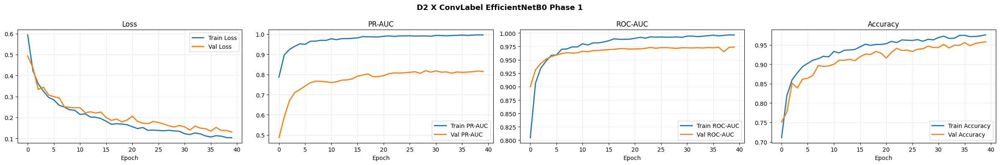

  Balanced generator: class 1=224 (minority), class 0=6833
  Each batch: 16 minority + 16 majority = 32
Epoch 1/40
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 179ms/step - accuracy: 0.8942 - auc: 0.9629 - loss: 0.2757 - pr_auc: 0.9553 - precision: 0.9103 - recall: 0.8746
Epoch 1: val_pr_auc improved from None to 0.75789, saving model to /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_D2_X_ConvLabel_EfficientNetB0_P2.keras
220/220 ━━━━━━━━━━━━━━━━━━━━ 56s 208ms/step - accuracy: 0.9085 - auc: 0.9695 - loss: 0.2473 - pr_auc: 0.9636 - precision: 0.9130 - recall: 0.9031 - val_accuracy: 0.9388 - val_auc: 0.9688 - val_loss: 0.1694 - val_pr_auc: 0.7579 - val_precision: 0.4051 - val_recall: 0.8205 - learning_rate: 1.0000e-05
Epoch 2/40
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step - accuracy: 0.9346 - auc: 0.9807 - loss: 0.1988 - pr_auc: 0.9764 - precision: 0.9255 - recall: 0.9455
Epoch 2: val_pr_auc did not improve from 0.75789
220/220 ━━━━━━━━━━━━━━━━━━━━ 39s 179ms/step - accuracy: 0.9364 - auc: 0.9821 -

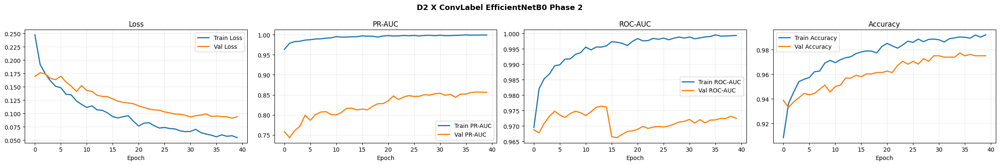

 Reloaded best checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_D2_X_ConvLabel_EfficientNetB0_P2.keras
D2_X_ConvLabel_EfficientNetB0 training complete.


In [ ]:
# train EfficientNet on pseudo-labels
required_6ax_eff = ['X2_x_train', 'X2_x_val', 'X2_x_test', 'y2_x_convnext_train', 'y2_x_convnext_val', 'y2_x_convnext_test']
missing_6ax_eff = [name for name in required_6ax_eff if name not in globals()]
if missing_6ax_eff:
    raise NameError(f'Run SECTION 6X first. Missing: {missing_6ax_eff}')
if len(np.unique(y2_x_convnext_train)) < 2:
    raise RuntimeError('Fresh ConvNeXt Dataset 2 train labels need both classes for EfficientNet training.')

n_pos_d2_x_conv = int((y2_x_convnext_train == 1).sum())
n_neg_d2_x_conv = int((y2_x_convnext_train == 0).sum())
RAW_STEPS_D2_X_EFF = max(n_neg_d2_x_conv // max(BATCH_SIZE // 2, 1), 10)
D2_X_EFF_MAX_STEPS_PER_EPOCH = 220
STEPS_D2_X_EFF = min(RAW_STEPS_D2_X_EFF, D2_X_EFF_MAX_STEPS_PER_EPOCH)
print(f'D2 ConvNeXt labels train: neg={n_neg_d2_x_conv}, pos={n_pos_d2_x_conv}')
print(f'D2_X EfficientNet steps per epoch: raw={RAW_STEPS_D2_X_EFF}, capped={STEPS_D2_X_EFF}')

gen_d2_x_convlabel_eff = balanced_batch_generator(
    X2_x_train, y2_x_convnext_train, aug_gen,
    batch_size=BATCH_SIZE, seed=902,
)
d2_x_convlabel_eff_model, d2_x_convlabel_eff_base = build_efficientnet_transfer()
d2_x_convlabel_eff_model = compile_transfer_head(d2_x_convlabel_eff_model, lr=5e-5)

hist_d2_x_convlabel_eff_p1 = fit_model(
    d2_x_convlabel_eff_model,
    gen_d2_x_convlabel_eff,
    steps_per_epoch=STEPS_D2_X_EFF,
    epochs=40,
    validation_data=(X2_x_val, y2_x_convnext_val),
    callbacks=get_callbacks('D2_X_ConvLabel_EfficientNetB0_P1', patience=12, lr_patience=5),
    verbose=1,
    description='D2_X ConvLabel EfficientNetB0 phase 1',
)
plot_history(hist_d2_x_convlabel_eff_p1, 'D2 X ConvLabel EfficientNetB0 Phase 1')

for layer in d2_x_convlabel_eff_base.layers[:-20]:
    layer.trainable = False
for layer in d2_x_convlabel_eff_base.layers[-20:]:
    layer.trainable = True
d2_x_convlabel_eff_model = compile_transfer_head(d2_x_convlabel_eff_model, lr=1e-5)

gen_d2_x_convlabel_eff_p2 = balanced_batch_generator(
    X2_x_train, y2_x_convnext_train, aug_gen,
    batch_size=BATCH_SIZE, seed=903,
)
hist_d2_x_convlabel_eff_p2 = fit_model(
    d2_x_convlabel_eff_model,
    gen_d2_x_convlabel_eff_p2,
    steps_per_epoch=STEPS_D2_X_EFF,
    epochs=40,
    validation_data=(X2_x_val, y2_x_convnext_val),
    callbacks=get_callbacks('D2_X_ConvLabel_EfficientNetB0_P2', patience=12, lr_patience=5),
    verbose=1,
    description='D2_X ConvLabel EfficientNetB0 phase 2',
)
plot_history(hist_d2_x_convlabel_eff_p2, 'D2 X ConvLabel EfficientNetB0 Phase 2')
d2_x_convlabel_eff_model = restore_best_trained_model(d2_x_convlabel_eff_model, 'D2_X_ConvLabel_EfficientNetB0_P2')
print('D2_X_ConvLabel_EfficientNetB0 training complete.')


We perform cross-teacher evaluations and validate transfer performance back to Dataset 1.


In [ ]:
# evaluate cross-teacher transfer

def _x_metric_row(y_true, y_prob, model_name, threshold):
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob).astype(float)
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        'model': model_name,
        'accuracy': accuracy_score(y_true, y_pred),
        'balanced_acc': balanced_accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall': recall_score(y_true, y_pred, zero_division=0),
        'specificity': tn / max(tn + fp, 1),
        'f1': f1_score(y_true, y_pred, zero_division=0),
        'macro_f1': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'mcc': matthews_corrcoef(y_true, y_pred),
        'auc': roc_auc_score(y_true, y_prob) if len(np.unique(y_true)) == 2 else np.nan,
        'pr_auc': average_precision_score(y_true, y_prob) if len(np.unique(y_true)) == 2 else np.nan,
        'npv': tn / max(tn + fn, 1),
        'threshold': float(threshold),
    }

def _x_threshold(y_true, y_prob):
    fpr, tpr, thr = roc_curve(y_true, y_prob)
    return float(np.clip(thr[np.argmax(tpr - fpr)], 0.05, 0.95))

def _x_load_convnext_model(checkpoint_name):
    model_cls = globals().get('TimmConvNeXtBinary', _XTimmConvNeXtBinary)
    model = model_cls(model_name=CONTRIB_MODEL_NAME_X, pretrained=False, dropout=0.45).to(CONTRIB_DEVICE_X)
    ckpt = torch.load(_x_contrib_checkpoint_path(checkpoint_name), map_location=CONTRIB_DEVICE_X)
    model.load_state_dict(ckpt['model_state_dict'])
    return model.eval()

# Sanity on Dataset 2 pseudo-labeled test split.
d2_x_conv_model_eval = _x_load_convnext_model('D2_X_EffLabel_ConvNeXtTiny')
_, d2_x_efflabel_conv_val_prob = _x_predict_loader_convnext(d2_x_conv_model_eval, d2_x_efflabel_val_loader)
_, d2_x_efflabel_conv_test_prob = _x_predict_loader_convnext(d2_x_conv_model_eval, d2_x_efflabel_test_loader)
d2_x_efflabel_conv_thr = _x_threshold(y2_x_eff_val, d2_x_efflabel_conv_val_prob)

load_kwargs_x = _best_model_load_kwargs() if '_best_model_load_kwargs' in globals() else {}
load_kwargs_x = dict(load_kwargs_x)
load_kwargs_x['compile'] = False
d2_x_eff_model_eval = run_tf_work(
    lambda: tf.keras.models.load_model(best_checkpoint_path('D2_X_ConvLabel_EfficientNetB0_P2'), **load_kwargs_x),
    description='load D2_X ConvLabel EfficientNetB0',
    fallback_to_cpu=False,
)
d2_x_convlabel_eff_val_prob = predict_model(d2_x_eff_model_eval, X2_x_val, batch_size=32, verbose=0, description='D2_X ConvLabel Eff val').ravel()
d2_x_convlabel_eff_test_prob = predict_model(d2_x_eff_model_eval, X2_x_test, batch_size=32, verbose=0, description='D2_X ConvLabel Eff test').ravel()
d2_x_convlabel_eff_thr = _x_threshold(y2_x_convnext_val, d2_x_convlabel_eff_val_prob)

cross_teacher_d2_sanity_rows = [
    _x_metric_row(y2_x_eff_test, d2_x_efflabel_conv_test_prob, 'D2-X EffLabel ConvNeXtTiny', d2_x_efflabel_conv_thr),
    _x_metric_row(y2_x_convnext_test, d2_x_convlabel_eff_test_prob, 'D2-X ConvLabel EfficientNetB0', d2_x_convlabel_eff_thr),
]
cross_teacher_d2_sanity_df = pd.DataFrame(cross_teacher_d2_sanity_rows)
cross_teacher_d2_sanity_df.to_csv(OUTPUT_DIR_X / 'cross_teacher_d2_sanity_comparison.csv', index=False)
print(f"Saved: {OUTPUT_DIR_X / 'cross_teacher_d2_sanity_comparison.csv'}")
display(cross_teacher_d2_sanity_df.style.format('{:.4f}', subset=[c for c in cross_teacher_d2_sanity_df.columns if c != 'model']))

# Real decision: Dataset 1 ground-truth transfer evaluation.
d1_val_loader_x = DataLoader(_XConvNeXtImageDataset(X_val, y_val_osteo), batch_size=CONTRIB_BATCH_SIZE_X, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available())
d1_test_loader_x = DataLoader(_XConvNeXtImageDataset(X_test, y_test_osteo), batch_size=CONTRIB_BATCH_SIZE_X, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available())
_, d1_conv_val_prob = _x_predict_loader_convnext(d2_x_conv_model_eval, d1_val_loader_x)
_, d1_conv_test_prob = _x_predict_loader_convnext(d2_x_conv_model_eval, d1_test_loader_x)
d1_conv_thr = _x_threshold(y_val_osteo, d1_conv_val_prob)

res_eff_transfer, d1_eff_test_prob = evaluate_model(
    d2_x_eff_model_eval,
    X_test,
    y_test_osteo,
    'D2-X ConvLabel EfficientNetB0 transfer',
    X_val,
    y_val_osteo,
)

cross_teacher_transfer_rows = [
    _x_metric_row(y_test_osteo, d1_conv_test_prob, 'D2-X EffLabel ConvNeXtTiny transfer', d1_conv_thr),
    res_eff_transfer,
]
cross_teacher_d2_transfer_df = pd.DataFrame(cross_teacher_transfer_rows)
cross_teacher_d2_transfer_df.to_csv(OUTPUT_DIR_X / 'cross_teacher_d2_transfer_comparison.csv', index=False)
print(f"Saved: {OUTPUT_DIR_X / 'cross_teacher_d2_transfer_comparison.csv'}")
display(cross_teacher_d2_transfer_df.style.format('{:.4f}', subset=[c for c in cross_teacher_d2_transfer_df.columns if c != 'model']).highlight_max(color='lightgreen', axis=0))

winner_rank_cols = [c for c in ['pr_auc', 'mcc', 'balanced_acc'] if c in cross_teacher_d2_transfer_df.columns]
cross_teacher_winner_row = cross_teacher_d2_transfer_df.sort_values(winner_rank_cols, ascending=[False] * len(winner_rank_cols)).iloc[0]
if 'EffLabel ConvNeXtTiny' in cross_teacher_winner_row['model']:
    cross_teacher_winner_branch = 'EffLabel_ConvNeXt'
    cross_teacher_winner_label_source = 'EfficientNet'
    cross_teacher_winner_model = 'ConvNeXtTiny'
else:
    cross_teacher_winner_branch = 'ConvLabel_EfficientNet'
    cross_teacher_winner_label_source = 'ConvNeXt'
    cross_teacher_winner_model = 'EfficientNetB0'

cross_teacher_winner_summary_df = pd.DataFrame([{
    'winner_branch': cross_teacher_winner_branch,
    'winning_label_source': cross_teacher_winner_label_source,
    'winning_model': cross_teacher_winner_model,
    'ranking_metric': 'pr_auc_then_mcc_then_balanced_acc',
    **{c: cross_teacher_winner_row[c] for c in cross_teacher_winner_row.index if c != 'model'},
    'model': cross_teacher_winner_row['model'],
}])
cross_teacher_winner_summary_df.to_csv(OUTPUT_DIR_X / 'cross_teacher_winner_summary.csv', index=False)
print(f"Saved: {OUTPUT_DIR_X / 'cross_teacher_winner_summary.csv'}")
display(cross_teacher_winner_summary_df)

# Keep probabilities for final plots.
cross_teacher_transfer_probs = {
    'D2-X EffLabel ConvNeXtTiny transfer': np.asarray(d1_conv_test_prob, dtype=np.float32),
    'D2-X ConvLabel EfficientNetB0 transfer': np.asarray(d1_eff_test_prob, dtype=np.float32),
}

del d2_x_conv_model_eval, d2_x_eff_model_eval
tf.keras.backend.clear_session()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
gc.collect()


Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/cross_teacher_d2_sanity_comparison.csv


,model,accuracy,balanced_acc,precision,recall,specificity,f1,macro_f1,mcc,auc,pr_auc,npv,threshold
0,D2-X EffLabel ConvNeXtTiny,0.9771,0.8896,0.3077,0.8000,0.9791,0.4444,0.7164,0.4877,0.9847,0.7006,0.9976,0.0500
1,D2-X ConvLabel EfficientNetB0,0.9438,0.9151,0.3333,0.8846,0.9456,0.4842,0.7272,0.5231,0.9847,0.8089,0.9963,0.0654


  Evaluation mode: no TTA (main reported metrics).


2026-05-30 05:08:46.360850: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2048', 232 bytes spill stores, 232 bytes spill loads

2026-05-30 05:08:46.435201: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2048_0', 404 bytes spill stores, 1284 bytes spill loads

2026-05-30 05:08:46.664528: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2048', 5524 bytes spill stores, 5564 bytes spill loads

2026-05-30 05:08:46.776152: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2048', 5380 bytes spill stores, 5380 bytes spill loads



  Predicted probs — min:0.000  max:0.998  mean:0.026  median:0.001


2026-05-30 05:08:52.376905: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2048', 12 bytes spill stores, 12 bytes spill loads

2026-05-30 05:08:52.549020: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2048_0', 176 bytes spill stores, 524 bytes spill loads

2026-05-30 05:08:52.622864: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2048', 104 bytes spill stores, 104 bytes spill loads

2026-05-30 05:08:52.820613: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2048', 5144 bytes spill stores, 5204 bytes spill loads

2026-05-30 05:08:52.977910: I 

  Threshold source : validation set (no test leakage)
  Optimal threshold: 0.0500

D2-X ConvLabel EfficientNetB0 transfer
              precision    recall  f1-score   support

           0     0.9487    0.9271    0.9378       439
           1     0.2000    0.2667    0.2286        30

    accuracy                         0.8849       469
   macro avg     0.5744    0.5969    0.5832       469
weighted avg     0.9008    0.8849    0.8924       469

Confusion matrix:
[[407  32]
 [ 22   8]]
Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/cross_teacher_d2_transfer_comparison.csv


,model,accuracy,balanced_acc,precision,recall,specificity,f1,macro_f1,mcc,auc,pr_auc,npv,threshold,sensitivity
0,D2-X EffLabel ConvNeXtTiny transfer,0.9318,0.5288,0.3333,0.0667,0.9909,0.1111,0.5378,0.1253,0.6783,0.1840,0.9395,0.0500,nan
1,D2-X ConvLabel EfficientNetB0 transfer,0.8849,0.5969,0.2000,0.2667,0.9271,0.2286,0.5832,0.1698,0.7013,0.1802,0.9487,0.0500,0.2667


Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/cross_teacher_winner_summary.csv


,winner_branch,winning_label_source,winning_model,ranking_metric,accuracy,balanced_acc,precision,recall,specificity,f1,macro_f1,mcc,auc,pr_auc,npv,threshold,sensitivity,model
0,EffLabel_ConvNeXt,EfficientNet,ConvNeXtTiny,pr_auc_then_mcc_then_balanced_acc,0.93177,0.528778,0.333333,0.066667,0.990888,0.111111,0.537817,0.125317,0.678284,0.184038,0.939525,0.05,NaN,D2-X EffLabel ConvNeXtTiny transfer


0

We construct the combined Dataset 3X by merging labeled Dataset 1 with pseudo-labeled Dataset 2.


In [ ]:
# create Dataset 3X
required_6cx = [
    'cross_teacher_winner_summary_df',
    'X_train', 'y_train_osteo', 'X_val', 'y_val_osteo', 'X_test', 'y_test_osteo',
    'X2_x_train', 'X2_x_val', 'X2_x_test',
    'y2_x_eff_train', 'y2_x_eff_val', 'y2_x_eff_test',
    'y2_x_convnext_train', 'y2_x_convnext_val', 'y2_x_convnext_test',
]
missing_6cx = [name for name in required_6cx if name not in globals()]
if missing_6cx:
    raise NameError(f'Run Sections 6X and 6A-X first. Missing: {missing_6cx}')

winner_info = cross_teacher_winner_summary_df.iloc[0].to_dict()
D3X_WINNER_BRANCH = winner_info['winner_branch']
D3X_WINNING_MODEL = winner_info['winning_model']
D3X_LABEL_SOURCE = winner_info['winning_label_source']

if D3X_LABEL_SOURCE == 'EfficientNet':
    y2_x_win_train, y2_x_win_val, y2_x_win_test = y2_x_eff_train, y2_x_eff_val, y2_x_eff_test
else:
    y2_x_win_train, y2_x_win_val, y2_x_win_test = y2_x_convnext_train, y2_x_convnext_val, y2_x_convnext_test

D3X_SOURCES = [
    ('D1_train_gt', X_train, y_train_osteo),
    (f'D2_train_{D3X_LABEL_SOURCE}', X2_x_train, y2_x_win_train),
    (f'D2_val_{D3X_LABEL_SOURCE}', X2_x_val, y2_x_win_val),
    (f'D2_test_{D3X_LABEL_SOURCE}', X2_x_test, y2_x_win_test),
]
y3x_train = np.concatenate([np.asarray(y, dtype=np.int32) for _, _, y in D3X_SOURCES])
X3X_train_shape = (len(y3x_train), *X_train.shape[1:])
X3X_val, y3x_val = X_val, y_val_osteo
X3X_test, y3x_test = X_test, y_test_osteo

def balanced_dataset3x_generator(sources, aug_gen, batch_size=32, seed=42):
    rng = np.random.default_rng(seed)
    half = batch_size // 2
    image_shape = sources[0][1].shape[1:]
    refs = {0: [], 1: []}
    for s_idx, (src_name, X_src, y_src) in enumerate(sources):
        y_src = np.asarray(y_src).astype(int)
        for cls in (0, 1):
            refs[cls].extend((s_idx, int(i)) for i in np.where(y_src == cls)[0])
    if not refs[0] or not refs[1]:
        raise RuntimeError('Dataset 3X needs both classes.')
    print(f'D3X generator: {len(refs[1])} positives, {len(refs[0])} negatives')
    while True:
        pos_refs = [refs[1][i] for i in rng.choice(len(refs[1]), size=half, replace=True)]
        neg_refs = [refs[0][i] for i in rng.choice(len(refs[0]), size=batch_size - half, replace=True)]
        chosen = pos_refs + neg_refs
        labels = np.array([1] * half + [0] * (batch_size - half), dtype=np.float32)
        order = rng.permutation(batch_size)
        X_raw = np.empty((batch_size, *image_shape), dtype=np.float32)
        y_batch = labels[order]
        for out_pos, ref_pos in enumerate(order):
            s_idx, row_idx = chosen[ref_pos]
            X_raw[out_pos] = sources[s_idx][1][row_idx].astype(np.float32, copy=False)
        X_aug = np.asarray([aug_gen.random_transform(x) for x in X_raw], dtype=np.float32)
        yield np.clip(X_aug, 0.0, 1.0).astype(np.float32), y_batch

class D3XVirtualConvNeXtDataset(torch.utils.data.Dataset):
    def __init__(self, sources, augment=False, seed=42):
        self.sources = sources
        self.refs = []
        for s_idx, (_, X_src, y_src) in enumerate(sources):
            for i, label in enumerate(np.asarray(y_src).astype(int)):
                self.refs.append((s_idx, int(i), int(label)))
        self.augment = bool(augment)
        self.rng = np.random.default_rng(seed)
    def __len__(self):
        return len(self.refs)
    def __getitem__(self, idx):
        s_idx, row_idx, label = self.refs[idx]
        img = torch.from_numpy(self.sources[s_idx][1][row_idx].astype(np.float32)).permute(2, 0, 1)
        if self.augment and 'TVF' in globals():
            if self.rng.random() < 0.5:
                img = TVF.hflip(img)
            angle = float(self.rng.uniform(-10.0, 10.0))
            img = TVF.rotate(img, angle=angle, interpolation=InterpolationMode.BILINEAR, fill=0.0)
            img = torch.clamp(img, 0.0, 1.0)
        img = (img - CONVNEXT_MEAN_X) / CONVNEXT_STD_X
        return img, torch.tensor(label, dtype=torch.float32)

def make_d3x_convnext_loaders():
    train_ds = D3XVirtualConvNeXtDataset(D3X_SOURCES, augment=True, seed=940)
    labels = np.asarray([label for _, _, label in train_ds.refs], dtype=int)
    class_counts = {cls: max(int((labels == cls).sum()), 1) for cls in [0, 1]}
    sample_weights = np.asarray([1.0 / class_counts[label] for label in labels], dtype=np.float32)
    sampler = torch.utils.data.WeightedRandomSampler(sample_weights, num_samples=min(len(labels), 7000), replacement=True)
    train_loader = DataLoader(train_ds, batch_size=CONTRIB_BATCH_SIZE_X, sampler=sampler, num_workers=0, pin_memory=torch.cuda.is_available())
    val_loader = DataLoader(_XConvNeXtImageDataset(X3X_val, y3x_val), batch_size=CONTRIB_BATCH_SIZE_X, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available())
    test_loader = DataLoader(_XConvNeXtImageDataset(X3X_test, y3x_test), batch_size=CONTRIB_BATCH_SIZE_X, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available())
    return train_loader, val_loader, test_loader

print('\n' + '=' * 64)
print('DATASET 3X WINNER SUMMARY')
print('=' * 64)
print(f'Winning branch      : {D3X_WINNER_BRANCH}')
print(f'Winning label source: {D3X_LABEL_SOURCE}')
print(f'Winning model       : {D3X_WINNING_MODEL}')
print(f'D3X virtual train   : {X3X_train_shape}')
print(f'D3X val/test        : {X3X_val.shape} / {X3X_test.shape}')
print(f'D3X train pos/neg   : {(y3x_train == 1).sum()} / {(y3x_train == 0).sum()}')
print('=' * 64)



DATASET 3X WINNER SUMMARY
Winning branch      : EffLabel_ConvNeXt
Winning label source: EfficientNet
Winning model       : ConvNeXtTiny
D3X virtual train   : (11470, 224, 224, 3)
D3X val/test        : (618, 224, 224, 3) / (469, 224, 224, 3)
D3X train pos/neg   : 373 / 11097


We train our final winning model on the merged Dataset 3X.


Final_D3X_ConvNeXtTiny epoch 01/30 loss=1.5489 val_pr_auc=0.5793 val_auc=0.9291
  Saved best checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_Final_D3X_ConvNeXtTiny.pt
Final_D3X_ConvNeXtTiny epoch 02/30 loss=1.5079 val_pr_auc=0.6477 val_auc=0.9388
  Saved best checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_Final_D3X_ConvNeXtTiny.pt
Final_D3X_ConvNeXtTiny epoch 03/30 loss=1.2267 val_pr_auc=0.6893 val_auc=0.9659
  Saved best checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_Final_D3X_ConvNeXtTiny.pt
Final_D3X_ConvNeXtTiny epoch 04/30 loss=0.8151 val_pr_auc=0.6768 val_auc=0.9413
Final_D3X_ConvNeXtTiny epoch 05/30 loss=0.8283 val_pr_auc=0.6872 val_auc=0.9371
Final_D3X_ConvNeXtTiny epoch 06/30 loss=0.5010 val_pr_auc=0.6682 val_auc=0.9320
Final_D3X_ConvNeXtTiny epoch 07/30 loss=0.4928 val_pr_auc=0.7253 val_auc=0.9639
  Saved best checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/best_Final_D3X_ConvNeXtTiny.pt
Final_D3X_ConvNeXtTiny epoch 08/

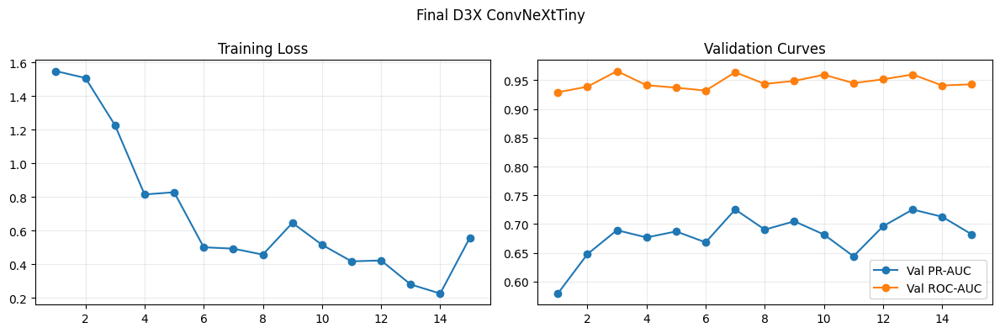

Final D3X training complete. Winning checkpoint: Final_D3X_ConvNeXtTiny


In [ ]:
# train final model on Dataset 3X
if D3X_WINNING_MODEL == 'ConvNeXtTiny':
    d3x_train_loader, d3x_val_loader, d3x_test_loader = make_d3x_convnext_loaders()
    convnext_cls = globals().get('TimmConvNeXtBinary', _XTimmConvNeXtBinary)
    final_d3x_convnext_model = convnext_cls(model_name=CONTRIB_MODEL_NAME_X, pretrained=True, dropout=0.45)
    final_d3x_convnext_model, hist_final_d3x_convnext = _x_train_convnext_binary(
        final_d3x_convnext_model,
        d3x_train_loader,
        d3x_val_loader,
        'Final_D3X_ConvNeXtTiny',
        y3x_train,
        epochs=int(globals().get('CONTRIB_EPOCHS', 30)),
        patience=int(globals().get('CONTRIB_PATIENCE', 8)),
    )
    if 'plot_torch_history' in globals():
        plot_torch_history(hist_final_d3x_convnext, 'Final D3X ConvNeXtTiny')
    FINAL_D3X_CHECKPOINT = 'Final_D3X_ConvNeXtTiny'
else:
    n_pos_d3x = int((y3x_train == 1).sum())
    n_neg_d3x = int((y3x_train == 0).sum())
    RAW_STEPS_D3X = max(n_neg_d3x // max(BATCH_SIZE // 2, 1), 10)
    STEPS_D3X = min(RAW_STEPS_D3X, 260)
    print(f'D3X EfficientNet steps: raw={RAW_STEPS_D3X}, capped={STEPS_D3X}')
    gen_final_d3x_eff = balanced_dataset3x_generator(D3X_SOURCES, aug_gen, batch_size=BATCH_SIZE, seed=950)
    final_d3x_eff_model, final_d3x_eff_base = build_efficientnet_transfer()
    final_d3x_eff_model = compile_transfer_head(final_d3x_eff_model, lr=5e-5)
    hist_final_d3x_eff_p1 = fit_model(
        final_d3x_eff_model,
        gen_final_d3x_eff,
        steps_per_epoch=STEPS_D3X,
        epochs=40,
        validation_data=(X3X_val, y3x_val),
        callbacks=get_callbacks('Final_D3X_EfficientNetB0_P1', patience=12, lr_patience=5),
        verbose=1,
        description='Final D3X EfficientNetB0 phase 1',
    )
    for layer in final_d3x_eff_base.layers[:-20]:
        layer.trainable = False
    for layer in final_d3x_eff_base.layers[-20:]:
        layer.trainable = True
    final_d3x_eff_model = compile_transfer_head(final_d3x_eff_model, lr=1e-5)
    gen_final_d3x_eff_p2 = balanced_dataset3x_generator(D3X_SOURCES, aug_gen, batch_size=BATCH_SIZE, seed=951)
    hist_final_d3x_eff_p2 = fit_model(
        final_d3x_eff_model,
        gen_final_d3x_eff_p2,
        steps_per_epoch=STEPS_D3X,
        epochs=40,
        validation_data=(X3X_val, y3x_val),
        callbacks=get_callbacks('Final_D3X_EfficientNetB0_P2', patience=12, lr_patience=5),
        verbose=1,
        description='Final D3X EfficientNetB0 phase 2',
    )
    final_d3x_eff_model = restore_best_trained_model(final_d3x_eff_model, 'Final_D3X_EfficientNetB0_P2')
    FINAL_D3X_CHECKPOINT = 'Final_D3X_EfficientNetB0_P2'

print(f'Final D3X training complete. Winning checkpoint: {FINAL_D3X_CHECKPOINT}')


We evaluate the final Dataset 3X model, logging metrics and plotting comparisons.


Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/final_d3x_winner_comparison.csv


,model,accuracy,balanced_acc,precision,recall,specificity,f1,macro_f1,mcc,auc,pr_auc,npv,threshold
0,Final-D3X-ConvNeXtTiny,0.9574,0.9306,0.6136,0.9000,0.9613,0.7297,0.8533,0.7228,0.9711,0.8733,0.9929,0.0500


Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/final_d3x_vs_existing_best_comparison.csv


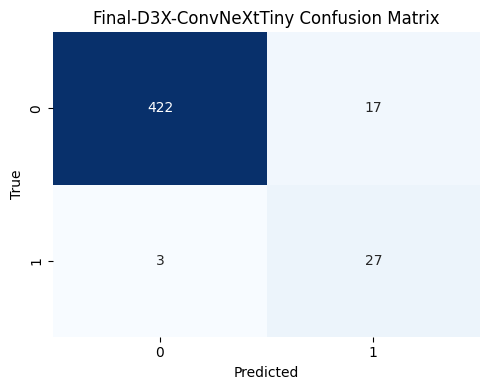

Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/final_d3x_winner_confusion_matrix.png


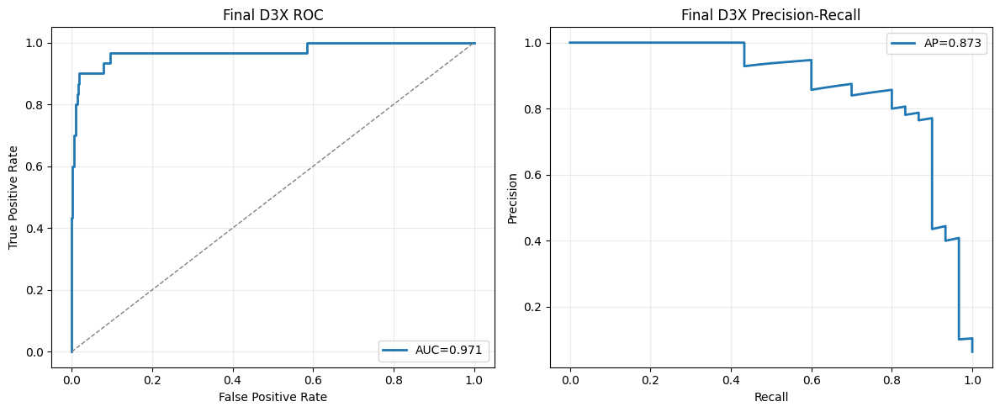

Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/final_d3x_winner_curves.png


0

In [ ]:
# evaluate final model

if D3X_WINNING_MODEL == 'ConvNeXtTiny':
    final_model = _x_load_convnext_model('Final_D3X_ConvNeXtTiny')
    final_val_loader = DataLoader(_XConvNeXtImageDataset(X3X_val, y3x_val), batch_size=CONTRIB_BATCH_SIZE_X, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available())
    final_test_loader = DataLoader(_XConvNeXtImageDataset(X3X_test, y3x_test), batch_size=CONTRIB_BATCH_SIZE_X, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available())
    _, final_val_prob = _x_predict_loader_convnext(final_model, final_val_loader)
    _, final_test_prob = _x_predict_loader_convnext(final_model, final_test_loader)
    final_thr = _x_threshold(y3x_val, final_val_prob)
    final_d3x_result = _x_metric_row(y3x_test, final_test_prob, 'Final-D3X-ConvNeXtTiny', final_thr)
else:
    load_kwargs_final = _best_model_load_kwargs() if '_best_model_load_kwargs' in globals() else {}
    load_kwargs_final = dict(load_kwargs_final)
    load_kwargs_final['compile'] = False
    final_model = run_tf_work(
        lambda: tf.keras.models.load_model(best_checkpoint_path('Final_D3X_EfficientNetB0_P2'), **load_kwargs_final),
        description='load Final D3X EfficientNetB0',
        fallback_to_cpu=False,
    )
    final_d3x_result, final_test_prob = evaluate_model(final_model, X3X_test, y3x_test, 'Final-D3X-EfficientNetB0', X3X_val, y3x_val)
    final_thr = float(final_d3x_result['threshold'])

final_d3x_winner_comparison_df = pd.DataFrame([final_d3x_result])
final_d3x_winner_comparison_df.to_csv(OUTPUT_DIR_X / 'final_d3x_winner_comparison.csv', index=False)
print(f"Saved: {OUTPUT_DIR_X / 'final_d3x_winner_comparison.csv'}")
display(final_d3x_winner_comparison_df.style.format('{:.4f}', subset=[c for c in final_d3x_winner_comparison_df.columns if c != 'model']))

existing_frames = []
for filename in ['best_roi_image_only_models_table.csv', 'dense_roi_eval_all_models_metrics.csv', 'd1_vs_d3r_roi_eff_comparison.csv']:
    path = OUTPUT_DIR_X / filename
    if path.exists():
        df_existing = pd.read_csv(path)
        if 'display_model' in df_existing.columns:
            df_existing = df_existing.rename(columns={'display_model': 'model'})
        existing_frames.append(df_existing)
if existing_frames:
    existing_compare = pd.concat(existing_frames, ignore_index=True, sort=False)
    compare_cols = ['model'] + [c for c in ['accuracy','balanced_acc','precision','recall','specificity','f1','macro_f1','mcc','auc','pr_auc','npv','threshold'] if c in existing_compare.columns or c in final_d3x_winner_comparison_df.columns]
    final_d3x_vs_existing_best_comparison_df = pd.concat([
        existing_compare[[c for c in compare_cols if c in existing_compare.columns]],
        final_d3x_winner_comparison_df[[c for c in compare_cols if c in final_d3x_winner_comparison_df.columns]],
    ], ignore_index=True, sort=False)
else:
    final_d3x_vs_existing_best_comparison_df = final_d3x_winner_comparison_df
final_d3x_vs_existing_best_comparison_df.to_csv(OUTPUT_DIR_X / 'final_d3x_vs_existing_best_comparison.csv', index=False)
print(f"Saved: {OUTPUT_DIR_X / 'final_d3x_vs_existing_best_comparison.csv'}")

pred = (np.asarray(final_test_prob) >= final_thr).astype(int)
cm = confusion_matrix(y3x_test, pred, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax)
ax.set_title(f'{final_d3x_result["model"]} Confusion Matrix')
ax.set_xlabel('Predicted')
ax.set_ylabel('True')
plt.tight_layout()
cm_path = OUTPUT_DIR_X / 'final_d3x_winner_confusion_matrix.png'
plt.savefig(cm_path, dpi=150)
plt.show()
print(f'Saved: {cm_path}')

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fpr, tpr, _ = roc_curve(y3x_test, final_test_prob)
prec, rec, _ = precision_recall_curve(y3x_test, final_test_prob)
axes[0].plot(fpr, tpr, lw=2, label=f"AUC={final_d3x_result['auc']:.3f}")
axes[0].plot([0, 1], [0, 1], '--', color='gray', lw=1)
axes[0].set_title('Final D3X ROC')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend()
axes[0].grid(alpha=0.25)
axes[1].plot(rec, prec, lw=2, label=f"AP={final_d3x_result['pr_auc']:.3f}")
axes[1].set_title('Final D3X Precision-Recall')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend()
axes[1].grid(alpha=0.25)
plt.tight_layout()
curves_path = OUTPUT_DIR_X / 'final_d3x_winner_curves.png'
plt.savefig(curves_path, dpi=150)
plt.show()
print(f'Saved: {curves_path}')

if 'final_model' in globals():
    del final_model
tf.keras.backend.clear_session()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
gc.collect()


# SECTION 6 - Tumour Segmentation & Patient Reporting
Training U-Net segmentation, multi-task classifiers, and compiling PDF oncology reports.


We load segmentation annotations and generate tumor masks for report validation.


In [ ]:
# generate segmentation masks


required_9a = [
    'df_valid', 'train_idx', 'val_idx', 'test_idx',
    'X_train', 'X_val', 'X_test', 'IMG_SIZE', 'OUTPUT_DIR',
]
missing_9a = [name for name in required_9a if name not in globals()]
if missing_9a:
    raise RuntimeError(f'SECTION 9 requires Dataset 1 preprocessing first. Missing: {missing_9a}')

REPORT_OUTPUT_DIR = Path(OUTPUT_DIR) / 'report_system'
REPORT_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
REPORT_REPORT_DIR = REPORT_OUTPUT_DIR / 'generated_reports'
REPORT_OVERLAY_DIR = REPORT_OUTPUT_DIR / 'generated_overlays'
REPORT_REPORT_DIR.mkdir(parents=True, exist_ok=True)
REPORT_OVERLAY_DIR.mkdir(parents=True, exist_ok=True)

PROJECT_ROOT_REPORT = Path.cwd().resolve()
if PROJECT_ROOT_REPORT.name == 'vlm_pipeline':
    PROJECT_ROOT_REPORT = PROJECT_ROOT_REPORT.parent
REPORT_IMAGE_DIR = PROJECT_ROOT_REPORT / 'GP Dataset 1' / 'images'
REPORT_ANNOTATION_DIR = PROJECT_ROOT_REPORT / 'Annotations' / 'Annotations'

REPORT_SEG_MASK_THRESHOLD_DEFAULT = 0.50
REPORT_SEG_MIN_MASK_RATIO = 0.001
REPORT_SEG_RANDOM_SEED = 42
REPORT_BATCH_SIZE = int(globals().get('BATCH_SIZE', 16))
REPORT_SEG_EPOCHS = int(globals().get('REPORT_SEG_EPOCHS', 35))
REPORT_SEG_PATIENCE = int(globals().get('REPORT_SEG_PATIENCE', 7))

np.random.seed(REPORT_SEG_RANDOM_SEED)

REPORT_TUMOR_CLASSES = {
    'osteosarcoma', 'osteochondroma', 'multiple osteochondromas', 'simple bone cyst',
    'giant cell tumor', 'synovial osteochondroma', 'osteofibroma', 'other bt', 'other mt'
}

def _report_img_size_tuple():
    return tuple(IMG_SIZE) if isinstance(IMG_SIZE, (tuple, list)) else (int(IMG_SIZE), int(IMG_SIZE))

def _report_annotation_path_for_row(row):
    image_id = str(row.get('image_id', '')).strip()
    if not image_id:
        return None
    path = REPORT_ANNOTATION_DIR / f'{image_id}.json'
    return path if path.exists() else None

def _report_points_to_scaled_array(points, src_w, src_h, dst_w, dst_h):
    pts = np.asarray(points, dtype=np.float32)
    if pts.ndim != 2 or pts.shape[1] != 2 or len(pts) < 2:
        return None
    pts[:, 0] = np.clip(pts[:, 0] * (dst_w / max(float(src_w), 1.0)), 0, dst_w - 1)
    pts[:, 1] = np.clip(pts[:, 1] * (dst_h / max(float(src_h), 1.0)), 0, dst_h - 1)
    return np.round(pts).astype(np.int32)

def labelme_mask_from_annotation(annotation_path, output_size=None):
    output_size = output_size or _report_img_size_tuple()
    dst_h, dst_w = int(output_size[0]), int(output_size[1])
    empty = np.zeros((dst_h, dst_w), dtype=np.uint8)
    if annotation_path is None or not Path(annotation_path).exists():
        return empty, 'empty_missing_annotation'
    try:
        data = json.loads(Path(annotation_path).read_text(encoding='utf-8'))
    except Exception:
        return empty, 'empty_bad_annotation_json'

    src_h = int(data.get('imageHeight') or dst_h)
    src_w = int(data.get('imageWidth') or dst_w)
    shapes = data.get('shapes', []) or []
    polygon_shapes = [s for s in shapes if str(s.get('shape_type', '')).lower() == 'polygon' and len(s.get('points') or []) >= 3]
    rectangle_shapes = [s for s in shapes if str(s.get('shape_type', '')).lower() == 'rectangle' and len(s.get('points') or []) >= 2]

    mask = empty.copy()
    if polygon_shapes:
        for shape in polygon_shapes:
            pts = _report_points_to_scaled_array(shape.get('points'), src_w, src_h, dst_w, dst_h)
            if pts is not None and len(pts) >= 3:
                cv2.fillPoly(mask, [pts], 1)
        return mask.astype(np.uint8), 'polygon'

    if rectangle_shapes:
        for shape in rectangle_shapes:
            pts = _report_points_to_scaled_array(shape.get('points'), src_w, src_h, dst_w, dst_h)
            if pts is None or len(pts) < 2:
                continue
            x1, y1 = pts.min(axis=0)
            x2, y2 = pts.max(axis=0)
            mask[int(y1):int(y2) + 1, int(x1):int(x2) + 1] = 1
        return mask.astype(np.uint8), 'rectangle_fallback'

    return empty, 'empty_no_usable_shapes'

def build_report_segmentation_masks():
    masks = []
    rows = []
    h, w = _report_img_size_tuple()
    for pos, (_, row) in enumerate(df_valid.iterrows()):
        tumor_type = str(row.get('tumor_type', '')).strip().lower()
        neoplasm = str(row.get('neoplasm', '')).strip().lower()
        has_tumor = tumor_type in REPORT_TUMOR_CLASSES and neoplasm != 'no tumor'
        ann_path = _report_annotation_path_for_row(row)
        if has_tumor:
            mask, source = labelme_mask_from_annotation(ann_path, output_size=(h, w))
        else:
            mask, source = np.zeros((h, w), dtype=np.uint8), 'empty_no_tumor'
        masks.append(mask[..., None].astype(np.float32))
        rows.append({
            'row_position': int(pos),
            'image_id': row.get('image_id'),
            'image_filename': row.get('image_filename'),
            'neoplasm': row.get('neoplasm'),
            'tumor_type': row.get('tumor_type'),
            'has_tumor_label': int(has_tumor),
            'mask_source': source,
            'mask_pixels': int(mask.sum()),
            'image_pixels': int(mask.size),
            'mask_ratio': float(mask.mean()),
            'annotation_path': str(ann_path) if ann_path is not None else '',
        })
    return np.asarray(masks, dtype=np.float32), pd.DataFrame(rows)

REPORT_SEG_MASKS, report_segmentation_mask_manifest_df = build_report_segmentation_masks()
REPORT_SEG_MASKS_TRAIN = REPORT_SEG_MASKS[train_idx]
REPORT_SEG_MASKS_VAL = REPORT_SEG_MASKS[val_idx]
REPORT_SEG_MASKS_TEST = REPORT_SEG_MASKS[test_idx]
report_segmentation_mask_manifest_df.to_csv(REPORT_OUTPUT_DIR / 'report_segmentation_mask_manifest.csv', index=False)

print('=' * 78)
print('SECTION 9A: SEGMENTATION MASKS FROM LABELME POLYGONS')
print('=' * 78)
print(f'Masks shape train/val/test: {REPORT_SEG_MASKS_TRAIN.shape} | {REPORT_SEG_MASKS_VAL.shape} | {REPORT_SEG_MASKS_TEST.shape}')
print('Mask source counts:')
display(report_segmentation_mask_manifest_df['mask_source'].value_counts().rename_axis('mask_source').reset_index(name='count'))
print(f'Saved: {REPORT_OUTPUT_DIR / "report_segmentation_mask_manifest.csv"}')


SECTION 9A: SEGMENTATION MASKS FROM LABELME POLYGONS
Masks shape train/val/test: (2659, 224, 224, 1) | (618, 224, 224, 1) | (469, 224, 224, 1)
Mask source counts:


,mask_source,count
0,empty_no_tumor,1879
1,polygon,1867


Saved: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/report_system/report_segmentation_mask_manifest.csv


We train a lightweight U-Net tumor segmentation model on the segmented X-rays.


In [ ]:
# train U-Net segmentation model

REPORT_DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(REPORT_SEG_RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(REPORT_SEG_RANDOM_SEED)

class ReportSegmentationDataset(Dataset):
    def __init__(self, X, masks, augment=False, seed=42):
        self.X = np.asarray(X)
        self.masks = np.asarray(masks)
        self.augment = bool(augment)
        self.rng = np.random.default_rng(seed)
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        img = torch.from_numpy(self.X[idx].astype(np.float32)).permute(2, 0, 1)
        mask = torch.from_numpy(self.masks[idx].astype(np.float32)).permute(2, 0, 1)
        if self.augment:
            if self.rng.random() < 0.5:
                img = TVF.hflip(img)
                mask = TVF.hflip(mask)
            angle = float(self.rng.uniform(-8.0, 8.0))
            img = TVF.rotate(img, angle=angle, interpolation=InterpolationMode.BILINEAR, fill=0.0)
            mask = TVF.rotate(mask, angle=angle, interpolation=InterpolationMode.NEAREST, fill=0.0)
            if self.rng.random() < 0.30:
                img = TVF.adjust_brightness(img, float(self.rng.uniform(0.92, 1.08)))
            if self.rng.random() < 0.30:
                img = TVF.adjust_contrast(img, float(self.rng.uniform(0.92, 1.08)))
        return torch.clamp(img, 0.0, 1.0).float(), (mask > 0.5).float()

class _ReportDoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
        )
    def forward(self, x):
        return self.net(x)

class ReportTinyUNet(nn.Module):
    def __init__(self, in_channels=3, base=24):
        super().__init__()
        self.enc1 = _ReportDoubleConv(in_channels, base)
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = _ReportDoubleConv(base, base * 2)
        self.pool2 = nn.MaxPool2d(2)
        self.enc3 = _ReportDoubleConv(base * 2, base * 4)
        self.pool3 = nn.MaxPool2d(2)
        self.bottleneck = _ReportDoubleConv(base * 4, base * 8)
        self.up3 = nn.ConvTranspose2d(base * 8, base * 4, 2, stride=2)
        self.dec3 = _ReportDoubleConv(base * 8, base * 4)
        self.up2 = nn.ConvTranspose2d(base * 4, base * 2, 2, stride=2)
        self.dec2 = _ReportDoubleConv(base * 4, base * 2)
        self.up1 = nn.ConvTranspose2d(base * 2, base, 2, stride=2)
        self.dec1 = _ReportDoubleConv(base * 2, base)
        self.out = nn.Conv2d(base, 1, 1)
    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        e3 = self.enc3(self.pool2(e2))
        b = self.bottleneck(self.pool3(e3))
        d3 = self.dec3(torch.cat([self.up3(b), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.out(d1)

def report_dice_coeff_from_logits(logits, masks, threshold=0.5, eps=1e-7):
    probs = torch.sigmoid(logits)
    preds = (probs >= threshold).float()
    intersection = (preds * masks).sum(dim=(1, 2, 3))
    union = preds.sum(dim=(1, 2, 3)) + masks.sum(dim=(1, 2, 3))
    return ((2 * intersection + eps) / (union + eps)).mean()

def report_dice_loss(logits, masks, eps=1e-7):
    probs = torch.sigmoid(logits)
    intersection = (probs * masks).sum(dim=(1, 2, 3))
    union = probs.sum(dim=(1, 2, 3)) + masks.sum(dim=(1, 2, 3))
    dice = (2 * intersection + eps) / (union + eps)
    return 1.0 - dice.mean()

def report_seg_loss(logits, masks, bce):
    return bce(logits, masks) + report_dice_loss(logits, masks)

@torch.no_grad()
def predict_report_segmentation(model, loader):
    model.eval()
    probs, masks = [], []
    for xb, mb in loader:
        xb = xb.to(REPORT_DEVICE).float()
        logits = model(xb)
        probs.append(torch.sigmoid(logits).detach().cpu().numpy())
        masks.append(mb.numpy())
    return np.concatenate(probs).astype(np.float32), np.concatenate(masks).astype(np.float32)

def _report_seg_metrics_np(y_true, y_prob, threshold=0.5):
    y_true = (np.asarray(y_true) > 0.5).astype(np.uint8)
    y_prob = np.asarray(y_prob).astype(np.float32)
    y_pred = (y_prob >= threshold).astype(np.uint8)
    flat_true = y_true.reshape(len(y_true), -1)
    flat_pred = y_pred.reshape(len(y_pred), -1)
    intersection = (flat_true * flat_pred).sum(axis=1)
    pred_sum = flat_pred.sum(axis=1)
    true_sum = flat_true.sum(axis=1)
    dice = (2 * intersection + 1e-7) / (pred_sum + true_sum + 1e-7)
    union = pred_sum + true_sum - intersection
    iou = (intersection + 1e-7) / (union + 1e-7)
    pixel_acc = (flat_true == flat_pred).mean(axis=1)
    true_ratio = flat_true.mean(axis=1)
    pred_ratio = flat_pred.mean(axis=1)
    mae = np.abs(true_ratio - pred_ratio)
    corr = np.corrcoef(true_ratio, pred_ratio)[0, 1] if np.std(true_ratio) > 0 and np.std(pred_ratio) > 0 else np.nan
    return {
        'threshold': float(threshold),
        'dice': float(np.mean(dice)),
        'iou': float(np.mean(iou)),
        'pixel_accuracy': float(np.mean(pixel_acc)),
        'tumour_ratio_mae': float(np.mean(mae)),
        'tumour_ratio_corr': float(corr) if np.isfinite(corr) else np.nan,
    }

def train_report_segmentation_model():
    train_ds = ReportSegmentationDataset(X_train, REPORT_SEG_MASKS_TRAIN, augment=True, seed=REPORT_SEG_RANDOM_SEED)
    val_ds = ReportSegmentationDataset(X_val, REPORT_SEG_MASKS_VAL, augment=False)
    train_loader = DataLoader(train_ds, batch_size=REPORT_BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=torch.cuda.is_available())
    val_loader = DataLoader(val_ds, batch_size=REPORT_BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available())
    model = ReportTinyUNet().to(REPORT_DEVICE)
    pos_pixels = float(REPORT_SEG_MASKS_TRAIN.sum())
    neg_pixels = float(REPORT_SEG_MASKS_TRAIN.size - pos_pixels)
    pos_weight = torch.tensor([min(max(neg_pixels / max(pos_pixels, 1.0), 1.0), 50.0)], dtype=torch.float32, device=REPORT_DEVICE)
    bce = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optimizer = torch.optim.AdamW(model.parameters(), lr=2e-4, weight_decay=1e-5)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=3)
    ckpt_path = REPORT_OUTPUT_DIR / 'best_REPORT_TumourSeg_UNet.pt'
    best_dice, best_epoch, patience_left = -np.inf, 0, REPORT_SEG_PATIENCE
    history = []
    for epoch in range(1, REPORT_SEG_EPOCHS + 1):
        model.train()
        losses = []
        for xb, mb in train_loader:
            xb = xb.to(REPORT_DEVICE).float()
            mb = mb.to(REPORT_DEVICE).float()
            optimizer.zero_grad(set_to_none=True)
            logits = model(xb)
            loss = report_seg_loss(logits, mb, bce)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            losses.append(float(loss.detach().cpu()))
        val_prob, val_mask = predict_report_segmentation(model, val_loader)
        val_metrics = _report_seg_metrics_np(val_mask, val_prob, threshold=0.5)
        val_dice = val_metrics['dice']
        scheduler.step(val_dice)
        row = {'epoch': epoch, 'loss': float(np.mean(losses)), 'val_dice_at_050': val_dice, 'val_iou_at_050': val_metrics['iou']}
        history.append(row)
        print(f"Seg epoch {epoch:02d}: loss={row['loss']:.4f} val_dice={val_dice:.4f} val_iou={row['val_iou_at_050']:.4f}")
        if val_dice > best_dice:
            best_dice, best_epoch, patience_left = val_dice, epoch, REPORT_SEG_PATIENCE
            torch.save({'model_state_dict': model.state_dict(), 'best_epoch': epoch, 'best_val_dice': best_dice}, ckpt_path)
            print(f'  Saved best segmentation checkpoint: {ckpt_path}')
        else:
            patience_left -= 1
            if patience_left <= 0:
                print(f'Early stopping segmentation at epoch {epoch}; best epoch={best_epoch}.')
                break
    pd.DataFrame(history).to_csv(REPORT_OUTPUT_DIR / 'report_segmentation_training_history.csv', index=False)
    if ckpt_path.exists():
        best = torch.load(ckpt_path, map_location=REPORT_DEVICE)
        model.load_state_dict(best['model_state_dict'])
    return model, pd.DataFrame(history)

report_seg_model, report_seg_history_df = train_report_segmentation_model()
print('Segmentation training complete.')


Seg epoch 01: loss=1.9099 val_dice=0.0560 val_iou=0.0322
  Saved best segmentation checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/report_system/best_REPORT_TumourSeg_UNet.pt
Seg epoch 02: loss=1.7949 val_dice=0.0689 val_iou=0.0408
  Saved best segmentation checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/report_system/best_REPORT_TumourSeg_UNet.pt
Seg epoch 03: loss=1.7379 val_dice=0.0980 val_iou=0.0626
  Saved best segmentation checkpoint: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/report_system/best_REPORT_TumourSeg_UNet.pt


We evaluate the U-Net model and save visualization examples of tumor segmentation.


In [ ]:
# evaluate segmentation model

seg_ckpt = REPORT_OUTPUT_DIR / 'best_REPORT_TumourSeg_UNet.pt'
if not seg_ckpt.exists():
    raise FileNotFoundError(f'Missing segmentation checkpoint: {seg_ckpt}. Run CELL 9A-2 first.')
report_seg_eval_model = ReportTinyUNet().to(REPORT_DEVICE)
report_seg_eval_model.load_state_dict(torch.load(seg_ckpt, map_location=REPORT_DEVICE)['model_state_dict'])
report_seg_eval_model.eval()

val_loader_seg = DataLoader(ReportSegmentationDataset(X_val, REPORT_SEG_MASKS_VAL, augment=False), batch_size=REPORT_BATCH_SIZE, shuffle=False, num_workers=0)
test_loader_seg = DataLoader(ReportSegmentationDataset(X_test, REPORT_SEG_MASKS_TEST, augment=False), batch_size=REPORT_BATCH_SIZE, shuffle=False, num_workers=0)
val_prob_seg, val_mask_seg = predict_report_segmentation(report_seg_eval_model, val_loader_seg)
test_prob_seg, test_mask_seg = predict_report_segmentation(report_seg_eval_model, test_loader_seg)

threshold_rows = []
for thr in np.linspace(0.10, 0.90, 17):
    row = _report_seg_metrics_np(val_mask_seg, val_prob_seg, threshold=float(thr))
    row['split'] = 'val'
    threshold_rows.append(row)
report_segmentation_threshold_summary_df = pd.DataFrame(threshold_rows).sort_values(['dice', 'iou'], ascending=False).reset_index(drop=True)
REPORT_SEG_BEST_THRESHOLD = float(report_segmentation_threshold_summary_df.iloc[0]['threshold'])
report_segmentation_threshold_summary_df.to_csv(REPORT_OUTPUT_DIR / 'report_segmentation_threshold_summary.csv', index=False)

test_metrics = _report_seg_metrics_np(test_mask_seg, test_prob_seg, threshold=REPORT_SEG_BEST_THRESHOLD)
test_metrics['split'] = 'test'
report_segmentation_test_metrics_df = pd.DataFrame([test_metrics])
report_segmentation_test_metrics_df.to_csv(REPORT_OUTPUT_DIR / 'report_segmentation_test_metrics.csv', index=False)

print(f'Best segmentation mask threshold from validation: {REPORT_SEG_BEST_THRESHOLD:.3f}')
display(report_segmentation_threshold_summary_df.head(5))
display(report_segmentation_test_metrics_df)

# Visual examples: first tumour masks plus first no-tumour masks from test split.
test_global_idx = np.asarray(test_idx)
test_has_tumor = (REPORT_SEG_MASKS_TEST.reshape(len(REPORT_SEG_MASKS_TEST), -1).sum(axis=1) > 0)
example_positions = list(np.where(test_has_tumor)[0][:4]) + list(np.where(~test_has_tumor)[0][:2])
example_positions = example_positions[:6]
fig, axes = plt.subplots(len(example_positions), 4, figsize=(14, 3.4 * max(len(example_positions), 1)))
if len(example_positions) == 1:
    axes = np.asarray([axes])
for row_i, pos in enumerate(example_positions):
    img = X_test[pos]
    true_mask = REPORT_SEG_MASKS_TEST[pos, :, :, 0]
    pred_prob = test_prob_seg[pos, 0]
    pred_mask = (pred_prob >= REPORT_SEG_BEST_THRESHOLD).astype(np.float32)
    overlay = img.copy()
    overlay[..., 0] = np.clip(overlay[..., 0] + 0.45 * pred_mask, 0, 1)
    axes[row_i, 0].imshow(img); axes[row_i, 0].set_title('Image'); axes[row_i, 0].axis('off')
    axes[row_i, 1].imshow(true_mask, cmap='gray'); axes[row_i, 1].set_title('True mask'); axes[row_i, 1].axis('off')
    axes[row_i, 2].imshow(pred_prob, cmap='magma'); axes[row_i, 2].set_title('Pred probability'); axes[row_i, 2].axis('off')
    axes[row_i, 3].imshow(overlay); axes[row_i, 3].set_title('Pred overlay'); axes[row_i, 3].axis('off')
plt.tight_layout()
plt.savefig(REPORT_OUTPUT_DIR / 'report_segmentation_examples.png', dpi=180, bbox_inches='tight')
plt.show()
print('Saved:', REPORT_OUTPUT_DIR / 'report_segmentation_examples.png')

del report_seg_eval_model
if torch.cuda.is_available():
    torch.cuda.empty_cache()
gc.collect()


We train a multi-task ConvNeXt classifier to predict multi-task targets from full chest images.


In [ ]:
# train multi-task report classifier

REPORT_MODEL_NAME = globals().get('REPORT_MODEL_NAME', globals().get('CONTRIB_MODEL_NAME', 'convnext_tiny'))
REPORT_CLASSIFIER_EPOCHS = int(globals().get('REPORT_CLASSIFIER_EPOCHS', 35))
REPORT_CLASSIFIER_PATIENCE = int(globals().get('REPORT_CLASSIFIER_PATIENCE', 8))
REPORT_CLASSIFIER_BATCH = int(globals().get('REPORT_CLASSIFIER_BATCH', max(8, min(REPORT_BATCH_SIZE, 16))))
REPORT_CLASSIFIER_DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
REPORT_MEAN = torch.tensor([0.485, 0.456, 0.406], dtype=torch.float32).view(3, 1, 1)
REPORT_STD = torch.tensor([0.229, 0.224, 0.225], dtype=torch.float32).view(3, 1, 1)

REPORT_CLASS_NAMES_TUMOR = globals().get('MC_CLASS_NAMES', [
    'no_tumor_or_unlabeled', 'giant cell tumor', 'multiple osteochondromas', 'osteochondroma', 'osteofibroma',
    'osteosarcoma', 'other bt', 'other mt', 'simple bone cyst', 'synovial osteochondroma'
])
REPORT_TUMOR_TO_ID = {name: i for i, name in enumerate(REPORT_CLASS_NAMES_TUMOR)}
REPORT_NEOPLASM_NAMES = ['no_tumor', 'benign', 'malignant']
REPORT_NEOPLASM_TO_ID = {name: i for i, name in enumerate(REPORT_NEOPLASM_NAMES)}

def _report_norm_tumor_type(value):
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return 'no_tumor_or_unlabeled'
    text = str(value).strip().lower().replace('_', ' ')
    text = ' '.join(text.split())
    if text in {'', 'nan', 'none', 'unknown', 'unk', 'unlabeled', 'not specified'}:
        return 'no_tumor_or_unlabeled'
    return text

def _report_norm_neoplasm(value):
    text = str(value).strip().lower().replace(' ', '_')
    return text if text in REPORT_NEOPLASM_TO_ID else 'no_tumor'

report_tumor_text_all = df_valid['tumor_type'].apply(_report_norm_tumor_type)
unknown_report_tumors = sorted(set(report_tumor_text_all) - set(REPORT_CLASS_NAMES_TUMOR))
if unknown_report_tumors:
    raise ValueError(f'Unknown report tumour labels: {unknown_report_tumors}')
report_y_tumor_all = report_tumor_text_all.map(REPORT_TUMOR_TO_ID).astype(np.int64).values
report_y_neoplasm_all = df_valid['neoplasm'].apply(_report_norm_neoplasm).map(REPORT_NEOPLASM_TO_ID).astype(np.int64).values

report_skeletal_encoder = LabelEncoder().fit(df_valid['skeletal_type'].astype(str).str.lower().values)
report_bones_encoder = LabelEncoder().fit(df_valid['bones_type'].astype(str).str.lower().values)
REPORT_SKELETAL_NAMES = list(report_skeletal_encoder.classes_)
REPORT_BONES_NAMES = list(report_bones_encoder.classes_)
report_y_skeletal_all = report_skeletal_encoder.transform(df_valid['skeletal_type'].astype(str).str.lower().values).astype(np.int64)
report_y_bones_all = report_bones_encoder.transform(df_valid['bones_type'].astype(str).str.lower().values).astype(np.int64)

REPORT_AGE_MEAN = float(df_valid.loc[train_idx, 'age'].astype(float).mean())
REPORT_AGE_STD = float(df_valid.loc[train_idx, 'age'].astype(float).std() or 1.0)
REPORT_GENDER_TO_ID = {'f': 0.0, 'female': 0.0, 'm': 1.0, 'male': 1.0}

def build_report_age_gender_features(indices_or_rows):
    if isinstance(indices_or_rows, pd.DataFrame):
        rows = indices_or_rows
    else:
        rows = df_valid.loc[indices_or_rows]
    age = rows['age'].astype(float).values
    age_z = (age - REPORT_AGE_MEAN) / max(REPORT_AGE_STD, 1e-6)
    gender = rows['gender'].astype(str).str.lower().map(REPORT_GENDER_TO_ID).fillna(0.5).values
    return np.stack([age_z, gender], axis=1).astype(np.float32)

REPORT_META_TRAIN = build_report_age_gender_features(train_idx)
REPORT_META_VAL = build_report_age_gender_features(val_idx)
REPORT_META_TEST = build_report_age_gender_features(test_idx)

report_targets = {
    'tumor': (report_y_tumor_all[train_idx], report_y_tumor_all[val_idx], report_y_tumor_all[test_idx], REPORT_CLASS_NAMES_TUMOR),
    'neoplasm': (report_y_neoplasm_all[train_idx], report_y_neoplasm_all[val_idx], report_y_neoplasm_all[test_idx], REPORT_NEOPLASM_NAMES),
    'skeletal': (report_y_skeletal_all[train_idx], report_y_skeletal_all[val_idx], report_y_skeletal_all[test_idx], REPORT_SKELETAL_NAMES),
    'bones': (report_y_bones_all[train_idx], report_y_bones_all[val_idx], report_y_bones_all[test_idx], REPORT_BONES_NAMES),
}

def _report_class_weights(y, n_classes):
    classes = np.arange(n_classes)
    present = np.unique(y)
    weights = np.ones(n_classes, dtype=np.float32)
    if len(present) > 1:
        computed = compute_class_weight(class_weight='balanced', classes=present, y=y).astype(np.float32)
        for cls, w in zip(present, computed):
            weights[int(cls)] = w
    return weights

REPORT_CLASS_WEIGHTS = {
    task: _report_class_weights(vals[0], len(vals[3])) for task, vals in report_targets.items()
}

class ReportMultiTaskDataset(Dataset):
    def __init__(self, X, meta, y_tumor, y_neoplasm, y_skeletal, y_bones, augment=False, seed=42):
        self.X = np.asarray(X)
        self.meta = np.asarray(meta).astype(np.float32)
        self.y_tumor = np.asarray(y_tumor).astype(np.int64)
        self.y_neoplasm = np.asarray(y_neoplasm).astype(np.int64)
        self.y_skeletal = np.asarray(y_skeletal).astype(np.int64)
        self.y_bones = np.asarray(y_bones).astype(np.int64)
        self.augment = bool(augment)
        self.rng = np.random.default_rng(seed)
    def __len__(self): return len(self.y_tumor)
    def __getitem__(self, idx):
        img = torch.from_numpy(self.X[idx].astype(np.float32)).permute(2, 0, 1)
        if self.augment:
            if self.rng.random() < 0.5:
                img = TVF.hflip(img)
            angle = float(self.rng.uniform(-8.0, 8.0))
            img = TVF.rotate(img, angle=angle, interpolation=InterpolationMode.BILINEAR, fill=0.0)
            if self.rng.random() < 0.30:
                img = TVF.adjust_brightness(img, float(self.rng.uniform(0.92, 1.08)))
            if self.rng.random() < 0.30:
                img = TVF.adjust_contrast(img, float(self.rng.uniform(0.92, 1.08)))
        img = (torch.clamp(img, 0.0, 1.0) - REPORT_MEAN) / REPORT_STD
        return img.float(), torch.from_numpy(self.meta[idx]).float(), {
            'tumor': torch.tensor(self.y_tumor[idx], dtype=torch.long),
            'neoplasm': torch.tensor(self.y_neoplasm[idx], dtype=torch.long),
            'skeletal': torch.tensor(self.y_skeletal[idx], dtype=torch.long),
            'bones': torch.tensor(self.y_bones[idx], dtype=torch.long),
        }

class ReportMultiTaskConvNeXt(nn.Module):
    def __init__(self, model_name=REPORT_MODEL_NAME, pretrained=True):
        super().__init__()
        self.backbone = timm.create_model(model_name, pretrained=pretrained, num_classes=0, global_pool='avg')
        feat_dim = int(getattr(self.backbone, 'num_features'))
        self.meta_branch = nn.Sequential(nn.Linear(2, 32), nn.BatchNorm1d(32), nn.GELU(), nn.Dropout(0.20), nn.Linear(32, 16), nn.GELU())
        fused_dim = feat_dim + 16
        self.shared = nn.Sequential(nn.Dropout(0.35), nn.Linear(fused_dim, 384), nn.GELU(), nn.Dropout(0.35))
        self.tumor_head = nn.Linear(384, len(REPORT_CLASS_NAMES_TUMOR))
        self.neoplasm_head = nn.Linear(384, len(REPORT_NEOPLASM_NAMES))
        self.skeletal_head = nn.Linear(384, len(REPORT_SKELETAL_NAMES))
        self.bones_head = nn.Linear(384, len(REPORT_BONES_NAMES))
    def forward(self, image, meta):
        img_feat = self.backbone(image)
        if img_feat.ndim > 2:
            img_feat = img_feat.mean(dim=tuple(range(2, img_feat.ndim)))
        meta_feat = self.meta_branch(meta)
        shared = self.shared(torch.cat([img_feat, meta_feat], dim=1))
        return {
            'tumor': self.tumor_head(shared),
            'neoplasm': self.neoplasm_head(shared),
            'skeletal': self.skeletal_head(shared),
            'bones': self.bones_head(shared),
        }

def make_report_multitask_loaders():
    y_train_tumor, y_val_tumor, y_test_tumor, _ = report_targets['tumor']
    y_train_neoplasm, y_val_neoplasm, y_test_neoplasm, _ = report_targets['neoplasm']
    y_train_skeletal, y_val_skeletal, y_test_skeletal, _ = report_targets['skeletal']
    y_train_bones, y_val_bones, y_test_bones, _ = report_targets['bones']
    train_ds = ReportMultiTaskDataset(X_train, REPORT_META_TRAIN, y_train_tumor, y_train_neoplasm, y_train_skeletal, y_train_bones, augment=True, seed=REPORT_SEG_RANDOM_SEED)
    val_ds = ReportMultiTaskDataset(X_val, REPORT_META_VAL, y_val_tumor, y_val_neoplasm, y_val_skeletal, y_val_bones, augment=False)
    test_ds = ReportMultiTaskDataset(X_test, REPORT_META_TEST, y_test_tumor, y_test_neoplasm, y_test_skeletal, y_test_bones, augment=False)
    counts = np.bincount(y_train_tumor, minlength=len(REPORT_CLASS_NAMES_TUMOR)).astype(np.float32)
    counts[counts == 0] = 1.0
    sample_weights = 1.0 / counts[y_train_tumor]
    sampler = WeightedRandomSampler(torch.DoubleTensor(sample_weights), num_samples=len(sample_weights), replacement=True)
    return (
        DataLoader(train_ds, batch_size=REPORT_CLASSIFIER_BATCH, sampler=sampler, num_workers=0, pin_memory=torch.cuda.is_available()),
        DataLoader(val_ds, batch_size=REPORT_CLASSIFIER_BATCH, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available()),
        DataLoader(test_ds, batch_size=REPORT_CLASSIFIER_BATCH, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available()),
    )

@torch.no_grad()
def predict_report_multitask(model, loader):
    model.eval()
    probs = {k: [] for k in ['tumor', 'neoplasm', 'skeletal', 'bones']}
    labels = {k: [] for k in ['tumor', 'neoplasm', 'skeletal', 'bones']}
    for xb, mb, yb in loader:
        xb = xb.to(REPORT_CLASSIFIER_DEVICE).float()
        mb = mb.to(REPORT_CLASSIFIER_DEVICE).float()
        out = model(xb, mb)
        for task in probs:
            probs[task].append(torch.softmax(out[task], dim=1).detach().cpu().numpy())
            labels[task].append(yb[task].numpy())
    return {k: np.concatenate(v).astype(np.float32) for k, v in probs.items()}, {k: np.concatenate(v).astype(int) for k, v in labels.items()}

def train_report_multitask_model():
    train_loader, val_loader, test_loader = make_report_multitask_loaders()
    model = ReportMultiTaskConvNeXt(pretrained=True).to(REPORT_CLASSIFIER_DEVICE)
    backbone_params, head_params = [], []
    for name, param in model.named_parameters():
        if not param.requires_grad: continue
        (backbone_params if name.startswith('backbone.') else head_params).append(param)
    optimizer = torch.optim.AdamW([
        {'params': backbone_params, 'lr': 1e-5},
        {'params': head_params, 'lr': 5e-5},
    ], weight_decay=1e-4)
    criteria = {
        task: nn.CrossEntropyLoss(weight=torch.tensor(weights, dtype=torch.float32, device=REPORT_CLASSIFIER_DEVICE))
        for task, weights in REPORT_CLASS_WEIGHTS.items()
    }
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=3)
    ckpt_path = REPORT_OUTPUT_DIR / 'best_REPORT_MultiTask_ConvNeXtTiny.pt'
    best_score, best_epoch, patience_left = -np.inf, 0, REPORT_CLASSIFIER_PATIENCE
    history = []
    for epoch in range(1, REPORT_CLASSIFIER_EPOCHS + 1):
        model.train(); losses=[]
        for xb, mb, yb in train_loader:
            xb = xb.to(REPORT_CLASSIFIER_DEVICE).float()
            mb = mb.to(REPORT_CLASSIFIER_DEVICE).float()
            yb = {k: v.to(REPORT_CLASSIFIER_DEVICE).long() for k, v in yb.items()}
            optimizer.zero_grad(set_to_none=True)
            out = model(xb, mb)
            loss = (1.4 * criteria['tumor'](out['tumor'], yb['tumor']) + criteria['neoplasm'](out['neoplasm'], yb['neoplasm']) + 0.8 * criteria['skeletal'](out['skeletal'], yb['skeletal']) + 0.8 * criteria['bones'](out['bones'], yb['bones']))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            losses.append(float(loss.detach().cpu()))
        val_probs, val_labels = predict_report_multitask(model, val_loader)
        val_macro = np.mean([f1_score(val_labels[k], np.argmax(val_probs[k], axis=1), average='macro', zero_division=0) for k in val_probs])
        scheduler.step(val_macro)
        row = {'epoch': epoch, 'loss': float(np.mean(losses)), 'val_mean_macro_f1': float(val_macro)}
        history.append(row)
        print(f"Report multitask epoch {epoch:02d}: loss={row['loss']:.4f} val_mean_macro_f1={val_macro:.4f}")
        if val_macro > best_score:
            best_score, best_epoch, patience_left = float(val_macro), epoch, REPORT_CLASSIFIER_PATIENCE
            torch.save({
                'model_state_dict': model.state_dict(),
                'model_name': REPORT_MODEL_NAME,
                'class_names': {
                    'tumor': REPORT_CLASS_NAMES_TUMOR,
                    'neoplasm': REPORT_NEOPLASM_NAMES,
                    'skeletal': REPORT_SKELETAL_NAMES,
                    'bones': REPORT_BONES_NAMES,
                },
                'age_mean': REPORT_AGE_MEAN,
                'age_std': REPORT_AGE_STD,
                'best_epoch': best_epoch,
                'best_val_mean_macro_f1': best_score,
            }, ckpt_path)
            print(f'  Saved best report classifier checkpoint: {ckpt_path}')
        else:
            patience_left -= 1
            if patience_left <= 0:
                print(f'Early stopping report classifier at epoch {epoch}; best epoch={best_epoch}.')
                break
    pd.DataFrame(history).to_csv(REPORT_OUTPUT_DIR / 'report_multitask_training_history.csv', index=False)
    return model, pd.DataFrame(history), train_loader, val_loader, test_loader

report_multitask_model, report_multitask_history_df, report_train_loader, report_val_loader, report_test_loader = train_report_multitask_model()
print('Report multitask classifier training complete.')


We evaluate the multi-task classifier performance on the clinical report features.


In [ ]:
# evaluate multi-task model

report_cls_ckpt = REPORT_OUTPUT_DIR / 'best_REPORT_MultiTask_ConvNeXtTiny.pt'
if not report_cls_ckpt.exists():
    raise FileNotFoundError(f'Missing report classifier checkpoint: {report_cls_ckpt}. Run CELL 9B-1 first.')
ckpt = torch.load(report_cls_ckpt, map_location=REPORT_CLASSIFIER_DEVICE)
report_eval_model = ReportMultiTaskConvNeXt(model_name=ckpt.get('model_name', REPORT_MODEL_NAME), pretrained=False).to(REPORT_CLASSIFIER_DEVICE)
report_eval_model.load_state_dict(ckpt['model_state_dict'])
report_eval_model.eval()

_, _, report_test_loader_eval = make_report_multitask_loaders()
report_test_probs, report_test_labels = predict_report_multitask(report_eval_model, report_test_loader_eval)

report_task_names = {
    'tumor': REPORT_CLASS_NAMES_TUMOR,
    'neoplasm': REPORT_NEOPLASM_NAMES,
    'skeletal': REPORT_SKELETAL_NAMES,
    'bones': REPORT_BONES_NAMES,
}
metric_rows = []
report_frames = []
for task, class_names in report_task_names.items():
    y_true = report_test_labels[task]
    y_pred = np.argmax(report_test_probs[task], axis=1)
    print(f'{task}: expected_classes={len(class_names)}, true_classes={len(np.unique(y_true))}, pred_classes={len(np.unique(y_pred))}')
    metric_rows.append({
        'task': task,
        'accuracy': accuracy_score(y_true, y_pred),
        'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
        'macro_precision': precision_score(y_true, y_pred, average='macro', zero_division=0),
        'macro_recall': recall_score(y_true, y_pred, average='macro', zero_division=0),
        'macro_f1': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'weighted_f1': f1_score(y_true, y_pred, average='weighted', zero_division=0),
    })
    rep = pd.DataFrame(classification_report(y_true, y_pred, labels=list(range(len(class_names))), target_names=class_names, output_dict=True, zero_division=0)).T
    rep.insert(0, 'task', task)
    report_frames.append(rep.reset_index(names='class_name'))

# Collapsed tumour-vs-no-tumour from tumour-type head.
y_true_tumor_binary = (report_test_labels['tumor'] != REPORT_TUMOR_TO_ID['no_tumor_or_unlabeled']).astype(int)
y_pred_tumor_binary = (np.argmax(report_test_probs['tumor'], axis=1) != REPORT_TUMOR_TO_ID['no_tumor_or_unlabeled']).astype(int)
metric_rows.append({
    'task': 'tumour_presence_collapsed',
    'accuracy': accuracy_score(y_true_tumor_binary, y_pred_tumor_binary),
    'balanced_accuracy': balanced_accuracy_score(y_true_tumor_binary, y_pred_tumor_binary),
    'macro_precision': precision_score(y_true_tumor_binary, y_pred_tumor_binary, average='macro', zero_division=0),
    'macro_recall': recall_score(y_true_tumor_binary, y_pred_tumor_binary, average='macro', zero_division=0),
    'macro_f1': f1_score(y_true_tumor_binary, y_pred_tumor_binary, average='macro', zero_division=0),
    'weighted_f1': f1_score(y_true_tumor_binary, y_pred_tumor_binary, average='weighted', zero_division=0),
})

report_multitask_test_metrics_df = pd.DataFrame(metric_rows)
report_multitask_classification_reports_df = pd.concat(report_frames, ignore_index=True)
report_multitask_test_metrics_df.to_csv(REPORT_OUTPUT_DIR / 'report_multitask_test_metrics.csv', index=False)
report_multitask_classification_reports_df.to_csv(REPORT_OUTPUT_DIR / 'report_multitask_classification_reports.csv', index=False)

print('Report multi-task test metrics:')
display(report_multitask_test_metrics_df.style.format({c: '{:.4f}' for c in report_multitask_test_metrics_df.select_dtypes(include='number').columns}))
print('Report multi-task per-class metrics:')
display(report_multitask_classification_reports_df[report_multitask_classification_reports_df['class_name'].isin(sum([list(v) for v in report_task_names.values()], []))][['task', 'class_name', 'precision', 'recall', 'f1-score', 'support']].style.format({'precision': '{:.4f}', 'recall': '{:.4f}', 'f1-score': '{:.4f}', 'support': '{:.0f}'}))

fig, axes = plt.subplots(2, 2, figsize=(16, 13))
axes = axes.reshape(-1)
for ax, (task, class_names) in zip(axes, report_task_names.items()):
    cm = confusion_matrix(report_test_labels[task], np.argmax(report_test_probs[task], axis=1), labels=list(range(len(class_names))))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(f'{task} confusion matrix')
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.savefig(REPORT_OUTPUT_DIR / 'report_multitask_confusion_matrices.png', dpi=180, bbox_inches='tight')
plt.show()
print('Saved:', REPORT_OUTPUT_DIR / 'report_multitask_confusion_matrices.png')

del report_eval_model
if torch.cuda.is_available():
    torch.cuda.empty_cache()
gc.collect()


We generate a comprehensive PDF clinical report incorporating tumor segmentation and ratio calculations.


In [ ]:
# generate final patient report PDF

REPORT_CONFIDENCE_THRESHOLD = float(globals().get('REPORT_CONFIDENCE_THRESHOLD', 0.55))

def _report_preprocess_external_image(image_path):
    if 'full_preprocessing_pipeline' in globals():
        img = full_preprocessing_pipeline(str(image_path))
        if img is not None:
            return img.astype(np.float32)
    img = PILImage.open(image_path).convert('RGB').resize(_report_img_size_tuple())
    return (np.asarray(img, dtype=np.float32) / 255.0).astype(np.float32)

def _report_encode_user_meta(age, gender):
    age_z = (float(age) - REPORT_AGE_MEAN) / max(REPORT_AGE_STD, 1e-6)
    gender_val = REPORT_GENDER_TO_ID.get(str(gender).strip().lower(), 0.5)
    return np.asarray([[age_z, gender_val]], dtype=np.float32)

def _load_report_seg_model():
    ckpt_path = REPORT_OUTPUT_DIR / 'best_REPORT_TumourSeg_UNet.pt'
    if not ckpt_path.exists():
        raise FileNotFoundError(f'Missing segmentation checkpoint: {ckpt_path}')
    model = ReportTinyUNet().to(REPORT_DEVICE)
    model.load_state_dict(torch.load(ckpt_path, map_location=REPORT_DEVICE)['model_state_dict'])
    return model.eval()

def _load_report_classifier_model():
    ckpt_path = REPORT_OUTPUT_DIR / 'best_REPORT_MultiTask_ConvNeXtTiny.pt'
    if not ckpt_path.exists():
        raise FileNotFoundError(f'Missing report classifier checkpoint: {ckpt_path}')
    ckpt = torch.load(ckpt_path, map_location=REPORT_CLASSIFIER_DEVICE)
    model = ReportMultiTaskConvNeXt(model_name=ckpt.get('model_name', REPORT_MODEL_NAME), pretrained=False).to(REPORT_CLASSIFIER_DEVICE)
    model.load_state_dict(ckpt['model_state_dict'])
    return model.eval(), ckpt

def _predict_report_classifier(image_arr, meta_arr):
    model, ckpt = _load_report_classifier_model()
    img_t = torch.from_numpy(image_arr.astype(np.float32)).permute(2, 0, 1).unsqueeze(0)
    img_t = (img_t - REPORT_MEAN) / REPORT_STD
    img_t = img_t.to(REPORT_CLASSIFIER_DEVICE).float()
    meta_t = torch.from_numpy(meta_arr.astype(np.float32)).to(REPORT_CLASSIFIER_DEVICE).float()
    with torch.no_grad():
        out = model(img_t, meta_t)
        probs = {task: torch.softmax(logits, dim=1).detach().cpu().numpy()[0] for task, logits in out.items()}
    del model
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    return probs

def _predict_report_segmentation_mask(image_arr):
    model = _load_report_seg_model()
    img_t = torch.from_numpy(image_arr.astype(np.float32)).permute(2, 0, 1).unsqueeze(0).to(REPORT_DEVICE).float()
    with torch.no_grad():
        prob = torch.sigmoid(model(img_t)).detach().cpu().numpy()[0, 0]
    threshold = float(globals().get('REPORT_SEG_BEST_THRESHOLD', REPORT_SEG_MASK_THRESHOLD_DEFAULT))
    pred_mask = (prob >= threshold).astype(np.uint8)
    del model
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    return prob, pred_mask, threshold

def _report_label_from_prob(prob, names):
    idx = int(np.argmax(prob))
    confidence = float(prob[idx])
    label = names[idx]
    if confidence < REPORT_CONFIDENCE_THRESHOLD:
        return label, confidence, f'uncertain - specialist review recommended ({label})'
    return label, confidence, label

def _report_overlay_path(image_arr, mask, image_path):
    overlay = image_arr.copy()
    overlay[..., 0] = np.clip(overlay[..., 0] + 0.45 * mask, 0, 1)
    out_path = REPORT_OVERLAY_DIR / f'{Path(image_path).stem}_segmentation_overlay.png'
    plt.imsave(out_path, overlay)
    return out_path

def _report_imaging_risk(tumor_present, tumor_ratio, neoplasm_label, uncertain_ratio=False):
    if not tumor_present:
        return 'No visible tumour pattern detected by model.'
    if uncertain_ratio:
        return 'Imaging-risk estimate unavailable - segmentation review recommended.'
    if neoplasm_label == 'malignant' or tumor_ratio >= 0.04:
        return 'High imaging-risk proxy - urgent specialist review recommended.'
    if tumor_ratio >= 0.015:
        return 'Moderate imaging-risk proxy - orthopedic oncology/radiology review recommended.'
    return 'Low imaging-risk proxy - clinical correlation and follow-up recommended.'

def _report_instructions(tumor_present, neoplasm_label, uncertain=False):
    if uncertain:
        return ['Prediction uncertainty is elevated; obtain radiologist/specialist review.', 'Do not use this prototype as a standalone diagnosis.']
    if not tumor_present:
        return ['No tumour pattern was confidently detected.', 'If pain, swelling, or symptoms persist, seek clinical evaluation.']
    if neoplasm_label == 'malignant':
        return ['Urgent orthopedic oncology referral is recommended.', 'Consider MRI/CT and biopsy according to clinician judgment.', 'Review segmentation overlay and original X-ray with a radiologist.']
    if neoplasm_label == 'benign':
        return ['Orthopedic/radiology follow-up is recommended.', 'Monitor symptoms and consider additional imaging if clinically indicated.']
    return ['Specialist review recommended because the image appears abnormal or uncertain.']

class ReportPDF(FPDF):
    def header(self):
        self.set_font('Arial', 'B', 14)
        self.cell(0, 8, 'Bone Tumour X-ray Research Report', ln=1, align='C')
        self.set_font('Arial', '', 9)
        self.cell(0, 6, 'Research decision-support prototype - not a clinical diagnosis', ln=1, align='C')
        self.ln(3)
    def section_title(self, title):
        self.ln(2)
        self.set_x(self.l_margin)
        self.set_font('Arial', 'B', 12)
        self.set_fill_color(230, 235, 245)
        usable_width = self.w - self.l_margin - self.r_margin
        self.cell(usable_width, 8, title, ln=1, fill=True)
        self.set_x(self.l_margin)
    def key_value(self, key, value):
        self.set_font('Arial', 'B', 10)
        key_text = str(key)[:35] + ':'
        value_text = str(value)
        left_margin = self.l_margin
        usable_width = self.w - self.l_margin - self.r_margin
        key_width = min(55, usable_width * 0.36)
        value_width = max(usable_width - key_width, 40)
        self.set_x(left_margin)
        self.cell(key_width, 7, key_text, border=0)
        self.set_font('Arial', '', 10)
        self.multi_cell(value_width, 7, value_text)
        self.set_x(self.l_margin)

    def safe_multicell(self, text, h=7, font_size=10):
        self.set_font('Arial', '', font_size)
        self.set_x(self.l_margin)
        usable_width = self.w - self.l_margin - self.r_margin
        self.multi_cell(usable_width, h, str(text))
        self.set_x(self.l_margin)


def generate_patient_report(image_path, age, gender, output_pdf=None):
    image_path = Path(image_path)
    if output_pdf is None:
        output_pdf = REPORT_REPORT_DIR / f'{image_path.stem}_patient_report.pdf'
    output_pdf = Path(output_pdf)
    image_arr = _report_preprocess_external_image(image_path)
    meta_arr = _report_encode_user_meta(age, gender)
    cls_probs = _predict_report_classifier(image_arr, meta_arr)
    seg_prob, seg_mask, seg_threshold = _predict_report_segmentation_mask(image_arr)

    tumor_label, tumor_conf, tumor_display = _report_label_from_prob(cls_probs['tumor'], REPORT_CLASS_NAMES_TUMOR)
    neoplasm_label, neoplasm_conf, neoplasm_display = _report_label_from_prob(cls_probs['neoplasm'], REPORT_NEOPLASM_NAMES)
    skeletal_label, skeletal_conf, skeletal_display = _report_label_from_prob(cls_probs['skeletal'], REPORT_SKELETAL_NAMES)
    bones_label, bones_conf, bones_display = _report_label_from_prob(cls_probs['bones'], REPORT_BONES_NAMES)

    tumor_present_prob = float(1.0 - cls_probs['tumor'][REPORT_TUMOR_TO_ID['no_tumor_or_unlabeled']])
    tumor_present = tumor_present_prob >= 0.50
    mask_ratio = float(seg_mask.mean())
    mask_pixels = int(seg_mask.sum())
    if not tumor_present and tumor_present_prob < 0.35:
        tumor_ratio_text = '0 / no visible tumour mask'
        risk_text = _report_imaging_risk(False, 0.0, neoplasm_label)
        ratio_uncertain = False
    elif mask_ratio < REPORT_SEG_MIN_MASK_RATIO:
        tumor_ratio_text = 'uncertain - segmentation review recommended'
        ratio_uncertain = True
        risk_text = _report_imaging_risk(True, mask_ratio, neoplasm_label, uncertain_ratio=True)
    else:
        tumor_ratio_text = f'{mask_ratio * 100:.2f}% of resized image area ({mask_pixels} pixels)'
        ratio_uncertain = False
        risk_text = _report_imaging_risk(True, mask_ratio, neoplasm_label)

    overlay_path = _report_overlay_path(image_arr, seg_mask, image_path)
    uncertain = any(conf < REPORT_CONFIDENCE_THRESHOLD for conf in [tumor_conf, neoplasm_conf, skeletal_conf, bones_conf]) or ratio_uncertain
    instructions = _report_instructions(tumor_present, neoplasm_label, uncertain=uncertain)

    pdf = ReportPDF()
    pdf.add_page()
    pdf.section_title('Patient Input')
    pdf.key_value('Image', image_path.name)
    pdf.key_value('Age', age)
    pdf.key_value('Gender', gender)
    pdf.key_value('Generated', datetime.now().strftime('%Y-%m-%d %H:%M'))

    pdf.section_title('Model Prediction Summary')
    pdf.key_value('Tumour detected', f'{"Yes" if tumor_present else "No/low probability"} (P tumour={tumor_present_prob:.3f})')
    pdf.key_value('Tumour type', f'{tumor_display} (confidence={tumor_conf:.3f})')
    pdf.key_value('Neoplasm', f'{neoplasm_display} (confidence={neoplasm_conf:.3f})')
    pdf.key_value('Skeletal type', f'{skeletal_display} (confidence={skeletal_conf:.3f})')
    pdf.key_value('Bone type', f'{bones_display} (confidence={bones_conf:.3f})')

    pdf.section_title('Segmentation-Based Tumour Ratio')
    pdf.key_value('Tumour ratio', tumor_ratio_text)
    pdf.key_value('Mask threshold', f'{seg_threshold:.3f}')
    pdf.key_value('Imaging-risk estimate', risk_text)
    if overlay_path.exists():
        pdf.set_x(pdf.l_margin)
        pdf.image(str(overlay_path), x=25, w=160)
        pdf.ln(3)
        pdf.set_x(pdf.l_margin)

    pdf.section_title('Instructions')
    pdf.set_font('Arial', '', 10)
    for item in instructions:
        pdf.safe_multicell('- ' + item, h=7, font_size=10)

    pdf.section_title('Disclaimer')
    pdf.set_font('Arial', '', 9)
    pdf.safe_multicell('This report is generated by a research prototype. It is not a medical diagnosis and must not replace radiologist or physician assessment.', h=6, font_size=9)
    pdf.output(str(output_pdf))
    print(f'Saved patient PDF report: {output_pdf}')
    print(f'Saved segmentation overlay: {overlay_path}')
    return {
        'pdf_path': str(output_pdf),
        'overlay_path': str(overlay_path),
        'tumor_present_probability': tumor_present_prob,
        'tumor_type': tumor_label,
        'neoplasm': neoplasm_label,
        'skeletal_type': skeletal_label,
        'bones_type': bones_label,
        'tumour_ratio': mask_ratio,
        'tumour_ratio_text': tumor_ratio_text,
        'risk_estimate': risk_text,
    }

print('Report generator ready: generate_patient_report(image_path, age, gender, output_pdf=None)')


Report generator ready: generate_patient_report(image_path, age, gender, output_pdf=None)


We run smoke tests to verify the report generation system compiles correctly for various patients.


In [ ]:
# run report system smoke tests
# Run this after CELL 9C-1 and after both report checkpoints exist.
def smoke_test_report_system(external_image_path=None):
    seg_ckpt = REPORT_OUTPUT_DIR / 'best_REPORT_TumourSeg_UNet.pt'
    cls_ckpt = REPORT_OUTPUT_DIR / 'best_REPORT_MultiTask_ConvNeXtTiny.pt'
    if not seg_ckpt.exists() or not cls_ckpt.exists():
        raise FileNotFoundError(
            'Run CELL 9A-2 and CELL 9B-1 first. Missing checkpoints: ' +
            f'{seg_ckpt if not seg_ckpt.exists() else ""} {cls_ckpt if not cls_ckpt.exists() else ""}'
        )

    smoke_rows = []
    test_positions = list(test_idx)
    test_df = df_valid.loc[test_positions].copy()
    tumor_candidates = test_df[test_df['tumor_type'].apply(_report_norm_tumor_type).isin(REPORT_TUMOR_CLASSES)]
    normal_candidates = test_df[test_df['neoplasm'].astype(str).str.lower().eq('no tumor')]

    examples = []
    if len(tumor_candidates):
        examples.append(('tumour_case', tumor_candidates.iloc[0]))
    if len(normal_candidates):
        examples.append(('no_tumour_case', normal_candidates.iloc[0]))

    for tag, row in examples:
        img_path = REPORT_IMAGE_DIR / str(row['image_filename'])
        if not img_path.exists():
            print(f'Skipping missing image for {tag}: {img_path}')
            continue
        result = generate_patient_report(
            img_path,
            age=float(row['age']),
            gender=str(row['gender']),
            output_pdf=REPORT_REPORT_DIR / f'smoke_{tag}_{Path(row["image_filename"]).stem}.pdf',
        )
        result['smoke_case'] = tag
        smoke_rows.append(result)

    if external_image_path is not None:
        result = generate_patient_report(
            external_image_path,
            age=30,
            gender='M',
            output_pdf=REPORT_REPORT_DIR / f'smoke_external_{Path(external_image_path).stem}.pdf',
        )
        result['smoke_case'] = 'external_upload'
        smoke_rows.append(result)

    smoke_df = pd.DataFrame(smoke_rows)
    smoke_df.to_csv(REPORT_OUTPUT_DIR / 'report_system_smoke_tests.csv', index=False)
    print('Saved:', REPORT_OUTPUT_DIR / 'report_system_smoke_tests.csv')
    display(smoke_df)
    return smoke_df

print('Smoke test helper ready: smoke_test_report_system(external_image_path=None)')


Smoke test helper ready: smoke_test_report_system(external_image_path=None)


Execute the patient report generator on test sample index U-199 to compile PDF outputs.


In [ ]:
generate_patient_report(
    image_path="GP Dataset 1/images/IMG000025.jpeg",
    age=67,
    gender="M",
)


Saved patient PDF report: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/report_system/generated_reports/IMG000025_patient_report.pdf
Saved segmentation overlay: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/report_system/generated_overlays/IMG000025_segmentation_overlay.png


{'pdf_path': '/media/hazem/6A47B344CD80864E/JANA/GP/outputs/report_system/generated_reports/IMG000025_patient_report.pdf',
 'overlay_path': '/media/hazem/6A47B344CD80864E/JANA/GP/outputs/report_system/generated_overlays/IMG000025_segmentation_overlay.png',
 'tumor_present_probability': 0.9999999403953552,
 'tumor_type': 'osteosarcoma',
 'neoplasm': 'malignant',
 'skeletal_type': 'lower limb',
 'bones_type': 'femur',
 'tumour_ratio': 0.01215720663265306,
 'tumour_ratio_text': '1.22% of resized image area (610 pixels)',
 'risk_estimate': 'High imaging-risk proxy - urgent specialist review recommended.'}

Execute the patient report generator on test sample index U-200 to compile PDF outputs.


In [ ]:
generate_patient_report(
    image_path="GP Dataset 1/images/IMG000251.jpeg",
    age=15,
    gender="M",
)


Saved patient PDF report: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/report_system/generated_reports/IMG000251_patient_report.pdf
Saved segmentation overlay: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/report_system/generated_overlays/IMG000251_segmentation_overlay.png


{'pdf_path': '/media/hazem/6A47B344CD80864E/JANA/GP/outputs/report_system/generated_reports/IMG000251_patient_report.pdf',
 'overlay_path': '/media/hazem/6A47B344CD80864E/JANA/GP/outputs/report_system/generated_overlays/IMG000251_segmentation_overlay.png',
 'tumor_present_probability': 0.9996542930603027,
 'tumor_type': 'osteochondroma',
 'neoplasm': 'benign',
 'skeletal_type': 'lower limb',
 'bones_type': 'femur',
 'tumour_ratio': 0.0,
 'tumour_ratio_text': 'uncertain - segmentation review recommended',
 'risk_estimate': 'Imaging-risk estimate unavailable - segmentation review recommended.'}

Execute the patient report generator on test sample index U-201 to compile PDF outputs.


In [ ]:
generate_patient_report("GP Dataset 1/images/IMG000234.jpeg", age=65, gender="F")
# benign, giant cell tumor, upper limb / radius


Saved patient PDF report: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/report_system/generated_reports/IMG000234_patient_report.pdf
Saved segmentation overlay: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/report_system/generated_overlays/IMG000234_segmentation_overlay.png


{'pdf_path': '/media/hazem/6A47B344CD80864E/JANA/GP/outputs/report_system/generated_reports/IMG000234_patient_report.pdf',
 'overlay_path': '/media/hazem/6A47B344CD80864E/JANA/GP/outputs/report_system/generated_overlays/IMG000234_segmentation_overlay.png',
 'tumor_present_probability': 1.0,
 'tumor_type': 'giant cell tumor',
 'neoplasm': 'benign',
 'skeletal_type': 'upper limb',
 'bones_type': 'radius',
 'tumour_ratio': 0.0,
 'tumour_ratio_text': 'uncertain - segmentation review recommended',
 'risk_estimate': 'Imaging-risk estimate unavailable - segmentation review recommended.'}

Execute the patient report generator on test sample index U-202 to compile PDF outputs.


In [ ]:
generate_patient_report("GP Dataset 1/images/IMG000298.jpeg", age=12, gender="F")
# benign, multiple osteochondromas, lower limb / tibia


Saved patient PDF report: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/report_system/generated_reports/IMG000298_patient_report.pdf
Saved segmentation overlay: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/report_system/generated_overlays/IMG000298_segmentation_overlay.png


{'pdf_path': '/media/hazem/6A47B344CD80864E/JANA/GP/outputs/report_system/generated_reports/IMG000298_patient_report.pdf',
 'overlay_path': '/media/hazem/6A47B344CD80864E/JANA/GP/outputs/report_system/generated_overlays/IMG000298_segmentation_overlay.png',
 'tumor_present_probability': 1.0,
 'tumor_type': 'multiple osteochondromas',
 'neoplasm': 'benign',
 'skeletal_type': 'lower limb',
 'bones_type': 'tibia',
 'tumour_ratio': 0.01903300382653061,
 'tumour_ratio_text': '1.90% of resized image area (955 pixels)',
 'risk_estimate': 'Moderate imaging-risk proxy - orthopedic oncology/radiology review recommended.'}

Execute the patient report generator on test sample index U-203 to compile PDF outputs.


In [ ]:
generate_patient_report("GP Dataset 2/train/IMG0000865_jpg.rf.09f20b9215e25b0721555a5abcff9996.jpg", age=8, gender="M")
# benign, osteochondroma, upper limb / humerus


Saved patient PDF report: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/report_system/generated_reports/IMG0000865_jpg.rf.09f20b9215e25b0721555a5abcff9996_patient_report.pdf
Saved segmentation overlay: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/report_system/generated_overlays/IMG0000865_jpg.rf.09f20b9215e25b0721555a5abcff9996_segmentation_overlay.png


{'pdf_path': '/media/hazem/6A47B344CD80864E/JANA/GP/outputs/report_system/generated_reports/IMG0000865_jpg.rf.09f20b9215e25b0721555a5abcff9996_patient_report.pdf',
 'overlay_path': '/media/hazem/6A47B344CD80864E/JANA/GP/outputs/report_system/generated_overlays/IMG0000865_jpg.rf.09f20b9215e25b0721555a5abcff9996_segmentation_overlay.png',
 'tumor_present_probability': 0.9999200105667114,
 'tumor_type': 'giant cell tumor',
 'neoplasm': 'benign',
 'skeletal_type': 'lower limb',
 'bones_type': 'femur',
 'tumour_ratio': 0.0,
 'tumour_ratio_text': 'uncertain - segmentation review recommended',
 'risk_estimate': 'Imaging-risk estimate unavailable - segmentation review recommended.'}

Execute the patient report generator on test sample index U-204 to compile PDF outputs.


In [ ]:
generate_patient_report("GP Dataset 1/images/IMG000001.jpeg", age=48, gender="F")
# malignant, other mt, pelvis / hip bone


Saved patient PDF report: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/report_system/generated_reports/IMG000001_patient_report.pdf
Saved segmentation overlay: /media/hazem/6A47B344CD80864E/JANA/GP/outputs/report_system/generated_overlays/IMG000001_segmentation_overlay.png


{'pdf_path': '/media/hazem/6A47B344CD80864E/JANA/GP/outputs/report_system/generated_reports/IMG000001_patient_report.pdf',
 'overlay_path': '/media/hazem/6A47B344CD80864E/JANA/GP/outputs/report_system/generated_overlays/IMG000001_segmentation_overlay.png',
 'tumor_present_probability': 1.0,
 'tumor_type': 'other mt',
 'neoplasm': 'malignant',
 'skeletal_type': 'pelvis',
 'bones_type': 'hip bone',
 'tumour_ratio': 0.0,
 'tumour_ratio_text': 'uncertain - segmentation review recommended',
 'risk_estimate': 'Imaging-risk estimate unavailable - segmentation review recommended.'}